In [66]:

# ======================================================
# STEP 1: Import libraries and define global parameters
# ======================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import linprog
from pymoo.core.problem import Problem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize
from pymoo.termination import get_termination

# ------------------------------------------------------
# Google Drive connection
# ------------------------------------------------------
from google.colab import drive

drive.mount('/content/drive')

# ------------------------------------------------------
# Project and output folders
# ------------------------------------------------------
PROJECT_FOLDER = (
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

# Original Case-D folder (read-only by convention)
ORIGINAL_RESULTS_FOLDER = os.path.join(
    PROJECT_FOLDER, "Case-D"
)

# Separate folder for newly generated results
RESULTS_FOLDER = os.path.join(
    PROJECT_FOLDER,
    "Case-D",
    "Bootstrap_Analysis"
)

os.makedirs(RESULTS_FOLDER, exist_ok=True)

# ------------------------------------------------------
# Global parameters (UNCHANGED)
# ------------------------------------------------------
CHARGER_KW = 7.4
ETA = 0.95
DT_HOURS = 0.25
N_SLOTS = 96

# Only three EV penetration levels
penetration_levels = [0.20, 0.60, 1.00]

# ------------------------------------------------------
# Plot defaults (UNCHANGED)
# ------------------------------------------------------
plt.rcParams["figure.figsize"] = (11, 4)

# ------------------------------------------------------
# Verification
# ------------------------------------------------------
print("STEP 1 completed successfully.")
print("PROJECT_FOLDER =", PROJECT_FOLDER)
print("ORIGINAL_RESULTS_FOLDER =", ORIGINAL_RESULTS_FOLDER)
print("RESULTS_FOLDER =", RESULTS_FOLDER)
print("Penetration levels =", penetration_levels)
print("Original folder exists:",
      os.path.isdir(ORIGINAL_RESULTS_FOLDER))

if not os.path.isdir(ORIGINAL_RESULTS_FOLDER):
    raise FileNotFoundError(
        "Original Case-D folder is missing. Check your Google Drive folder path: "
        + ORIGINAL_RESULTS_FOLDER
    )


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
STEP 1 completed successfully.
PROJECT_FOLDER = /content/drive/MyDrive/IOEV_Ablation_Study
ORIGINAL_RESULTS_FOLDER = /content/drive/MyDrive/IOEV_Ablation_Study/Case-D
RESULTS_FOLDER = /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis
Penetration levels = [0.2, 0.6, 1.0]
Original folder exists: True


In [67]:
# ======================================================
# STEP 2: Create aggregated community load and price profiles
# ======================================================

# ------------------------------------------------------
# Time index for one day at 15-minute resolution
# ------------------------------------------------------
time_index = pd.date_range(
    start="2021-03-12 00:00:00",
    end="2021-03-12 23:45:00",
    freq="15min"
)

df = pd.DataFrame({"time": time_index})

# ------------------------------------------------------
# Aggregated community load profile
# ------------------------------------------------------
hourly_multipliers = np.array([
    0.65, 0.60, 0.58, 0.57, 0.60, 0.68,
    0.78, 0.88, 0.95, 1.00, 0.98, 0.96,
    0.94, 0.93, 0.95, 1.00, 1.08, 1.15,
    1.20, 1.18, 1.08, 0.95, 0.82, 0.72
])

hours = np.arange(24)
time_hours = df["time"].dt.hour + df["time"].dt.minute / 60.0

# Interpolate to 15-minute resolution
load_multiplier_15min = np.interp(time_hours, hours, hourly_multipliers)

# ------------------------------------------------------
# Community size and base load
# ------------------------------------------------------
N_HOUSES = 50
COMMUNITY_BASE_LOAD_KW = 120.0

df["load_multiplier"] = load_multiplier_15min
df["community_load_kw"] = COMMUNITY_BASE_LOAD_KW * df["load_multiplier"]

# ------------------------------------------------------
# TOU price profile
# ------------------------------------------------------
PRICE_NIGHT = 0.12
PRICE_DAY   = 0.22
PRICE_PEAK  = 0.30

def tou_price(ts):
    h = ts.hour
    if 0 <= h < 6:
        return PRICE_NIGHT
    elif 17 <= h < 21:
        return PRICE_PEAK
    else:
        return PRICE_DAY

df["tou_price"] = df["time"].apply(tou_price)

# ------------------------------------------------------
# Synthetic real-time price profile
# ------------------------------------------------------
hourly_rt_price = np.array([
    0.08, 0.08, 0.08, 0.08, 0.08, 0.08,
    0.10, 0.10, 0.10, 0.10, 0.10, 0.10,
    0.10, 0.10, 0.10, 0.10, 0.10, 0.10,
    0.10, 0.10, 0.10, 0.10, 0.10, 0.06
])

df["rt_price"] = np.interp(time_hours, hours, hourly_rt_price)

# ------------------------------------------------------
# Display checks
# ------------------------------------------------------
print("STEP 2 completed successfully.")
print("Number of houses:", N_HOUSES)
print("Community base load (kW):", COMMUNITY_BASE_LOAD_KW)
print("Average aggregated load (kW):", round(df["community_load_kw"].mean(), 3))
print("Peak aggregated load (kW):", round(df["community_load_kw"].max(), 3))
print(df.head())

# Keep the original 96-slot profiles separate from later analysis tables.
community_profile_df = df.copy(deep=True)


STEP 2 completed successfully.
Number of houses: 50
Community base load (kW): 120.0
Average aggregated load (kW): 106.281
Peak aggregated load (kW): 144.0
                 time  load_multiplier  community_load_kw  tou_price  rt_price
0 2021-03-12 00:00:00           0.6500               78.0       0.12      0.08
1 2021-03-12 00:15:00           0.6375               76.5       0.12      0.08
2 2021-03-12 00:30:00           0.6250               75.0       0.12      0.08
3 2021-03-12 00:45:00           0.6125               73.5       0.12      0.08
4 2021-03-12 01:00:00           0.6000               72.0       0.12      0.08


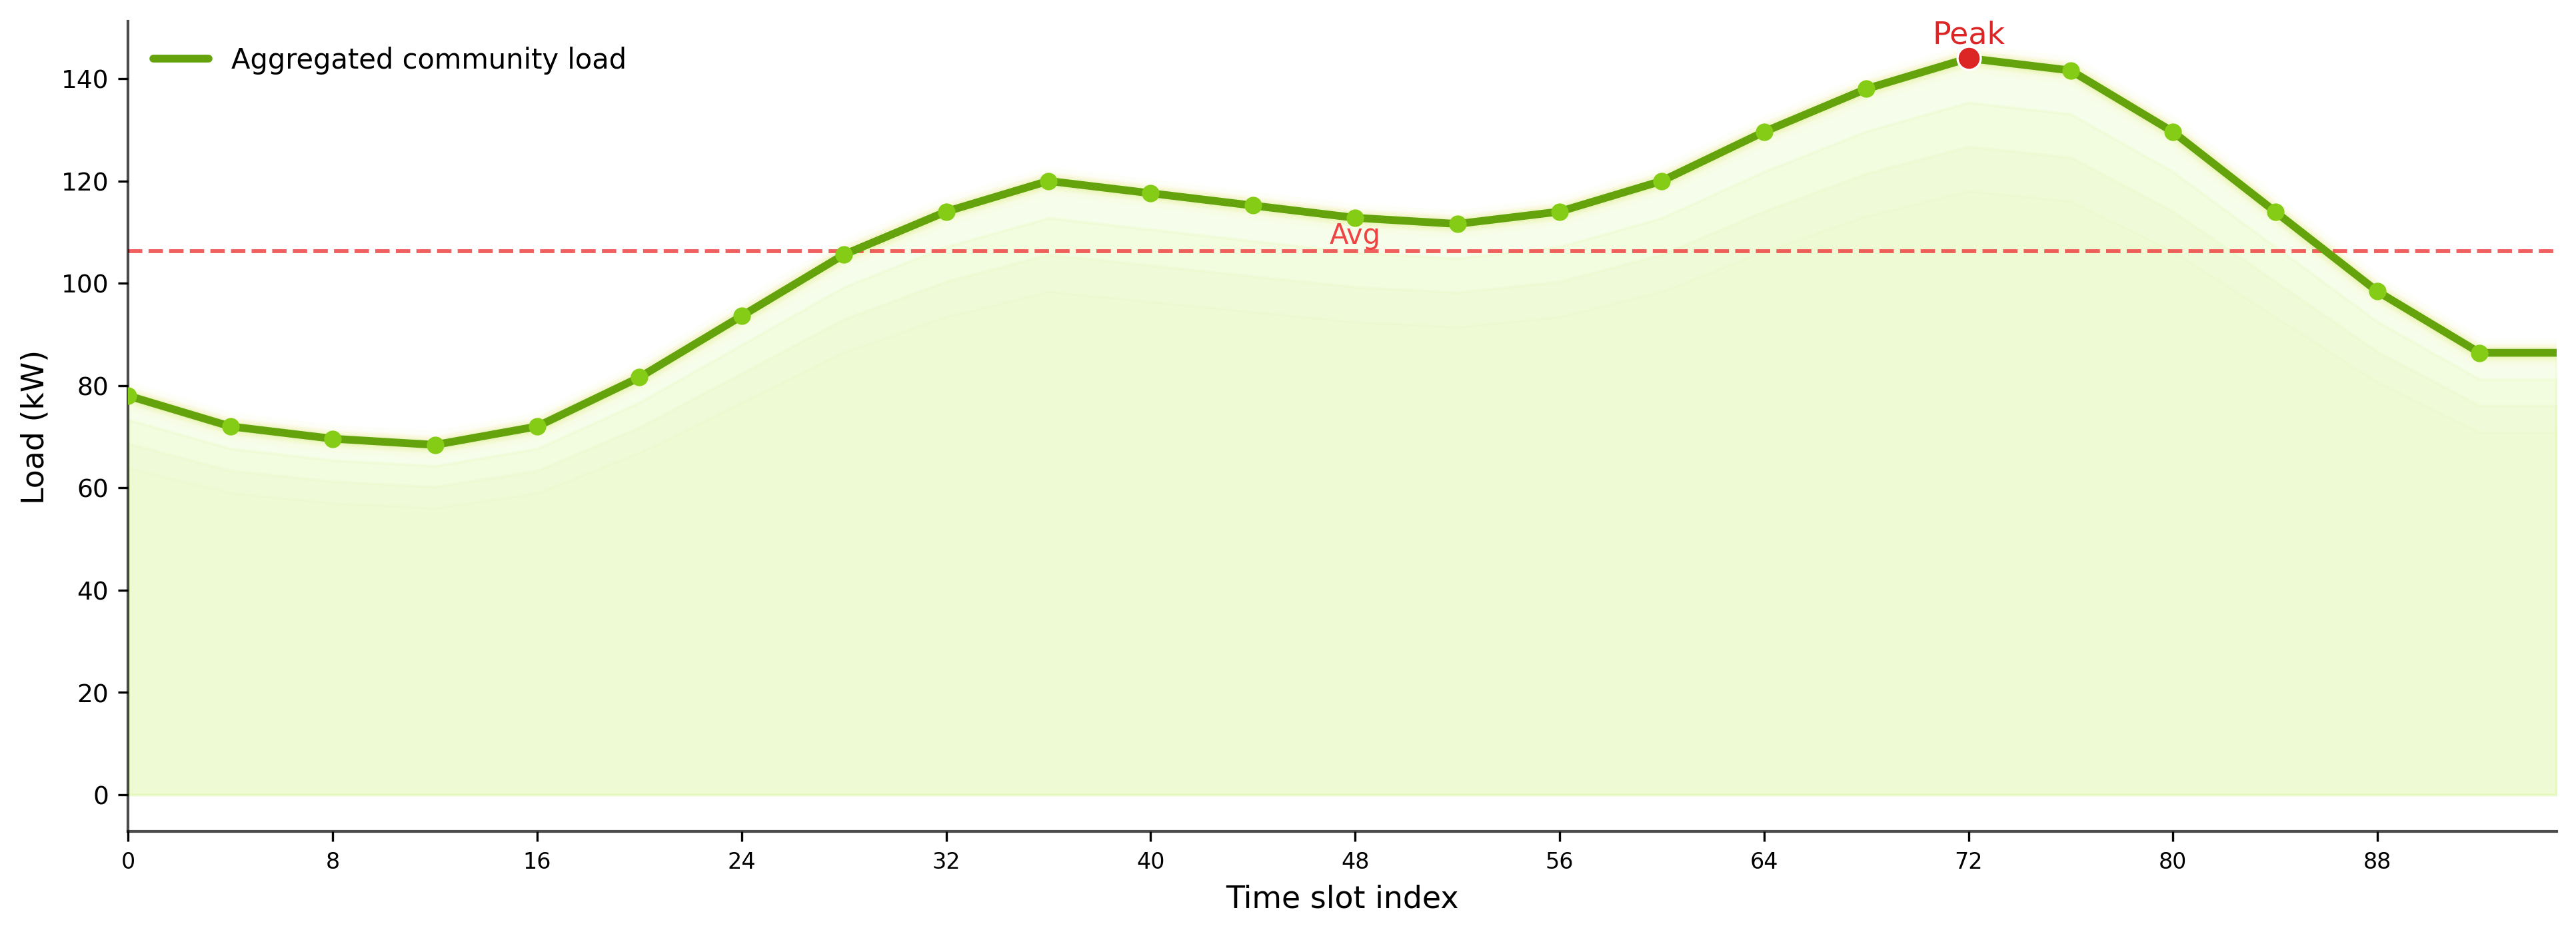

STEP 3 completed successfully.
Figure saved at: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/community_load_96_slots.png


In [68]:
# ======================================================
# STEP 3: Aggregated community load profile in 96 time slots
# ======================================================

FIG_PATH = os.path.join(RESULTS_FOLDER, "community_load_96_slots.png")

# ------------------------------------------------------
# Use 96 time slots instead of datetime
# ------------------------------------------------------
x = np.arange(N_SLOTS)
y = df["community_load_kw"].values

fig, ax = plt.subplots(figsize=(13, 4.8), dpi=300)

# ------------------------------------------------------
# Soft layered fill (bottom)
# ------------------------------------------------------
for alpha, scale in zip([0.20, 0.14, 0.10, 0.06], [1.00, 0.94, 0.88, 0.82]):
    ax.fill_between(
        x,
        y * scale,
        0,
        color="#D9F99D",
        alpha=alpha,
        zorder=1
    )

# ------------------------------------------------------
# Upper soft shadow
# ------------------------------------------------------
for lw, alpha in [(10, 0.05), (7, 0.08), (5, 0.12)]:
    ax.plot(
        x,
        y,
        color="#FEF08A",
        linewidth=lw,
        alpha=alpha,
        solid_capstyle="round",
        zorder=2
    )

# ------------------------------------------------------
# Lower soft shadow
# ------------------------------------------------------
for lw, alpha in [(6, 0.05), (4, 0.08)]:
    ax.plot(
        x,
        y,
        color="#A3E635",
        linewidth=lw,
        alpha=alpha,
        solid_capstyle="round",
        zorder=2
    )

# ------------------------------------------------------
# Main line
# ------------------------------------------------------
ax.plot(
    x,
    y,
    color="#65A30D",
    linewidth=2.8,
    solid_capstyle="round",
    label="Aggregated community load",
    zorder=4
)

# ------------------------------------------------------
# Hourly markers only (every 4 slots)
# ------------------------------------------------------
hourly_slots = np.arange(0, N_SLOTS, 4)
ax.scatter(
    hourly_slots,
    y[hourly_slots],
    color="#84CC16",
    s=28,
    zorder=5
)

# ------------------------------------------------------
# Peak highlight
# ------------------------------------------------------
peak_idx = np.argmax(y)
ax.scatter(
    x[peak_idx],
    y[peak_idx],
    color="#DC2626",
    s=70,
    edgecolor="white",
    linewidth=0.8,
    zorder=6
)

ax.text(
    x[peak_idx],
    y[peak_idx] + 3,
    "Peak",
    color="#DC2626",
    fontsize=11,
    ha="center"
)

# ------------------------------------------------------
# Average line
# ------------------------------------------------------
avg_load = np.mean(y)
ax.axhline(
    avg_load,
    color="#EF4444",
    linestyle="--",
    linewidth=1.4,
    alpha=0.85
)

ax.text(
    x[len(x)//2],
    avg_load + 1.5,
    "Avg",
    color="#EF4444",
    fontsize=10,
    ha="center"
)

# ------------------------------------------------------
# Styling
# ------------------------------------------------------
ax.set_xlabel("Time slot index", fontsize=11)
ax.set_ylabel("Load (kW)", fontsize=11)

tick_positions = np.arange(0, 97, 8)
ax.set_xticks(tick_positions)
ax.set_xticklabels([str(i) for i in tick_positions], fontsize=8)

ax.tick_params(axis="y", labelsize=9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.0)
ax.spines["bottom"].set_linewidth(1.0)
ax.spines["left"].set_alpha(0.7)
ax.spines["bottom"].set_alpha(0.7)

ax.margins(x=0)
ax.grid(False)
ax.legend(frameon=False, loc="upper left", fontsize=10)

plt.tight_layout()
plt.savefig(FIG_PATH, dpi=300, bbox_inches="tight")
plt.show()

print("STEP 3 completed successfully.")
print("Figure saved at:", FIG_PATH)

In [69]:
# ======================================================
# STEP 4: Generate community EV scenarios
# ======================================================

# ------------------------------------------------------
# EV fleet types
# ------------------------------------------------------
ev_types = [
    {"EVType": "LEAF40", "Battery_kWh": 40.0},
    {"EVType": "TS60",   "Battery_kWh": 60.0},
    {"EVType": "TM3_80", "Battery_kWh": 80.5},
    {"EVType": "TMX100", "Battery_kWh": 100.0}
]

ev_type_names = [x["EVType"] for x in ev_types]

# ------------------------------------------------------
# Random generator
# ------------------------------------------------------
rng = np.random.default_rng(42)

def sample_arrival_hour(size):
    """
    Arrival centered around evening.
    Std = 2 hours.
    Clipped to 15:00-23:00
    """
    vals = rng.normal(loc=18.0, scale=2.0, size=size)
    return np.clip(vals, 15.0, 23.0)

def sample_stay_duration(size):
    """
    Stay duration after arrival.
    Mean = 12 hours, Std = 2.5 hours.
    Clipped to 6-16 hours.
    """
    vals = rng.normal(loc=12.0, scale=2.5, size=size)
    return np.clip(vals, 6.0, 16.0)

def sample_arrival_soc(size):
    """
    Arrival SoC between 20% and 60%.
    """
    return rng.uniform(0.20, 0.60, size=size)

def sample_target_soc(arrival_soc):
    """
    Target SoC between 70% and 95%, always above arrival SoC.
    """
    target = rng.uniform(0.70, 0.95, size=len(arrival_soc))
    target = np.maximum(target, arrival_soc + 0.10)
    target = np.minimum(target, 0.95)
    return target

# ------------------------------------------------------
# Generate EV records for all penetration levels
# ------------------------------------------------------
community_ev_rows = []

for pen in penetration_levels:
    n_evs = int(round(N_HOUSES * pen))

    chosen_ev_types = rng.choice(ev_type_names, size=n_evs, replace=True)
    arrival_soc = sample_arrival_soc(n_evs)
    target_soc = sample_target_soc(arrival_soc)

    arrival_hour = sample_arrival_hour(n_evs)
    stay_duration = sample_stay_duration(n_evs)
    departure_hour = (arrival_hour + stay_duration) % 24

    for i in range(n_evs):
        ev_type = chosen_ev_types[i]
        battery_kwh = next(x["Battery_kWh"] for x in ev_types if x["EVType"] == ev_type)

        required_energy = (target_soc[i] - arrival_soc[i]) * battery_kwh

        community_ev_rows.append({
            "Penetration": pen,
            "EV_ID": f"P{int(pen*100)}_{i+1}",
            "EVType": ev_type,
            "Battery_kWh": battery_kwh,
            "ArrivalSoC": arrival_soc[i],
            "TargetSoC": target_soc[i],
            "ArrivalHour": arrival_hour[i],
            "StayDuration_h": stay_duration[i],
            "DepartureHour": departure_hour[i],
            "RequiredEnergy_kWh": required_energy
        })

community_ev_df = pd.DataFrame(community_ev_rows)

# ------------------------------------------------------
# Save scenario table
# ------------------------------------------------------
ev_scenario_file = os.path.join(RESULTS_FOLDER, "community_ev_random_scenarios.csv")
community_ev_df.to_csv(ev_scenario_file, index=False)

print("STEP 4 completed successfully.")
print("Saved EV scenario table to:", ev_scenario_file)
print("Total EV records generated:", len(community_ev_df))
community_ev_df.head()

STEP 4 completed successfully.
Saved EV scenario table to: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/community_ev_random_scenarios.csv
Total EV records generated: 90


,Penetration,EV_ID,EVType,Battery_kWh,ArrivalSoC,TargetSoC,ArrivalHour,StayDuration_h,DepartureHour,RequiredEnergy_kWh
0,0.2,P20_1,LEAF40,40.0,0.590249,0.756810,17.295733,14.822431,8.118164,6.662430
1,0.2,P20_2,TMX100,100.0,0.504456,0.838646,19.064618,11.715131,6.779750,33.419032
2,0.2,P20_3,TM3_80,80.5,0.514426,0.715954,18.730888,9.899609,4.630497,16.223052
3,0.2,P20_4,TS60,60.0,0.251245,0.906908,18.825465,9.938797,4.764262,39.339740
4,0.2,P20_5,TS60,60.0,0.380154,0.857916,18.861642,13.626482,8.488124,28.665703


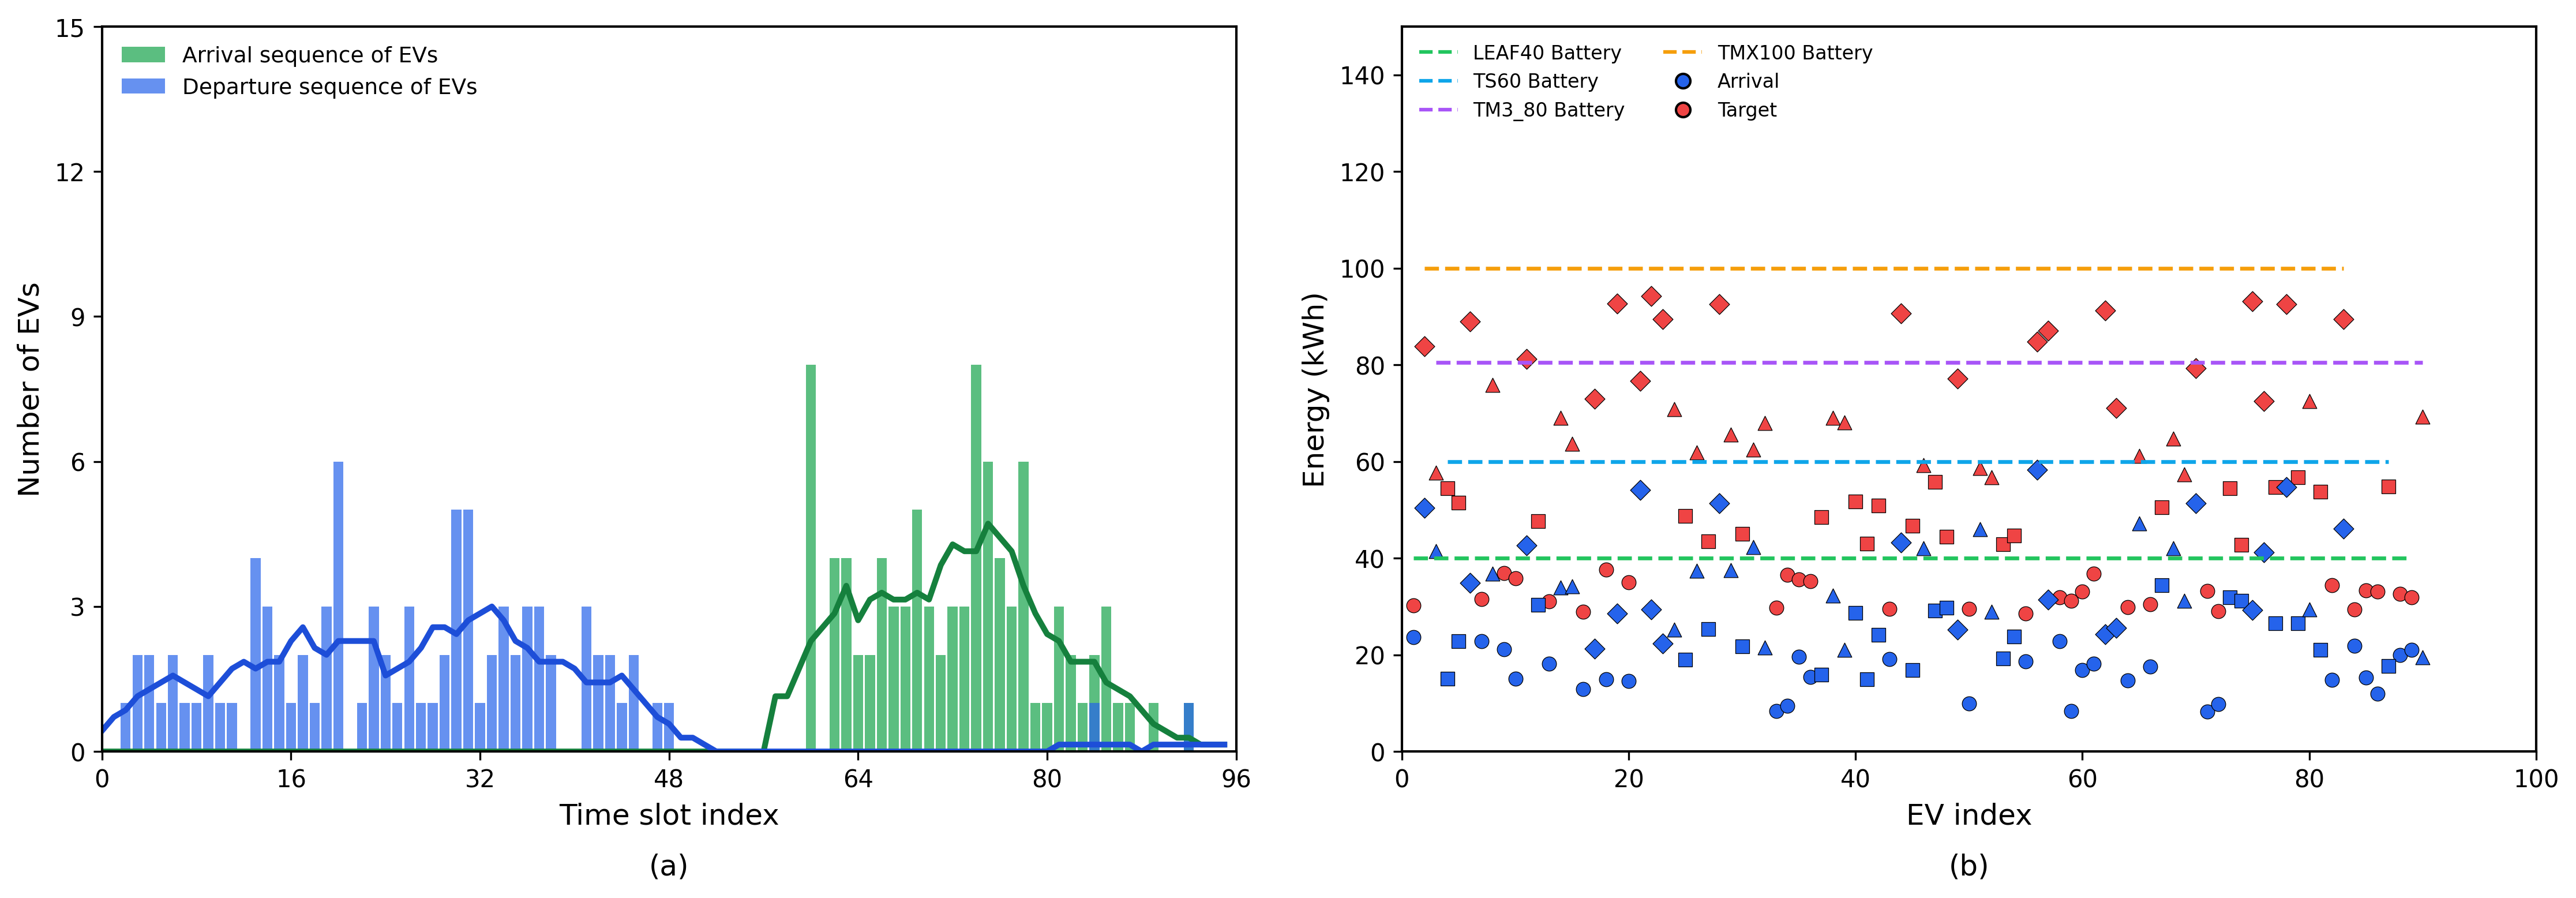

In [70]:
# ======================================================
# STEP 5: Combined figure for EV scenario setup
# (a) Arrival/departure sequence
# (b) Battery capacity + arrival energy + target energy
# ======================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from matplotlib.lines import Line2D

COMBINED_FIG = os.path.join(RESULTS_FOLDER, "final_clean_figure.png")

# ------------------------------------------------------
# Data
# ------------------------------------------------------
plot_df = community_ev_df.copy().reset_index(drop=True)
plot_df["EV_Index"] = np.arange(1, len(plot_df) + 1)

# Slots
plot_df["ArrivalSlot"] = np.floor(plot_df["ArrivalHour"] * 4).astype(int).clip(0, 95)
plot_df["DepartureSlot"] = np.floor(plot_df["DepartureHour"] * 4).astype(int).clip(0, 95)

slot_index = np.arange(96)

arrival_counts = plot_df["ArrivalSlot"].value_counts().reindex(slot_index, fill_value=0).sort_index()
departure_counts = plot_df["DepartureSlot"].value_counts().reindex(slot_index, fill_value=0).sort_index()

# Smooth
def smooth(y, w=7):
    if w % 2 == 0:
        w += 1
    return np.convolve(y, np.ones(w)/w, mode="same")

arrival_smooth = smooth(arrival_counts.values)
departure_smooth = smooth(departure_counts.values)

# SoC → kWh
plot_df["Arrival_kWh"] = plot_df["ArrivalSoC"] * plot_df["Battery_kWh"]
plot_df["Target_kWh"]  = plot_df["TargetSoC"] * plot_df["Battery_kWh"]

# Markers
marker_map = {"LEAF40": "o", "TS60": "s", "TM3_80": "^", "TMX100": "D"}

# Colors
color_arrival_bar = "#16A34A"
color_depart_bar  = "#2563EB"
color_arrival_line = "#15803D"
color_depart_line  = "#1D4ED8"

color_arrival = "#2563EB"
color_target  = "#EF4444"

battery_colors = {
    "LEAF40": "#22C55E",
    "TS60":   "#0EA5E9",
    "TM3_80": "#A855F7",
    "TMX100": "#F59E0B"
}

# ------------------------------------------------------
# Figure
# ------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), dpi=300)

# ======================================================
# (a) Arrival / Departure
# ======================================================
ax1.bar(slot_index, arrival_counts.values, width=0.85, color=color_arrival_bar, alpha=0.7, label="Arrival sequence of EVs")
ax1.bar(slot_index, departure_counts.values, width=0.85, color=color_depart_bar, alpha=0.7, label="Departure sequence of EVs")

ax1.plot(slot_index, arrival_smooth, color=color_arrival_line, linewidth=2.4)
ax1.plot(slot_index, departure_smooth, color=color_depart_line, linewidth=2.4)

ax1.set_xlabel("Time slot index", fontsize=12)
ax1.set_ylabel("Number of EVs", fontsize=12)

ax1.set_xlim(0, 96)
ax1.set_ylim(0, 15)

ax1.set_xticks(np.arange(0, 97, 16))
ax1.set_yticks(np.arange(0, 16, 3))

ax1.tick_params(labelsize=10)

# remove grid completely
ax1.grid(False)

ax1.spines["top"].set_linewidth(1)
ax1.spines["right"].set_linewidth(1)
ax1.spines["left"].set_linewidth(1)
ax1.spines["bottom"].set_linewidth(1)

ax1.legend(loc="upper left", fontsize=9, frameon=False)

ax1.text(0.5, -0.14, "(a)", transform=ax1.transAxes, ha="center", va="top", fontsize=12)

# ======================================================
# (b) Battery + SoC
# ======================================================
battery_handles = []

for ev_type, marker in marker_map.items():
    subset = plot_df[plot_df["EVType"] == ev_type].sort_values("EV_Index")

    ax2.plot(
        subset["EV_Index"],
        subset["Battery_kWh"],
        linestyle="--",
        linewidth=1.6,
        color=battery_colors[ev_type]
    )

    battery_handles.append(
        Line2D([0], [0], linestyle="--", color=battery_colors[ev_type], label=f"{ev_type} Battery")
    )

    ax2.scatter(
        subset["EV_Index"],
        subset["Arrival_kWh"],
        s=35,
        marker=marker,
        color=color_arrival,
        edgecolors="black",
        linewidths=0.3
    )

    ax2.scatter(
        subset["EV_Index"],
        subset["Target_kWh"],
        s=35,
        marker=marker,
        color=color_target,
        edgecolors="black",
        linewidths=0.3
    )

ax2.set_xlabel("EV index", fontsize=12)
ax2.set_ylabel("Energy (kWh)", fontsize=12)

ax2.set_xlim(0, 100)
ax2.set_ylim(0, 150)
ax2.set_xticks(np.arange(0, 101, 20))

ax2.tick_params(labelsize=10)

# remove grid completely
ax2.grid(False)

ax2.spines["top"].set_linewidth(1)
ax2.spines["right"].set_linewidth(1)
ax2.spines["left"].set_linewidth(1)
ax2.spines["bottom"].set_linewidth(1)

custom_handles = battery_handles + [
    Line2D([0], [0], marker='o', color='w', markerfacecolor=color_arrival,
           markeredgecolor='black', markersize=6, label='Arrival'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor=color_target,
           markeredgecolor='black', markersize=6, label='Target')
]

ax2.legend(handles=custom_handles, loc="upper left", fontsize=8, frameon=False, ncol=2)

ax2.text(0.5, -0.14, "(b)", transform=ax2.transAxes, ha="center", va="top", fontsize=12)

# ------------------------------------------------------
# Save
# ------------------------------------------------------
plt.tight_layout(w_pad=2)
plt.subplots_adjust(bottom=0.2)
plt.savefig(COMBINED_FIG, dpi=300, bbox_inches="tight")
plt.show()

#print("Final clean figure saved at:", COMBINED_FIG)

In [71]:
# ======================================================
# STEP 6: Build EV availability profiles (96 slots)
# ======================================================

import numpy as np
import pandas as pd
import os

# ------------------------------------------------------
# Basic settings
# ------------------------------------------------------
N_SLOTS = 96

# Copy EV table
ev_df = community_ev_df.copy()

# Ensure slot columns exist
if "ArrivalSlot" not in ev_df.columns:
    ev_df["ArrivalSlot"] = np.floor(ev_df["ArrivalHour"] * 4).astype(int).clip(0, 95)

if "DepartureSlot" not in ev_df.columns:
    ev_df["DepartureSlot"] = np.floor(ev_df["DepartureHour"] * 4).astype(int).clip(0, 95)

# ------------------------------------------------------
# Build availability matrix for each EV
# ------------------------------------------------------
availability_matrix = {}

for _, row in ev_df.iterrows():
    ev_id = row["EV_ID"]
    arr = int(row["ArrivalSlot"])
    dep = int(row["DepartureSlot"])

    avail = np.zeros(N_SLOTS, dtype=int)

    if dep > arr:
        # Same-day departure
        avail[arr:dep] = 1
    else:
        # Cross-midnight departure
        avail[arr:] = 1
        avail[:dep] = 1

    availability_matrix[ev_id] = avail

# ------------------------------------------------------
# Convert to DataFrame for inspection
# ------------------------------------------------------
availability_df = pd.DataFrame.from_dict(
    availability_matrix,
    orient="index",
    columns=[f"Slot_{i}" for i in range(N_SLOTS)]
).reset_index().rename(columns={"index": "EV_ID"})

availability_df = availability_df.merge(
    ev_df[["EV_ID", "Penetration", "EVType", "Battery_kWh", "ArrivalHour", "DepartureHour"]],
    on="EV_ID",
    how="left"
)

front_cols = ["EV_ID", "Penetration", "EVType", "Battery_kWh", "ArrivalHour", "DepartureHour"]
slot_cols = [c for c in availability_df.columns if c.startswith("Slot_")]
availability_df = availability_df[front_cols + slot_cols]

# ------------------------------------------------------
# Aggregate available charging power by penetration
# total available power at slot t = sum(EV available at t) * CHARGER_KW
# ------------------------------------------------------
aggregate_available_power_by_pen = {}

for pen in sorted(ev_df["Penetration"].unique()):
    ev_ids_pen = ev_df.loc[ev_df["Penetration"] == pen, "EV_ID"].tolist()

    total_available_power = np.zeros(N_SLOTS)

    for ev_id in ev_ids_pen:
        total_available_power += availability_matrix[ev_id] * CHARGER_KW

    aggregate_available_power_by_pen[pen] = total_available_power

# ------------------------------------------------------
# Summary table
# ------------------------------------------------------
availability_summary = (
    ev_df.groupby("Penetration")
    .agg(
        NumEVs=("EV_ID", "count"),
        AvgArrivalHour=("ArrivalHour", "mean"),
        AvgDepartureHour=("DepartureHour", "mean")
    )
    .reset_index()
)

availability_summary["TotalRequiredEnergy_kWh"] = (
    ev_df.groupby("Penetration")["RequiredEnergy_kWh"].sum().values
)

availability_summary["MaxAvailableEnergy_kWh"] = [
    np.sum(aggregate_available_power_by_pen[pen] * DT_HOURS * ETA)
    for pen in availability_summary["Penetration"]
]

availability_summary["Feasible"] = (
    availability_summary["TotalRequiredEnergy_kWh"] <= availability_summary["MaxAvailableEnergy_kWh"] + 1e-9
)

availability_summary = availability_summary.round({
    "AvgArrivalHour": 2,
    "AvgDepartureHour": 2,
    "TotalRequiredEnergy_kWh": 2,
    "MaxAvailableEnergy_kWh": 2
})

# ------------------------------------------------------
# Save outputs
# ------------------------------------------------------
availability_file = os.path.join(RESULTS_FOLDER, "ev_availability_matrix.csv")
availability_df.to_csv(availability_file, index=False)

availability_summary_file = os.path.join(RESULTS_FOLDER, "availability_summary.csv")
availability_summary.to_csv(availability_summary_file, index=False)

# ------------------------------------------------------
# Display
# ------------------------------------------------------
print("STEP 6 completed successfully.")
print("Saved EV availability matrix to:", availability_file)
print("Saved availability summary to:", availability_summary_file)
availability_summary

STEP 6 completed successfully.
Saved EV availability matrix to: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/ev_availability_matrix.csv
Saved availability summary to: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/availability_summary.csv


,Penetration,NumEVs,AvgArrivalHour,AvgDepartureHour,TotalRequiredEnergy_kWh,MaxAvailableEnergy_kWh,Feasible
0,0.2,10,18.48,6.73,262.66,862.93,True
1,0.6,30,17.99,5.71,963.77,2476.32,True
2,1.0,50,18.28,7.34,1329.52,4247.88,True


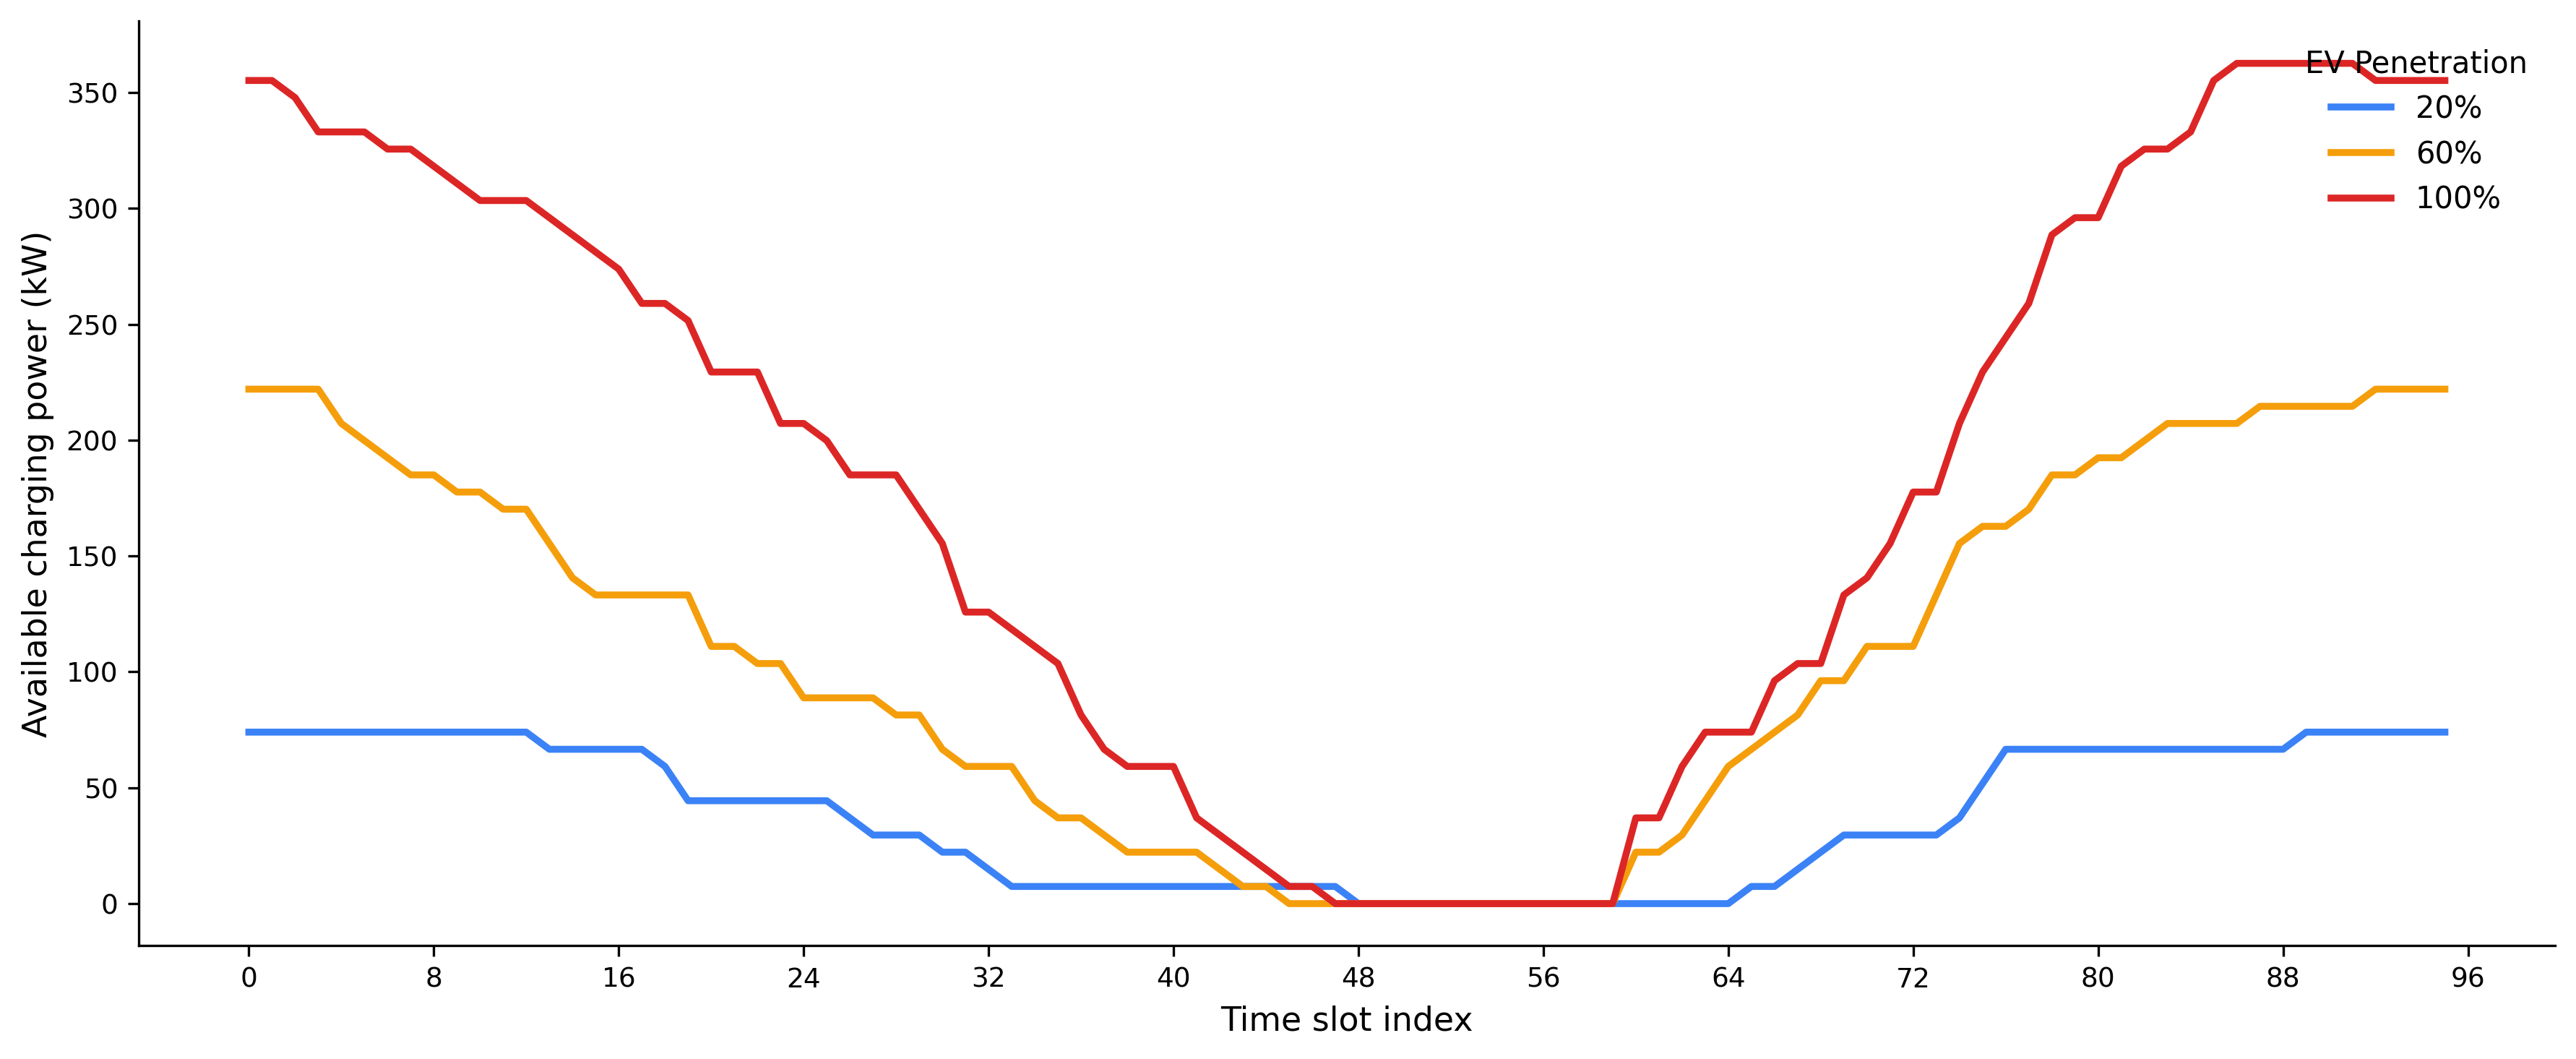

STEP 7 completed successfully.
Figure saved at: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/aggregate_available_power_by_penetration.png


In [72]:
# ======================================================
# STEP 7: Plot aggregate available charging power
# ======================================================

import matplotlib.pyplot as plt
import numpy as np
import os

AVAIL_POWER_FIG = os.path.join(RESULTS_FOLDER, "aggregate_available_power_by_penetration.png")

fig, ax = plt.subplots(figsize=(12, 5), dpi=300)

pen_colors = {
    0.20: "#3B82F6",   # blue
    0.60: "#F59E0B",   # orange
    1.00: "#DC2626"    # red
}

for pen in [0.20, 0.60, 1.00]:
    if pen not in aggregate_available_power_by_pen:
        continue

    ax.plot(
        np.arange(N_SLOTS),
        aggregate_available_power_by_pen[pen],
        linewidth=2.3,
        color=pen_colors[pen],
        label=f"{int(pen*100)}%"
    )

# ------------------------------------------------------
# Styling
# ------------------------------------------------------
ax.set_xlabel("Time slot index", fontsize=11)
ax.set_ylabel("Available charging power (kW)", fontsize=11)

tick_positions = np.arange(0, 97, 8)
ax.set_xticks(tick_positions)
ax.set_xticklabels([str(i) for i in tick_positions], fontsize=9)

ax.tick_params(axis="y", labelsize=9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(False)

ax.legend(
    title="EV Penetration",
    frameon=False,
    fontsize=10,
    title_fontsize=10,
    loc="upper right"
)

plt.tight_layout()
plt.savefig(AVAIL_POWER_FIG, dpi=300, bbox_inches="tight")
plt.show()

print("STEP 7 completed successfully.")
print("Figure saved at:", AVAIL_POWER_FIG)

In [73]:
# ======================================================
# STEP 8: Prepare community-level inputs for optimization
# ======================================================

import numpy as np
import pandas as pd
import os

community_inputs = {}

for pen in sorted(ev_df["Penetration"].unique()):
    ev_sub = ev_df[ev_df["Penetration"] == pen].copy()

    # --------------------------------------------------
    # Basic EV counts and energy
    # --------------------------------------------------
    num_evs = len(ev_sub)
    total_required_energy = ev_sub["RequiredEnergy_kWh"].sum()

    # --------------------------------------------------
    # Aggregate available charging power
    # --------------------------------------------------
    agg_available_power = aggregate_available_power_by_pen[pen].copy()

    # --------------------------------------------------
    # Community base load and prices
    # --------------------------------------------------
    base_load_kw = df["community_load_kw"].values.copy()
    tou_price = df["tou_price"].values.copy()
    rt_price = df["rt_price"].values.copy()

    # --------------------------------------------------
    # Maximum feasible charging energy
    # --------------------------------------------------
    max_available_energy = np.sum(agg_available_power * DT_HOURS * ETA)
    feasible = total_required_energy <= max_available_energy + 1e-9

    # --------------------------------------------------
    # Store all inputs for this penetration
    # --------------------------------------------------
    community_inputs[pen] = {
        "Penetration": pen,
        "NumEVs": num_evs,
        "TotalRequiredEnergy_kWh": total_required_energy,
        "MaxAvailableEnergy_kWh": max_available_energy,
        "Feasible": feasible,
        "BaseLoad_kW": base_load_kw,
        "AvailablePower_kW": agg_available_power,
        "TOU_Price": tou_price,
        "RT_Price": rt_price
    }

# ------------------------------------------------------
# Compact summary table
# ------------------------------------------------------
community_input_summary = pd.DataFrame([
    {
        "Penetration": v["Penetration"],
        "NumEVs": v["NumEVs"],
        "TotalRequiredEnergy_kWh": v["TotalRequiredEnergy_kWh"],
        "MaxAvailableEnergy_kWh": v["MaxAvailableEnergy_kWh"],
        "Feasible": v["Feasible"],
        "BasePeakLoad_kW": np.max(v["BaseLoad_kW"]),
        "MaxAvailablePower_kW": np.max(v["AvailablePower_kW"])
    }
    for v in community_inputs.values()
])

community_input_summary = community_input_summary.round({
    "TotalRequiredEnergy_kWh": 3,
    "MaxAvailableEnergy_kWh": 3,
    "BasePeakLoad_kW": 3,
    "MaxAvailablePower_kW": 3
})

# ------------------------------------------------------
# Save summary
# ------------------------------------------------------
input_summary_file = os.path.join(RESULTS_FOLDER, "community_input_summary.csv")
community_input_summary.to_csv(input_summary_file, index=False)

print("STEP 8 completed successfully.")
print("Saved input summary to:", input_summary_file)
community_input_summary

STEP 8 completed successfully.
Saved input summary to: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/community_input_summary.csv


,Penetration,NumEVs,TotalRequiredEnergy_kWh,MaxAvailableEnergy_kWh,Feasible,BasePeakLoad_kW,MaxAvailablePower_kW
0,0.2,10,262.656,862.932,True,144.0,74.0
1,0.6,30,963.769,2476.318,True,144.0,222.0
2,1.0,50,1329.524,4247.878,True,144.0,362.6


In [74]:

# ============================================================
# STEP 8.1: Verify inputs for NSGA-II sensitivity analysis
# ============================================================

import pymoo

print("=" * 65)
print("STEP 8.1: SENSITIVITY ANALYSIS INPUT VERIFICATION")
print("=" * 65)

print("\npymoo version:", pymoo.__version__)
print("Output folder:", RESULTS_FOLDER)

# Check that community_inputs exists
if "community_inputs" not in globals():
    raise RuntimeError(
        "community_inputs is missing. Please rerun Steps 1 to 8."
    )

print("\nAvailable penetration levels:")
print(list(community_inputs.keys()))

# Check the 60% penetration scenario
if 0.60 not in community_inputs:
    raise RuntimeError(
        "60% EV penetration data is missing."
    )

data_60 = community_inputs[0.60]

print("\n60% scenario data type:", type(data_60).__name__)

if isinstance(data_60, dict):
    print("\nAvailable data fields:")
    for key, value in data_60.items():
        if isinstance(value, (list, tuple, np.ndarray)):
            print(f"  {key}: shape = {np.shape(value)}")
        else:
            print(f"  {key}: {str(value)[:120]}")

print("\nSTEP 8.1 completed successfully.")


STEP 8.1: SENSITIVITY ANALYSIS INPUT VERIFICATION

pymoo version: 0.6.2
Output folder: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis

Available penetration levels:
[np.float64(0.2), np.float64(0.6), np.float64(1.0)]

60% scenario data type: dict

Available data fields:
  Penetration: 0.6
  NumEVs: 30
  TotalRequiredEnergy_kWh: 963.7691765182688
  MaxAvailableEnergy_kWh: 2476.317500000001
  Feasible: True
  BaseLoad_kW: shape = (96,)
  AvailablePower_kW: shape = (96,)
  TOU_Price: shape = (96,)
  RT_Price: shape = (96,)

STEP 8.1 completed successfully.


In [75]:

# ============================================================
# STEP 8.2: Define aggregated charging optimization problem
# ============================================================

print("=" * 65)
print("STEP 8.2: AGGREGATED CHARGING OPTIMIZATION PROBLEM")
print("=" * 65)

# Retrieve verified 60% penetration scenario
data_60 = community_inputs[0.60]

base_load_kw = np.asarray(
    data_60["BaseLoad_kW"], dtype=float
)

available_power_kw = np.asarray(
    data_60["AvailablePower_kW"], dtype=float
)

rt_price = np.asarray(
    data_60["RT_Price"], dtype=float
)

total_required_energy = float(
    data_60["TotalRequiredEnergy_kWh"]
)

# ------------------------------------------------------------
# Define the original community-level optimization problem
# ------------------------------------------------------------

class CommunityMOCHFProblem(Problem):

    def __init__(
        self,
        base_load_kw,
        available_power_kw,
        rt_price,
        total_required_energy
    ):

        self.base_load_kw = base_load_kw
        self.available_power_kw = available_power_kw
        self.rt_price = rt_price
        self.total_required_energy = total_required_energy

        xl = np.zeros(len(available_power_kw))
        xu = available_power_kw.copy()

        super().__init__(
            n_var=len(available_power_kw),
            n_obj=2,
            n_ieq_constr=1,
            xl=xl,
            xu=xu
        )

    def _evaluate(self, X, out, *args, **kwargs):

        # Objective 1: Total charging cost
        f1 = np.sum(
            X * self.rt_price * DT_HOURS,
            axis=1
        )

        # Objective 2: Peak aggregate community load
        total_kw = X + self.base_load_kw[None, :]
        f2 = np.max(total_kw, axis=1)

        # Aggregate energy constraint
        delivered_energy = np.sum(
            X * DT_HOURS * ETA,
            axis=1
        )

        g1 = (
            self.total_required_energy
            - delivered_energy
        )

        out["F"] = np.column_stack([f1, f2])
        out["G"] = np.column_stack([g1])


# ------------------------------------------------------------
# Instantiate the optimization problem
# ------------------------------------------------------------

problem_60 = CommunityMOCHFProblem(
    base_load_kw=base_load_kw,
    available_power_kw=available_power_kw,
    rt_price=rt_price,
    total_required_energy=total_required_energy
)

# ------------------------------------------------------------
# Verify problem configuration
# ------------------------------------------------------------

print("\nOptimization configuration:")
print("Number of decision variables:", problem_60.n_var)
print("Number of objectives:", problem_60.n_obj)
print("Number of inequality constraints:", problem_60.n_ieq_constr)

print("\nInput verification:")
print("Base load shape:", base_load_kw.shape)
print("Available power shape:", available_power_kw.shape)
print("Real-time price shape:", rt_price.shape)
print("Required energy (kWh):", round(total_required_energy, 4))

print("\nSTEP 8.2 completed successfully.")


STEP 8.2: AGGREGATED CHARGING OPTIMIZATION PROBLEM

Optimization configuration:
Number of decision variables: 96
Number of objectives: 2
Number of inequality constraints: 1

Input verification:
Base load shape: (96,)
Available power shape: (96,)
Real-time price shape: (96,)
Required energy (kWh): 963.7692

STEP 8.2 completed successfully.


In [76]:

# ============================================================
# STEP 8.3: Configure NSGA-II sensitivity experiment
# ============================================================

print("=" * 65)
print("STEP 8.3: NSGA-II SENSITIVITY CONFIGURATION")
print("=" * 65)

import itertools
import pymoo

# ------------------------------------------------------------
# 1. Population sizes and generation limits
# ------------------------------------------------------------

POPULATION_SIZES = [50, 100, 150]
GENERATION_LIMITS = [50, 100, 200]

# Independent random seeds
RANDOM_SEEDS = [42, 43, 44, 45, 46]

# ------------------------------------------------------------
# 2. Generate all experiment configurations
# ------------------------------------------------------------

EXPERIMENT_CONFIGS = list(
    itertools.product(
        POPULATION_SIZES,
        GENERATION_LIMITS,
        RANDOM_SEEDS
    )
)

# ------------------------------------------------------------
# 3. Output directory
# ------------------------------------------------------------

SENSITIVITY_FOLDER = os.path.join(
    RESULTS_FOLDER,
    "Comment_3_7_NSGA2_Sensitivity"
)

os.makedirs(SENSITIVITY_FOLDER, exist_ok=True)

# ------------------------------------------------------------
# 4. Record experiment metadata
# ------------------------------------------------------------

experiment_metadata = {
    "Reviewer_Comment": "3.7",
    "Optimization": "Aggregated community EV charging",
    "EV_Penetration": 0.60,
    "NumEVs": int(data_60["NumEVs"]),
    "Decision_Variables": problem_60.n_var,
    "Population_Sizes": POPULATION_SIZES,
    "Generation_Limits": GENERATION_LIMITS,
    "Random_Seeds": RANDOM_SEEDS,
    "Total_Runs": len(EXPERIMENT_CONFIGS),
    "Pymoo_Version": pymoo.__version__,
    "Charging_Efficiency": ETA,
    "Time_Slot_Hours": DT_HOURS
}

# ------------------------------------------------------------
# 5. Display configuration
# ------------------------------------------------------------

print("\nOptimization:", experiment_metadata["Optimization"])
print("EV penetration:", experiment_metadata["EV_Penetration"])
print("Number of EVs:", experiment_metadata["NumEVs"])

print("\nPopulation sizes:", POPULATION_SIZES)
print("Generation limits:", GENERATION_LIMITS)
print("Random seeds:", RANDOM_SEEDS)

print("\nTotal configurations:", len(EXPERIMENT_CONFIGS))
print("pymoo version:", pymoo.__version__)

print("\nOutput folder:")
print(SENSITIVITY_FOLDER)

print("\nFirst five configurations:")
for config in EXPERIMENT_CONFIGS[:5]:
    print(config)

print("\nSTEP 8.3 completed successfully.")


STEP 8.3: NSGA-II SENSITIVITY CONFIGURATION

Optimization: Aggregated community EV charging
EV penetration: 0.6
Number of EVs: 30

Population sizes: [50, 100, 150]
Generation limits: [50, 100, 200]
Random seeds: [42, 43, 44, 45, 46]

Total configurations: 45
pymoo version: 0.6.2

Output folder:
/content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/Comment_3_7_NSGA2_Sensitivity

First five configurations:
(50, 50, 42)
(50, 50, 43)
(50, 50, 44)
(50, 50, 45)
(50, 50, 46)

STEP 8.3 completed successfully.


In [77]:

# ============================================================
# STEP 8.4: Test original NSGA-II configuration
# ============================================================

import time

print("=" * 65)
print("STEP 8.4: NSGA-II BASELINE TEST RUN")
print("=" * 65)

# ------------------------------------------------------------
# 1. Original NSGA-II parameters
# ------------------------------------------------------------

TEST_POP_SIZE = 150
TEST_GENERATIONS = 200
TEST_SEED = 42

algorithm_test = NSGA2(
    pop_size=TEST_POP_SIZE
)

termination_test = get_termination(
    "n_gen",
    TEST_GENERATIONS
)

# ------------------------------------------------------------
# 2. Run optimization
# ------------------------------------------------------------

print("\nStarting optimization...")
start_time = time.perf_counter()

res_test = minimize(
    problem_60,
    algorithm_test,
    termination_test,
    seed=TEST_SEED,
    save_history=False,
    verbose=False
)

runtime_test = time.perf_counter() - start_time

# ------------------------------------------------------------
# 3. Check feasible Pareto solutions
# ------------------------------------------------------------

if res_test.F is None or res_test.X is None:
    raise RuntimeError(
        "No feasible Pareto solutions were returned."
    )

F_test = np.atleast_2d(res_test.F)
X_test = np.atleast_2d(res_test.X)

# Objective order: [charging cost, peak load]
F_min = F_test.min(axis=0)
F_max = F_test.max(axis=0)

F_norm = (
    (F_test - F_min)
    / (F_max - F_min + 1e-12)
)

# Equal-weight compromise solution
compromise_index = np.argmin(
    0.5 * F_norm[:, 0]
    + 0.5 * F_norm[:, 1]
)

selected_cost = F_test[compromise_index, 0]
selected_peak = F_test[compromise_index, 1]

selected_profile = X_test[compromise_index]

delivered_energy = (
    np.sum(selected_profile)
    * DT_HOURS
    * ETA
)

energy_violation = max(
    0.0,
    total_required_energy - delivered_energy
)

# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

print("\nOptimization results:")
print("Population size:", TEST_POP_SIZE)
print("Generations:", TEST_GENERATIONS)
print("Random seed:", TEST_SEED)

print("\nPareto solutions:", len(F_test))
print("Selected charging cost:", round(selected_cost, 4))
print("Selected peak load (kW):", round(selected_peak, 4))
print("Delivered energy (kWh):", round(delivered_energy, 4))
print("Required energy (kWh):", round(total_required_energy, 4))
print("Energy constraint violation:", round(energy_violation, 8))
print("Runtime (seconds):", round(runtime_test, 3))

# ------------------------------------------------------------
# 5. Save baseline results
# ------------------------------------------------------------

baseline_results = pd.DataFrame([{
    "Population": TEST_POP_SIZE,
    "Generations": TEST_GENERATIONS,
    "Seed": TEST_SEED,
    "ParetoSolutions": len(F_test),
    "SelectedCost": selected_cost,
    "SelectedPeak_kW": selected_peak,
    "DeliveredEnergy_kWh": delivered_energy,
    "EnergyViolation": energy_violation,
    "Runtime_seconds": runtime_test
}])

baseline_path = os.path.join(
    SENSITIVITY_FOLDER,
    "Step8_4_Baseline_Test.csv"
)

baseline_results.to_csv(
    baseline_path,
    index=False
)

print("\nBaseline results saved to:")
print(baseline_path)

print("\nSTEP 8.4 completed successfully.")


STEP 8.4: NSGA-II BASELINE TEST RUN

Starting optimization...

Optimization results:
Population size: 150
Generations: 200
Random seed: 42

Pareto solutions: 20
Selected charging cost: 83.3192
Selected peak load (kW): 220.5349
Delivered energy (kWh): 964.0147
Required energy (kWh): 963.7692
Energy constraint violation: 0.0
Runtime (seconds): 6.147

Baseline results saved to:
/content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/Comment_3_7_NSGA2_Sensitivity/Step8_4_Baseline_Test.csv

STEP 8.4 completed successfully.


In [78]:

# ============================================================
# STEP 8.5: Full NSGA-II parameter sensitivity experiment
# ============================================================

import time
from pymoo.indicators.hv import HV

print("=" * 70)
print("STEP 8.5: NSGA-II POPULATION AND GENERATION SENSITIVITY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Prepare results storage
# ------------------------------------------------------------

results_path = os.path.join(
    SENSITIVITY_FOLDER,
    "Step8_5_All_Runs.csv"
)

fronts_folder = os.path.join(
    SENSITIVITY_FOLDER,
    "Pareto_Fronts"
)

os.makedirs(fronts_folder, exist_ok=True)

# Reuse completed runs if the experiment is restarted
if os.path.exists(results_path):
    results_df = pd.read_csv(results_path)
else:
    results_df = pd.DataFrame()

# ------------------------------------------------------------
# 2. Execute all configurations
# ------------------------------------------------------------

for run_number, (pop_size, generations, seed) in enumerate(
    EXPERIMENT_CONFIGS, start=1
):

    run_id = f"P{pop_size}_G{generations}_S{seed}"

    if (
        not results_df.empty
        and "RunID" in results_df.columns
        and run_id in results_df["RunID"].values
    ):
        print(f"[{run_number}/45] Skipping completed: {run_id}")
        continue

    print(f"[{run_number}/45] Running: {run_id}")

    algorithm = NSGA2(pop_size=pop_size)

    termination = get_termination(
        "n_gen",
        generations
    )

    start_time = time.perf_counter()

    result = minimize(
        problem_60,
        algorithm,
        termination,
        seed=seed,
        save_history=False,
        verbose=False
    )

    runtime = time.perf_counter() - start_time

    # --------------------------------------------------------
    # 3. Extract feasible Pareto solutions
    # --------------------------------------------------------

    if result.F is None or result.X is None:

        row = {
            "RunID": run_id,
            "Population": pop_size,
            "Generations": generations,
            "Seed": seed,
            "Feasible": False,
            "ParetoSolutions": 0,
            "SelectedCost": np.nan,
            "SelectedPeak_kW": np.nan,
            "EnergyViolation": np.nan,
            "Runtime_seconds": runtime
        }

    else:

        F = np.atleast_2d(result.F)
        X = np.atleast_2d(result.X)

        # Min-max normalization of the two objectives
        F_min = F.min(axis=0)
        F_max = F.max(axis=0)

        F_norm = (
            (F - F_min)
            / (F_max - F_min + 1e-12)
        )

        # Equal-weight compromise selection
        selected_index = np.argmin(
            0.5 * F_norm[:, 0]
            + 0.5 * F_norm[:, 1]
        )

        selected_cost = float(F[selected_index, 0])
        selected_peak = float(F[selected_index, 1])

        selected_profile = X[selected_index]

        delivered_energy = (
            np.sum(selected_profile)
            * DT_HOURS
            * ETA
        )

        energy_violation = max(
            0.0,
            total_required_energy - delivered_energy
        )

        # Save the full Pareto front for later comparison
        front_path = os.path.join(
            fronts_folder,
            f"{run_id}.csv"
        )

        pd.DataFrame({
            "ChargingCost": F[:, 0],
            "PeakLoad_kW": F[:, 1]
        }).to_csv(front_path, index=False)

        row = {
            "RunID": run_id,
            "Population": pop_size,
            "Generations": generations,
            "Seed": seed,
            "Feasible": True,
            "ParetoSolutions": len(F),
            "SelectedCost": selected_cost,
            "SelectedPeak_kW": selected_peak,
            "DeliveredEnergy_kWh": delivered_energy,
            "EnergyViolation": energy_violation,
            "Runtime_seconds": runtime
        }

    # --------------------------------------------------------
    # 4. Save results immediately after every run
    # --------------------------------------------------------

    results_df = pd.concat(
        [results_df, pd.DataFrame([row])],
        ignore_index=True
    )

    results_df.to_csv(
        results_path,
        index=False
    )

# ------------------------------------------------------------
# 5. Calculate common-reference hypervolume
# ------------------------------------------------------------

valid_results = results_df[
    results_df["Feasible"] == True
].copy()

all_fronts = []

for run_id in valid_results["RunID"]:

    front_path = os.path.join(
        fronts_folder,
        f"{run_id}.csv"
    )

    front = pd.read_csv(front_path)[
        ["ChargingCost", "PeakLoad_kW"]
    ].to_numpy()

    all_fronts.append(front)

if all_fronts:

    combined_front = np.vstack(all_fronts)

    global_min = combined_front.min(axis=0)
    global_max = combined_front.max(axis=0)

    global_range = np.maximum(
        global_max - global_min,
        1e-12
    )

    # Normalize all fronts using the same global bounds
    # Reference point lies beyond the worst observed objectives
    hv_indicator = HV(ref_point=np.array([1.1, 1.1]))

    hv_values = {}

    for run_id in valid_results["RunID"]:

        front_path = os.path.join(
            fronts_folder,
            f"{run_id}.csv"
        )

        front = pd.read_csv(front_path)[
            ["ChargingCost", "PeakLoad_kW"]
        ].to_numpy()

        normalized_front = (
            (front - global_min) / global_range
        )

        hv_values[run_id] = float(
            hv_indicator(normalized_front)
        )

    results_df["Hypervolume"] = (
        results_df["RunID"].map(hv_values)
    )

    results_df.to_csv(
        results_path,
        index=False
    )

# ------------------------------------------------------------
# 6. Display final results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 8.5 EXPERIMENT COMPLETED")
print("=" * 70)

print("Completed runs:", len(results_df))
print("Feasible runs:", int(results_df["Feasible"].sum()))

print("\nResults saved to:")
print(results_path)

print("\nPareto fronts saved to:")
print(fronts_folder)

print("\nPreview:")
print(results_df.head().to_string(index=False))

print("\nSTEP 8.5 completed successfully.")


STEP 8.5: NSGA-II POPULATION AND GENERATION SENSITIVITY
[1/45] Skipping completed: P50_G50_S42
[2/45] Skipping completed: P50_G50_S43
[3/45] Skipping completed: P50_G50_S44
[4/45] Skipping completed: P50_G50_S45
[5/45] Skipping completed: P50_G50_S46
[6/45] Skipping completed: P50_G100_S42
[7/45] Skipping completed: P50_G100_S43
[8/45] Skipping completed: P50_G100_S44
[9/45] Skipping completed: P50_G100_S45
[10/45] Skipping completed: P50_G100_S46
[11/45] Skipping completed: P50_G200_S42
[12/45] Skipping completed: P50_G200_S43
[13/45] Skipping completed: P50_G200_S44
[14/45] Skipping completed: P50_G200_S45
[15/45] Skipping completed: P50_G200_S46
[16/45] Skipping completed: P100_G50_S42
[17/45] Skipping completed: P100_G50_S43
[18/45] Skipping completed: P100_G50_S44
[19/45] Skipping completed: P100_G50_S45
[20/45] Skipping completed: P100_G50_S46
[21/45] Skipping completed: P100_G100_S42
[22/45] Skipping completed: P100_G100_S43
[23/45] Skipping completed: P100_G100_S44
[24/45] Skip

In [79]:

# ============================================================
# STEP 8.6: Statistical analysis of NSGA-II sensitivity
# ============================================================

print ("="*75 )
print ("STEP 8.6: NSGA-II SENSITIVITY STATISTICAL SUMMARY")
print ("="*75 )

# ------------------------------------------------------------
# 1. Load all completed experiment results
# ------------------------------------------------------------

results_path =os .path .join (
SENSITIVITY_FOLDER ,
"Step8_5_All_Runs.csv"
)

sensitivity_runs_df =pd .read_csv (results_path )

print ("\nTotal runs loaded:",len (sensitivity_runs_df ))
print ("Feasible runs:",int (sensitivity_runs_df ["Feasible"].sum ()))

# Check completeness
expected_runs =len (EXPERIMENT_CONFIGS )

if len (sensitivity_runs_df )!=expected_runs :
    raise RuntimeError (
    f"Expected {expected_runs } runs, found {len (sensitivity_runs_df )}."
    )

if not sensitivity_runs_df ["Feasible"].all ():
    print ("Warning: Some runs were infeasible.")

    # ------------------------------------------------------------
    # 2. Calculate mean and standard deviation
    # ------------------------------------------------------------

summary =(
sensitivity_runs_df .groupby (
["Population","Generations"]
)
.agg (
Runs =("Seed","count"),

Cost_Mean =("SelectedCost","mean"),
Cost_SD =("SelectedCost","std"),

Peak_Mean =("SelectedPeak_kW","mean"),
Peak_SD =("SelectedPeak_kW","std"),

HV_Mean =("Hypervolume","mean"),
HV_SD =("Hypervolume","std"),

Runtime_Mean =("Runtime_seconds","mean"),
Runtime_SD =("Runtime_seconds","std"),

Pareto_Mean =("ParetoSolutions","mean"),
Pareto_SD =("ParetoSolutions","std"),

Max_EnergyViolation =("EnergyViolation","max")
)
.reset_index ()
.sort_values (
["Population","Generations"]
)
)

# ------------------------------------------------------------
# 3. Save statistical summary
# ------------------------------------------------------------

summary_path =os .path .join (
SENSITIVITY_FOLDER ,
"Step8_6_Statistical_Summary.csv"
)

summary .to_csv (summary_path ,index =False )

# ------------------------------------------------------------
# 4. Display compact manuscript-ready table
# ------------------------------------------------------------

print ("\n"+"="*75 )
print ("MEAN AND STANDARD DEVIATION ACROSS FIVE RANDOM SEEDS")
print ("="*75 )

display_columns =[
"Population",
"Generations",
"Cost_Mean",
"Cost_SD",
"Peak_Mean",
"Peak_SD",
"HV_Mean",
"HV_SD",
"Runtime_Mean",
"Pareto_Mean"
]

print (
summary [display_columns ]
.round (4 )
.to_string (index =False )
)

# ------------------------------------------------------------
# 5. Identify the best mean hypervolume
# ------------------------------------------------------------

best_index =summary ["HV_Mean"].idxmax ()
best =summary .loc [best_index ]

print ("\n"+"="*75 )
print ("BEST CONFIGURATION BY MEAN HYPERVOLUME")
print ("="*75 )

print ("Population:",int (best ["Population"]))
print ("Generations:",int (best ["Generations"]))
print ("Mean hypervolume:",round (best ["HV_Mean"],6 ))
print ("Mean charging cost:",round (best ["Cost_Mean"],4 ))
print ("Mean peak load (kW):",round (best ["Peak_Mean"],4 ))
print ("Mean runtime (seconds):",round (best ["Runtime_Mean"],4 ))

# ------------------------------------------------------------
# 6. Compare with original NSGA-II configuration
# ------------------------------------------------------------

original =summary [
(summary ["Population"]==150 )
&(summary ["Generations"]==200 )
].iloc [0 ]

print ("\n"+"="*75 )
print ("ORIGINAL CONFIGURATION: POPULATION 150, GENERATIONS 200")
print ("="*75 )

print ("Mean hypervolume:",round (original ["HV_Mean"],6 ))
print ("Hypervolume SD:",round (original ["HV_SD"],6 ))
print ("Mean charging cost:",round (original ["Cost_Mean"],4 ))
print ("Mean peak load (kW):",round (original ["Peak_Mean"],4 ))
print ("Mean runtime (seconds):",round (original ["Runtime_Mean"],4 ))

print ("\nSummary saved to:")
print (summary_path )

print ("\nSTEP 8.6 completed successfully.")


STEP 8.6: NSGA-II SENSITIVITY STATISTICAL SUMMARY

Total runs loaded: 45
Feasible runs: 45

MEAN AND STANDARD DEVIATION ACROSS FIVE RANDOM SEEDS
 Population  Generations  Cost_Mean  Cost_SD  Peak_Mean  Peak_SD  HV_Mean  HV_SD  Runtime_Mean  Pareto_Mean
         50           50    86.6263   0.8190   233.4051   6.2860   0.6055 0.0863        0.2659         12.4
         50          100    85.9183   0.7310   234.1591   8.6445   0.6824 0.1001        0.5176         10.0
         50          200    85.0986   0.7043   227.9842   7.0149   0.7549 0.1016        1.0087         19.2
        100           50    86.1234   1.0300   230.0023  11.1330   0.7116 0.0631        0.6435         10.2
        100          100    84.3844   0.9881   225.8380  12.5606   0.8297 0.0705        0.9119         13.6
        100          200    83.7863   0.8034   217.3743   5.0531   0.9163 0.0679        2.1003         17.4
        150           50    85.1975   1.0175   222.7394   7.6162   0.8160 0.0385        0.6724     

STEP 8.7: PUBLICATION-QUALITY SENSITIVITY FIGURE


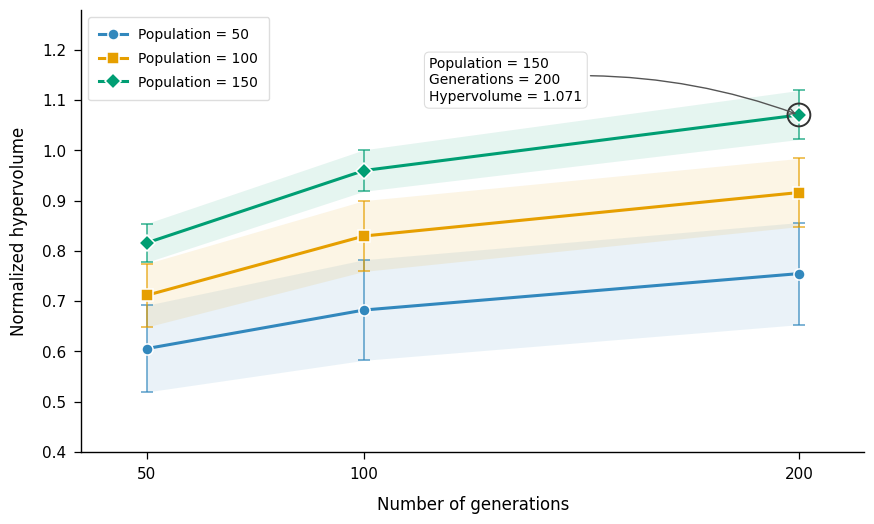


Best configuration:
Population: 150
Generations: 200
Mean hypervolume: 1.070726

Figure saved successfully:
JPG: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/Comment_3_7_NSGA2_Sensitivity/Fig_Comment3_7_NSGA2_Sensitivity_Enhanced.jpg
PDF: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/Comment_3_7_NSGA2_Sensitivity/Fig_Comment3_7_NSGA2_Sensitivity_Enhanced.pdf

STEP 8.7 completed successfully.


In [80]:

# ============================================================
# STEP 8.7: Publication-quality NSGA-II sensitivity figure
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

print("=" * 75)
print("STEP 8.7: PUBLICATION-QUALITY SENSITIVITY FIGURE")
print("=" * 75)

# ------------------------------------------------------------
# 1. Load statistical summary from Step 8.6
# ------------------------------------------------------------

summary_path = os.path.join(
    SENSITIVITY_FOLDER,
    "Step8_6_Statistical_Summary.csv"
)

plot_df = pd.read_csv(summary_path)

required_columns = [
    "Population",
    "Generations",
    "HV_Mean",
    "HV_SD"
]

missing_columns = [
    col for col in required_columns
    if col not in plot_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

# ------------------------------------------------------------
# 2. Set publication-quality formatting
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "font.weight": "normal",
    "axes.labelsize": 12,
    "axes.labelweight": "normal",
    "axes.titleweight": "normal",
    "axes.linewidth": 1.0,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.dpi": 300
})

# ------------------------------------------------------------
# 3. Define population styles
# ------------------------------------------------------------

styles = {
    50: {
        "color": "#3288BD",
        "marker": "o"
    },
    100: {
        "color": "#E69F00",
        "marker": "s"
    },
    150: {
        "color": "#009E73",
        "marker": "D"
    }
}

# ------------------------------------------------------------
# 4. Create figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 5.5),
    facecolor="white"
)

for pop_size in POPULATION_SIZES:

    subset = (
        plot_df[
            plot_df["Population"] == pop_size
        ]
        .sort_values("Generations")
    )

    x = subset["Generations"].to_numpy()
    y = subset["HV_Mean"].to_numpy()
    sd = subset["HV_SD"].to_numpy()

    style = styles[pop_size]

    # Shaded uncertainty region: mean +/- standard deviation
    ax.fill_between(
        x,
        y - sd,
        y + sd,
        color=style["color"],
        alpha=0.10,
        linewidth=0,
        zorder=1
    )

    # Mean hypervolume curve
    ax.plot(
        x,
        y,
        color=style["color"],
        marker=style["marker"],
        markersize=8,
        linewidth=2.2,
        markeredgecolor="white",
        markeredgewidth=1.1,
        label=f"Population = {pop_size}",
        zorder=3
    )

    # Standard deviation error bars
    ax.errorbar(
        x,
        y,
        yerr=sd,
        fmt="none",
        ecolor=style["color"],
        elinewidth=1.1,
        capsize=4,
        capthick=1.1,
        alpha=0.8,
        zorder=2
    )

# ------------------------------------------------------------
# 5. Highlight the best configuration
# ------------------------------------------------------------

best = plot_df.loc[
    plot_df["HV_Mean"].idxmax()
]

best_population = int(best["Population"])
best_generations = int(best["Generations"])
best_hv = float(best["HV_Mean"])

ax.scatter(
    best_generations,
    best_hv,
    s=270,
    facecolors="none",
    edgecolors="#333333",
    linewidths=1.4,
    zorder=5
)

ax.annotate(
    (
        f"Population = {best_population}\n"
        f"Generations = {best_generations}\n"
        f"Hypervolume = {best_hv:.3f}"
    ),
    xy=(
        best_generations,
        best_hv
    ),
    xytext=(115, 1.14),
    fontsize=10,
    fontweight="normal",
    ha="left",
    va="center",
    arrowprops={
        "arrowstyle": "->",
        "color": "#555555",
        "lw": 1.0,
        "connectionstyle": "arc3,rad=-0.12"
    },
    bbox={
        "boxstyle": "round,pad=0.35",
        "facecolor": "white",
        "edgecolor": "#DDDDDD",
        "linewidth": 0.8
    },
    zorder=6
)

# ------------------------------------------------------------
# 6. Format axes
# ------------------------------------------------------------

ax.set_xlabel(
    "Number of generations",
    fontsize=12,
    fontweight="normal",
    labelpad=10
)

ax.set_ylabel(
    "Normalized hypervolume",
    fontsize=12,
    fontweight="normal",
    labelpad=10
)

ax.set_xticks(GENERATION_LIMITS)
ax.set_xlim(35, 215)

ax.set_ylim(0.40, 1.28)
ax.yaxis.set_major_locator(
    MultipleLocator(0.1)
)

# Remove all grid lines
ax.grid(False)
ax.xaxis.grid(False)
ax.yaxis.grid(False)

# Clean axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(1.0)
ax.spines["bottom"].set_linewidth(1.0)

ax.tick_params(
    axis="both",
    which="major",
    direction="out",
    length=5,
    width=0.9,
    pad=6
)

# Ensure tick labels are not bold
for tick_label in (
    ax.get_xticklabels()
    + ax.get_yticklabels()
):
    tick_label.set_fontweight("normal")

# ------------------------------------------------------------
# 7. Legend
# ------------------------------------------------------------

legend = ax.legend(
    loc="upper left",
    frameon=True,
    facecolor="white",
    edgecolor="#DDDDDD",
    framealpha=1.0,
    borderpad=0.8,
    labelspacing=0.7
)

for legend_text in legend.get_texts():
    legend_text.set_fontweight("normal")

# ------------------------------------------------------------
# 8. Adjust layout
# ------------------------------------------------------------

fig.tight_layout(pad=1.5)

# ------------------------------------------------------------
# 9. Save figure at 300 DPI
# ------------------------------------------------------------

figure_jpg = os.path.join(
    SENSITIVITY_FOLDER,
    "Fig_Comment3_7_NSGA2_Sensitivity_Enhanced.jpg"
)

figure_pdf = os.path.join(
    SENSITIVITY_FOLDER,
    "Fig_Comment3_7_NSGA2_Sensitivity_Enhanced.pdf"
)

fig.savefig(
    figure_jpg,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight",
    facecolor="white"
)

# ------------------------------------------------------------
# 10. Display figure
# ------------------------------------------------------------

plt.show()

print("\nBest configuration:")
print("Population:", best_population)
print("Generations:", best_generations)
print("Mean hypervolume:", round(best_hv, 6))

print("\nFigure saved successfully:")
print("JPG:", figure_jpg)
print("PDF:", figure_pdf)

print("\nSTEP 8.7 completed successfully.")


In [81]:

# ============================================================
# STEP 8.8: Prepare Pareto weight sensitivity analysis
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 75)
print("STEP 8.8: PARETO WEIGHT SENSITIVITY PREPARATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Locate results from Step 8.5
# ------------------------------------------------------------

results_path = os.path.join(
    SENSITIVITY_FOLDER,
    "Step8_5_All_Runs.csv"
)

fronts_folder = os.path.join(
    SENSITIVITY_FOLDER,
    "Pareto_Fronts"
)

if not os.path.isfile(results_path):
    raise FileNotFoundError(
        f"Missing sensitivity results: {results_path}"
    )

if not os.path.isdir(fronts_folder):
    raise FileNotFoundError(
        f"Missing Pareto fronts folder: {fronts_folder}"
    )

results_df_38 = pd.read_csv(results_path)

# ------------------------------------------------------------
# 2. Define objective weights
# Equation (8): w1 = peak, w2 = cost
# ------------------------------------------------------------

WEIGHT_SCENARIOS = {
    "Cost_priority": (0.2, 0.8),
    "Equal_priority": (0.5, 0.5),
    "Peak_priority": (0.8, 0.2)
}

EPSILON = 1e-12

# ------------------------------------------------------------
# 3. Verify all saved Pareto fronts
# ------------------------------------------------------------

front_records = []
missing_fronts = []
invalid_fronts = []

for _, run in results_df_38.iterrows():

    run_id = str(run["RunID"])

    front_path = os.path.join(
        fronts_folder,
        f"{run_id}.csv"
    )

    if not os.path.isfile(front_path):
        missing_fronts.append(run_id)
        continue

    front_df = pd.read_csv(front_path)

    required_columns = [
        "ChargingCost",
        "PeakLoad_kW"
    ]

    if (
        not all(c in front_df.columns
                for c in required_columns)
        or front_df.empty
    ):
        invalid_fronts.append(run_id)
        continue

    F = front_df[
        required_columns
    ].to_numpy(dtype=float)

    if not np.isfinite(F).all():
        invalid_fronts.append(run_id)
        continue

    front_records.append({
        "RunID": run_id,
        "Population": int(run["Population"]),
        "Generations": int(run["Generations"]),
        "Seed": int(run["Seed"]),
        "ParetoSolutions": len(F),
        "Cost_Min": float(F[:, 0].min()),
        "Cost_Max": float(F[:, 0].max()),
        "Peak_Min": float(F[:, 1].min()),
        "Peak_Max": float(F[:, 1].max())
    })

front_summary_38 = pd.DataFrame(front_records)

# ------------------------------------------------------------
# 4. Check completeness
# ------------------------------------------------------------

print("\nSaved optimization runs:", len(results_df_38))
print("Valid Pareto fronts:", len(front_summary_38))
print("Missing fronts:", len(missing_fronts))
print("Invalid fronts:", len(invalid_fronts))

if missing_fronts:
    print("Missing:", missing_fronts)

if invalid_fronts:
    print("Invalid:", invalid_fronts)

if len(front_summary_38) != 45:
    raise RuntimeError(
        "Expected 45 valid Pareto fronts. "
        "Check the missing or invalid files."
    )

# ------------------------------------------------------------
# 5. Display weight scenarios
# ------------------------------------------------------------

print("\nWeight scenarios:")
for name, (w_peak, w_cost) in WEIGHT_SCENARIOS.items():
    print(
        f"{name}: "
        f"w1 (peak) = {w_peak}, "
        f"w2 (cost) = {w_cost}"
    )

# ------------------------------------------------------------
# 6. Check objective ranges
# ------------------------------------------------------------

print("\nObjective ranges across all 45 fronts:")

print(
    "Charging cost:",
    round(front_summary_38["Cost_Min"].min(), 4),
    "to",
    round(front_summary_38["Cost_Max"].max(), 4)
)

print(
    "Peak load (kW):",
    round(front_summary_38["Peak_Min"].min(), 4),
    "to",
    round(front_summary_38["Peak_Max"].max(), 4)
)

# ------------------------------------------------------------
# 7. Save verification summary
# ------------------------------------------------------------

output_path = os.path.join(
    SENSITIVITY_FOLDER,
    "Step8_8_Pareto_Front_Verification.csv"
)

front_summary_38.to_csv(
    output_path,
    index=False
)

print("\nVerification summary saved to:")
print(output_path)

print("\nSTEP 8.8 completed successfully.")


STEP 8.8: PARETO WEIGHT SENSITIVITY PREPARATION

Saved optimization runs: 45
Valid Pareto fronts: 45
Missing fronts: 0
Invalid fronts: 0

Weight scenarios:
Cost_priority: w1 (peak) = 0.2, w2 (cost) = 0.8
Equal_priority: w1 (peak) = 0.5, w2 (cost) = 0.5
Peak_priority: w1 (peak) = 0.8, w2 (cost) = 0.2

Objective ranges across all 45 fronts:
Charging cost: 81.0911 to 93.7789
Peak load (kW): 204.0837 to 296.5648

Verification summary saved to:
/content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/Comment_3_7_NSGA2_Sensitivity/Step8_8_Pareto_Front_Verification.csv

STEP 8.8 completed successfully.


In [82]:

# ============================================================
# STEP 8.9: Pareto weight sensitivity analysis
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 75)
print("STEP 8.9: PARETO WEIGHT SENSITIVITY ANALYSIS")
print("=" * 75)

# ------------------------------------------------------------
# 1. Load verified optimization results
# ------------------------------------------------------------

results_path = os.path.join(
    SENSITIVITY_FOLDER,
    "Step8_5_All_Runs.csv"
)

results_df_39 = pd.read_csv(results_path)

fronts_folder = os.path.join(
    SENSITIVITY_FOLDER,
    "Pareto_Fronts"
)

# Objective weights: (peak-load weight, cost weight)
WEIGHT_SCENARIOS = {
    "Cost_priority": (0.2, 0.8),
    "Equal_priority": (0.5, 0.5),
    "Peak_priority": (0.8, 0.2)
}

EPSILON = 1e-12

# ------------------------------------------------------------
# 2. Evaluate each weight scenario for every Pareto front
# ------------------------------------------------------------

weight_results = []

for _, run in results_df_39.iterrows():

    run_id = str(run["RunID"])

    front_path = os.path.join(
        fronts_folder,
        f"{run_id}.csv"
    )

    front_df = pd.read_csv(front_path)

    # Objective order in original implementation:
    # Column 0: charging cost
    # Column 1: peak community load
    F = front_df[
        ["ChargingCost", "PeakLoad_kW"]
    ].to_numpy(dtype=float)

    # Min-max normalization for each Pareto front
    F_min = F.min(axis=0)
    F_max = F.max(axis=0)

    F_norm = (
        (F - F_min)
        / (F_max - F_min + EPSILON)
    )

    for scenario, (w_peak, w_cost) in WEIGHT_SCENARIOS.items():

        # Weighted objective:
        # w1 * normalized peak + w2 * normalized cost
        weighted_scores = (
            w_peak * F_norm[:, 1]
            + w_cost * F_norm[:, 0]
        )

        selected_index = int(
            np.argmin(weighted_scores)
        )

        weight_results.append({
            "RunID": run_id,
            "Population": int(run["Population"]),
            "Generations": int(run["Generations"]),
            "Seed": int(run["Seed"]),
            "Scenario": scenario,
            "PeakWeight": w_peak,
            "CostWeight": w_cost,
            "SelectedCost": float(F[selected_index, 0]),
            "SelectedPeak_kW": float(F[selected_index, 1]),
            "WeightedScore": float(
                weighted_scores[selected_index]
            ),
            "SelectedIndex": selected_index,
            "ParetoSolutions": len(F)
        })

# ------------------------------------------------------------
# 3. Save detailed results
# ------------------------------------------------------------

weight_df = pd.DataFrame(weight_results)

details_path = os.path.join(
    SENSITIVITY_FOLDER,
    "Step8_9_Weight_Sensitivity_All_Runs.csv"
)

weight_df.to_csv(
    details_path,
    index=False
)

# ------------------------------------------------------------
# 4. Statistical summary for each configuration
# ------------------------------------------------------------

weight_summary = (
    weight_df.groupby(
        ["Population", "Generations", "Scenario",
         "PeakWeight", "CostWeight"]
    )
    .agg(
        Runs=("Seed", "count"),
        Cost_Mean=("SelectedCost", "mean"),
        Cost_SD=("SelectedCost", "std"),
        Peak_Mean=("SelectedPeak_kW", "mean"),
        Peak_SD=("SelectedPeak_kW", "std")
    )
    .reset_index()
)

summary_path = os.path.join(
    SENSITIVITY_FOLDER,
    "Step8_9_Weight_Sensitivity_Summary.csv"
)

weight_summary.to_csv(
    summary_path,
    index=False
)

# ------------------------------------------------------------
# 5. Display original configuration results
# ------------------------------------------------------------

original_config = weight_summary[
    (weight_summary["Population"] == 150)
    & (weight_summary["Generations"] == 200)
].copy()

scenario_order = [
    "Cost_priority",
    "Equal_priority",
    "Peak_priority"
]

original_config["Scenario"] = pd.Categorical(
    original_config["Scenario"],
    categories=scenario_order,
    ordered=True
)

original_config = original_config.sort_values("Scenario")

print("\n" + "=" * 75)
print("ORIGINAL CONFIGURATION: POPULATION 150, GENERATIONS 200")
print("=" * 75)

print(
    original_config[
        [
            "Scenario",
            "PeakWeight",
            "CostWeight",
            "Runs",
            "Cost_Mean",
            "Cost_SD",
            "Peak_Mean",
            "Peak_SD"
        ]
    ]
    .round(4)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 6. Verify equal-weight consistency with Step 8.6
# ------------------------------------------------------------

equal_weight = original_config[
    original_config["Scenario"] == "Equal_priority"
].iloc[0]

step86_path = os.path.join(
    SENSITIVITY_FOLDER,
    "Step8_6_Statistical_Summary.csv"
)

step86 = pd.read_csv(step86_path)

baseline = step86[
    (step86["Population"] == 150)
    & (step86["Generations"] == 200)
].iloc[0]

cost_difference = abs(
    equal_weight["Cost_Mean"] - baseline["Cost_Mean"]
)

peak_difference = abs(
    equal_weight["Peak_Mean"] - baseline["Peak_Mean"]
)

print("\nEqual-weight consistency check:")
print("Cost difference:", round(cost_difference, 10))
print("Peak difference:", round(peak_difference, 10))

if cost_difference > 1e-8 or peak_difference > 1e-8:
    raise RuntimeError(
        "Equal-weight results do not match Step 8.6."
    )

# ------------------------------------------------------------
# 7. Display completion summary
# ------------------------------------------------------------

print("\nTotal Pareto fronts:", len(results_df_39))
print("Weight scenarios:", len(WEIGHT_SCENARIOS))
print("Total selections:", len(weight_df))

print("\nDetailed results saved to:")
print(details_path)

print("\nStatistical summary saved to:")
print(summary_path)

print("\nSTEP 8.9 completed successfully.")


STEP 8.9: PARETO WEIGHT SENSITIVITY ANALYSIS

ORIGINAL CONFIGURATION: POPULATION 150, GENERATIONS 200
      Scenario  PeakWeight  CostWeight  Runs  Cost_Mean  Cost_SD  Peak_Mean  Peak_SD
 Cost_priority         0.2         0.8     5    81.8022   0.4302   249.4305  16.6216
Equal_priority         0.5         0.5     5    82.8505   0.4192   219.2729   9.4951
 Peak_priority         0.8         0.2     5    84.0141   0.5148   208.4707   4.9636

Equal-weight consistency check:
Cost difference: 0.0
Peak difference: 0.0

Total Pareto fronts: 45
Weight scenarios: 3
Total selections: 135

Detailed results saved to:
/content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/Comment_3_7_NSGA2_Sensitivity/Step8_9_Weight_Sensitivity_All_Runs.csv

Statistical summary saved to:
/content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/Comment_3_7_NSGA2_Sensitivity/Step8_9_Weight_Sensitivity_Summary.csv

STEP 8.9 completed successfully.


In [83]:

# ============================================================
# STEP 8.10: Normalization reference sensitivity
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 75)
print("STEP 8.10: NORMALIZATION REFERENCE SENSITIVITY")
print("=" * 75)

results_df = pd.read_csv(
    os.path.join(
        SENSITIVITY_FOLDER,
        "Step8_5_All_Runs.csv"
    )
)

fronts_folder = os.path.join(
    SENSITIVITY_FOLDER,
    "Pareto_Fronts"
)

# Objective order: cost, peak load
EPSILON = 1e-12

WEIGHT_SCENARIOS = {
    "Cost_priority": (0.2, 0.8),
    "Equal_priority": (0.5, 0.5),
    "Peak_priority": (0.8, 0.2)
}

# ------------------------------------------------------------
# 1. Determine global normalization reference values
# ------------------------------------------------------------

all_fronts = []

for _, run in results_df.iterrows():
    path = os.path.join(
        fronts_folder,
        f"{run['RunID']}.csv"
    )

    front = pd.read_csv(path)[
        ["ChargingCost", "PeakLoad_kW"]
    ].to_numpy(dtype=float)

    all_fronts.append(front)

pooled = np.vstack(all_fronts)

global_min = pooled.min(axis=0)
global_max = pooled.max(axis=0)

print("\nGlobal reference values:")
print("Cost min/max:", global_min[0], global_max[0])
print("Peak min/max:", global_min[1], global_max[1])

# ------------------------------------------------------------
# 2. Compare local and global normalization
# ------------------------------------------------------------

records = []

for _, run in results_df.iterrows():

    front = pd.read_csv(
        os.path.join(
            fronts_folder,
            f"{run['RunID']}.csv"
        )
    )[
        ["ChargingCost", "PeakLoad_kW"]
    ].to_numpy(dtype=float)

    local_min = front.min(axis=0)
    local_max = front.max(axis=0)

    normalization_methods = {
        "Local_minmax": (
            local_min,
            local_max
        ),
        "Global_minmax": (
            global_min,
            global_max
        )
    }

    for method, (ref_min, ref_max) in normalization_methods.items():

        normalized = (
            (front - ref_min)
            / (ref_max - ref_min + EPSILON)
        )

        for scenario, (w_peak, w_cost) in WEIGHT_SCENARIOS.items():

            scores = (
                w_cost * normalized[:, 0]
                + w_peak * normalized[:, 1]
            )

            selected_index = int(np.argmin(scores))

            records.append({
                "RunID": str(run["RunID"]),
                "Population": int(run["Population"]),
                "Generations": int(run["Generations"]),
                "Seed": int(run["Seed"]),
                "Method": method,
                "Scenario": scenario,
                "PeakWeight": w_peak,
                "CostWeight": w_cost,
                "SelectedIndex": selected_index,
                "SelectedCost": float(front[selected_index, 0]),
                "SelectedPeak_kW": float(front[selected_index, 1])
            })

normalization_df = pd.DataFrame(records)

# ------------------------------------------------------------
# 3. Verify local results against Step 8.9
# ------------------------------------------------------------

previous = pd.read_csv(
    os.path.join(
        SENSITIVITY_FOLDER,
        "Step8_9_Weight_Sensitivity_All_Runs.csv"
    )
)

local = normalization_df[
    normalization_df["Method"] == "Local_minmax"
]

check = local.merge(
    previous,
    on=["RunID", "Scenario"],
    suffixes=("_new", "_old"),
    validate="one_to_one"
)

assert len(check) == 135

assert np.allclose(
    check["SelectedCost_new"],
    check["SelectedCost_old"],
    atol=1e-8
)

assert np.allclose(
    check["SelectedPeak_kW_new"],
    check["SelectedPeak_kW_old"],
    atol=1e-8
)

print("\nLocal normalization verification: PASSED")

# ------------------------------------------------------------
# 4. Summarize original NSGA-II configuration
# ------------------------------------------------------------

original = normalization_df[
    (normalization_df["Population"] == 150)
    & (normalization_df["Generations"] == 200)
]

summary = (
    original.groupby(["Method", "Scenario"])
    .agg(
        Runs=("Seed", "count"),
        Cost_Mean=("SelectedCost", "mean"),
        Cost_SD=("SelectedCost", "std"),
        Peak_Mean=("SelectedPeak_kW", "mean"),
        Peak_SD=("SelectedPeak_kW", "std")
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("POPULATION 150, GENERATIONS 200")
print("=" * 75)

print(
    summary.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 5. Count selection changes
# ------------------------------------------------------------

comparison = normalization_df.pivot(
    index=["RunID", "Population", "Generations",
           "Seed", "Scenario"],
    columns="Method",
    values="SelectedIndex"
).reset_index()

comparison["Changed"] = (
    comparison["Local_minmax"]
    != comparison["Global_minmax"]
)

change_summary = (
    comparison.groupby("Scenario")["Changed"]
    .agg(["sum", "count"])
    .reset_index()
)

change_summary["Change_Percent"] = (
    100 * change_summary["sum"]
    / change_summary["count"]
)

print("\nSelection changes across all 45 fronts:")
print(change_summary.to_string(index=False))

original_changes = comparison[
    (comparison["Population"] == 150)
    & (comparison["Generations"] == 200)
]

print("\nSelection changes for population 150, generations 200:")
print(
    original_changes.groupby("Scenario")["Changed"]
    .agg(["sum", "count"])
    .to_string()
)

# ------------------------------------------------------------
# 6. Save results
# ------------------------------------------------------------

detail_path = os.path.join(
    SENSITIVITY_FOLDER,
    "Step8_10_Normalization_All_Runs.csv"
)

summary_path = os.path.join(
    SENSITIVITY_FOLDER,
    "Step8_10_Normalization_Summary.csv"
)

changes_path = os.path.join(
    SENSITIVITY_FOLDER,
    "Step8_10_Normalization_Changes.csv"
)

normalization_df.to_csv(detail_path, index=False)
summary.to_csv(summary_path, index=False)
comparison.to_csv(changes_path, index=False)

print("\nSaved files:")
print(detail_path)
print(summary_path)
print(changes_path)

print("\nTotal selections:", len(normalization_df))
print("STEP 8.10 completed successfully.")


STEP 8.10: NORMALIZATION REFERENCE SENSITIVITY

Global reference values:
Cost min/max: 81.0910528933941 93.7789441454422
Peak min/max: 204.0837016324382 296.564815097787

Local normalization verification: PASSED

POPULATION 150, GENERATIONS 200
       Method       Scenario  Runs  Cost_Mean  Cost_SD  Peak_Mean  Peak_SD
Global_minmax  Cost_priority     5    82.2615   0.3285   231.0663  10.2133
Global_minmax Equal_priority     5    83.6976   0.7441   209.8950   4.1298
Global_minmax  Peak_priority     5    84.0601   0.4508   208.1745   4.3209
 Local_minmax  Cost_priority     5    81.8022   0.4302   249.4305  16.6216
 Local_minmax Equal_priority     5    82.8505   0.4192   219.2729   9.4951
 Local_minmax  Peak_priority     5    84.0141   0.5148   208.4707   4.9636

Selection changes across all 45 fronts:
      Scenario  sum  count  Change_Percent
 Cost_priority   21     45       46.666667
Equal_priority   24     45       53.333333
 Peak_priority   15     45       33.333333

Selection change

STEP 8.11: ENHANCED SENSITIVITY FIGURE


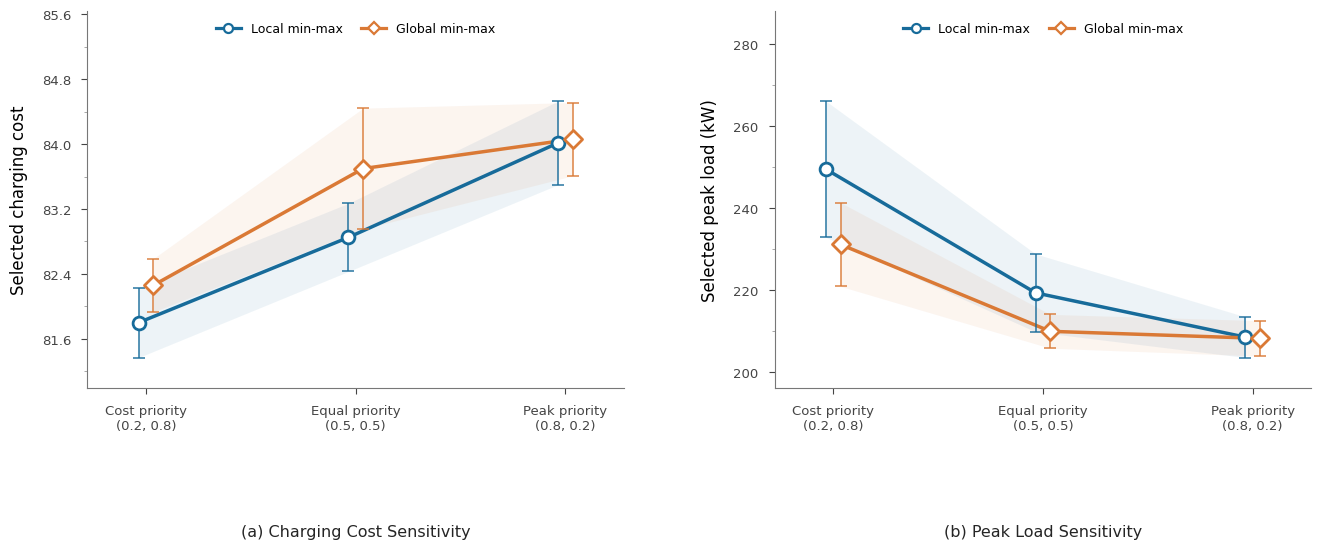


Statistical summary:
      Scenario        Method  Cost_Mean  Cost_SD  Peak_Mean  Peak_SD  Runs
 Cost_priority Global_minmax    82.2615   0.3285   231.0663  10.2133     5
 Cost_priority  Local_minmax    81.8022   0.4302   249.4305  16.6216     5
Equal_priority Global_minmax    83.6976   0.7441   209.8950   4.1298     5
Equal_priority  Local_minmax    82.8505   0.4192   219.2729   9.4951     5
 Peak_priority Global_minmax    84.0601   0.4508   208.1745   4.3209     5
 Peak_priority  Local_minmax    84.0141   0.5148   208.4707   4.9636     5

JPG: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/Comment_3_7_NSGA2_Sensitivity/Fig_Comment3_8_Weight_Normalization_Sensitivity.jpg
PDF: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/Comment_3_7_NSGA2_Sensitivity/Fig_Comment3_8_Weight_Normalization_Sensitivity.pdf

STEP 8.11 completed successfully.


In [84]:

# ============================================================
# STEP 8.11: ENHANCED WEIGHT AND NORMALIZATION SENSITIVITY
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib .pyplot as plt
from matplotlib .lines import Line2D
from matplotlib .ticker import AutoMinorLocator ,MaxNLocator

print ("="*75 )
print ("STEP 8.11: ENHANCED SENSITIVITY FIGURE")
print ("="*75 )

# 1. Load and verify results
data_path =os .path .join (
SENSITIVITY_FOLDER ,
"Step8_10_Normalization_All_Runs.csv"
)

normalization_plot_df =pd .read_csv (data_path )
normalization_plot_df =normalization_plot_df [
(normalization_plot_df ["Population"]==150 )
&(normalization_plot_df ["Generations"]==200 )
].copy ()

scenarios =[
"Cost_priority",
"Equal_priority",
"Peak_priority"
]

labels =[
"Cost priority\n(0.2, 0.8)",
"Equal priority\n(0.5, 0.5)",
"Peak priority\n(0.8, 0.2)"
]

methods =["Local_minmax","Global_minmax"]

summary =(
normalization_plot_df .groupby (["Scenario","Method"])
.agg (
Cost_Mean =("SelectedCost","mean"),
Cost_SD =("SelectedCost","std"),
Peak_Mean =("SelectedPeak_kW","mean"),
Peak_SD =("SelectedPeak_kW","std"),
Runs =("Seed","count")
)
.reset_index ()
)

assert len (summary )==6
assert (summary ["Runs"]==5 ).all ()

# 2. Figure typography
plt .rcParams .update ({
"font.family":"DejaVu Sans",
"font.size":10.5 ,
"font.weight":"normal",
"axes.labelweight":"normal",
"axes.titleweight":"normal",
"axes.linewidth":0.8 ,
"xtick.labelsize":9.5 ,
"ytick.labelsize":9.5 ,
"legend.fontsize":9.2 ,
"figure.facecolor":"white",
"axes.facecolor":"white",
"savefig.facecolor":"white",
"pdf.fonttype":42 ,
"ps.fonttype":42
})

styles ={
"Local_minmax":{
"label":"Local min-max",
"color":"#176B9A",
"marker":"o",
"shift":-0.035
},
"Global_minmax":{
"label":"Global min-max",
"color":"#DA7935",
"marker":"D",
"shift":0.035
}
}

# 3. Build figure
fig ,axes =plt .subplots (
1 ,2 ,
figsize =(13.6 ,5.8 )
)

x =np .arange (3 ,dtype =float )

metrics =[
{
"mean":"Cost_Mean",
"sd":"Cost_SD",
"ylabel":"Selected charging cost",
"caption":"(a) Charging Cost Sensitivity"
},
{
"mean":"Peak_Mean",
"sd":"Peak_SD",
"ylabel":"Selected peak load (kW)",
"caption":"(b) Peak Load Sensitivity"
}
]

for ax ,metric in zip (axes ,metrics ):

    for method in methods :

        subset =(
        summary [summary ["Method"]==method ]
        .set_index ("Scenario")
        .loc [scenarios ]
        )

        means =subset [metric ["mean"]].to_numpy ()
        sds =subset [metric ["sd"]].to_numpy ()

        style =styles [method ]
        xx =x +style ["shift"]

        # Subtle standard deviation band
        ax .fill_between (
        xx ,
        means -sds ,
        means +sds ,
        color =style ["color"],
        alpha =0.075 ,
        linewidth =0 ,
        zorder =1
        )

        # Refined connecting line
        ax .plot (
        xx ,
        means ,
        color =style ["color"],
        linewidth =2.5 ,
        solid_capstyle ="round",
        zorder =3
        )

        # Error bars
        ax .errorbar (
        xx ,
        means ,
        yerr =sds ,
        fmt ="none",
        ecolor =style ["color"],
        elinewidth =1.2 ,
        capsize =4 ,
        capthick =1.2 ,
        alpha =0.85 ,
        zorder =4
        )

        # White-centred markers
        ax .scatter (
        xx ,
        means ,
        s =85 ,
        marker =style ["marker"],
        facecolors ="white",
        edgecolors =style ["color"],
        linewidths =2 ,
        zorder =5
        )

        # Axis formatting
    ax .set_xticks (x )
    ax .set_xticklabels (labels )
    ax .set_xlim (-0.28 ,2.28 )
    ax .set_ylabel (metric ["ylabel"],labelpad =10 )

    ax .grid (False )

    for spine in ["top","right"]:
        ax .spines [spine ].set_visible (False )

    for spine in ["left","bottom"]:
        ax .spines [spine ].set_color ("#777777")

    ax .tick_params (
    axis ="both",
    direction ="out",
    length =4.5 ,
    width =0.8 ,
    colors ="#444444",
    pad =7
    )

    ax .yaxis .set_major_locator (
    MaxNLocator (nbins =6 )
    )

    ax .yaxis .set_minor_locator (
    AutoMinorLocator (2 )
    )

    ax .tick_params (
    axis ="y",
    which ="minor",
    length =2.5 ,
    color ="#999999"
    )

    # Give the data and legend sufficient space
    all_means =summary [metric ["mean"]].to_numpy ()
    all_sds =summary [metric ["sd"]].to_numpy ()

    low =np .min (all_means -all_sds )
    high =np .max (all_means +all_sds )
    spread =high -low

    ax .set_ylim (
    low -0.12 *spread ,
    high +0.35 *spread
    )

    # Individual legend for each subplot
    legend_handles =[
    Line2D (
    [0 ],[0 ],
    color =styles [m ]["color"],
    linewidth =2.3 ,
    marker =styles [m ]["marker"],
    markersize =6.5 ,
    markerfacecolor ="white",
    markeredgewidth =1.6 ,
    label =styles [m ]["label"]
    )
    for m in methods
    ]

    ax .legend (
    handles =legend_handles ,
    loc ="upper center",
    bbox_to_anchor =(0.5 ,1.0 ),
    ncol =2 ,
    frameon =False ,
    handlelength =2.0 ,
    columnspacing =1.5 ,
    fontsize =9
    )

    # Panel caption beneath x-axis
    ax .text (
    0.5 ,-0.36 ,
    metric ["caption"],
    transform =ax .transAxes ,
    ha ="center",
    va ="top",
    fontsize =11.5 ,
    fontweight ="normal",
    color ="#252525"
    )

    # 4. Spacing
fig .subplots_adjust (
left =0.085 ,
right =0.985 ,
bottom =0.29 ,
top =0.94 ,
wspace =0.28
)

# 5. Save JPG and PDF
jpg_path =os .path .join (
SENSITIVITY_FOLDER ,
"Fig_Comment3_8_Weight_Normalization_Sensitivity.jpg"
)

pdf_path =os .path .join (
SENSITIVITY_FOLDER ,
"Fig_Comment3_8_Weight_Normalization_Sensitivity.pdf"
)

fig .savefig (
jpg_path ,
dpi =300 ,
bbox_inches ="tight",
pad_inches =0.18
)

fig .savefig (
pdf_path ,
bbox_inches ="tight",
pad_inches =0.18
)

plt .show ()
plt .close (fig )

# 6. Output
print ("\nStatistical summary:")
print (summary .round (4 ).to_string (index =False ))

print ("\nJPG:",jpg_path )
print ("PDF:",pdf_path )

print ("\nSTEP 8.11 completed successfully.")


# Verify that sensitivity analysis did not overwrite the shared community profile.
assert len(df) == N_SLOTS
assert {"community_load_kw", "rt_price", "tou_price"}.issubset(df.columns)
assert df[["community_load_kw", "rt_price", "tou_price"]].equals(
    community_profile_df[["community_load_kw", "rt_price", "tou_price"]]
)


In [85]:
# ======================================================
# STEP 9: Community-level Uncontrolled Charging (UC)
# ======================================================

import numpy as np
import pandas as pd
import os

def run_uc_schedule(total_required_energy, available_power_kw, dt_hours=DT_HOURS, eta=ETA):
    """
    Uncontrolled charging:
    use all available charging power until total required energy is met.
    """
    ev_kw = np.zeros(len(available_power_kw))
    delivered = 0.0

    for t in range(len(available_power_kw)):
        if available_power_kw[t] > 0 and delivered < total_required_energy:
            ev_kw[t] = available_power_kw[t]
            delivered += eta * ev_kw[t] * dt_hours

            # Trim the last slot if we overshoot
            if delivered > total_required_energy:
                excess = delivered - total_required_energy
                reduce_power = excess / (eta * dt_hours)
                ev_kw[t] = max(ev_kw[t] - reduce_power, 0.0)
                delivered = total_required_energy

    return ev_kw

# ------------------------------------------------------
# Run UC for each penetration level
# ------------------------------------------------------
uc_profiles_by_pen = {}
uc_rows = []

for pen, info in community_inputs.items():
    total_required_energy = info["TotalRequiredEnergy_kWh"]
    available_power_kw = info["AvailablePower_kW"]
    base_load_kw = info["BaseLoad_kW"]
    rt_price = info["RT_Price"]

    if not info["Feasible"]:
        print(f"Skipping UC for {int(pen*100)}% penetration (infeasible).")
        continue

    ev_kw = run_uc_schedule(total_required_energy, available_power_kw)

    total_kw = base_load_kw + ev_kw
    delivered_energy = np.sum(ev_kw * DT_HOURS * ETA)
    charging_cost = np.sum(ev_kw * rt_price * DT_HOURS)

    uc_profiles_by_pen[pen] = ev_kw

    uc_rows.append({
        "Penetration": pen,
        "Method": "UC",
        "NumEVs": info["NumEVs"],
        "RequiredEnergy_kWh": total_required_energy,
        "DeliveredEnergy_kWh": delivered_energy,
        "ChargingCost": charging_cost,
        "PeakTotalLoad_kW": np.max(total_kw),
        "Completed": delivered_energy + 1e-6 >= total_required_energy
    })

uc_results_df = pd.DataFrame(uc_rows)

# Round for presentation
if len(uc_results_df) > 0:
    uc_results_df = uc_results_df.round({
        "RequiredEnergy_kWh": 3,
        "DeliveredEnergy_kWh": 3,
        "ChargingCost": 3,
        "PeakTotalLoad_kW": 3
    })

# Save results
uc_results_file = os.path.join(RESULTS_FOLDER, "community_uc_results.csv")
uc_results_df.to_csv(uc_results_file, index=False)

print("STEP 9 completed successfully.")
print("Saved UC results to:", uc_results_file)
uc_results_df

STEP 9 completed successfully.
Saved UC results to: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/community_uc_results.csv


,Penetration,Method,NumEVs,RequiredEnergy_kWh,DeliveredEnergy_kWh,ChargingCost,PeakTotalLoad_kW,Completed
0,0.2,UC,10,262.656,262.656,22.118,152.0,True
1,0.6,UC,30,963.769,963.769,82.515,300.0,True
2,1.0,UC,50,1329.524,1329.524,111.960,433.2,True


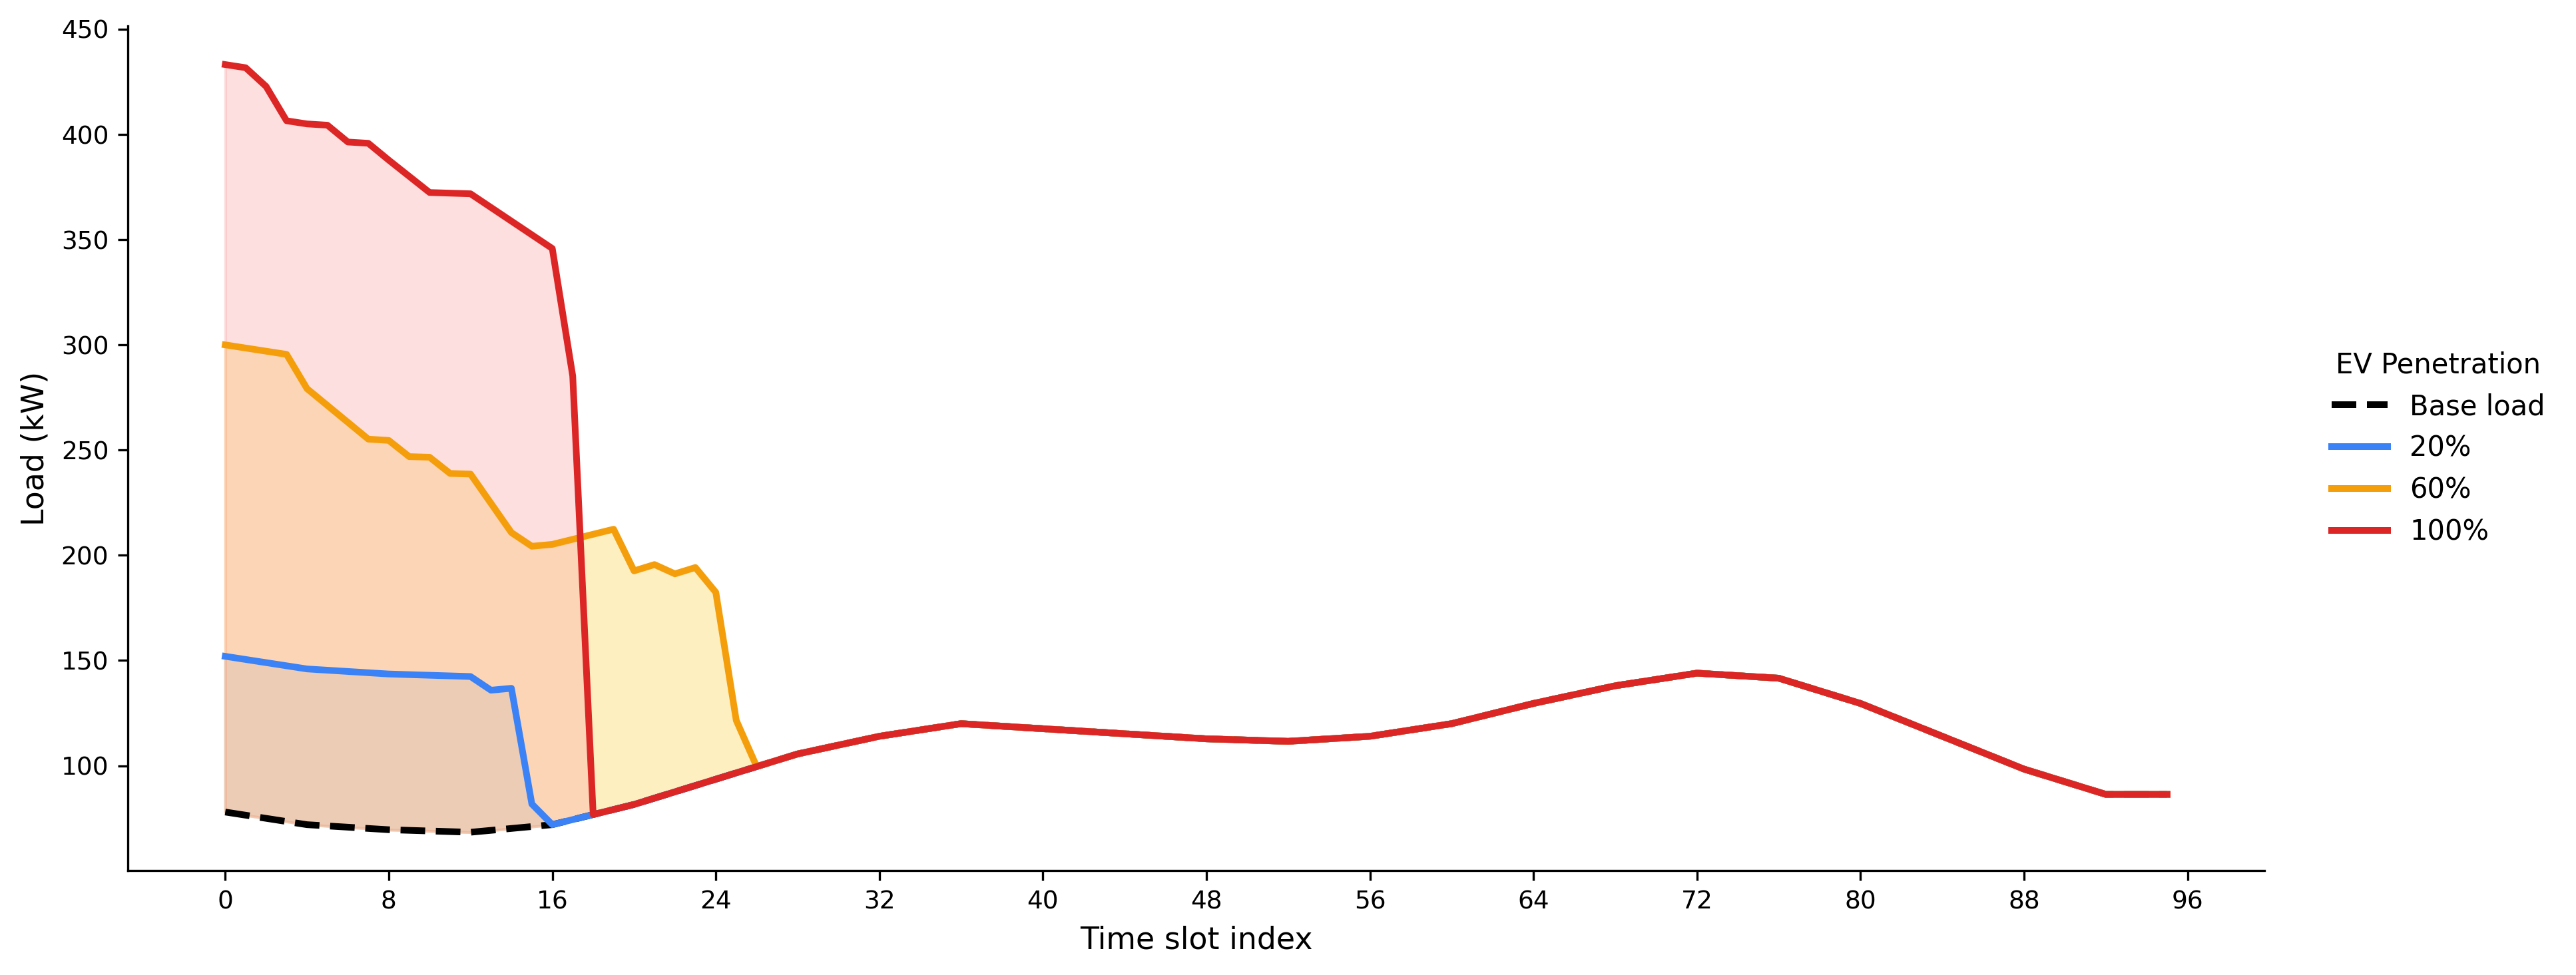

STEP 10 completed successfully.
Figure saved at: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/community_uc_load_styled.png


In [86]:
# ======================================================
# STEP 10: UC load profiles (single plot with penetration)
# ======================================================

import matplotlib.pyplot as plt
import numpy as np
import os

UC_LOAD_FIG = os.path.join(RESULTS_FOLDER, "community_uc_load_styled.png")

fig, ax = plt.subplots(figsize=(13, 5), dpi=300)

x = np.arange(N_SLOTS)
# Use the original community baseline prepared in Step 8
base_load_kw = np.asarray(
    community_inputs[0.20]["BaseLoad_kW"],
    dtype=float
).copy()

# Check the expected 96 time slots
assert len(base_load_kw) == N_SLOTS, (
    "Community baseline must contain 96 time slots."
)

# Verify that the baseline matches all penetration levels
for pen, info in community_inputs.items():
    assert np.allclose(base_load_kw, info["BaseLoad_kW"]), (
        f"Baseline mismatch at {pen:.0%} penetration."
    )

# ------------------------------------------------------
# Base load
# ------------------------------------------------------
ax.plot(
    x,
    base_load_kw,
    linewidth=2.4,
    color="black",
    linestyle="--",
    label="Base load"
)

# ------------------------------------------------------
# Colors for lines and fills
# ------------------------------------------------------
pen_styles = {
    0.20: {"line": "#3B82F6", "fill": "#93C5FD"},
    0.60: {"line": "#F59E0B", "fill": "#FCD34D"},
    1.00: {"line": "#DC2626", "fill": "#FCA5A5"}
}

# ------------------------------------------------------
# Plot UC loads with soft fill
# ------------------------------------------------------
for pen in [0.20, 0.60, 1.00]:
    if pen not in uc_profiles_by_pen:
        continue

    uc_ev_kw = uc_profiles_by_pen[pen]
    total_load_kw = base_load_kw + uc_ev_kw

    ax.fill_between(
        x,
        base_load_kw,
        total_load_kw,
        color=pen_styles[pen]["fill"],
        alpha=0.35
    )

    ax.plot(
        x,
        total_load_kw,
        linewidth=2.4,
        color=pen_styles[pen]["line"],
        label=f"{int(pen*100)}%"
    )

# ------------------------------------------------------
# Styling
# ------------------------------------------------------
ax.set_xlabel("Time slot index", fontsize=11)
ax.set_ylabel("Load (kW)", fontsize=11)

tick_positions = np.arange(0, 97, 8)
ax.set_xticks(tick_positions)
ax.set_xticklabels([str(i) for i in tick_positions], fontsize=9)

ax.tick_params(axis="y", labelsize=9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(False)

ax.legend(
    title="EV Penetration",
    frameon=False,
    fontsize=10,
    title_fontsize=10,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5)
)

plt.tight_layout()
plt.savefig(UC_LOAD_FIG, dpi=300, bbox_inches="tight")
plt.show()

print("STEP 10 completed successfully.")
print("Figure saved at:", UC_LOAD_FIG)

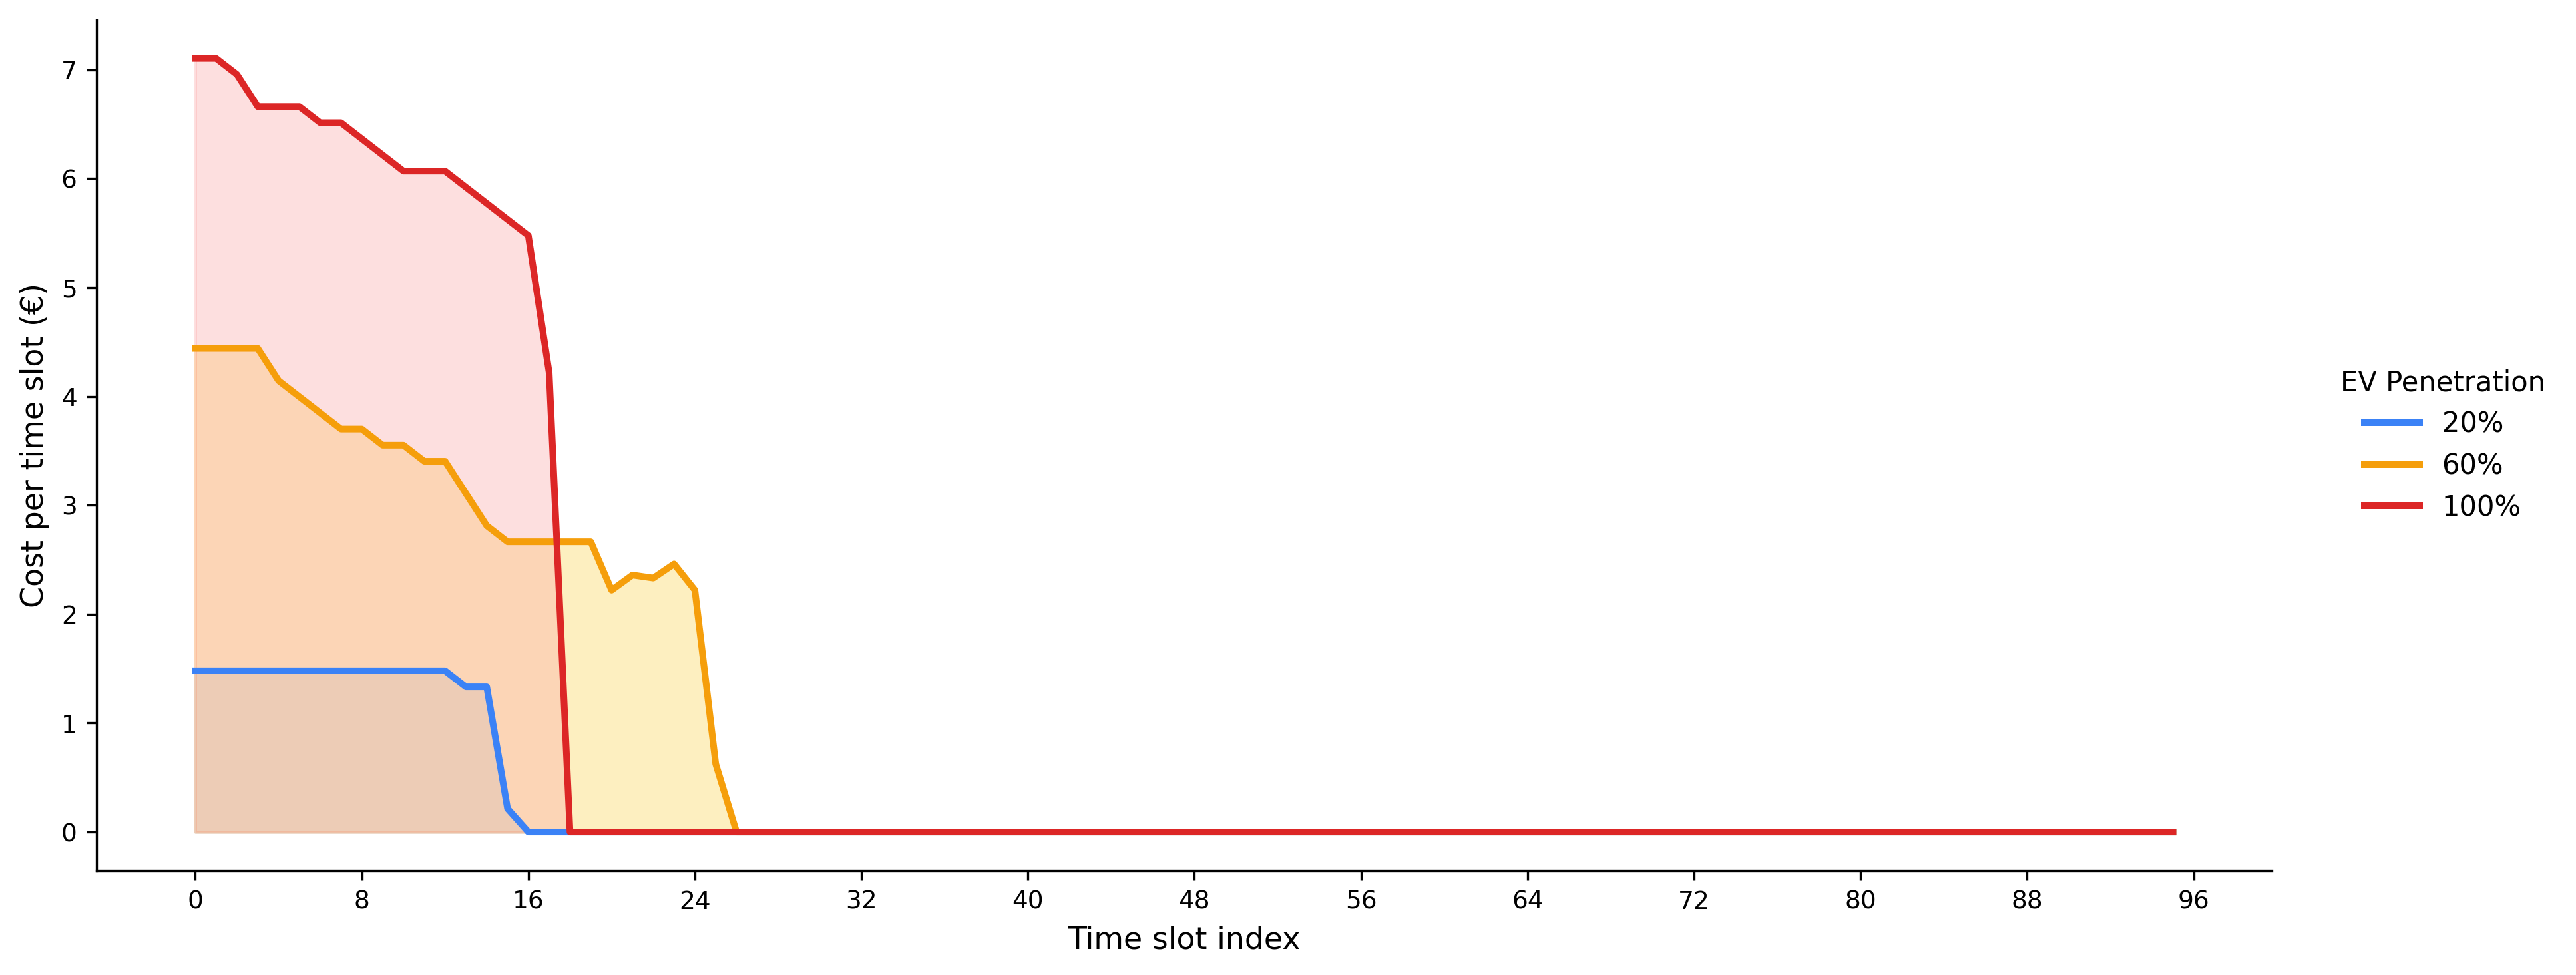

STEP 11 completed successfully.
Figure saved at: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/community_uc_cost_styled.png


In [87]:
# ======================================================
# STEP 11: UC charging cost profiles (single plot with penetration)
# ======================================================

import matplotlib.pyplot as plt
import numpy as np
import os

UC_COST_FIG = os.path.join(RESULTS_FOLDER, "community_uc_cost_styled.png")

fig, ax = plt.subplots(figsize=(13, 5), dpi=300)

x = np.arange(N_SLOTS)
# Use the original real-time prices saved in Step 8
rt_price = np.asarray(
    community_inputs[0.20]["RT_Price"],
    dtype=float
).copy()

# Verify that the price profile has 96 time slots
assert len(rt_price) == N_SLOTS, (
    "Real-time price profile must contain 96 time slots."
)

# Verify identical electricity prices across penetration levels
for pen, info in community_inputs.items():
    assert np.allclose(rt_price, info["RT_Price"]), (
        f"Real-time price mismatch at {pen:.0%} penetration."
    )

# ------------------------------------------------------
# Colors for lines and fills
# ------------------------------------------------------
pen_styles = {
    0.20: {"line": "#3B82F6", "fill": "#93C5FD"},
    0.60: {"line": "#F59E0B", "fill": "#FCD34D"},
    1.00: {"line": "#DC2626", "fill": "#FCA5A5"}
}

# ------------------------------------------------------
# Plot UC slot-wise cost for each penetration
# slot cost = EV load × real-time price × dt
# ------------------------------------------------------
for pen in [0.20, 0.60, 1.00]:
    if pen not in uc_profiles_by_pen:
        continue

    uc_ev_kw = uc_profiles_by_pen[pen]
    slot_cost = uc_ev_kw * rt_price * DT_HOURS

    ax.fill_between(
        x,
        0,
        slot_cost,
        color=pen_styles[pen]["fill"],
        alpha=0.35
    )

    ax.plot(
        x,
        slot_cost,
        linewidth=2.4,
        color=pen_styles[pen]["line"],
        label=f"{int(pen*100)}%"
    )

# ------------------------------------------------------
# Styling
# ------------------------------------------------------
ax.set_xlabel("Time slot index", fontsize=11)
ax.set_ylabel("Cost per time slot (€)", fontsize=11)

tick_positions = np.arange(0, 97, 8)
ax.set_xticks(tick_positions)
ax.set_xticklabels([str(i) for i in tick_positions], fontsize=9)

ax.tick_params(axis="y", labelsize=9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(False)

ax.legend(
    title="EV Penetration",
    frameon=False,
    fontsize=10,
    title_fontsize=10,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5)
)

plt.tight_layout()
plt.savefig(UC_COST_FIG, dpi=300, bbox_inches="tight")
plt.show()

print("STEP 11 completed successfully.")
print("Figure saved at:", UC_COST_FIG)

In [88]:
# ======================================================
# STEP 12: Community-level TOU charging
# ======================================================

import numpy as np
import pandas as pd
import os

def run_tou_schedule(total_required_energy, available_power_kw, tou_price, dt_hours=DT_HOURS, eta=ETA):
    """
    TOU charging:
    allocate charging to the lowest TOU-price slots first,
    subject to available charging power.
    """
    ev_kw = np.zeros(len(available_power_kw))

    # wall-side energy needed
    remaining_energy_wall = total_required_energy / eta

    # only slots where charging is possible
    available_idx = np.where(available_power_kw > 0)[0]

    # sort available slots by TOU price
    sorted_idx = available_idx[np.argsort(tou_price[available_idx])]

    for t in sorted_idx:
        if remaining_energy_wall <= 1e-9:
            break

        slot_energy_wall = available_power_kw[t] * dt_hours
        charge_energy_wall = min(slot_energy_wall, remaining_energy_wall)

        ev_kw[t] = charge_energy_wall / dt_hours
        remaining_energy_wall -= charge_energy_wall

    return ev_kw

# ------------------------------------------------------
# Run TOU for each penetration level
# ------------------------------------------------------
tou_profiles_by_pen = {}
tou_rows = []

for pen, info in community_inputs.items():
    total_required_energy = info["TotalRequiredEnergy_kWh"]
    available_power_kw = info["AvailablePower_kW"]
    base_load_kw = info["BaseLoad_kW"]
    tou_price = info["TOU_Price"]
    rt_price = info["RT_Price"]

    if not info["Feasible"]:
        print(f"Skipping TOU for {int(pen*100)}% penetration (infeasible).")
        continue

    ev_kw = run_tou_schedule(total_required_energy, available_power_kw, tou_price)

    total_kw = base_load_kw + ev_kw
    delivered_energy = np.sum(ev_kw * DT_HOURS * ETA)
    charging_cost = np.sum(ev_kw * rt_price * DT_HOURS)

    tou_profiles_by_pen[pen] = ev_kw

    tou_rows.append({
        "Penetration": pen,
        "Method": "TOU",
        "NumEVs": info["NumEVs"],
        "RequiredEnergy_kWh": total_required_energy,
        "DeliveredEnergy_kWh": delivered_energy,
        "ChargingCost": charging_cost,
        "PeakTotalLoad_kW": np.max(total_kw),
        "Completed": delivered_energy + 1e-6 >= total_required_energy
    })

tou_results_df = pd.DataFrame(tou_rows)

if len(tou_results_df) > 0:
    tou_results_df = tou_results_df.round({
        "RequiredEnergy_kWh": 3,
        "DeliveredEnergy_kWh": 3,
        "ChargingCost": 3,
        "PeakTotalLoad_kW": 3
    })

# ------------------------------------------------------
# Save results
# ------------------------------------------------------
tou_results_file = os.path.join(RESULTS_FOLDER, "community_tou_results.csv")
tou_results_df.to_csv(tou_results_file, index=False)

print("STEP 12 completed successfully.")
print("Saved TOU results to:", tou_results_file)
tou_results_df

STEP 12 completed successfully.
Saved TOU results to: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/community_tou_results.csv


,Penetration,Method,NumEVs,RequiredEnergy_kWh,DeliveredEnergy_kWh,ChargingCost,PeakTotalLoad_kW,Completed
0,0.2,TOU,10,262.656,262.656,22.118,152.0,True
1,0.6,TOU,30,963.769,963.769,82.515,300.0,True
2,1.0,TOU,50,1329.524,1329.524,111.960,433.2,True


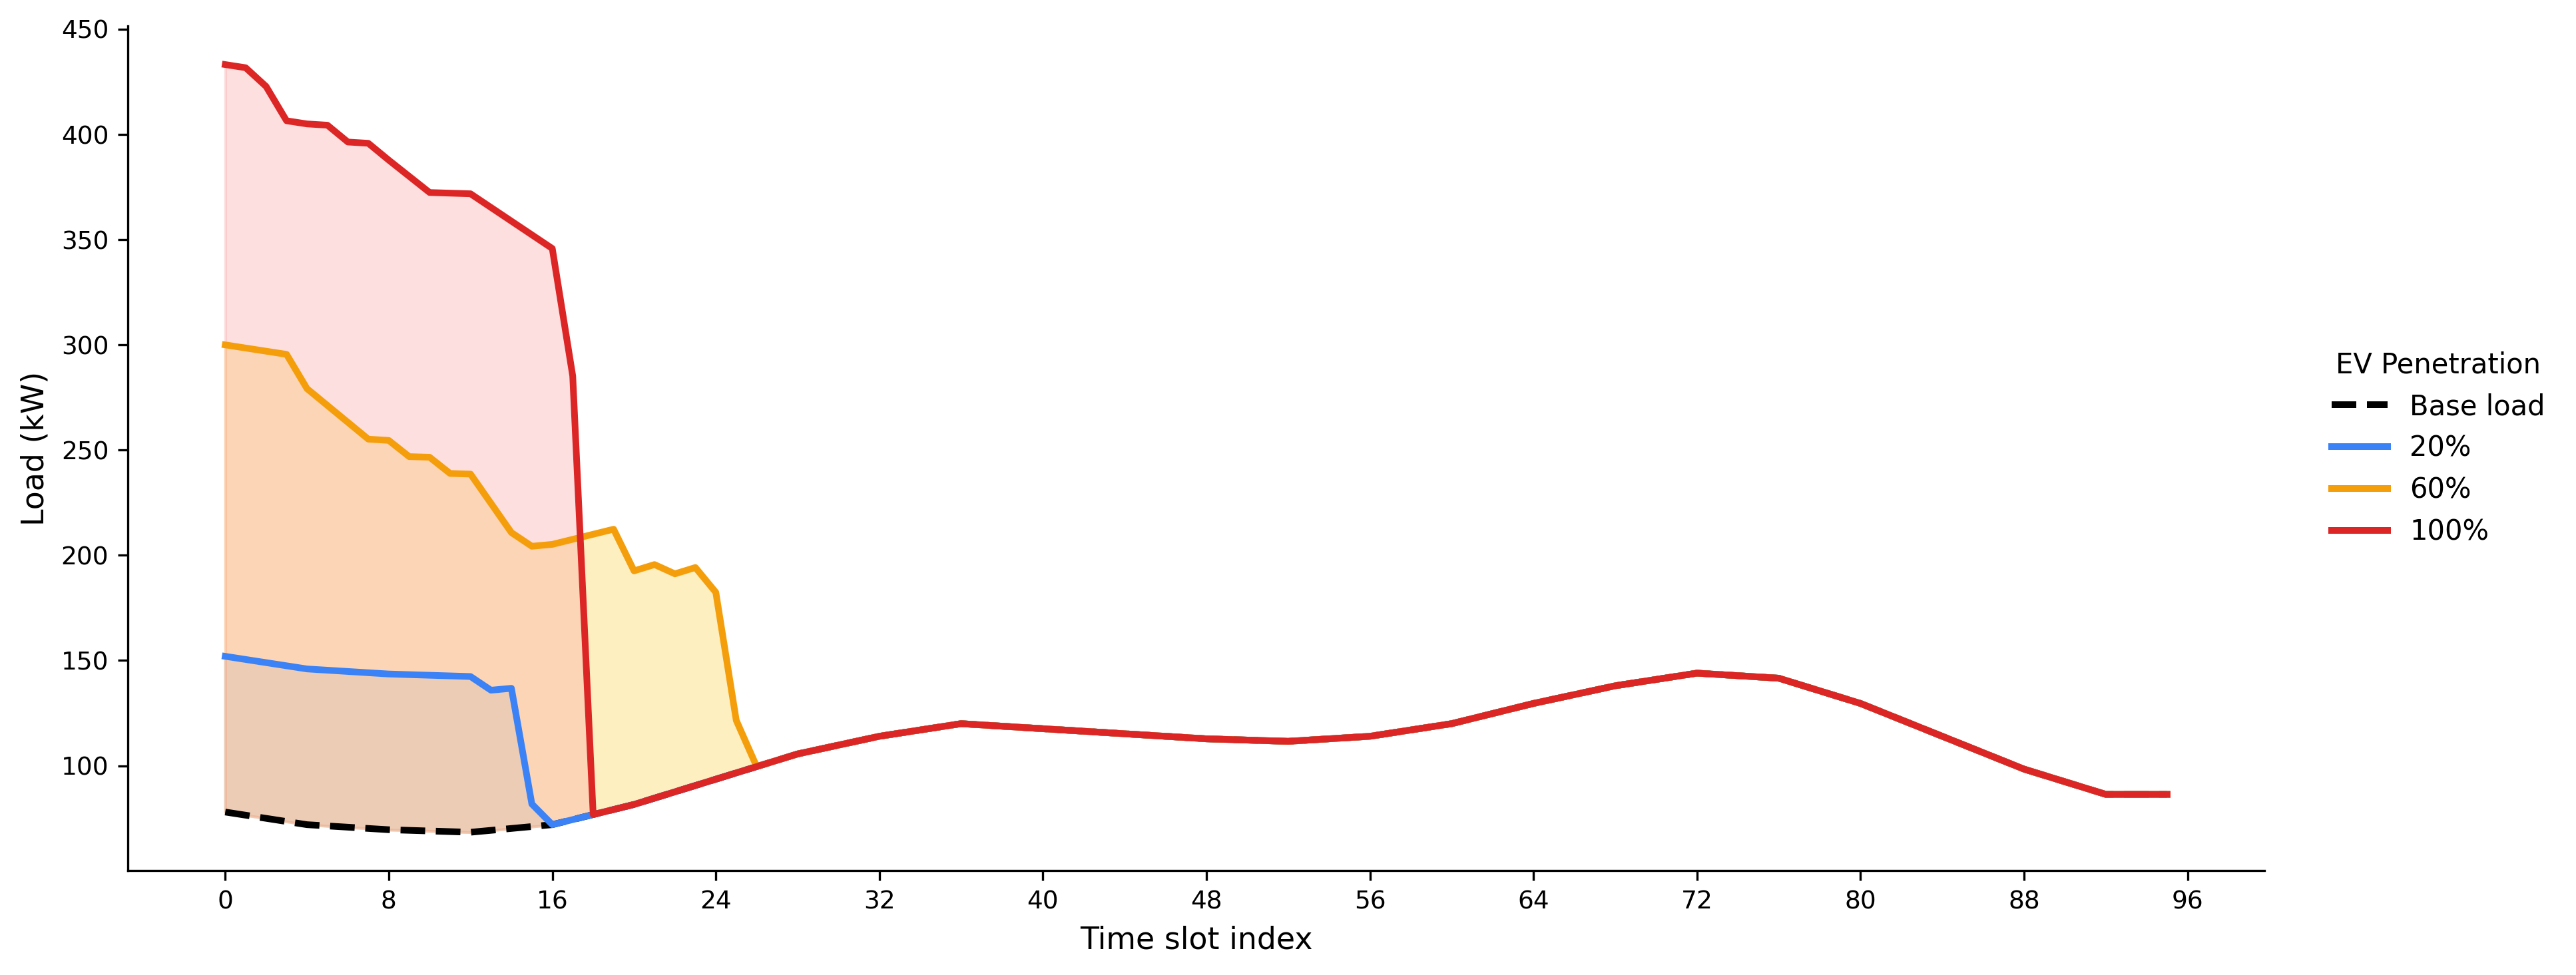

STEP 13 completed successfully.
Figure saved at: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/community_tou_load_styled.png


In [89]:
# ======================================================
# STEP 13: TOU load profiles (single plot with penetration)
# ======================================================

import matplotlib.pyplot as plt
import numpy as np
import os

TOU_LOAD_FIG = os.path.join(RESULTS_FOLDER, "community_tou_load_styled.png")

fig, ax = plt.subplots(figsize=(13, 5), dpi=300)

x = np.arange(N_SLOTS)
# Retrieve the original community baseline from Step 8
base_load_kw = np.asarray(
    community_inputs[0.20]["BaseLoad_kW"],
    dtype=float
).copy()

# Verify the number of time slots
assert len(base_load_kw) == N_SLOTS, (
    "Expected 96 time slots for the community baseline."
)

# Check that the same baseline is used at all penetration levels
for pen, info in community_inputs.items():
    assert np.allclose(
        base_load_kw,
        info["BaseLoad_kW"]
    ), f"Baseline mismatch at {pen:.0%} penetration."

# ------------------------------------------------------
# Base load
# ------------------------------------------------------
ax.plot(
    x,
    base_load_kw,
    linewidth=2.4,
    color="black",
    linestyle="--",
    label="Base load"
)

# ------------------------------------------------------
# Colors for lines and fills
# ------------------------------------------------------
pen_styles = {
    0.20: {"line": "#3B82F6", "fill": "#93C5FD"},
    0.60: {"line": "#F59E0B", "fill": "#FCD34D"},
    1.00: {"line": "#DC2626", "fill": "#FCA5A5"}
}

# ------------------------------------------------------
# Plot TOU loads with soft fill
# ------------------------------------------------------
for pen in [0.20, 0.60, 1.00]:
    if pen not in tou_profiles_by_pen:
        continue

    tou_ev_kw = tou_profiles_by_pen[pen]
    total_load_kw = base_load_kw + tou_ev_kw

    ax.fill_between(
        x,
        base_load_kw,
        total_load_kw,
        color=pen_styles[pen]["fill"],
        alpha=0.35
    )

    ax.plot(
        x,
        total_load_kw,
        linewidth=2.4,
        color=pen_styles[pen]["line"],
        label=f"{int(pen*100)}%"
    )

# ------------------------------------------------------
# Styling
# ------------------------------------------------------
ax.set_xlabel("Time slot index", fontsize=11)
ax.set_ylabel("Load (kW)", fontsize=11)

tick_positions = np.arange(0, 97, 8)
ax.set_xticks(tick_positions)
ax.set_xticklabels([str(i) for i in tick_positions], fontsize=9)

ax.tick_params(axis="y", labelsize=9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(False)

ax.legend(
    title="EV Penetration",
    frameon=False,
    fontsize=10,
    title_fontsize=10,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5)
)

plt.tight_layout()
plt.savefig(TOU_LOAD_FIG, dpi=300, bbox_inches="tight")
plt.show()

print("STEP 13 completed successfully.")
print("Figure saved at:", TOU_LOAD_FIG)

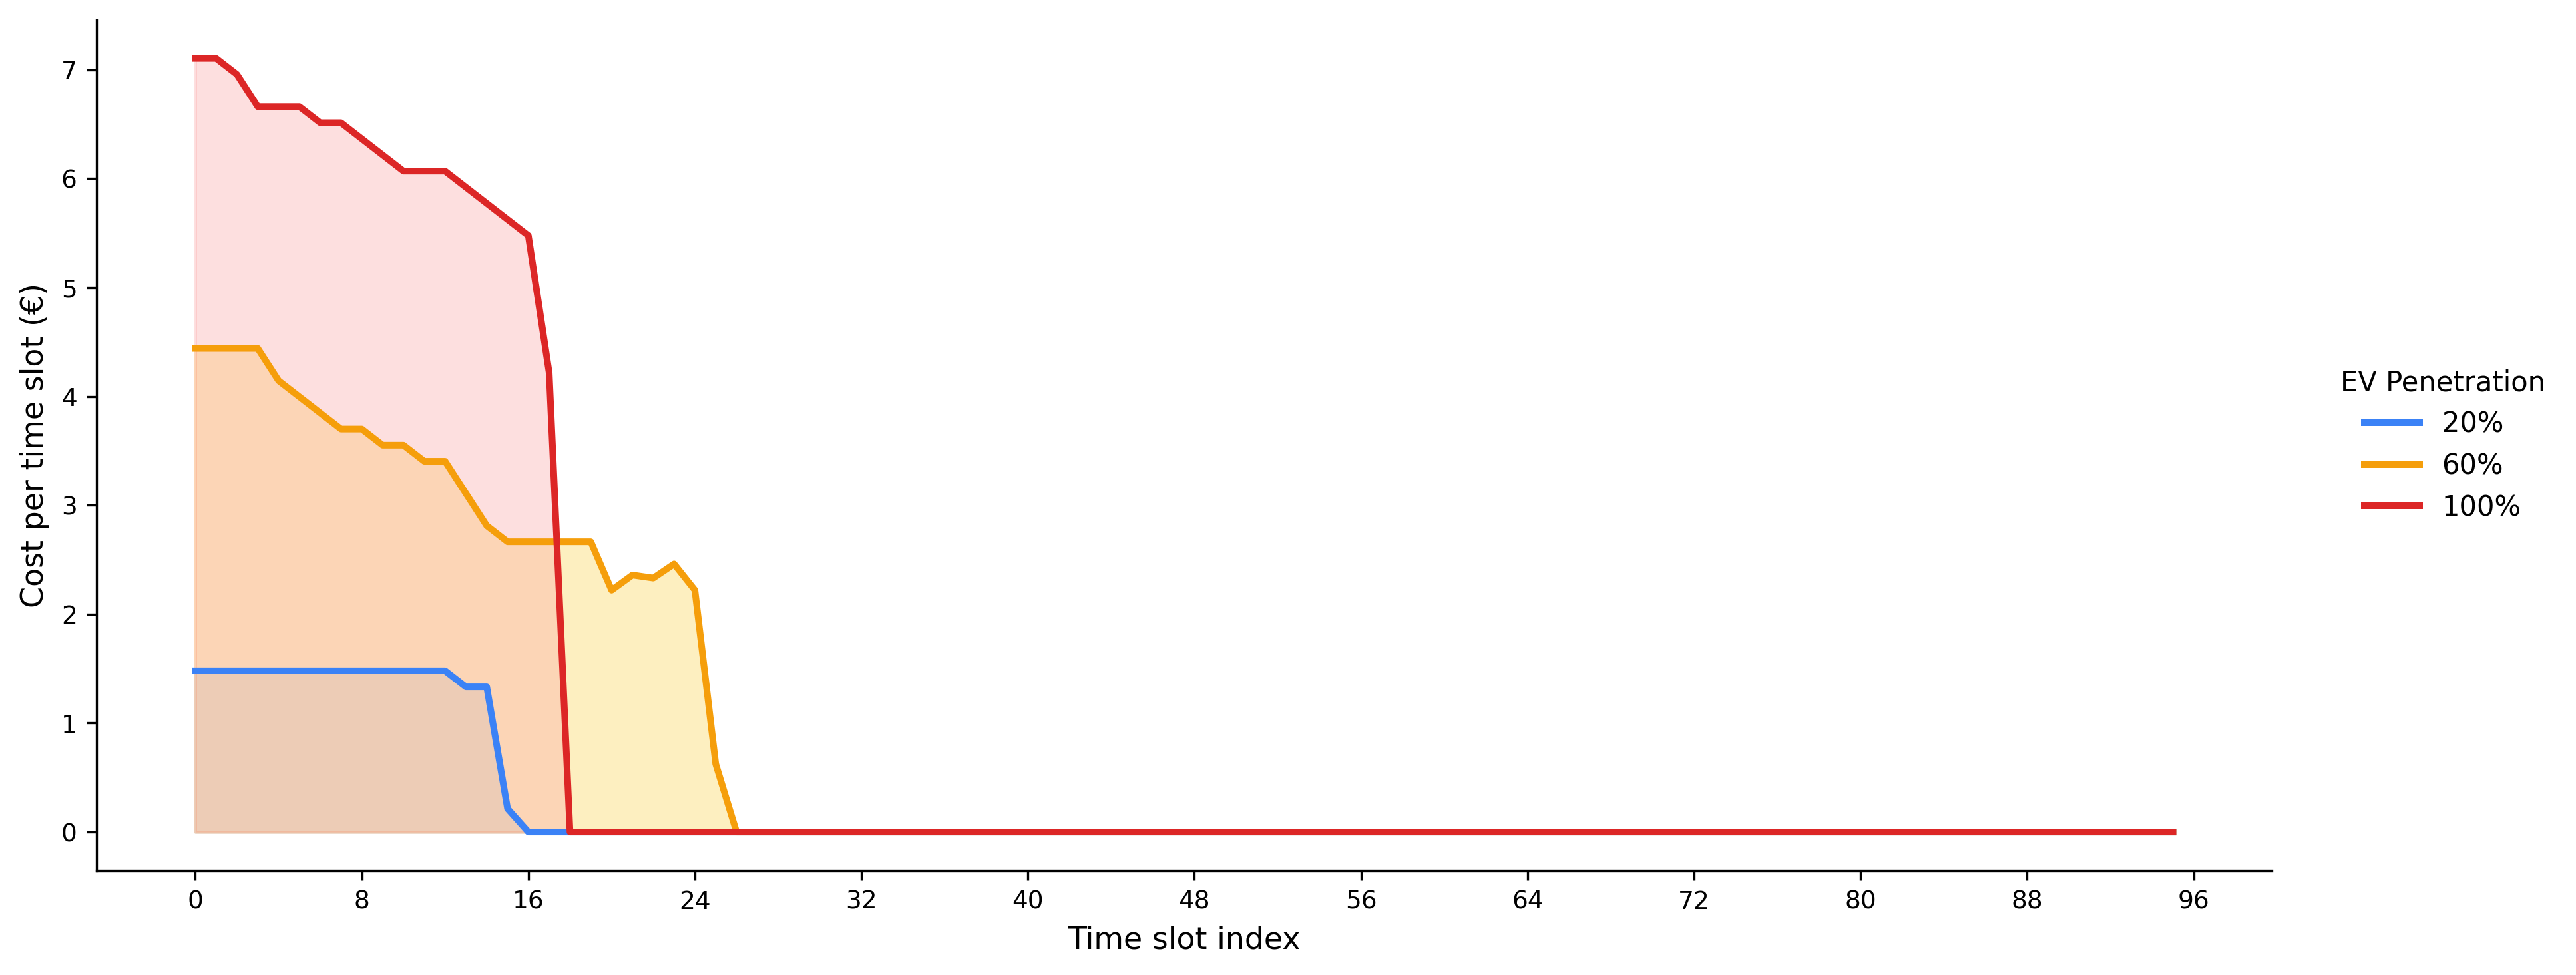

STEP 14 completed successfully.
Figure saved at: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/community_tou_cost_styled.png


In [90]:
# ======================================================
# STEP 14: TOU charging cost profiles (single plot with penetration)
# ======================================================

import matplotlib.pyplot as plt
import numpy as np
import os

TOU_COST_FIG = os.path.join(RESULTS_FOLDER, "community_tou_cost_styled.png")

fig, ax = plt.subplots(figsize=(13, 5), dpi=300)

x = np.arange(N_SLOTS)
# Retrieve the original real-time electricity prices from Step 8
rt_price = np.asarray(
    community_inputs[0.20]["RT_Price"],
    dtype=float
).copy()

# Verify the number of time slots
assert len(rt_price) == N_SLOTS, (
    "Expected 96 time slots for real-time prices."
)

# Verify identical prices across penetration levels
for pen, info in community_inputs.items():
    assert np.allclose(
        rt_price,
        info["RT_Price"]
    ), f"Real-time price mismatch at {pen:.0%} penetration."

# ------------------------------------------------------
# Colors for lines and fills
# ------------------------------------------------------
pen_styles = {
    0.20: {"line": "#3B82F6", "fill": "#93C5FD"},
    0.60: {"line": "#F59E0B", "fill": "#FCD34D"},
    1.00: {"line": "#DC2626", "fill": "#FCA5A5"}
}

# ------------------------------------------------------
# Plot TOU slot-wise cost for each penetration
# slot cost = EV load × real-time price × dt
# ------------------------------------------------------
for pen in [0.20, 0.60, 1.00]:
    if pen not in tou_profiles_by_pen:
        continue

    tou_ev_kw = tou_profiles_by_pen[pen]
    slot_cost = tou_ev_kw * rt_price * DT_HOURS

    ax.fill_between(
        x,
        0,
        slot_cost,
        color=pen_styles[pen]["fill"],
        alpha=0.35
    )

    ax.plot(
        x,
        slot_cost,
        linewidth=2.4,
        color=pen_styles[pen]["line"],
        label=f"{int(pen*100)}%"
    )

# ------------------------------------------------------
# Styling
# ------------------------------------------------------
ax.set_xlabel("Time slot index", fontsize=11)
ax.set_ylabel("Cost per time slot (€)", fontsize=11)

tick_positions = np.arange(0, 97, 8)
ax.set_xticks(tick_positions)
ax.set_xticklabels([str(i) for i in tick_positions], fontsize=9)

ax.tick_params(axis="y", labelsize=9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(False)

ax.legend(
    title="EV Penetration",
    frameon=False,
    fontsize=10,
    title_fontsize=10,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5)
)

plt.tight_layout()
plt.savefig(TOU_COST_FIG, dpi=300, bbox_inches="tight")
plt.show()

print("STEP 14 completed successfully.")
print("Figure saved at:", TOU_COST_FIG)

In [91]:
# ======================================================
# STEP 15: Community-level SCM (cost minimization)
# ======================================================

import numpy as np
import pandas as pd
import os
from scipy.optimize import linprog

def run_scm_schedule(total_required_energy, available_power_kw, rt_price, dt_hours=DT_HOURS, eta=ETA):
    """
    SCM:
    Minimize charging cost under real-time prices
    subject to charging power limits and energy requirement.
    """
    c = rt_price * dt_hours

    bounds = [(0, available_power_kw[t]) for t in range(len(available_power_kw))]

    A_ub = np.array([-(eta * dt_hours) * np.ones(len(available_power_kw))])
    b_ub = np.array([-total_required_energy])

    result = linprog(
        c=c,
        A_ub=A_ub,
        b_ub=b_ub,
        bounds=bounds,
        method="highs"
    )

    if not result.success:
        raise RuntimeError("SCM failed: " + result.message)

    return result.x

# ------------------------------------------------------
# Run SCM for each penetration level
# ------------------------------------------------------
scm_profiles_by_pen = {}
scm_rows = []

for pen, info in community_inputs.items():
    total_required_energy = info["TotalRequiredEnergy_kWh"]
    available_power_kw = info["AvailablePower_kW"]
    base_load_kw = info["BaseLoad_kW"]
    rt_price = info["RT_Price"]

    if not info["Feasible"]:
        print(f"Skipping SCM for {int(pen*100)}% penetration (infeasible).")
        continue

    ev_kw = run_scm_schedule(total_required_energy, available_power_kw, rt_price)

    total_kw = base_load_kw + ev_kw
    delivered_energy = np.sum(ev_kw * DT_HOURS * ETA)
    charging_cost = np.sum(ev_kw * rt_price * DT_HOURS)

    scm_profiles_by_pen[pen] = ev_kw

    scm_rows.append({
        "Penetration": pen,
        "Method": "SCM",
        "NumEVs": info["NumEVs"],
        "RequiredEnergy_kWh": total_required_energy,
        "DeliveredEnergy_kWh": delivered_energy,
        "ChargingCost": charging_cost,
        "PeakTotalLoad_kW": np.max(total_kw),
        "Completed": delivered_energy + 1e-6 >= total_required_energy
    })

scm_results_df = pd.DataFrame(scm_rows)

if len(scm_results_df) > 0:
    scm_results_df = scm_results_df.round({
        "RequiredEnergy_kWh": 3,
        "DeliveredEnergy_kWh": 3,
        "ChargingCost": 3,
        "PeakTotalLoad_kW": 3
    })

# ------------------------------------------------------
# Save results
# ------------------------------------------------------
scm_results_file = os.path.join(RESULTS_FOLDER, "community_scm_results.csv")
scm_results_df.to_csv(scm_results_file, index=False)

print("STEP 15 completed successfully.")
print("Saved SCM results to:", scm_results_file)
scm_results_df

STEP 15 completed successfully.
Saved SCM results to: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/community_scm_results.csv


,Penetration,Method,NumEVs,RequiredEnergy_kWh,DeliveredEnergy_kWh,ChargingCost,PeakTotalLoad_kW,Completed
0,0.2,SCM,10,262.656,262.656,20.453,166.4,True
1,0.6,SCM,30,963.769,963.769,76.183,308.4,True
2,1.0,SCM,50,1329.524,1329.524,103.949,455.0,True


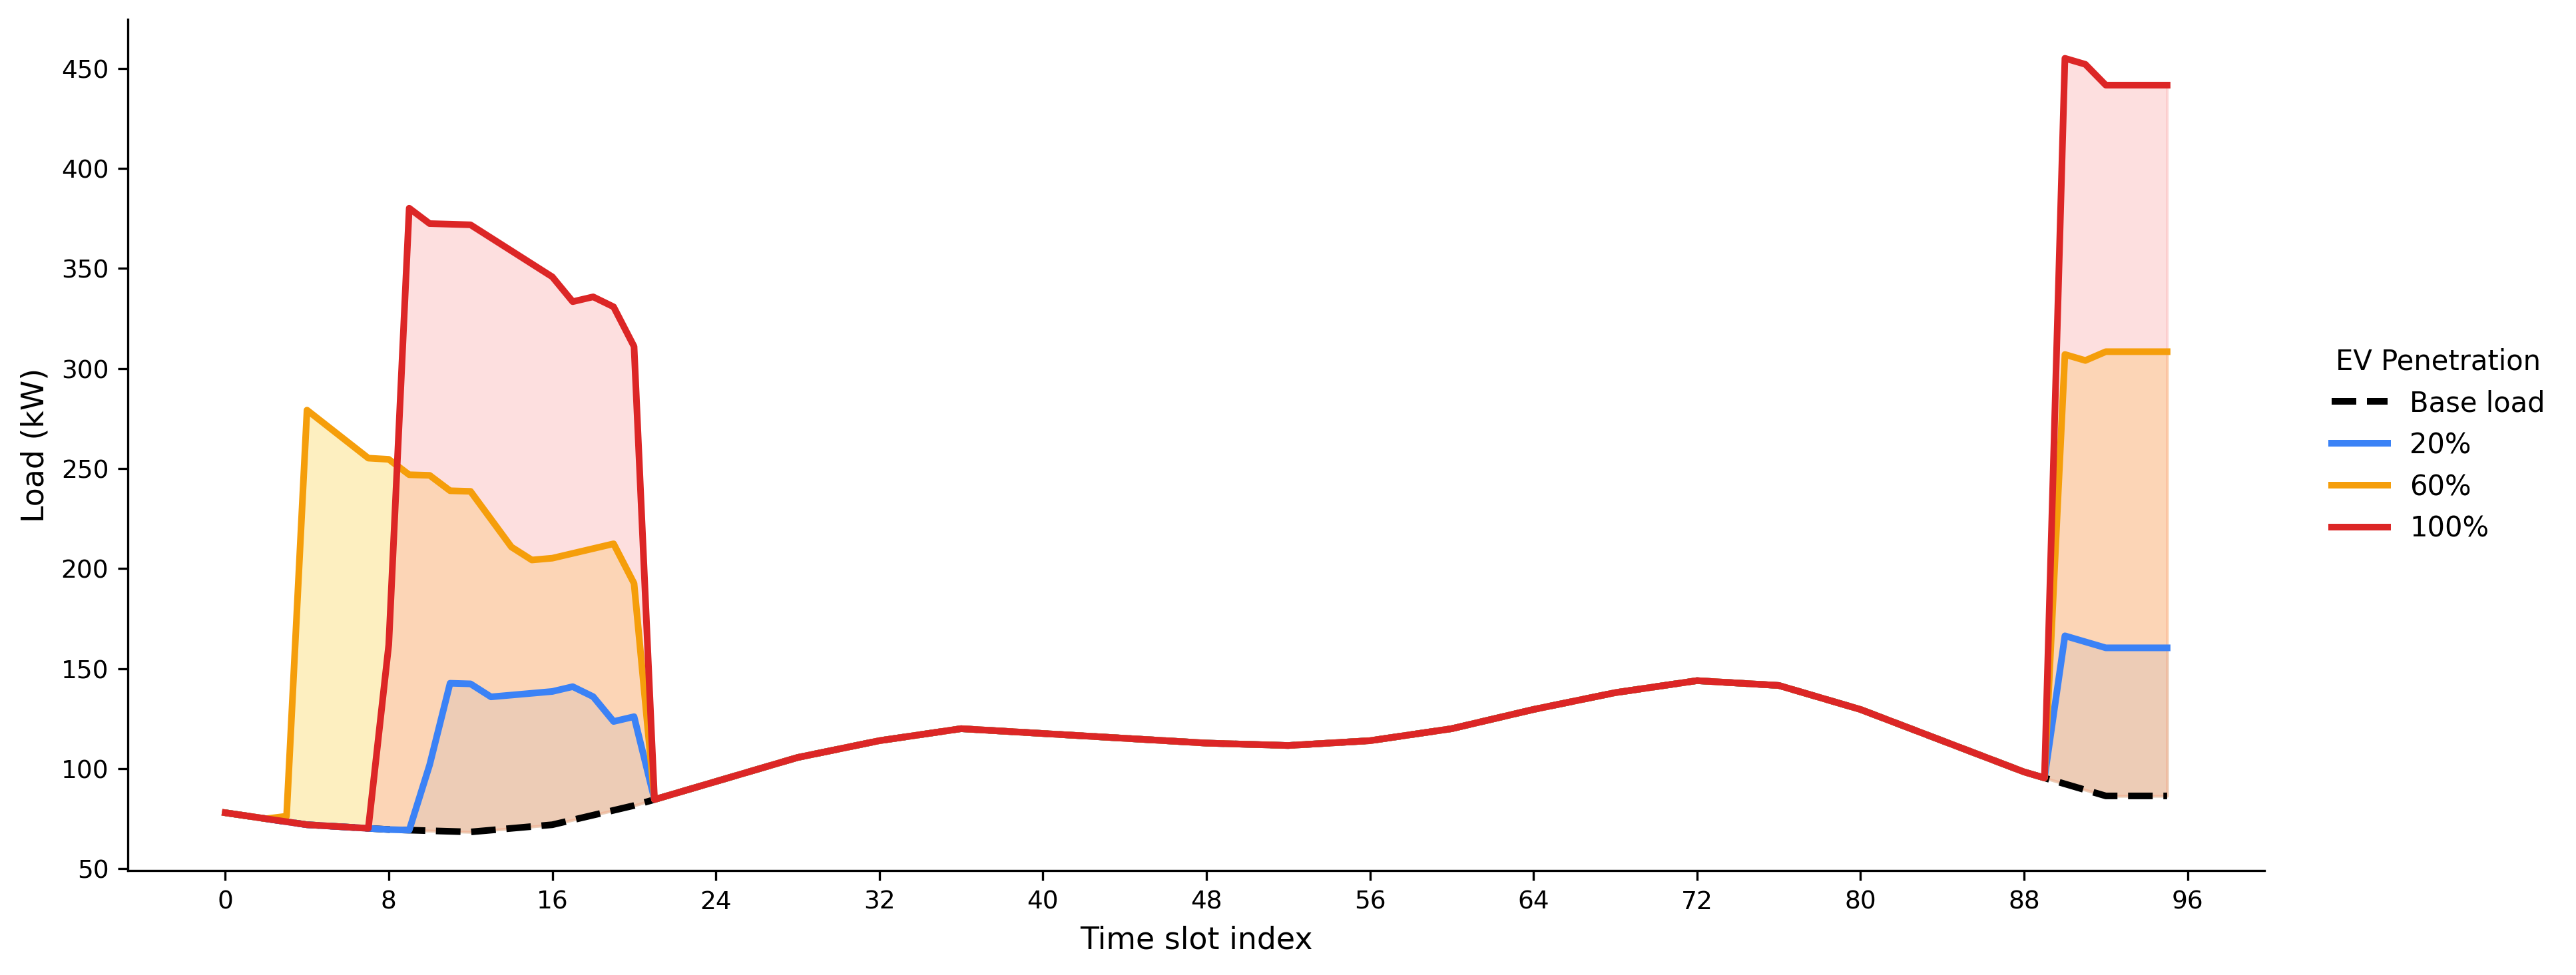

STEP 16 completed successfully.
Figure saved at: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/community_scm_load_styled.png


In [92]:
# ======================================================
# STEP 16: SCM load profiles (single plot with penetration)
# ======================================================

import matplotlib.pyplot as plt
import numpy as np
import os

SCM_LOAD_FIG = os.path.join(RESULTS_FOLDER, "community_scm_load_styled.png")

fig, ax = plt.subplots(figsize=(13, 5), dpi=300)

x = np.arange(N_SLOTS)
# Retrieve the original community baseline from Step 8
base_load_kw = np.asarray(
    community_inputs[0.20]["BaseLoad_kW"],
    dtype=float
).copy()

# Verify the baseline contains 96 time slots
assert len(base_load_kw) == N_SLOTS, (
    "Expected 96 time slots for community baseline."
)

# Verify the baseline is consistent across penetration levels
for pen, info in community_inputs.items():
    assert np.allclose(
        base_load_kw,
        info["BaseLoad_kW"]
    ), f"Baseline mismatch at {pen:.0%} penetration."

# ------------------------------------------------------
# Base load
# ------------------------------------------------------
ax.plot(
    x,
    base_load_kw,
    linewidth=2.4,
    color="black",
    linestyle="--",
    label="Base load"
)

# ------------------------------------------------------
# Colors for lines and fills
# ------------------------------------------------------
pen_styles = {
    0.20: {"line": "#3B82F6", "fill": "#93C5FD"},
    0.60: {"line": "#F59E0B", "fill": "#FCD34D"},
    1.00: {"line": "#DC2626", "fill": "#FCA5A5"}
}

# ------------------------------------------------------
# Plot SCM loads with soft fill
# ------------------------------------------------------
for pen in [0.20, 0.60, 1.00]:
    if pen not in scm_profiles_by_pen:
        continue

    scm_ev_kw = scm_profiles_by_pen[pen]
    total_load_kw = base_load_kw + scm_ev_kw

    ax.fill_between(
        x,
        base_load_kw,
        total_load_kw,
        color=pen_styles[pen]["fill"],
        alpha=0.35
    )

    ax.plot(
        x,
        total_load_kw,
        linewidth=2.4,
        color=pen_styles[pen]["line"],
        label=f"{int(pen*100)}%"
    )

# ------------------------------------------------------
# Styling
# ------------------------------------------------------
ax.set_xlabel("Time slot index", fontsize=11)
ax.set_ylabel("Load (kW)", fontsize=11)

tick_positions = np.arange(0, 97, 8)
ax.set_xticks(tick_positions)
ax.set_xticklabels([str(i) for i in tick_positions], fontsize=9)

ax.tick_params(axis="y", labelsize=9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(False)

ax.legend(
    title="EV Penetration",
    frameon=False,
    fontsize=10,
    title_fontsize=10,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5)
)

plt.tight_layout()
plt.savefig(SCM_LOAD_FIG, dpi=300, bbox_inches="tight")
plt.show()

print("STEP 16 completed successfully.")
print("Figure saved at:", SCM_LOAD_FIG)

In [93]:
# ======================================================
# VERIFY COMMUNITY PROFILES BEFORE STEP 18
# This cell does not replace or modify the shared df.
# ======================================================
required_profile_columns = {"community_load_kw", "rt_price", "tou_price"}
assert len(df) == N_SLOTS, "Expected 96 time slots in the original community profile."
assert required_profile_columns.issubset(df.columns), "Missing original community profile columns."
for column, key in [("community_load_kw", "BaseLoad_kW"),
                    ("rt_price", "RT_Price"),
                    ("tou_price", "TOU_Price")]:
    assert np.allclose(df[column].to_numpy(), community_inputs[0.20][key]), (
        f"Community profile mismatch: {column}"
    )
print("Original 96-slot community profiles verified. No data changed.")


Original 96-slot community profiles verified. No data changed.


In [94]:
# ======================================================
# STEP 18: Community-level SPM (peak minimization)
# ======================================================

import numpy as np
import pandas as pd
import os
from scipy.optimize import linprog

def run_spm_schedule(total_required_energy, available_power_kw, base_load_kw, dt_hours=DT_HOURS, eta=ETA):
    """
    SPM:
    Minimize the peak total community load.
    Decision variables:
      - charging power at each slot
      - one extra variable for the peak load cap
    """
    n = len(available_power_kw)

    # Objective: minimize the last variable (peak cap)
    c = np.zeros(n + 1)
    c[-1] = 1.0

    # Bounds for charging power + peak cap
    bounds = [(0, available_power_kw[t]) for t in range(n)]
    bounds.append((0, None))  # peak cap

    A_ub = []
    b_ub = []

    # Constraint: base_load[t] + ev_kw[t] <= peak_cap
    for t in range(n):
        row = np.zeros(n + 1)
        row[t] = 1.0
        row[-1] = -1.0
        A_ub.append(row)
        b_ub.append(-base_load_kw[t])

    # Energy delivery constraint:
    # sum(eta * ev_kw[t] * dt_hours) >= total_required_energy
    row = np.zeros(n + 1)
    row[:n] = -(eta * dt_hours)
    A_ub.append(row)
    b_ub.append(-total_required_energy)

    result = linprog(
        c=c,
        A_ub=np.array(A_ub),
        b_ub=np.array(b_ub),
        bounds=bounds,
        method="highs"
    )

    if not result.success:
        raise RuntimeError("SPM failed: " + result.message)

    return result.x[:n]

# ------------------------------------------------------
# Run SPM for each penetration level
# ------------------------------------------------------
spm_profiles_by_pen = {}
spm_rows = []

for pen, info in community_inputs.items():
    total_required_energy = info["TotalRequiredEnergy_kWh"]
    available_power_kw = info["AvailablePower_kW"]
    base_load_kw = info["BaseLoad_kW"]
    rt_price = info["RT_Price"]

    if not info["Feasible"]:
        print(f"Skipping SPM for {int(pen*100)}% penetration (infeasible).")
        continue

    ev_kw = run_spm_schedule(total_required_energy, available_power_kw, base_load_kw)

    total_kw = base_load_kw + ev_kw
    delivered_energy = np.sum(ev_kw * DT_HOURS * ETA)
    charging_cost = np.sum(ev_kw * rt_price * DT_HOURS)

    spm_profiles_by_pen[pen] = ev_kw

    spm_rows.append({
        "Penetration": pen,
        "Method": "SPM",
        "NumEVs": info["NumEVs"],
        "RequiredEnergy_kWh": total_required_energy,
        "DeliveredEnergy_kWh": delivered_energy,
        "ChargingCost": charging_cost,
        "PeakTotalLoad_kW": np.max(total_kw),
        "Completed": delivered_energy + 1e-6 >= total_required_energy
    })

spm_results_df = pd.DataFrame(spm_rows)

if len(spm_results_df) > 0:
    spm_results_df = spm_results_df.round({
        "RequiredEnergy_kWh": 3,
        "DeliveredEnergy_kWh": 3,
        "ChargingCost": 3,
        "PeakTotalLoad_kW": 3
    })

# ------------------------------------------------------
# Save results
# ------------------------------------------------------
spm_results_file = os.path.join(RESULTS_FOLDER, "community_spm_results.csv")
spm_results_df.to_csv(spm_results_file, index=False)

print("STEP 18 completed successfully.")
print("Saved SPM results to:", spm_results_file)
spm_results_df

STEP 18 completed successfully.
Saved SPM results to: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/community_spm_results.csv


,Penetration,Method,NumEVs,RequiredEnergy_kWh,DeliveredEnergy_kWh,ChargingCost,PeakTotalLoad_kW,Completed
0,0.2,SPM,10,262.656,328.653,30.007,144.000,True
1,0.6,SPM,30,963.769,963.769,88.169,157.566,True
2,1.0,SPM,50,1329.524,1329.524,123.592,175.939,True


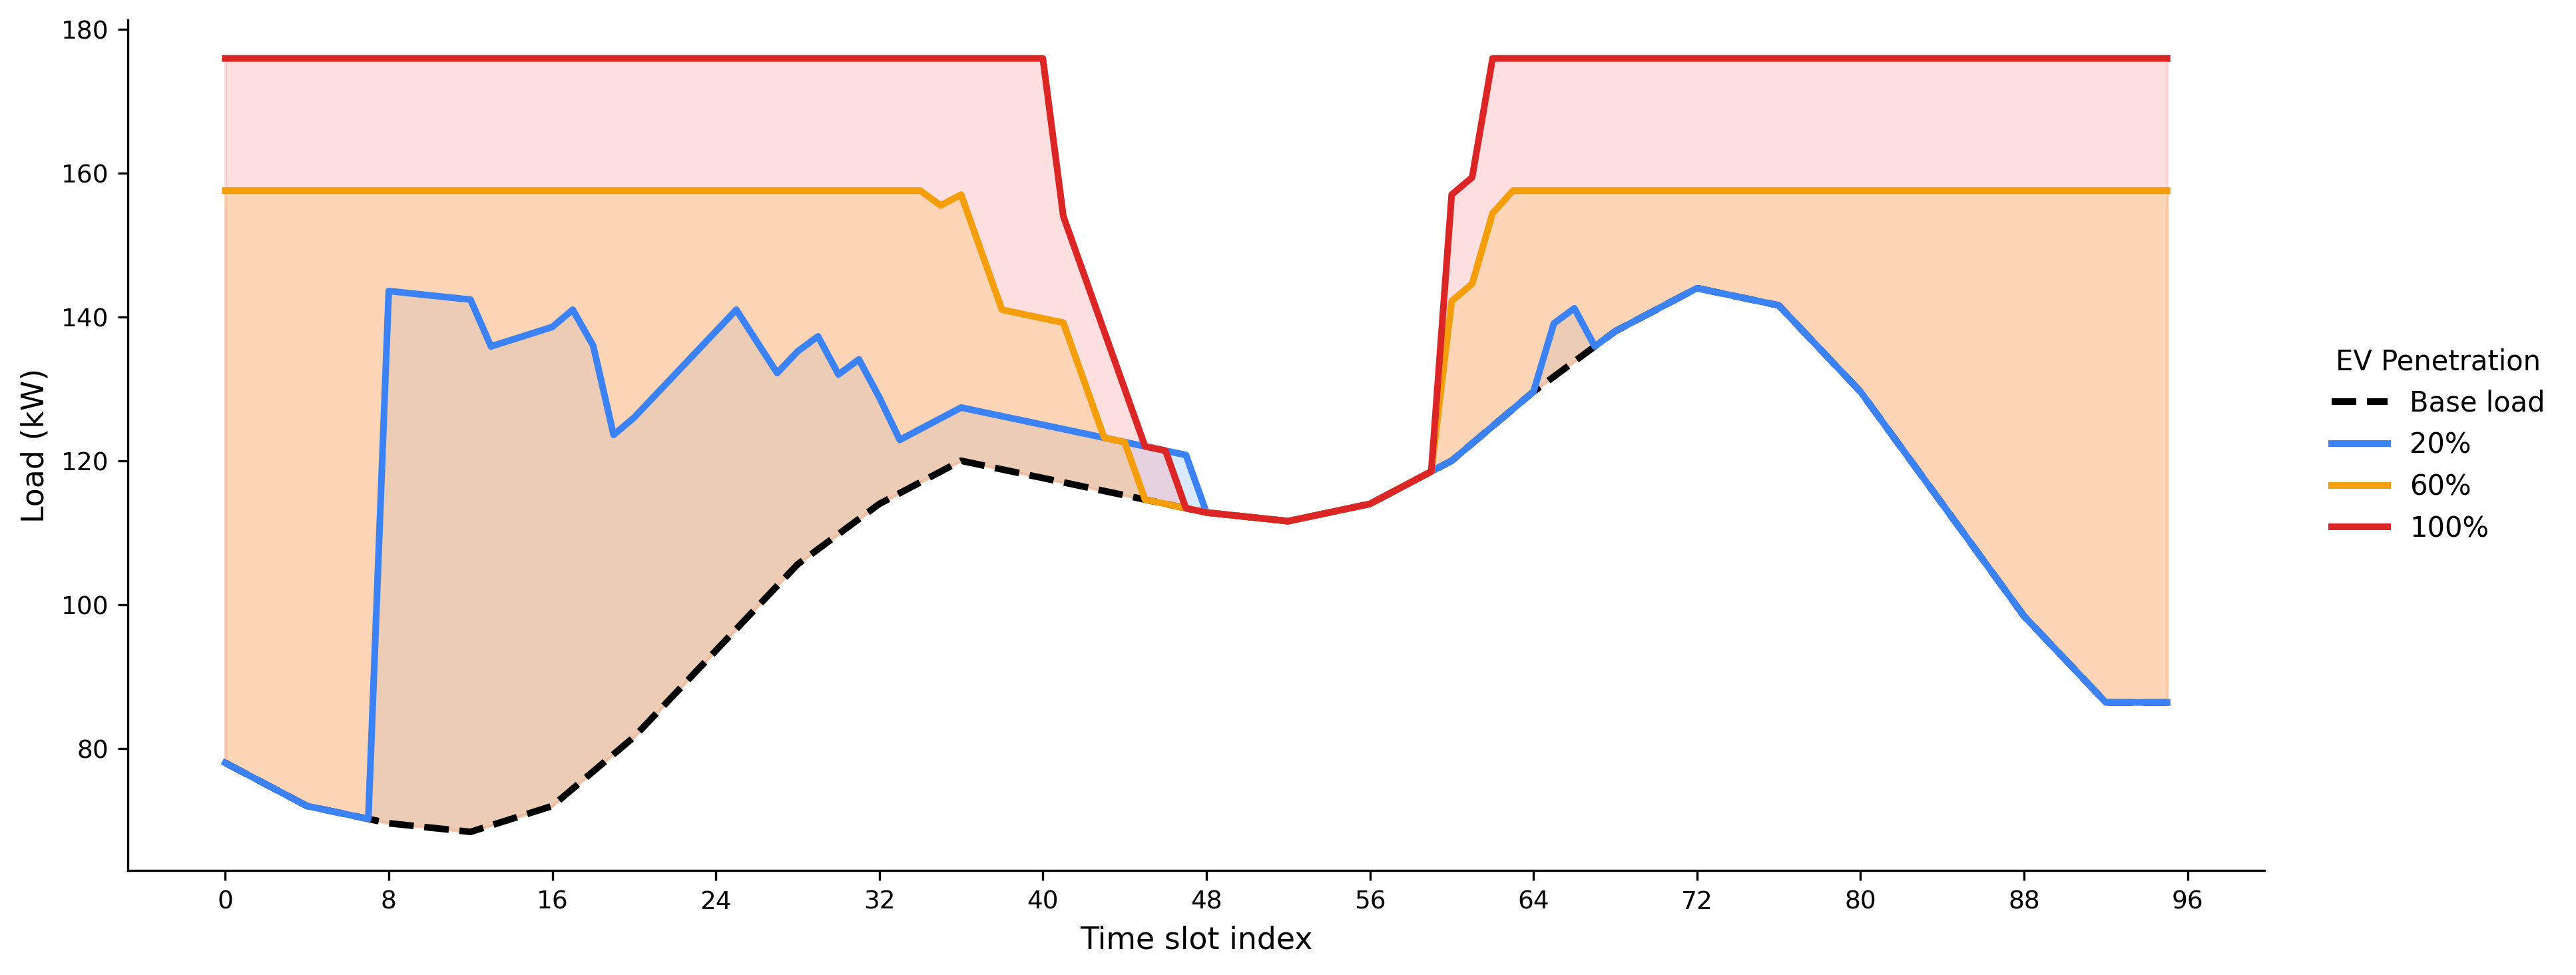

STEP 19 completed successfully.
Figure saved at: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/community_spm_load_styled.png


In [95]:
# ======================================================
# STEP 19: SPM load profiles (single plot with penetration)
# ======================================================

import matplotlib.pyplot as plt
import numpy as np
import os

SPM_LOAD_FIG = os.path.join(RESULTS_FOLDER, "community_spm_load_styled.png")

fig, ax = plt.subplots(figsize=(13, 5), dpi=300)

x = np.arange(N_SLOTS)
base_load_kw = df["community_load_kw"].values

# ------------------------------------------------------
# Base load
# ------------------------------------------------------
ax.plot(
    x,
    base_load_kw,
    linewidth=2.4,
    color="black",
    linestyle="--",
    label="Base load"
)

# ------------------------------------------------------
# Colors for lines and fills
# ------------------------------------------------------
pen_styles = {
    0.20: {"line": "#3B82F6", "fill": "#93C5FD"},
    0.60: {"line": "#F59E0B", "fill": "#FCD34D"},
    1.00: {"line": "#DC2626", "fill": "#FCA5A5"}
}

# ------------------------------------------------------
# Plot SPM loads with soft fill
# ------------------------------------------------------
for pen in [0.20, 0.60, 1.00]:
    if pen not in spm_profiles_by_pen:
        continue

    spm_ev_kw = spm_profiles_by_pen[pen]
    total_load_kw = base_load_kw + spm_ev_kw

    ax.fill_between(
        x,
        base_load_kw,
        total_load_kw,
        color=pen_styles[pen]["fill"],
        alpha=0.35
    )

    ax.plot(
        x,
        total_load_kw,
        linewidth=2.4,
        color=pen_styles[pen]["line"],
        label=f"{int(pen*100)}%"
    )

# ------------------------------------------------------
# Styling
# ------------------------------------------------------
ax.set_xlabel("Time slot index", fontsize=11)
ax.set_ylabel("Load (kW)", fontsize=11)

tick_positions = np.arange(0, 97, 8)
ax.set_xticks(tick_positions)
ax.set_xticklabels([str(i) for i in tick_positions], fontsize=9)

ax.tick_params(axis="y", labelsize=9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(False)

ax.legend(
    title="EV Penetration",
    frameon=False,
    fontsize=10,
    title_fontsize=10,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5)
)

plt.tight_layout()
plt.savefig(SPM_LOAD_FIG, dpi=300, bbox_inches="tight")
plt.show()

print("STEP 19 completed successfully.")
print("Figure saved at:", SPM_LOAD_FIG)

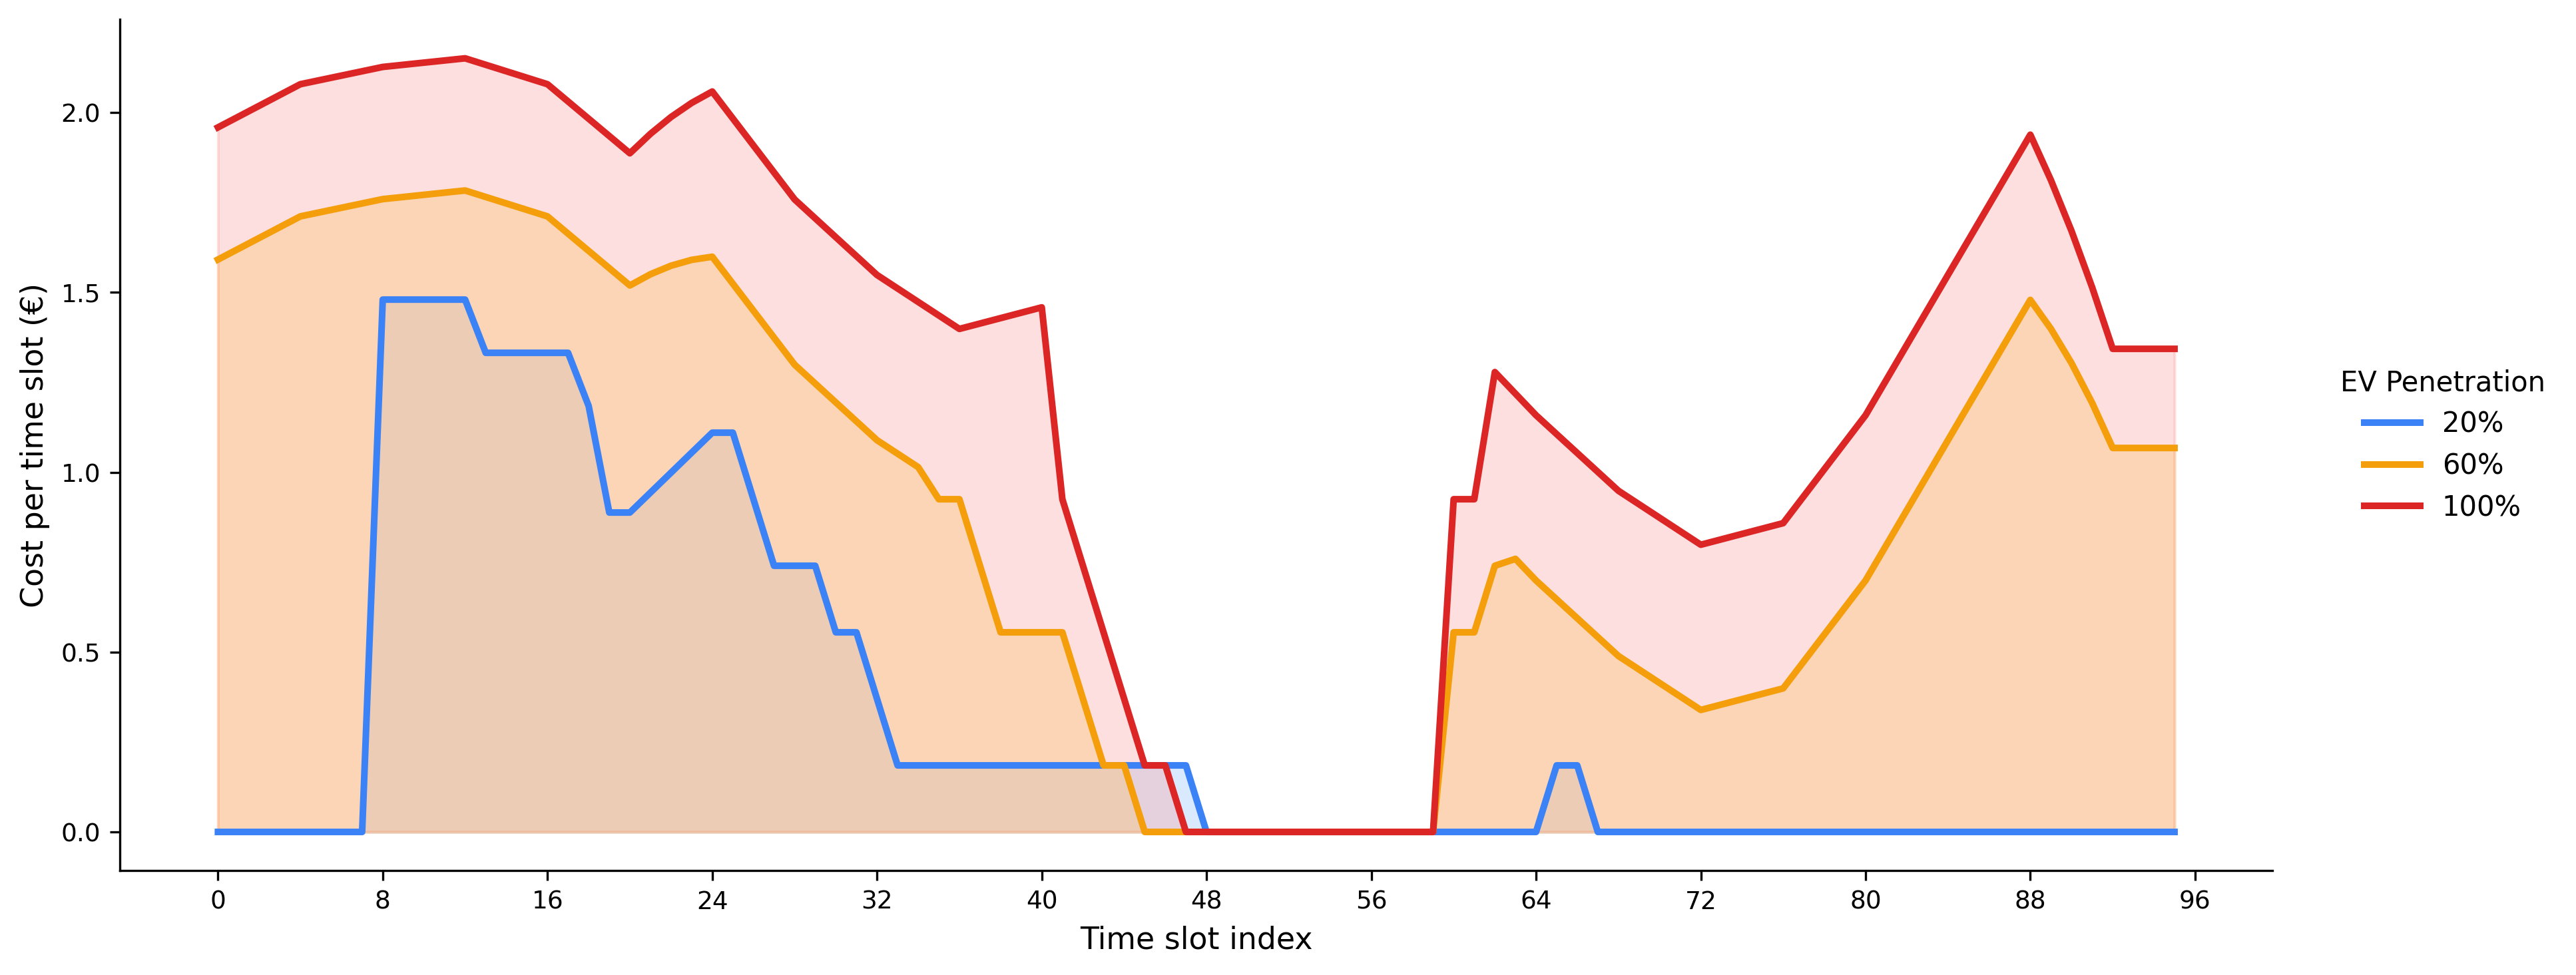

STEP 20 completed successfully.
Figure saved at: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/community_spm_cost_styled.png


In [96]:
# ======================================================
# STEP 20: SPM charging cost profiles (single plot with penetration)
# ======================================================

import matplotlib.pyplot as plt
import numpy as np
import os

SPM_COST_FIG = os.path.join(RESULTS_FOLDER, "community_spm_cost_styled.png")

fig, ax = plt.subplots(figsize=(13, 5), dpi=300)

x = np.arange(N_SLOTS)
rt_price = df["rt_price"].values

# ------------------------------------------------------
# Colors for lines and fills
# ------------------------------------------------------
pen_styles = {
    0.20: {"line": "#3B82F6", "fill": "#93C5FD"},
    0.60: {"line": "#F59E0B", "fill": "#FCD34D"},
    1.00: {"line": "#DC2626", "fill": "#FCA5A5"}
}

# ------------------------------------------------------
# Plot SPM slot-wise cost
# slot cost = EV load × real-time price × dt
# ------------------------------------------------------
for pen in [0.20, 0.60, 1.00]:
    if pen not in spm_profiles_by_pen:
        continue

    spm_ev_kw = spm_profiles_by_pen[pen]
    slot_cost = spm_ev_kw * rt_price * DT_HOURS

    ax.fill_between(
        x,
        0,
        slot_cost,
        color=pen_styles[pen]["fill"],
        alpha=0.35
    )

    ax.plot(
        x,
        slot_cost,
        linewidth=2.4,
        color=pen_styles[pen]["line"],
        label=f"{int(pen*100)}%"
    )

# ------------------------------------------------------
# Styling
# ------------------------------------------------------
ax.set_xlabel("Time slot index", fontsize=11)
ax.set_ylabel("Cost per time slot (€)", fontsize=11)

tick_positions = np.arange(0, 97, 8)
ax.set_xticks(tick_positions)
ax.set_xticklabels([str(i) for i in tick_positions], fontsize=9)

ax.tick_params(axis="y", labelsize=9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(False)

ax.legend(
    title="EV Penetration",
    frameon=False,
    fontsize=10,
    title_fontsize=10,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5)
)

plt.tight_layout()
plt.savefig(SPM_COST_FIG, dpi=300, bbox_inches="tight")
plt.show()

print("STEP 20 completed successfully.")
print("Figure saved at:", SPM_COST_FIG)

In [97]:
# ======================================================
# STEP 21: Community-level MOCHF-IoEVs
# ======================================================

import numpy as np
import pandas as pd
import os

from pymoo.core.problem import Problem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize
from pymoo.termination import get_termination

# ------------------------------------------------------
# Define multi-objective problem
# ------------------------------------------------------
class CommunityMOCHFProblem(Problem):
    def __init__(self, base_load_kw, available_power_kw, rt_price, total_required_energy):
        self.base_load_kw = base_load_kw
        self.available_power_kw = available_power_kw
        self.rt_price = rt_price
        self.total_required_energy = total_required_energy

        xl = np.zeros(len(available_power_kw))
        xu = available_power_kw.copy()

        super().__init__(
            n_var=len(available_power_kw),
            n_obj=2,
            n_constr=1,
            xl=xl,
            xu=xu
        )

    def _evaluate(self, X, out, *args, **kwargs):
        # Objective 1: charging cost
        f1 = np.sum(X * self.rt_price * DT_HOURS, axis=1)

        # Objective 2: peak total load
        total_kw = X + self.base_load_kw[None, :]
        f2 = np.max(total_kw, axis=1)

        # Constraint: delivered energy must meet required energy
        delivered = np.sum(X * DT_HOURS * ETA, axis=1)
        g1 = self.total_required_energy - delivered

        out["F"] = np.column_stack([f1, f2])
        out["G"] = np.column_stack([g1])

# ------------------------------------------------------
# Solve MOCHF-IoEVs and pick a compromise solution
# ------------------------------------------------------
def run_mochf_schedule(base_load_kw, available_power_kw, rt_price, total_required_energy):
    problem = CommunityMOCHFProblem(
        base_load_kw=base_load_kw,
        available_power_kw=available_power_kw,
        rt_price=rt_price,
        total_required_energy=total_required_energy
    )

    algorithm = NSGA2(pop_size=150)
    termination = get_termination("n_gen", 200)

    res = minimize(
        problem,
        algorithm,
        termination,
        seed=42,
        save_history=True,
        verbose=False
    )

    F = res.F
    X = res.X

    # Normalize and choose balanced compromise point
    F_norm = (F - F.min(axis=0)) / (F.max(axis=0) - F.min(axis=0) + 1e-12)
    idx_compromise = np.argmin(np.sum(F_norm, axis=1))

    chosen_profile = X[idx_compromise]

    # Convergence history
    history_best_cost = []
    history_best_peak = []

    for algo in res.history:
        pop_F = algo.pop.get("F")
        history_best_cost.append(np.min(pop_F[:, 0]))
        history_best_peak.append(np.min(pop_F[:, 1]))

    return chosen_profile, F, X, history_best_cost, history_best_peak

# ------------------------------------------------------
# Run MOCHF-IoEVs for each penetration level
# ------------------------------------------------------
mochf_profiles_by_pen = {}
mochf_rows = []
mochf_outputs = {}

for pen, info in community_inputs.items():
    total_required_energy = info["TotalRequiredEnergy_kWh"]
    available_power_kw = info["AvailablePower_kW"]
    base_load_kw = info["BaseLoad_kW"]
    rt_price = info["RT_Price"]

    if not info["Feasible"]:
        print(f"Skipping MOCHF-IoEVs for {int(pen*100)}% penetration (infeasible).")
        continue

    ev_kw, F, X, hist_cost, hist_peak = run_mochf_schedule(
        base_load_kw=base_load_kw,
        available_power_kw=available_power_kw,
        rt_price=rt_price,
        total_required_energy=total_required_energy
    )

    total_kw = base_load_kw + ev_kw
    delivered_energy = np.sum(ev_kw * DT_HOURS * ETA)
    charging_cost = np.sum(ev_kw * rt_price * DT_HOURS)

    mochf_profiles_by_pen[pen] = ev_kw
    mochf_outputs[pen] = {
        "pareto_F": F,
        "pareto_X": X,
        "hist_cost": hist_cost,
        "hist_peak": hist_peak
    }

    mochf_rows.append({
        "Penetration": pen,
        "Method": "MOCHF-IoEVs",
        "NumEVs": info["NumEVs"],
        "RequiredEnergy_kWh": total_required_energy,
        "DeliveredEnergy_kWh": delivered_energy,
        "ChargingCost": charging_cost,
        "PeakTotalLoad_kW": np.max(total_kw),
        "Completed": delivered_energy + 1e-6 >= total_required_energy
    })

mochf_results_df = pd.DataFrame(mochf_rows)

if len(mochf_results_df) > 0:
    mochf_results_df = mochf_results_df.round({
        "RequiredEnergy_kWh": 3,
        "DeliveredEnergy_kWh": 3,
        "ChargingCost": 3,
        "PeakTotalLoad_kW": 3
    })

# ------------------------------------------------------
# Save results
# ------------------------------------------------------
mochf_results_file = os.path.join(RESULTS_FOLDER, "community_mochf_results.csv")
mochf_results_df.to_csv(mochf_results_file, index=False)

print("STEP 21 completed successfully.")
print("Saved MOCHF-IoEVs results to:", mochf_results_file)
mochf_results_df


STEP 21 completed successfully.
Saved MOCHF-IoEVs results to: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/community_mochf_results.csv


,Penetration,Method,NumEVs,RequiredEnergy_kWh,DeliveredEnergy_kWh,ChargingCost,PeakTotalLoad_kW,Completed
0,0.2,MOCHF-IoEVs,10,262.656,262.970,21.816,145.056,True
1,0.6,MOCHF-IoEVs,30,963.769,964.015,83.319,220.535,True
2,1.0,MOCHF-IoEVs,50,1329.524,1329.776,115.294,289.982,True


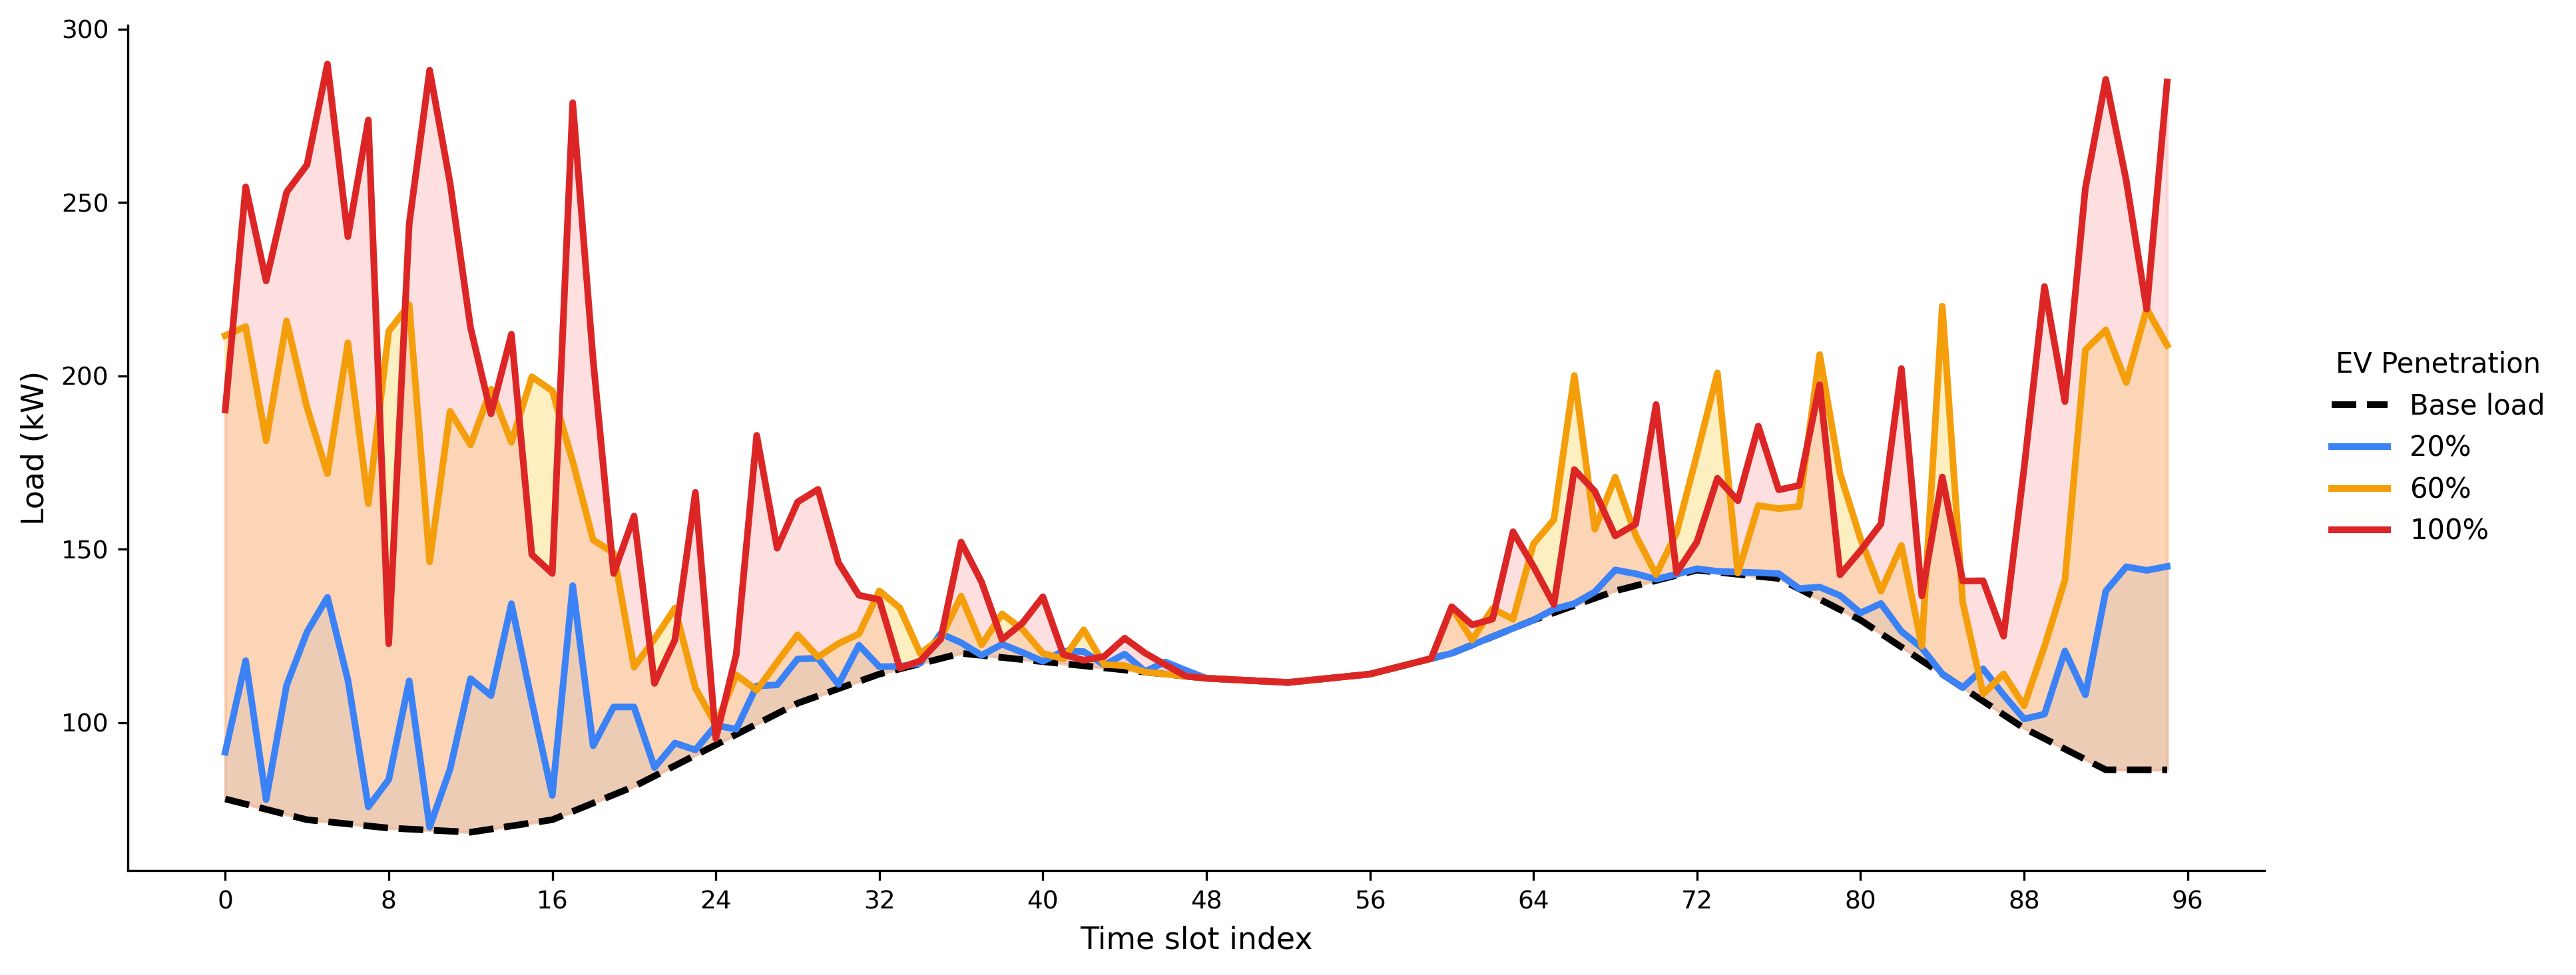

STEP 22 completed successfully.
Figure saved at: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/community_mochf_load_styled.png


In [98]:
# ======================================================
# STEP 22: MOCHF-IoEVs load profiles (single plot with penetration)
# ======================================================

import matplotlib.pyplot as plt
import numpy as np
import os

MOCHF_LOAD_FIG = os.path.join(RESULTS_FOLDER, "community_mochf_load_styled.png")

fig, ax = plt.subplots(figsize=(13, 5), dpi=300)

x = np.arange(N_SLOTS)
base_load_kw = df["community_load_kw"].values

# ------------------------------------------------------
# Base load
# ------------------------------------------------------
ax.plot(
    x,
    base_load_kw,
    linewidth=2.4,
    color="black",
    linestyle="--",
    label="Base load"
)

# ------------------------------------------------------
# Colors for lines and fills
# ------------------------------------------------------
pen_styles = {
    0.20: {"line": "#3B82F6", "fill": "#93C5FD"},
    0.60: {"line": "#F59E0B", "fill": "#FCD34D"},
    1.00: {"line": "#DC2626", "fill": "#FCA5A5"}
}

# ------------------------------------------------------
# Plot MOCHF-IoEVs loads with soft fill
# ------------------------------------------------------
for pen in [0.20, 0.60, 1.00]:
    if pen not in mochf_profiles_by_pen:
        continue

    mochf_ev_kw = mochf_profiles_by_pen[pen]
    total_load_kw = base_load_kw + mochf_ev_kw

    ax.fill_between(
        x,
        base_load_kw,
        total_load_kw,
        color=pen_styles[pen]["fill"],
        alpha=0.35
    )

    ax.plot(
        x,
        total_load_kw,
        linewidth=2.4,
        color=pen_styles[pen]["line"],
        label=f"{int(pen*100)}%"
    )

# ------------------------------------------------------
# Styling
# ------------------------------------------------------
ax.set_xlabel("Time slot index", fontsize=11)
ax.set_ylabel("Load (kW)", fontsize=11)

tick_positions = np.arange(0, 97, 8)
ax.set_xticks(tick_positions)
ax.set_xticklabels([str(i) for i in tick_positions], fontsize=9)

ax.tick_params(axis="y", labelsize=9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(False)

ax.legend(
    title="EV Penetration",
    frameon=False,
    fontsize=10,
    title_fontsize=10,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5)
)

plt.tight_layout()
plt.savefig(MOCHF_LOAD_FIG, dpi=300, bbox_inches="tight")
plt.show()

print("STEP 22 completed successfully.")
print("Figure saved at:", MOCHF_LOAD_FIG)

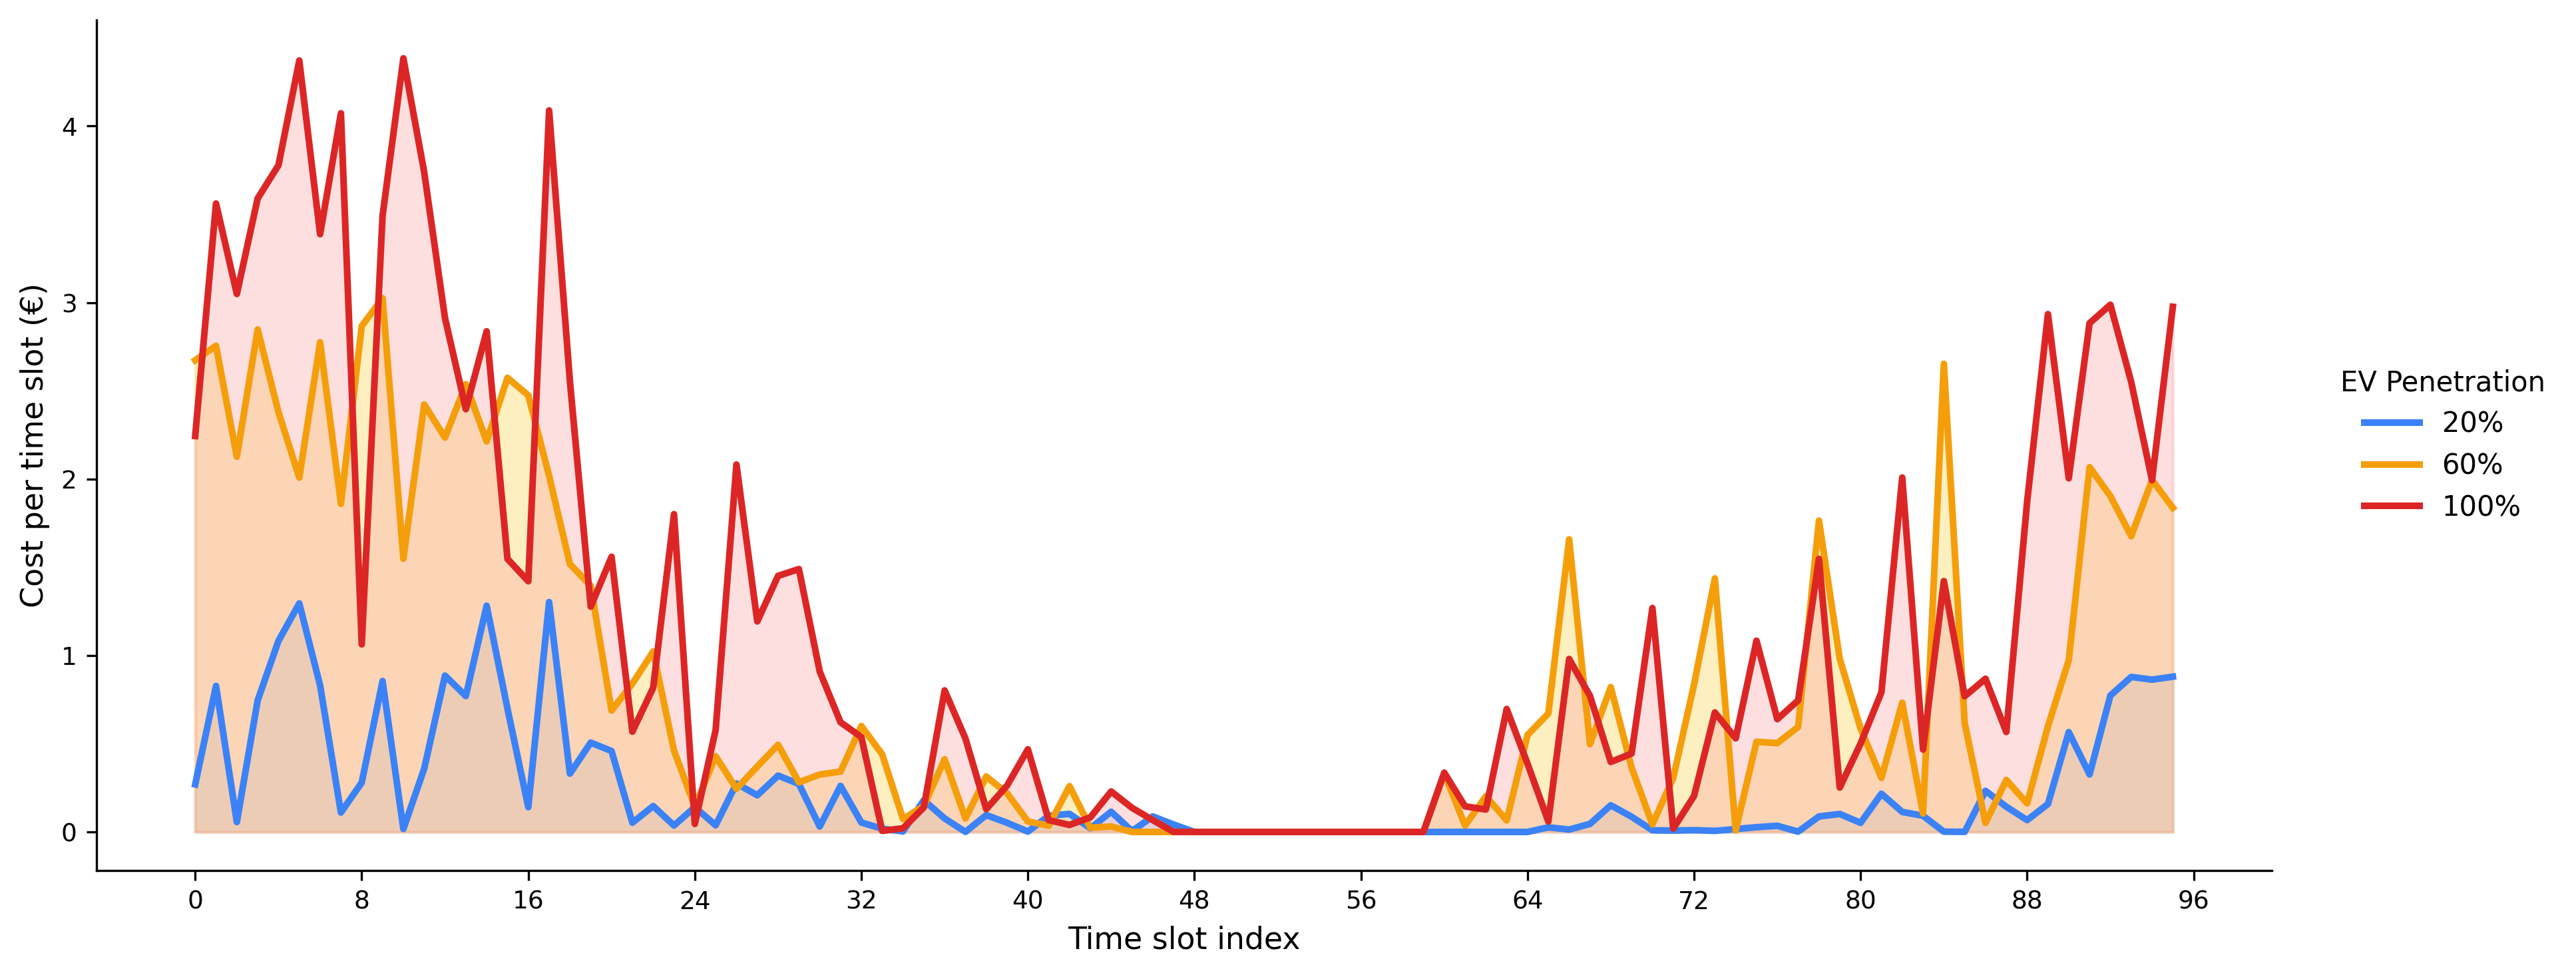

STEP 23 completed successfully.
Figure saved at: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/community_mochf_cost_styled.png


In [99]:
# ======================================================
# STEP 23: MOCHF-IoEVs charging cost profiles
# ======================================================

import matplotlib.pyplot as plt
import numpy as np
import os

MOCHF_COST_FIG = os.path.join(RESULTS_FOLDER, "community_mochf_cost_styled.png")

fig, ax = plt.subplots(figsize=(13, 5), dpi=300)

x = np.arange(N_SLOTS)
rt_price = df["rt_price"].values

# ------------------------------------------------------
# Colors for lines and fills
# ------------------------------------------------------
pen_styles = {
    0.20: {"line": "#3B82F6", "fill": "#93C5FD"},
    0.60: {"line": "#F59E0B", "fill": "#FCD34D"},
    1.00: {"line": "#DC2626", "fill": "#FCA5A5"}
}

# ------------------------------------------------------
# Plot MOCHF-IoEVs slot-wise cost
# slot cost = EV load × real-time price × dt
# ------------------------------------------------------
for pen in [0.20, 0.60, 1.00]:
    if pen not in mochf_profiles_by_pen:
        continue

    mochf_ev_kw = mochf_profiles_by_pen[pen]
    slot_cost = mochf_ev_kw * rt_price * DT_HOURS

    ax.fill_between(
        x,
        0,
        slot_cost,
        color=pen_styles[pen]["fill"],
        alpha=0.35
    )

    ax.plot(
        x,
        slot_cost,
        linewidth=2.4,
        color=pen_styles[pen]["line"],
        label=f"{int(pen*100)}%"
    )

# ------------------------------------------------------
# Styling
# ------------------------------------------------------
ax.set_xlabel("Time slot index", fontsize=11)
ax.set_ylabel("Cost per time slot (€)", fontsize=11)

tick_positions = np.arange(0, 97, 8)
ax.set_xticks(tick_positions)
ax.set_xticklabels([str(i) for i in tick_positions], fontsize=9)

ax.tick_params(axis="y", labelsize=9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(False)

ax.legend(
    title="EV Penetration",
    frameon=False,
    fontsize=10,
    title_fontsize=10,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5)
)

plt.tight_layout()
plt.savefig(MOCHF_COST_FIG, dpi=300, bbox_inches="tight")
plt.show()

print("STEP 23 completed successfully.")
print("Figure saved at:", MOCHF_COST_FIG)

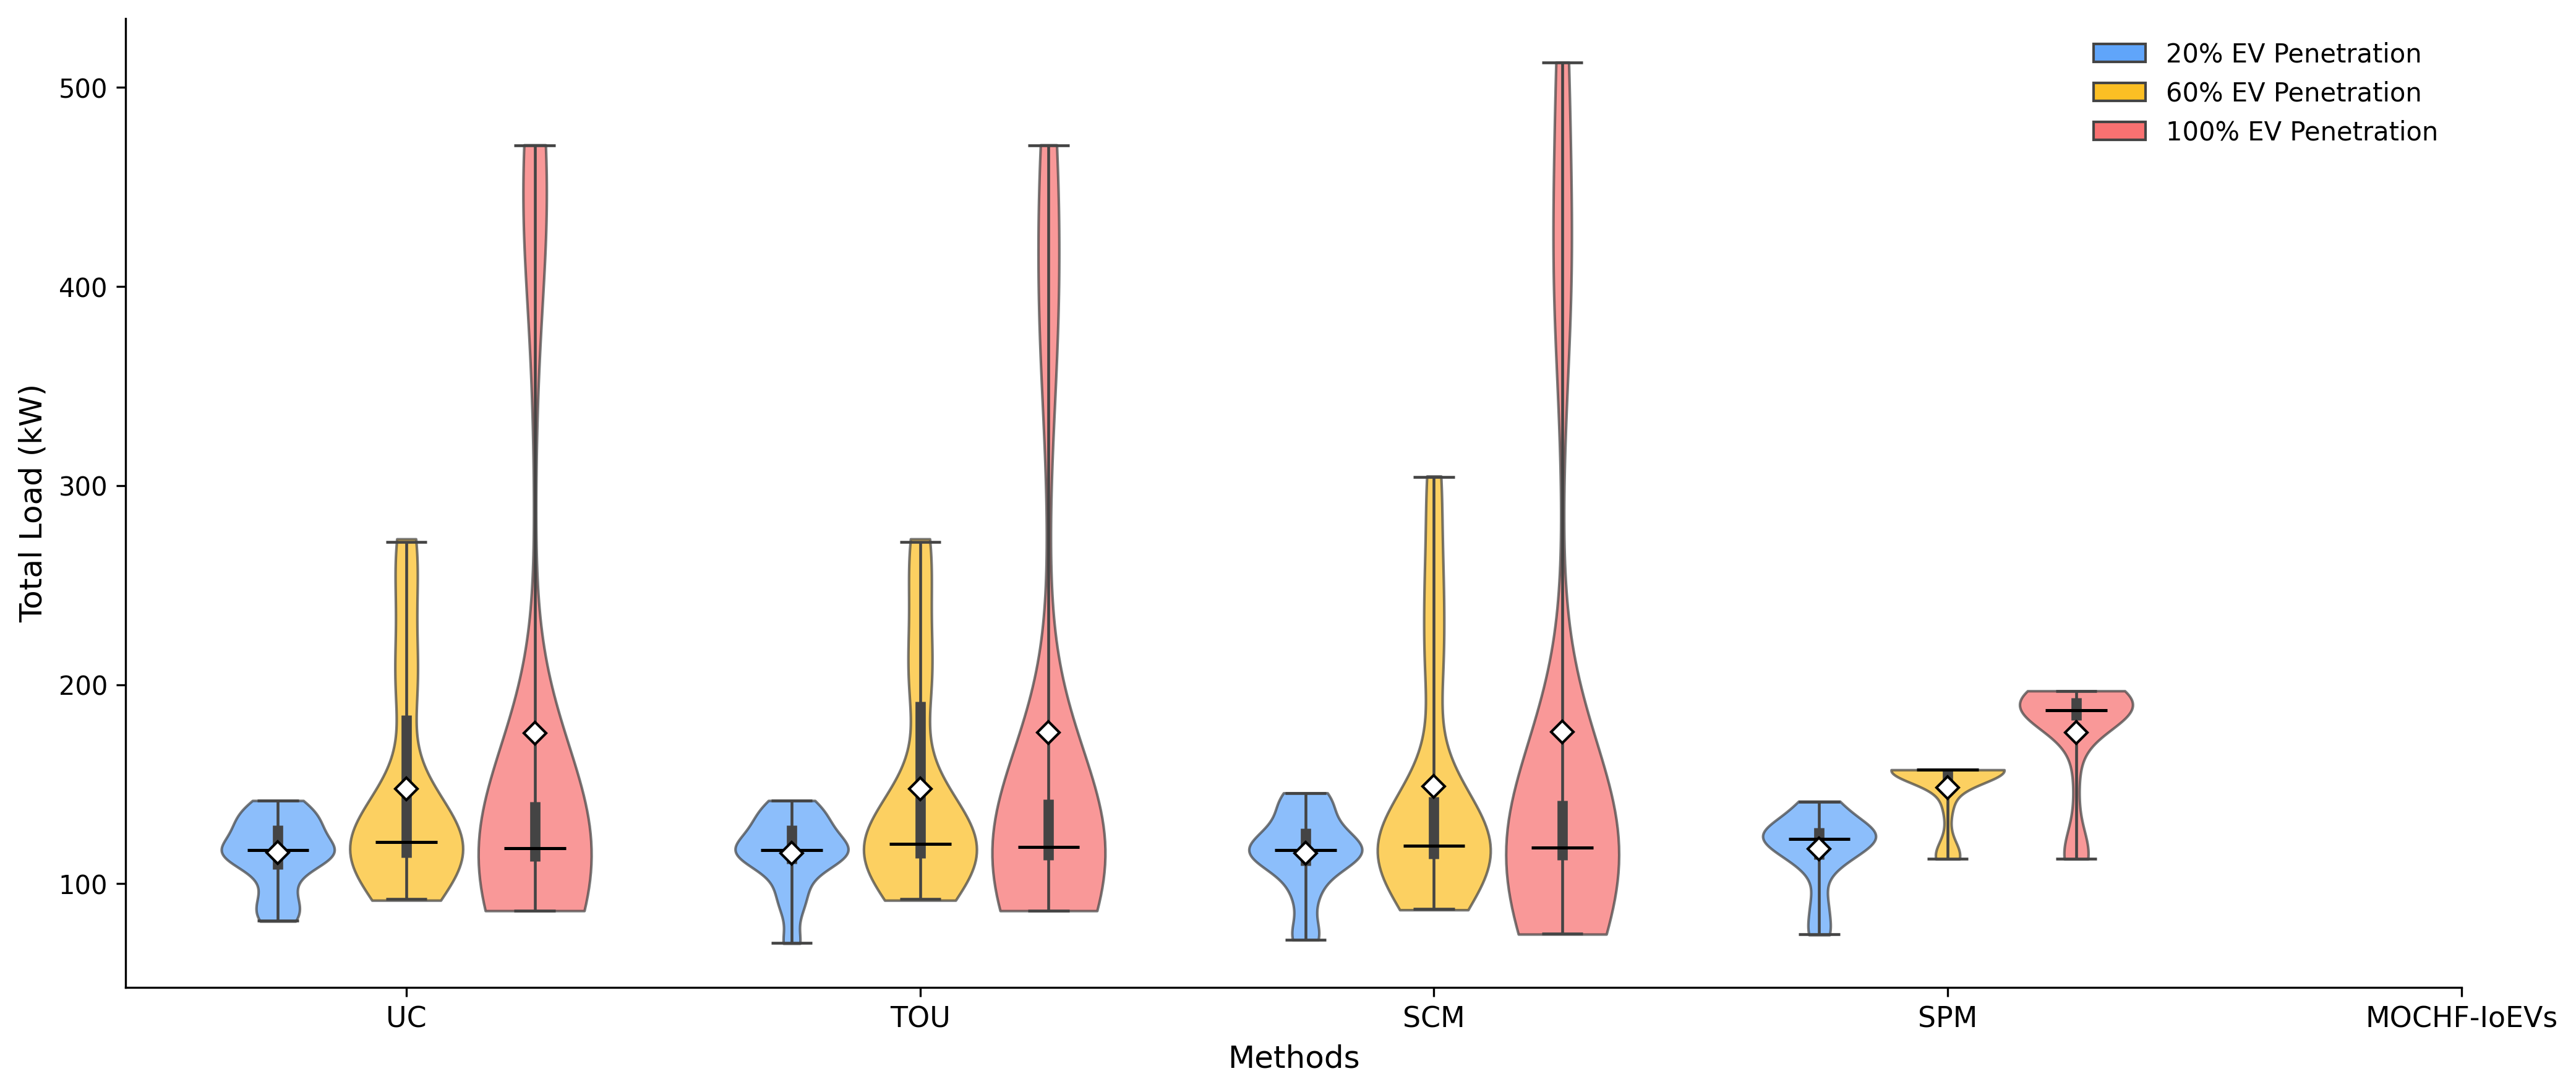

Truncated violin plot completed successfully.
Figure saved at: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/all_methods_penetration_truncated_violin.png


In [100]:
# ======================================================
# STEP 20: Truncated violin plot from CSV (Methods vs Penetration)
# Mean shown in plot, not shown in legend
# ======================================================

import matplotlib .pyplot as plt
import numpy as np
import pandas as pd
import os
from matplotlib .patches import Patch

# ------------------------------------------------------
# File path
# ------------------------------------------------------
FILE_PATH = os.path.join(ORIGINAL_RESULTS_FOLDER, "aggregatedload.csv")

VIOLIN_FIG =os .path .join (
os .path .dirname (FILE_PATH ),
"all_methods_penetration_truncated_violin.png"
)

# ------------------------------------------------------
# Load CSV
# ------------------------------------------------------
load_violin_df =pd .read_csv (FILE_PATH )

# ------------------------------------------------------
# Settings
# ------------------------------------------------------
methods =["UC","TOU","SCM","SPM","MOCHF-IoEVs"]
penetrations =[0.2 ,0.6 ,1.0 ]

pen_colors ={
0.2 :"#60A5FA",
0.6 :"#FBBF24",
1.0 :"#F87171"
}

group_centers =np .arange (1 ,len (methods )+1 )
offsets =[-0.25 ,0.00 ,0.25 ]

data =[]
positions =[]
colors =[]

# ------------------------------------------------------
# Prepare data from CSV
# ------------------------------------------------------
for i ,method in enumerate (methods ):
    center =group_centers [i ]

    for offset ,pen in zip (offsets ,penetrations ):
        subset =load_violin_df [(load_violin_df ["Method"]==method )&(load_violin_df ["Penetration"]==pen )]

        if subset .empty :
            continue

        total_load =subset ["TotalLoad_kW"].values

        # truncate extreme tails using 5th and 95th percentile
        low =np .percentile (total_load ,5 )
        high =np .percentile (total_load ,95 )
        total_load_truncated =np .clip (total_load ,low ,high )

        data .append (total_load_truncated )
        positions .append (center +offset )
        colors .append (pen_colors [pen ])

        # ------------------------------------------------------
        # Plot
        # ------------------------------------------------------
fig ,ax =plt .subplots (figsize =(14 ,6 ),dpi =300 )

vp =ax .violinplot (
data ,
positions =positions ,
widths =0.22 ,
showmeans =False ,
showmedians =False ,
showextrema =False
)

# ------------------------------------------------------
# Apply colors to violins
# ------------------------------------------------------
for body ,color in zip (vp ["bodies"],colors ):
    body .set_facecolor (color )
    body .set_edgecolor ("#444444")
    body .set_alpha (0.72 )
    body .set_linewidth (1.0 )

    # ------------------------------------------------------
    # Add quartile, whisker, median, and mean lines
    # ------------------------------------------------------
for pos ,arr in zip (positions ,data ):
    q1 =np .percentile (arr ,25 )
    median =np .percentile (arr ,50 )
    q3 =np .percentile (arr ,75 )
    low =np .percentile (arr ,5 )
    high =np .percentile (arr ,95 )
    mean_val =np .mean (arr )

    # central vertical whisker line
    ax .vlines (pos ,low ,high ,color ="#444444",linewidth =1.1 ,zorder =3 )

    # box-like quartile bar
    ax .vlines (pos ,q1 ,q3 ,color ="#444444",linewidth =4.0 ,zorder =4 )

    # whisker caps
    ax .hlines ([low ,high ],pos -0.04 ,pos +0.04 ,color ="#444444",linewidth =1.1 ,zorder =4 )

    # median line
    ax .hlines (median ,pos -0.06 ,pos +0.06 ,color ="black",linewidth =1.2 ,zorder =5 )

    # mean marker kept in plot
    ax .plot (
    pos ,
    mean_val ,
    marker ="D",
    markersize =6 ,
    markerfacecolor ="white",
    markeredgecolor ="black",
    linestyle ="None",
    zorder =6
    )

    # ------------------------------------------------------
    # Styling
    # ------------------------------------------------------
ax .set_xticks (group_centers )
ax .set_xticklabels (methods ,fontsize =11 )

ax .set_xlabel ("Methods",fontsize =12 )
ax .set_ylabel ("Total Load (kW)",fontsize =12 )

ax .tick_params (axis ="y",labelsize =10 )

ax .spines ["top"].set_visible (False )
ax .spines ["right"].set_visible (False )
ax .grid (False )

# ------------------------------------------------------
# Legend (penetration only)
# ------------------------------------------------------
legend_handles =[
Patch (facecolor =pen_colors [0.2 ],edgecolor ="#444444",label ="20% EV Penetration"),
Patch (facecolor =pen_colors [0.6 ],edgecolor ="#444444",label ="60% EV Penetration"),
Patch (facecolor =pen_colors [1.0 ],edgecolor ="#444444",label ="100% EV Penetration")
]

ax .legend (
handles =legend_handles ,
frameon =False ,
fontsize =10 ,
loc ="upper right"
)

plt .tight_layout ()
plt .savefig (VIOLIN_FIG ,dpi =300 ,bbox_inches ="tight")
plt .show ()

print ("Truncated violin plot completed successfully.")
print ("Figure saved at:",VIOLIN_FIG )

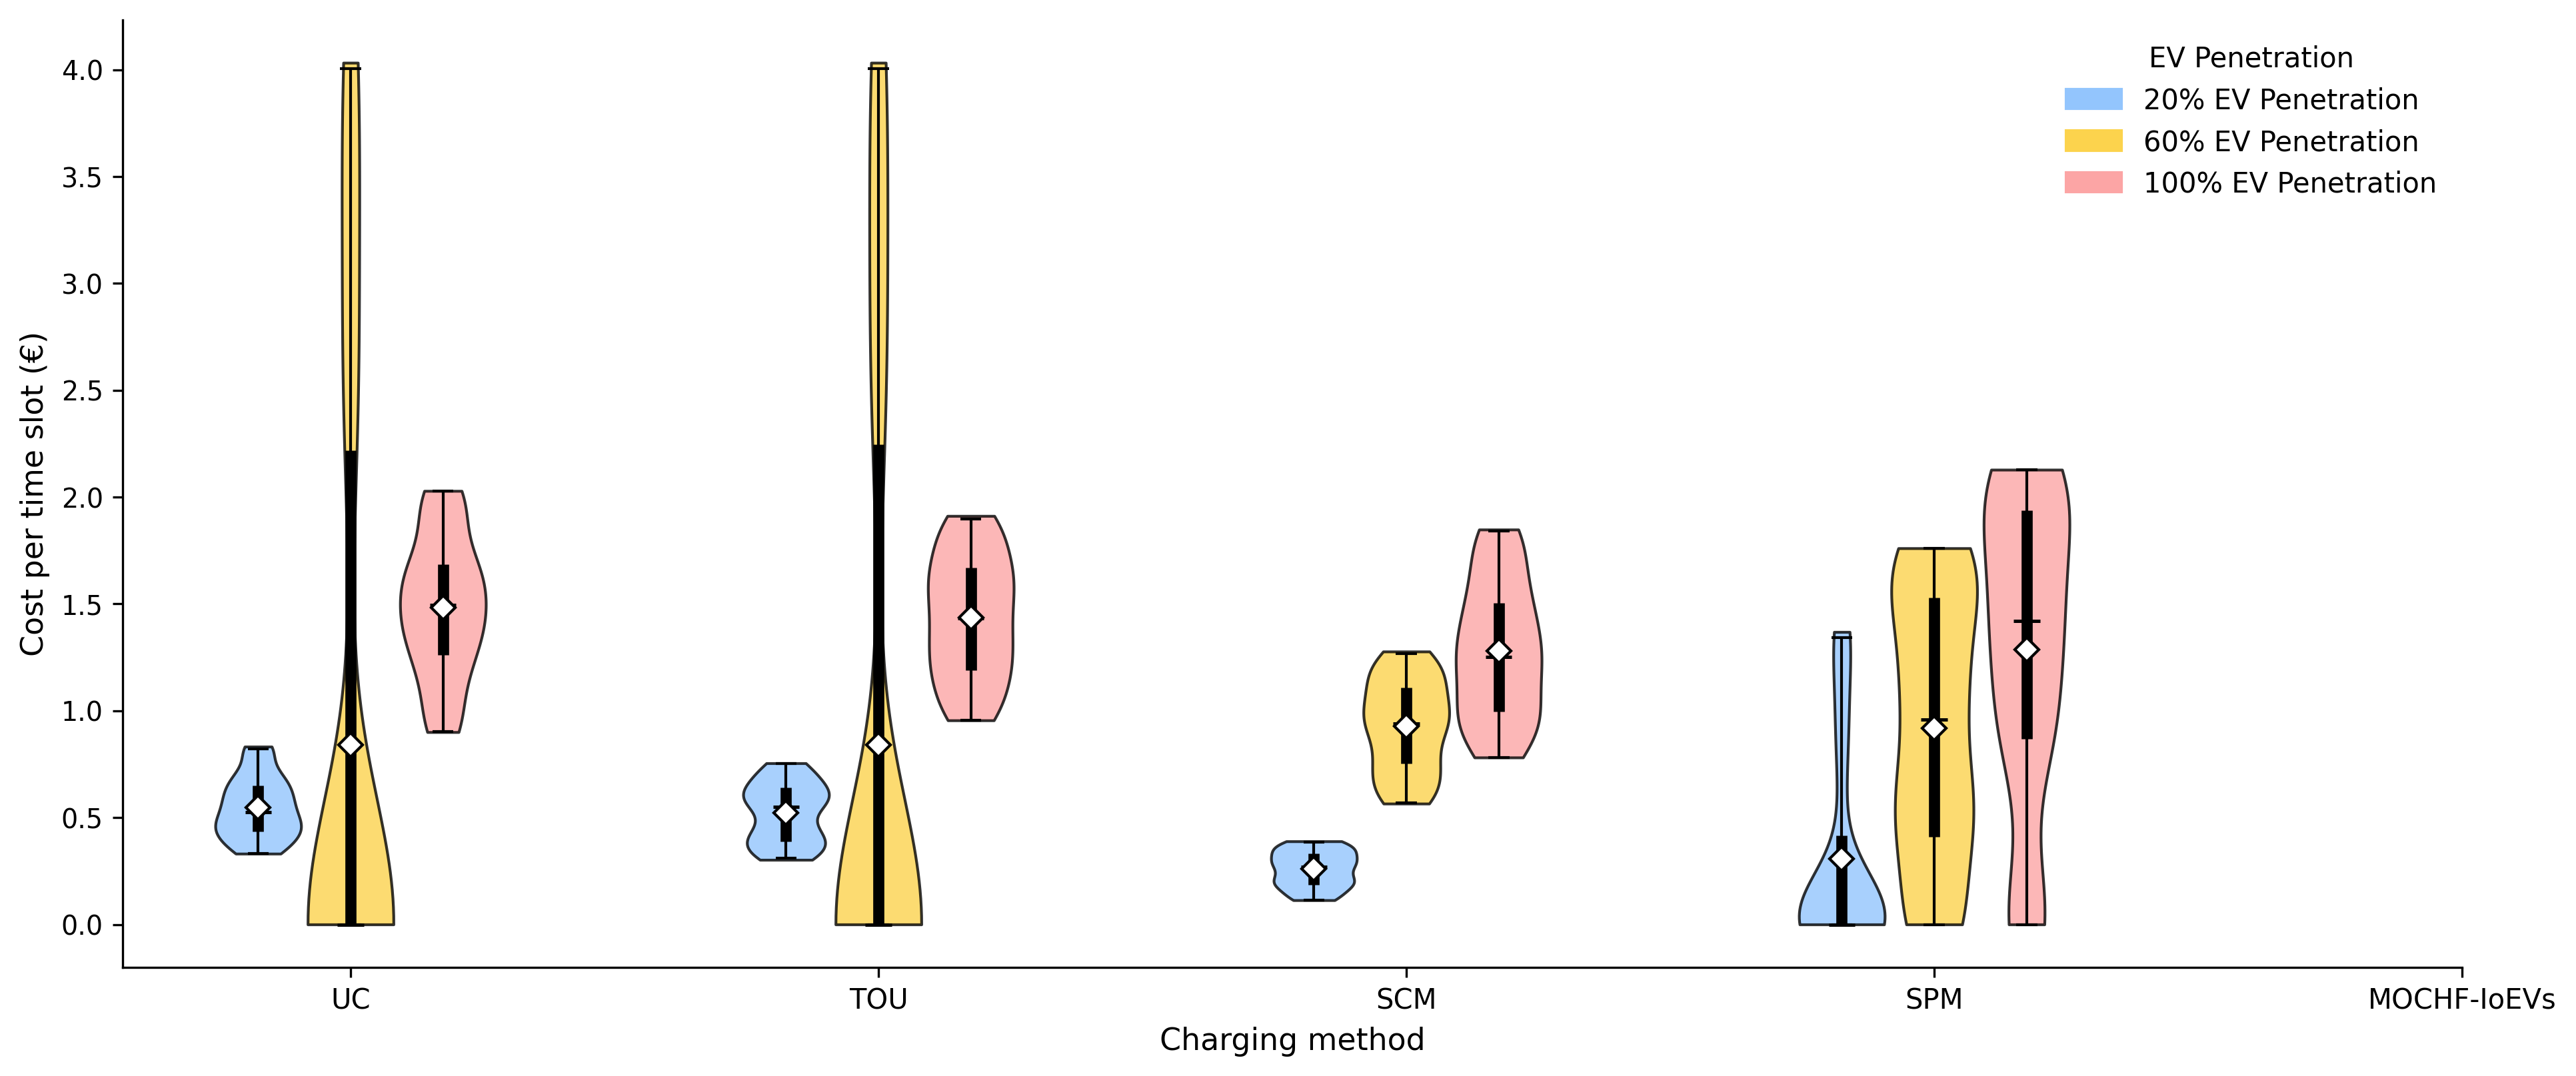

STEP 21 completed successfully.
Figure saved at: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/community_cost_truncated_violin.png


In [101]:
# ======================================================
# STEP 21: Truncated violin plot for cost
# Mean shown in plot, not shown in legend
# ======================================================

import matplotlib .pyplot as plt
import matplotlib .patches as mpatches
import numpy as np
import pandas as pd
import os

# ------------------------------------------------------
# File path
# ------------------------------------------------------
FILE_PATH = os.path.join(ORIGINAL_RESULTS_FOLDER, "aggregatedcost.csv")

COST_VIOLIN_FIG =os .path .join (
os .path .dirname (FILE_PATH ),
"community_cost_truncated_violin.png"
)

# ------------------------------------------------------
# Load CSV
# ------------------------------------------------------
cost_violin_df =pd .read_csv (FILE_PATH )

methods =["UC","TOU","SCM","SPM","MOCHF-IoEVs"]
penetrations =[0.2 ,0.6 ,1.0 ]

pen_colors ={
0.2 :"#93C5FD",
0.6 :"#FCD34D",
1.0 :"#FCA5A5"
}

# ------------------------------------------------------
# Prepare data
# ------------------------------------------------------
violin_data =[]
positions =[]
colors =[]

group_centers =np .arange (len (methods ))*4.0
offsets =[-0.7 ,0.0 ,0.7 ]

for i ,method in enumerate (methods ):
    for j ,pen in enumerate (penetrations ):
        subset =cost_violin_df [
        (cost_violin_df ["Method"]==method )&
        (cost_violin_df ["Penetration"]==pen )
        ]

        if subset .empty :
            continue

        cost_slots =subset ["SlotCost_EUR"].values

        # truncate tails to make the violin cleaner
        low =np .percentile (cost_slots ,5 )
        high =np .percentile (cost_slots ,95 )
        cost_truncated =np .clip (cost_slots ,low ,high )

        violin_data .append (cost_truncated )
        positions .append (group_centers [i ]+offsets [j ])
        colors .append (pen_colors [pen ])

        # ------------------------------------------------------
        # Plot
        # ------------------------------------------------------
fig ,ax =plt .subplots (figsize =(13 ,5.5 ),dpi =300 )

vp =ax .violinplot (
violin_data ,
positions =positions ,
widths =0.65 ,
showmeans =False ,
showmedians =False ,
showextrema =False
)

# ------------------------------------------------------
# Color violins
# ------------------------------------------------------
for body ,color in zip (vp ["bodies"],colors ):
    body .set_facecolor (color )
    body .set_edgecolor ("black")
    body .set_alpha (0.80 )
    body .set_linewidth (1.0 )

    # ------------------------------------------------------
    # Add quartiles, whiskers, median, and mean
    # ------------------------------------------------------
for pos ,arr in zip (positions ,violin_data ):
    q1 =np .percentile (arr ,25 )
    median =np .percentile (arr ,50 )
    q3 =np .percentile (arr ,75 )
    low =np .percentile (arr ,5 )
    high =np .percentile (arr ,95 )
    mean_val =np .mean (arr )

    # whisker line
    ax .vlines (pos ,low ,high ,color ="black",linewidth =1.0 ,zorder =3 )

    # thicker IQR bar
    ax .vlines (pos ,q1 ,q3 ,color ="black",linewidth =4.0 ,zorder =4 )

    # whisker caps
    ax .hlines ([low ,high ],pos -0.08 ,pos +0.08 ,color ="black",linewidth =1.0 ,zorder =4 )

    # median line
    ax .hlines (median ,pos -0.10 ,pos +0.10 ,color ="black",linewidth =1.2 ,zorder =5 )

    # mean marker shown in plot only
    ax .plot (
    pos ,
    mean_val ,
    marker ="D",
    markersize =6 ,
    markerfacecolor ="white",
    markeredgecolor ="black",
    linestyle ="None",
    zorder =6
    )

    # ------------------------------------------------------
    # Labels
    # ------------------------------------------------------
ax .set_xticks (group_centers )
ax .set_xticklabels (methods ,fontsize =10 )

ax .set_xlabel ("Charging method",fontsize =11 )
ax .set_ylabel ("Cost per time slot (€)",fontsize =11 )

ax .spines ["top"].set_visible (False )
ax .spines ["right"].set_visible (False )
ax .grid (False )

# ------------------------------------------------------
# Legend (penetration only)
# ------------------------------------------------------
legend_handles =[
mpatches .Patch (color =pen_colors [0.2 ],label ="20% EV Penetration"),
mpatches .Patch (color =pen_colors [0.6 ],label ="60% EV Penetration"),
mpatches .Patch (color =pen_colors [1.0 ],label ="100% EV Penetration")
]

ax .legend (
handles =legend_handles ,
title ="EV Penetration",
frameon =False ,
fontsize =10 ,
title_fontsize =10 ,
loc ="upper right"
)

plt .tight_layout ()
plt .savefig (COST_VIOLIN_FIG ,dpi =300 ,bbox_inches ="tight")
plt .show ()

print ("STEP 21 completed successfully.")
print ("Figure saved at:",COST_VIOLIN_FIG )

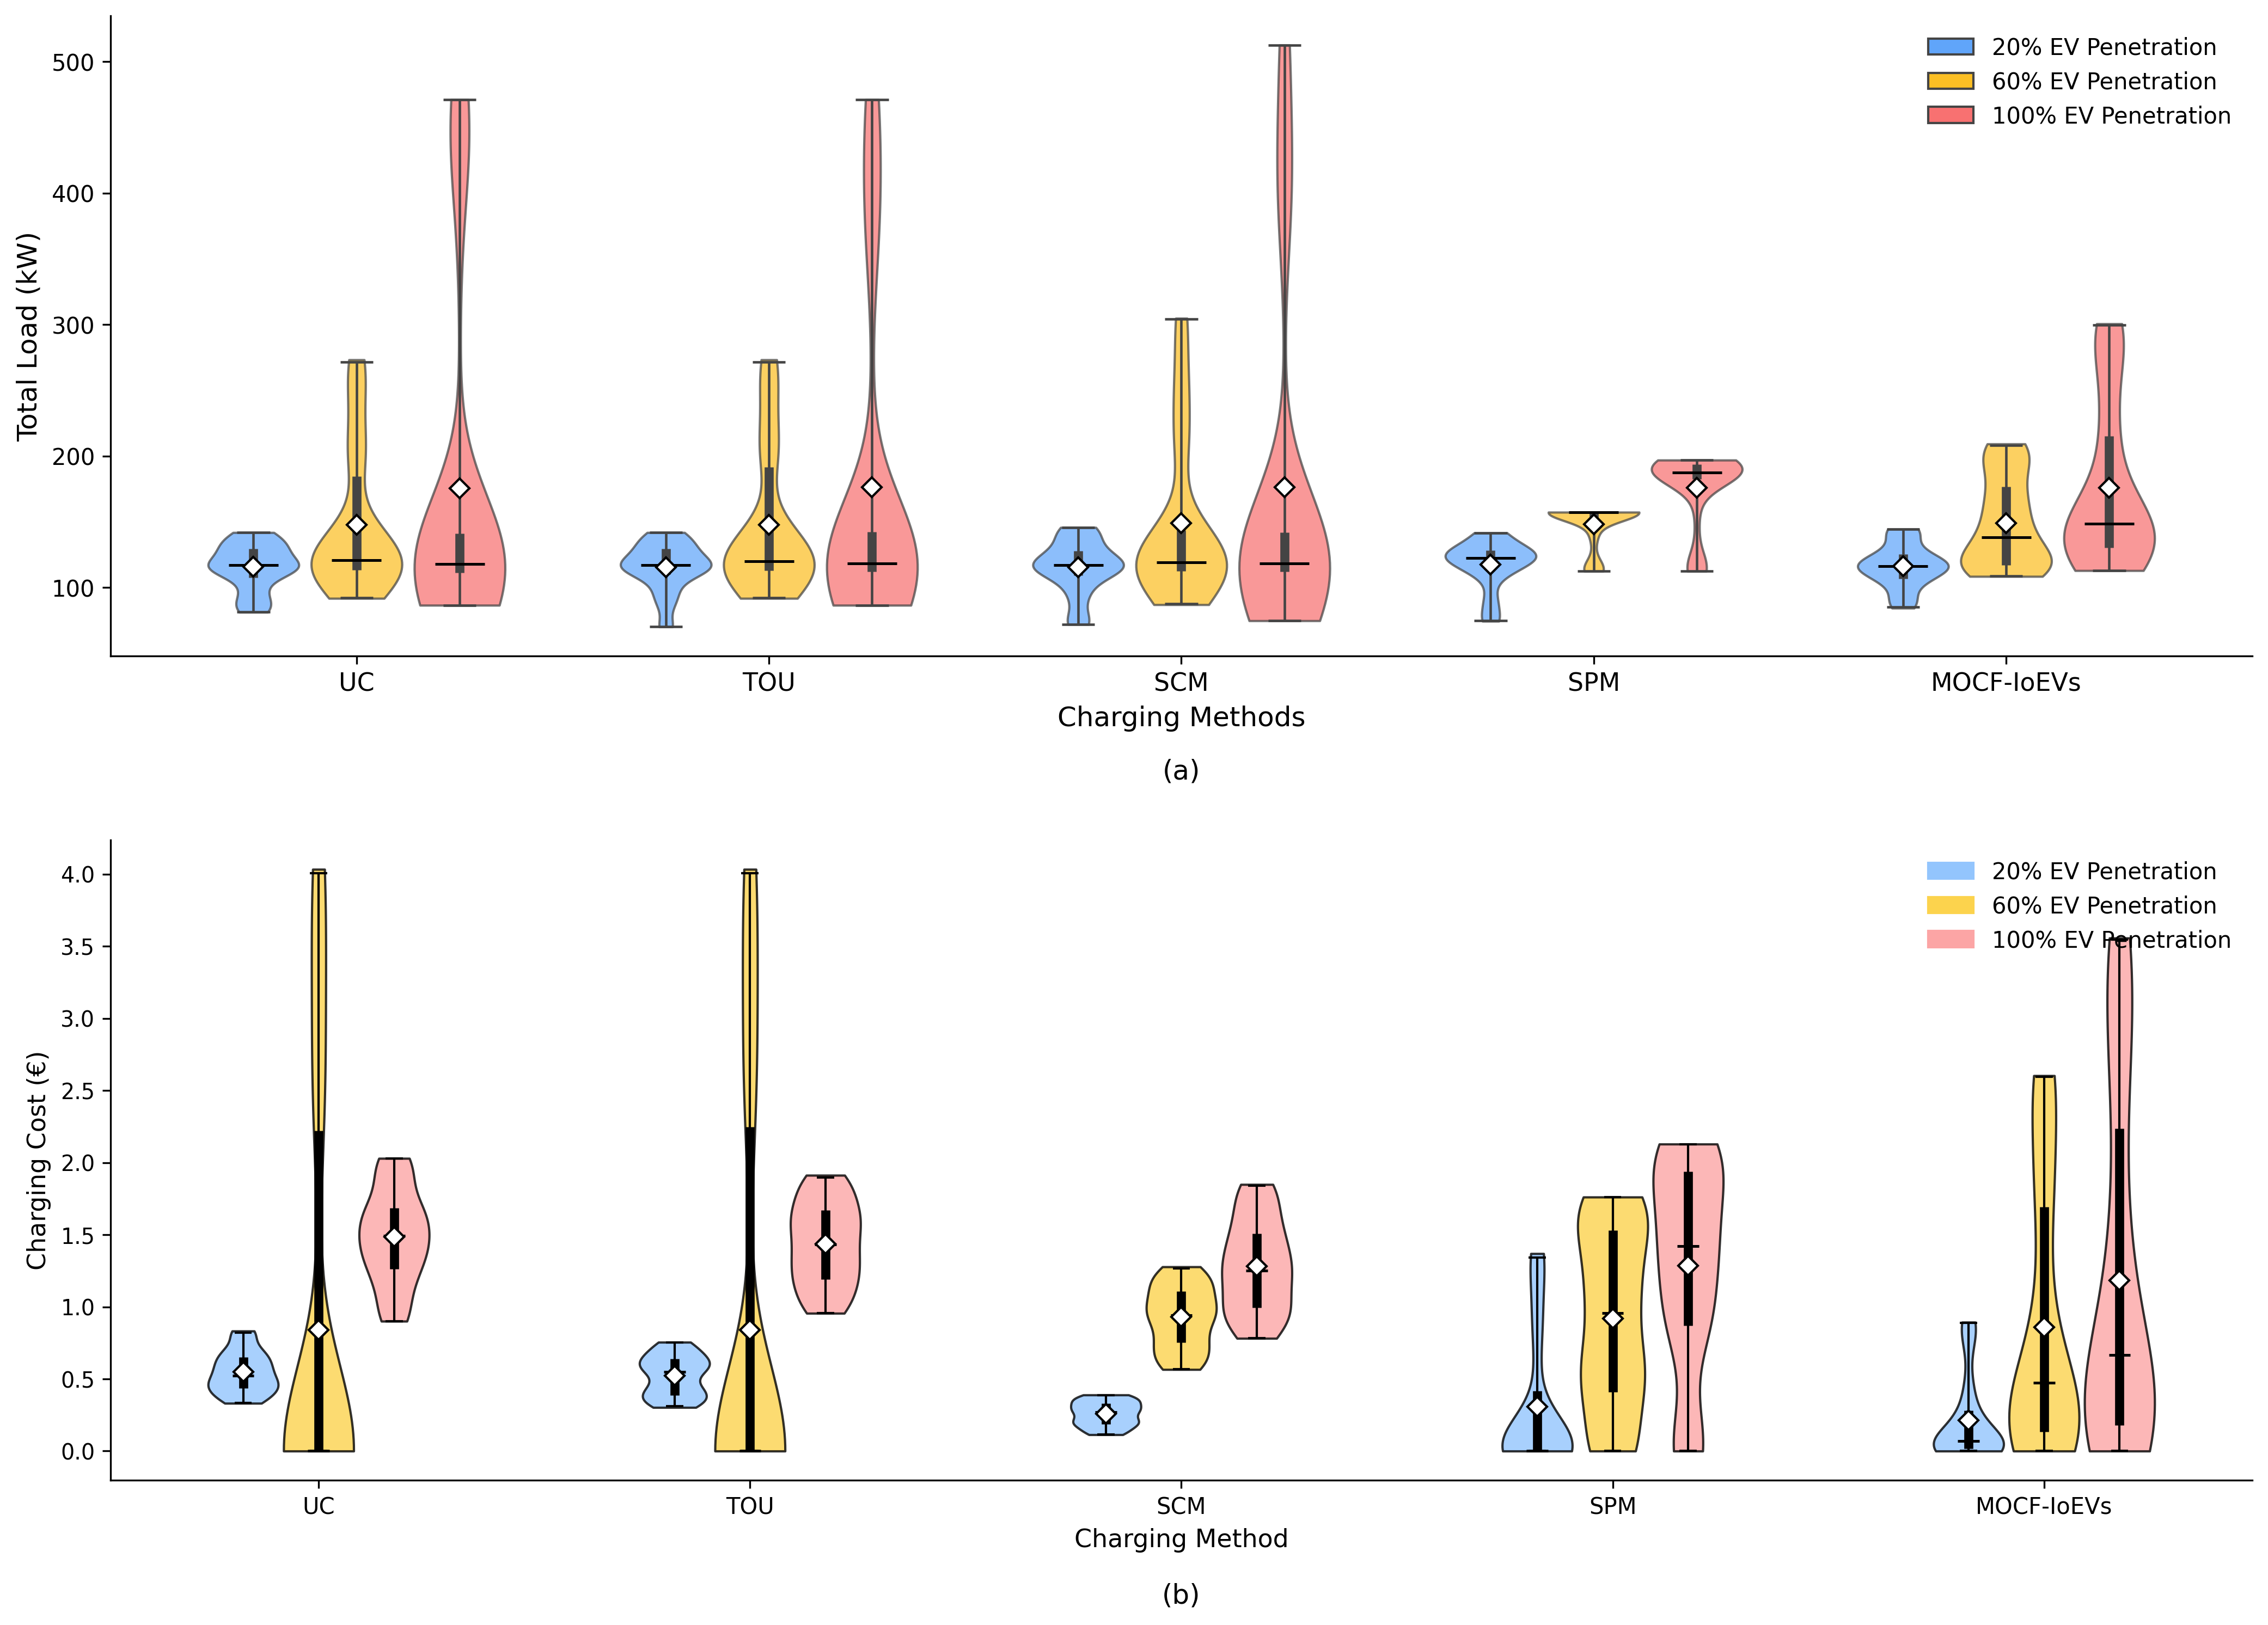

In [102]:
# ======================================================
# COMBINED FIGURE: (a) Load violin plot + (b) Cost violin plot
# Top row: Load
# Bottom row: Cost
# Separate legends for each subplot
# No subplot titles
# (a) and (b) placed below x-axis
# ======================================================

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import os
from matplotlib.patches import Patch

# ------------------------------------------------------
# File paths
# ------------------------------------------------------
LOAD_FILE_PATH = os.path.join(ORIGINAL_RESULTS_FOLDER, "aggregatedload.csv")
COST_FILE_PATH = os.path.join(ORIGINAL_RESULTS_FOLDER, "aggregatedcost.csv")

COMBINED_FIG = os.path.join(
    RESULTS_FOLDER,
    "combined_load_cost_truncated_violin.png"
)

# ------------------------------------------------------
# Load data
# ------------------------------------------------------
df_load = pd.read_csv(LOAD_FILE_PATH)
df_cost = pd.read_csv(COST_FILE_PATH)

methods = ["UC", "TOU", "SCM", "SPM", "MOCF-IoEVs"]
penetrations = [0.2, 0.6, 1.0]

load_colors = {
    0.2: "#60A5FA",
    0.6: "#FBBF24",
    1.0: "#F87171"
}

cost_colors = {
    0.2: "#93C5FD",
    0.6: "#FCD34D",
    1.0: "#FCA5A5"
}

# ------------------------------------------------------
# Figure and axes
# ------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(14, 10), dpi=300)
ax1, ax2 = axes

# ======================================================
# (a) LOAD PLOT
# ======================================================
group_centers_load = np.arange(1, len(methods) + 1)
offsets_load = [-0.25, 0.00, 0.25]

load_data = []
load_positions = []
load_body_colors = []

for i, method in enumerate(methods):
    center = group_centers_load[i]

    for offset, pen in zip(offsets_load, penetrations):
        subset = df_load[
            (df_load["Method"] == method) &
            (df_load["Penetration"] == pen)
        ]

        if subset.empty:
            continue

        total_load = subset["TotalLoad_kW"].values

        low = np.percentile(total_load, 5)
        high = np.percentile(total_load, 95)
        total_load_truncated = np.clip(total_load, low, high)

        load_data.append(total_load_truncated)
        load_positions.append(center + offset)
        load_body_colors.append(load_colors[pen])

vp1 = ax1.violinplot(
    load_data,
    positions=load_positions,
    widths=0.22,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

for body, color in zip(vp1["bodies"], load_body_colors):
    body.set_facecolor(color)
    body.set_edgecolor("#444444")
    body.set_alpha(0.72)
    body.set_linewidth(1.0)

for pos, arr in zip(load_positions, load_data):
    q1 = np.percentile(arr, 25)
    median = np.percentile(arr, 50)
    q3 = np.percentile(arr, 75)
    low = np.percentile(arr, 5)
    high = np.percentile(arr, 95)
    mean_val = np.mean(arr)

    ax1.vlines(pos, low, high, color="#444444", linewidth=1.1, zorder=3)
    ax1.vlines(pos, q1, q3, color="#444444", linewidth=4.0, zorder=4)
    ax1.hlines([low, high], pos - 0.04, pos + 0.04, color="#444444", linewidth=1.1, zorder=4)
    ax1.hlines(median, pos - 0.06, pos + 0.06, color="black", linewidth=1.2, zorder=5)

    ax1.plot(
        pos,
        mean_val,
        marker="D",
        markersize=6,
        markerfacecolor="white",
        markeredgecolor="black",
        linestyle="None",
        zorder=6
    )

ax1.set_xticks(group_centers_load)
ax1.set_xticklabels(methods, fontsize=11)
ax1.set_xlabel("Charging Methods", fontsize=12)
ax1.set_ylabel("Total Load (kW)", fontsize=12)
ax1.tick_params(axis="y", labelsize=10)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.grid(False)

legend_handles_load = [
    Patch(facecolor=load_colors[0.2], edgecolor="#444444", label="20% EV Penetration"),
    Patch(facecolor=load_colors[0.6], edgecolor="#444444", label="60% EV Penetration"),
    Patch(facecolor=load_colors[1.0], edgecolor="#444444", label="100% EV Penetration")
]

ax1.legend(
    handles=legend_handles_load,
    frameon=False,
    fontsize=10,
    loc="upper right"
)

# Place (a) below x-axis
ax1.text(
    0.5, -0.16, "(a)",
    transform=ax1.transAxes,
    ha="center",
    va="top",
    fontsize=12
)

# ======================================================
# (b) COST PLOT
# ======================================================
group_centers_cost = np.arange(len(methods)) * 4.0
offsets_cost = [-0.7, 0.0, 0.7]

cost_data = []
cost_positions = []
cost_body_colors = []

for i, method in enumerate(methods):
    for j, pen in enumerate(penetrations):
        subset = df_cost[
            (df_cost["Method"] == method) &
            (df_cost["Penetration"] == pen)
        ]

        if subset.empty:
            continue

        cost_slots = subset["SlotCost_EUR"].values

        low = np.percentile(cost_slots, 5)
        high = np.percentile(cost_slots, 95)
        cost_truncated = np.clip(cost_slots, low, high)

        cost_data.append(cost_truncated)
        cost_positions.append(group_centers_cost[i] + offsets_cost[j])
        cost_body_colors.append(cost_colors[pen])

vp2 = ax2.violinplot(
    cost_data,
    positions=cost_positions,
    widths=0.65,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

for body, color in zip(vp2["bodies"], cost_body_colors):
    body.set_facecolor(color)
    body.set_edgecolor("black")
    body.set_alpha(0.80)
    body.set_linewidth(1.0)

for pos, arr in zip(cost_positions, cost_data):
    q1 = np.percentile(arr, 25)
    median = np.percentile(arr, 50)
    q3 = np.percentile(arr, 75)
    low = np.percentile(arr, 5)
    high = np.percentile(arr, 95)
    mean_val = np.mean(arr)

    ax2.vlines(pos, low, high, color="black", linewidth=1.0, zorder=3)
    ax2.vlines(pos, q1, q3, color="black", linewidth=4.0, zorder=4)
    ax2.hlines([low, high], pos - 0.08, pos + 0.08, color="black", linewidth=1.0, zorder=4)
    ax2.hlines(median, pos - 0.10, pos + 0.10, color="black", linewidth=1.2, zorder=5)

    ax2.plot(
        pos,
        mean_val,
        marker="D",
        markersize=6,
        markerfacecolor="white",
        markeredgecolor="black",
        linestyle="None",
        zorder=6
    )

ax2.set_xticks(group_centers_cost)
ax2.set_xticklabels(methods, fontsize=10)
ax2.set_xlabel("Charging Method", fontsize=11)
ax2.set_ylabel("Charging Cost (€)", fontsize=11)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.grid(False)

legend_handles_cost = [
    mpatches.Patch(color=cost_colors[0.2], label="20% EV Penetration"),
    mpatches.Patch(color=cost_colors[0.6], label="60% EV Penetration"),
    mpatches.Patch(color=cost_colors[1.0], label="100% EV Penetration")
]

ax2.legend(
    handles=legend_handles_cost,
    # title="EV Penetration",
    frameon=False,
    fontsize=10,
    title_fontsize=10,
    loc="upper right"
)

# Place (b) below x-axis
ax2.text(
    0.5, -0.16, "(b)",
    transform=ax2.transAxes,
    ha="center",
    va="top",
    fontsize=12
)

# ------------------------------------------------------
# Layout and save
# ------------------------------------------------------
plt.tight_layout(h_pad=2.8)
plt.savefig(COMBINED_FIG, dpi=300, bbox_inches="tight")
plt.show()

#print("Combined load and cost violin plots completed successfully.")
# print("Figure saved at:", COMBINED_FIG)

In [103]:
# ======================================================
# STEP 25: Final comparison table with improvements
# ======================================================

import pandas as pd
import numpy as np
import os

# ------------------------------------------------------
# Combine all results
# ------------------------------------------------------
all_results = pd.concat([
    uc_results_df,
    tou_results_df,
    scm_results_df,
    spm_results_df,
    mochf_results_df
], ignore_index=True)

# ------------------------------------------------------
# Compute percentage improvements relative to UC
# ------------------------------------------------------
final_rows = []

for pen in sorted(all_results["Penetration"].unique()):
    df_pen = all_results[all_results["Penetration"] == pen]

    uc_row = df_pen[df_pen["Method"] == "UC"].iloc[0]

    uc_peak = uc_row["PeakTotalLoad_kW"]
    uc_cost = uc_row["ChargingCost"]

    for _, row in df_pen.iterrows():
        peak = row["PeakTotalLoad_kW"]
        cost = row["ChargingCost"]

        peak_reduction = ((uc_peak - peak) / uc_peak) * 100
        cost_reduction = ((uc_cost - cost) / uc_cost) * 100

        final_rows.append({
            "Penetration": pen,
            "Method": row["Method"],
            "PeakLoad_kW": peak,
            "ChargingCost_EUR": cost,
            "PeakReduction_%": peak_reduction,
            "CostReduction_%": cost_reduction
        })

final_table = pd.DataFrame(final_rows)

# ------------------------------------------------------
# Round values
# ------------------------------------------------------
final_table = final_table.round({
    "PeakLoad_kW": 3,
    "ChargingCost_EUR": 3,
    "PeakReduction_%": 2,
    "CostReduction_%": 2
})

# ------------------------------------------------------
# Save table
# ------------------------------------------------------
final_table_file = os.path.join(RESULTS_FOLDER, "final_comparison_table.csv")
final_table.to_csv(final_table_file, index=False)

print("STEP 25 completed successfully.")
print("Saved final table to:", final_table_file)

final_table

STEP 25 completed successfully.
Saved final table to: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/final_comparison_table.csv


,Penetration,Method,PeakLoad_kW,ChargingCost_EUR,PeakReduction_%,CostReduction_%
0,0.2,UC,152.000,22.118,0.00,0.00
1,0.2,TOU,152.000,22.118,0.00,0.00
2,0.2,SCM,166.400,20.453,-9.47,7.53
3,0.2,SPM,144.000,30.007,5.26,-35.67
4,0.2,MOCHF-IoEVs,145.056,21.816,4.57,1.37
5,0.6,UC,300.000,82.515,0.00,0.00
6,0.6,TOU,300.000,82.515,0.00,0.00
7,0.6,SCM,308.400,76.183,-2.80,7.67
8,0.6,SPM,157.566,88.169,47.48,-6.85
9,0.6,MOCHF-IoEVs,220.535,83.319,26.49,-0.97


In [104]:

# ======================================================
# STEP 22: Measured Computational Performance
# UC, TOU, SCM, SPM and Proposed MOCF-IoEVs
# ======================================================

import time
import platform
import sys
import numpy as np
import pandas as pd
from pathlib import Path

N_REPEATS = 5
DEADLINE_SECONDS = 900

# Check that the original simulation is loaded
required = [
    "community_inputs",
    "run_uc_schedule",
    "run_tou_schedule",
    "run_scm_schedule",
    "run_spm_schedule",
    "run_mochf_schedule"
]

missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        "Please run the original simulation cells first. "
        "Missing: " + ", ".join(missing)
    )

# Save results to the current working directory
output_dir = Path(RESULTS_FOLDER)
output_dir.mkdir(parents=True, exist_ok=True)
runtime_records = []

for pen, info in sorted(community_inputs.items()):

    if not info["Feasible"]:
        print(f"Skipping infeasible scenario: {pen:.0%}")
        continue

    n_evs = int(info["NumEVs"])

    energy = info["TotalRequiredEnergy_kWh"]
    power = info["AvailablePower_kW"]
    base = info["BaseLoad_kW"]
    rt = info["RT_Price"]
    tou = info["TOU_Price"]

    # Use the original scheduling functions
    methods = {
        "UC": lambda: run_uc_schedule(energy, power),
        "TOU": lambda: run_tou_schedule(energy, power, tou),
        "SCM": lambda: run_scm_schedule(energy, power, rt),
        "SPM": lambda: run_spm_schedule(energy, power, base),
        "MOCF-IoEVs": lambda: run_mochf_schedule(
            base, power, rt, energy
        )
    }

    print(f"\nScenario: {n_evs} EVs ({pen:.0%} penetration)")

    for method, run_function in methods.items():

        print(f"  Running {method}...", flush=True)

        for repeat in range(1, N_REPEATS + 1):

            start = time.perf_counter()
            result = run_function()
            elapsed = time.perf_counter() - start

            runtime_records.append({
                "EVs": n_evs,
                "Penetration": pen,
                "Method": method,
                "Repeat": repeat,
                "Runtime_seconds": elapsed,
                "Runtime_ms": elapsed * 1000,
                "Within_900s": elapsed <= DEADLINE_SECONDS
            })

            print(
                f"    Run {repeat}/{N_REPEATS}: "
                f"{elapsed:.4f} seconds",
                flush=True
            )

# Raw timing measurements
runtime_raw = pd.DataFrame(runtime_records)

# Summary statistics
runtime_summary = (
    runtime_raw
    .groupby(["Method", "EVs"], as_index=False)
    .agg(
        Mean_ms=("Runtime_ms", "mean"),
        SD_ms=("Runtime_ms", "std"),
        Maximum_ms=("Runtime_ms", "max"),
        Mean_seconds=("Runtime_seconds", "mean"),
        Maximum_seconds=("Runtime_seconds", "max"),
        All_within_900s=("Within_900s", "all")
    )
)

# Display a comparison table
runtime_summary["Mean_SD_ms"] = runtime_summary.apply(
    lambda row: f"{row['Mean_ms']:.3f} ± {row['SD_ms']:.3f}",
    axis=1
)

method_order = [
    "UC", "TOU", "SCM", "SPM", "MOCF-IoEVs"
]

comparison_table = runtime_summary.pivot(
    index="Method",
    columns="EVs",
    values="Mean_SD_ms"
).reindex(method_order)

print("\nMEASURED COMPUTATIONAL PERFORMANCE")
print("Mean ± standard deviation (milliseconds)")
print(comparison_table.to_string())

print("\nDEADLINE CHECK (900 seconds)")
print(
    runtime_summary[
        ["Method", "EVs", "Maximum_seconds", "All_within_900s"]
    ].to_string(index=False)
)

# Save files
runtime_raw.to_csv(
    output_dir / "runtime_raw_measurements.csv",
    index=False
)

runtime_summary.to_csv(
    output_dir / "runtime_summary.csv",
    index=False
)

comparison_table.to_csv(
    output_dir / "runtime_comparison_table.csv"
)

# Record computational environment
environment = pd.DataFrame([{
    "Python": sys.version.split()[0],
    "Platform": platform.platform(),
    "Processor": platform.processor(),
    "Population": 150,
    "Generations": 200,
    "Scheduling_slots": 96,
    "Slot_minutes": 15,
    "Repeats": N_REPEATS
}])

environment.to_csv(
    output_dir / "runtime_environment.csv",
    index=False
)

print("\nBenchmark completed.")
print("Results saved to:", output_dir)



Scenario: 10 EVs (20% penetration)
  Running UC...
    Run 1/5: 0.0013 seconds
    Run 2/5: 0.0000 seconds
    Run 3/5: 0.0000 seconds
    Run 4/5: 0.0000 seconds
    Run 5/5: 0.0000 seconds
  Running TOU...
    Run 1/5: 0.0004 seconds
    Run 2/5: 0.0001 seconds
    Run 3/5: 0.0001 seconds
    Run 4/5: 0.0001 seconds
    Run 5/5: 0.0000 seconds
  Running SCM...
    Run 1/5: 0.0027 seconds
    Run 2/5: 0.0024 seconds
    Run 3/5: 0.0024 seconds
    Run 4/5: 0.0022 seconds
    Run 5/5: 0.0024 seconds
  Running SPM...
    Run 1/5: 0.0032 seconds
    Run 2/5: 0.0036 seconds
    Run 3/5: 0.0028 seconds
    Run 4/5: 0.0023 seconds
    Run 5/5: 0.0027 seconds
  Running MOCF-IoEVs...
    Run 1/5: 5.7763 seconds
    Run 2/5: 5.5836 seconds
    Run 3/5: 5.7027 seconds
    Run 4/5: 5.8751 seconds
    Run 5/5: 5.1746 seconds

Scenario: 30 EVs (60% penetration)
  Running UC...
    Run 1/5: 0.0001 seconds
    Run 2/5: 0.0000 seconds
    Run 3/5: 0.0001 seconds
    Run 4/5: 0.0001 seconds
    Run 5

In [105]:

# ============================================================
# STEP 23: GENERATE INDEPENDENT STOCHASTIC EV SCENARIOS
# ============================================================

import os
import json
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 23: STOCHASTIC SCENARIO GENERATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Statistical experiment configuration
# ------------------------------------------------------------

STAT_N_SCENARIOS = 30
STAT_N_BOOTSTRAP = 10000
STAT_CONFIDENCE = 0.95

STAT_SCENARIO_SEED = 42
STAT_BOOTSTRAP_SEED = 2026

STAT_PENETRATIONS = [0.20, 0.60, 1.00]

STAT_METHODS = [
    "UC",
    "TOU",
    "SCM",
    "SPM",
    "MOCF-IoEVs"
]

# ------------------------------------------------------------
# 2. Separate output folder
# ------------------------------------------------------------

STAT_FOLDER = os.path.join(
    RESULTS_FOLDER,
    "Reviewer1_Comment8"
)

os.makedirs(STAT_FOLDER, exist_ok=True)

# ------------------------------------------------------------
# 3. Verify original simulation inputs
# ------------------------------------------------------------

required_variables = [
    "N_HOUSES",
    "N_SLOTS",
    "CHARGER_KW",
    "DT_HOURS",
    "ETA",
    "community_inputs",
    "ev_types"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing original simulation variables: "
        + ", ".join(missing)
    )

if N_SLOTS != 96:
    raise ValueError("Expected 96 charging time slots.")

if not all(
    pen in community_inputs
    for pen in STAT_PENETRATIONS
):
    raise RuntimeError(
        "Original community inputs are incomplete."
    )

# ------------------------------------------------------------
# 4. Original EV type distribution
# ------------------------------------------------------------

stat_ev_names = [
    item["EVType"] for item in ev_types
]

stat_battery_map = {
    item["EVType"]: float(item["Battery_kWh"])
    for item in ev_types
}

# ------------------------------------------------------------
# 5. Generate 30 scenarios per penetration level
# ------------------------------------------------------------

stat_scenario_rows = []
stat_ev_rows = []

for scenario_id in range(1, STAT_N_SCENARIOS + 1):

    for pen_index, pen in enumerate(STAT_PENETRATIONS):

        # Independent, reproducible seed
        seed = (
            STAT_SCENARIO_SEED
            + (scenario_id - 1) * 1000
            + pen_index
        )

        local_rng = np.random.default_rng(seed)

        n_evs = int(round(N_HOUSES * pen))

        # Original Step 4 EV sampling distributions
        selected_types = local_rng.choice(
            stat_ev_names,
            size=n_evs,
            replace=True
        )

        arrival_soc = local_rng.uniform(
            0.20, 0.60, size=n_evs
        )

        target_soc = local_rng.uniform(
            0.70, 0.95, size=n_evs
        )

        target_soc = np.maximum(
            target_soc,
            arrival_soc + 0.10
        )

        target_soc = np.minimum(
            target_soc, 0.95
        )

        arrival_hours = np.clip(
            local_rng.normal(
                loc=18.0,
                scale=2.0,
                size=n_evs
            ),
            15.0,
            23.0
        )

        stay_hours = np.clip(
            local_rng.normal(
                loc=12.0,
                scale=2.5,
                size=n_evs
            ),
            6.0,
            16.0
        )

        departure_hours = (
            arrival_hours + stay_hours
        ) % 24

        # ----------------------------------------------------
        # 6. Build original Step 6 availability profiles
        # ----------------------------------------------------

        aggregate_power = np.zeros(
            N_SLOTS,
            dtype=float
        )

        required_energy_total = 0.0

        for ev_index in range(n_evs):

            ev_type = selected_types[ev_index]

            battery = stat_battery_map[ev_type]

            required_energy = (
                target_soc[ev_index]
                - arrival_soc[ev_index]
            ) * battery

            required_energy_total += required_energy

            arrival_slot = int(
                np.clip(
                    np.floor(arrival_hours[ev_index] * 4),
                    0, 95
                )
            )

            departure_slot = int(
                np.clip(
                    np.floor(departure_hours[ev_index] * 4),
                    0, 95
                )
            )

            available = np.zeros(
                N_SLOTS,
                dtype=float
            )

            if departure_slot > arrival_slot:
                available[
                    arrival_slot:departure_slot
                ] = 1.0
            else:
                available[arrival_slot:] = 1.0
                available[:departure_slot] = 1.0

            aggregate_power += (
                available * CHARGER_KW
            )

            stat_ev_rows.append({
                "Scenario": scenario_id,
                "Penetration": pen,
                "Seed": seed,
                "EV_ID": (
                    f"S{scenario_id:02d}_"
                    f"P{int(pen*100)}_"
                    f"EV{ev_index+1}"
                ),
                "EVType": ev_type,
                "Battery_kWh": battery,
                "ArrivalSoC": arrival_soc[ev_index],
                "TargetSoC": target_soc[ev_index],
                "ArrivalHour": arrival_hours[ev_index],
                "StayDuration_h": stay_hours[ev_index],
                "DepartureHour": departure_hours[ev_index],
                "ArrivalSlot": arrival_slot,
                "DepartureSlot": departure_slot,
                "RequiredEnergy_kWh": required_energy
            })

        # ----------------------------------------------------
        # 7. Check scenario feasibility
        # ----------------------------------------------------

        max_available_energy = (
            np.sum(aggregate_power)
            * DT_HOURS
            * ETA
        )

        feasible = (
            required_energy_total
            <= max_available_energy + 1e-9
        )

        stat_scenario_rows.append({
            "Scenario": scenario_id,
            "Penetration": pen,
            "Seed": seed,
            "NumEVs": n_evs,
            "RequiredEnergy_kWh": required_energy_total,
            "MaxAvailableEnergy_kWh": max_available_energy,
            "Feasible": feasible
        })

# ------------------------------------------------------------
# 8. Create statistical scenario tables
# ------------------------------------------------------------

stat_scenarios_df = pd.DataFrame(
    stat_scenario_rows
)

stat_ev_scenarios_df = pd.DataFrame(
    stat_ev_rows
)

# ------------------------------------------------------------
# 9. Validate generated scenarios
# ------------------------------------------------------------

expected_scenarios = (
    STAT_N_SCENARIOS
    * len(STAT_PENETRATIONS)
)

assert len(stat_scenarios_df) == expected_scenarios

assert not stat_scenarios_df.duplicated(
    ["Scenario", "Penetration"]
).any()

assert stat_scenarios_df.groupby(
    "Penetration"
)["Scenario"].nunique().eq(
    STAT_N_SCENARIOS
).all()

# ------------------------------------------------------------
# 10. Save scenario data
# ------------------------------------------------------------

scenario_file = os.path.join(
    STAT_FOLDER,
    "statistical_scenario_plan.csv"
)

ev_file = os.path.join(
    STAT_FOLDER,
    "statistical_ev_scenarios.csv"
)

stat_scenarios_df.to_csv(
    scenario_file,
    index=False
)

stat_ev_scenarios_df.to_csv(
    ev_file,
    index=False
)

# Save the exact experiment settings
stat_configuration = {
    "number_of_scenarios_per_penetration":
        STAT_N_SCENARIOS,
    "bootstrap_resamples": STAT_N_BOOTSTRAP,
    "confidence_level": STAT_CONFIDENCE,
    "scenario_seed_base": STAT_SCENARIO_SEED,
    "bootstrap_seed": STAT_BOOTSTRAP_SEED,
    "penetration_levels": STAT_PENETRATIONS,
    "charging_methods": STAT_METHODS,
    "charging_slots": N_SLOTS,
    "sampling_model": "Original Step 4 distributions"
}

with open(
    os.path.join(
        STAT_FOLDER,
        "statistical_configuration.json"
    ),
    "w"
) as f:
    json.dump(stat_configuration, f, indent=4)

# ------------------------------------------------------------
# 11. Display results
# ------------------------------------------------------------

print("\nSCENARIO SUMMARY")
print(
    stat_scenarios_df.groupby(
        "Penetration"
    ).agg(
        Scenarios=("Scenario", "nunique"),
        EVs_per_scenario=("NumEVs", "first"),
        Mean_energy_kWh=(
            "RequiredEnergy_kWh", "mean"
        ),
        Feasible_scenarios=("Feasible", "sum")
    ).to_string()
)

print("\nTotal scenario cases:",
      len(stat_scenarios_df))

print("Total EV records:",
      len(stat_ev_scenarios_df))

print("Infeasible scenarios:",
      int((~stat_scenarios_df["Feasible"]).sum()))

print("\nSaved to:", STAT_FOLDER)

print("\nSTEP 23 COMPLETED SUCCESSFULLY")


STEP 23: STOCHASTIC SCENARIO GENERATION

SCENARIO SUMMARY
             Scenarios  EVs_per_scenario  Mean_energy_kWh  Feasible_scenarios
Penetration                                                                  
0.2                 30                10       300.054718                  30
0.6                 30                30       896.004967                  30
1.0                 30                50      1461.471895                  30

Total scenario cases: 90
Total EV records: 2700
Infeasible scenarios: 0

Saved to: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/Reviewer1_Comment8

STEP 23 COMPLETED SUCCESSFULLY


In [106]:

# ============================================================
# STEP 24: PAIRED CHARGING STRATEGY EVALUATION
# ============================================================

import os
import time
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 24: PAIRED STOCHASTIC CHARGING EXPERIMENT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify Step 23 and original charging functions
# ------------------------------------------------------------

required_names = [
    "stat_scenarios_df",
    "stat_ev_scenarios_df",
    "community_inputs",
    "run_uc_schedule",
    "run_tou_schedule",
    "run_scm_schedule",
    "run_spm_schedule",
    "run_mochf_schedule"
]

missing = [
    name for name in required_names
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing variables/functions: " + ", ".join(missing)
    )

# ------------------------------------------------------------
# 2. Define output files
# ------------------------------------------------------------

STAT_RESULT_FILE = os.path.join(
    STAT_FOLDER,
    "paired_charging_results.csv"
)

STAT_FAILURE_FILE = os.path.join(
    STAT_FOLDER,
    "scenario_failures.csv"
)

EXPECTED_METHODS = [
    "UC", "TOU", "SCM", "SPM", "MOCF-IoEVs"
]

# ------------------------------------------------------------
# 3. Recover previously completed scenarios
# ------------------------------------------------------------

if os.path.isfile(STAT_RESULT_FILE):
    existing_results = pd.read_csv(STAT_RESULT_FILE)
    print(
        "Existing result rows:",
        len(existing_results)
    )
else:
    existing_results = pd.DataFrame()

if os.path.isfile(STAT_FAILURE_FILE):
    failure_records = pd.read_csv(
        STAT_FAILURE_FILE
    ).to_dict("records")
else:
    failure_records = []

all_results = (
    existing_results.to_dict("records")
    if not existing_results.empty else []
)

# ------------------------------------------------------------
# 4. Build aggregate availability from EV records
# ------------------------------------------------------------

def build_stat_available_power(ev_records):

    available_power = np.zeros(
        N_SLOTS, dtype=float
    )

    for _, ev in ev_records.iterrows():

        arr = int(ev["ArrivalSlot"])
        dep = int(ev["DepartureSlot"])

        availability = np.zeros(
            N_SLOTS, dtype=float
        )

        if dep > arr:
            availability[arr:dep] = 1.0
        else:
            availability[arr:] = 1.0
            availability[:dep] = 1.0

        available_power += (
            availability * CHARGER_KW
        )

    return available_power

# ------------------------------------------------------------
# 5. Evaluate a charging schedule
# ------------------------------------------------------------

def evaluate_stat_schedule(
    profile,
    method,
    scenario,
    penetration,
    seed,
    required_energy,
    available_power,
    base_load,
    rt_price,
    elapsed
):

    profile = np.asarray(
        profile, dtype=float
    ).reshape(-1)

    if len(profile) != N_SLOTS:
        raise ValueError(
            f"{method}: invalid schedule length."
        )

    if not np.all(np.isfinite(profile)):
        raise ValueError(
            f"{method}: non-finite charging power."
        )

    if np.any(profile < -1e-6):
        raise ValueError(
            f"{method}: negative charging power."
        )

    if np.any(profile > available_power + 1e-6):
        raise ValueError(
            f"{method}: charging power exceeds availability."
        )

    delivered = np.sum(
        profile * DT_HOURS * ETA
    )

    completed = (
        delivered + 1e-4 >= required_energy
    )

    if not completed:
        raise ValueError(
            f"{method}: energy requirement not met. "
            f"Required={required_energy:.4f}, "
            f"Delivered={delivered:.4f}"
        )

    total_load = base_load + profile

    return {
        "Scenario": int(scenario),
        "Penetration": float(penetration),
        "Seed": int(seed),
        "Method": method,
        "RequiredEnergy_kWh": float(required_energy),
        "DeliveredEnergy_kWh": float(delivered),
        "ChargingCost_EUR": float(
            np.sum(profile * rt_price * DT_HOURS)
        ),
        "PeakTotalLoad_kW": float(
            np.max(total_load)
        ),
        "Completed": bool(completed),
        "Runtime_seconds": float(elapsed)
    }

# ------------------------------------------------------------
# 6. Execute the paired experiments
# ------------------------------------------------------------

total_cases = len(stat_scenarios_df)

for case_index, case in stat_scenarios_df.iterrows():

    scenario = int(case["Scenario"])
    pen = float(case["Penetration"])
    seed = int(case["Seed"])

    # Skip only fully completed cases
    existing_methods = {
        row["Method"]
        for row in all_results
        if int(row["Scenario"]) == scenario
        and np.isclose(
            float(row["Penetration"]), pen
        )
    }

    if set(EXPECTED_METHODS).issubset(
        existing_methods
    ):
        print(
            f"Skipping completed scenario "
            f"{scenario}, penetration {pen:.0%}"
        )
        continue

    print(
        f"\nCase {case_index + 1}/{total_cases}: "
        f"Scenario {scenario}, "
        f"penetration {pen:.0%}"
    )

    # Retrieve the EV records for this scenario
    ev_subset = stat_ev_scenarios_df.loc[
        (stat_ev_scenarios_df["Scenario"] == scenario)
        & np.isclose(
            stat_ev_scenarios_df["Penetration"],
            pen
        )
    ].copy()

    if len(ev_subset) != int(case["NumEVs"]):
        raise RuntimeError(
            "Scenario EV count mismatch."
        )

    available_power = build_stat_available_power(
        ev_subset
    )

    required_energy = float(
        ev_subset["RequiredEnergy_kWh"].sum()
    )

    # Use original Step 8 baseline and tariffs
    original = community_inputs[pen]

    base_load = np.asarray(
        original["BaseLoad_kW"],
        dtype=float
    ).copy()

    rt_price = np.asarray(
        original["RT_Price"],
        dtype=float
    ).copy()

    tou_price = np.asarray(
        original["TOU_Price"],
        dtype=float
    ).copy()

    if not (
        len(base_load) == len(rt_price)
        == len(tou_price) == N_SLOTS
    ):
        raise ValueError(
            "Baseline or tariff length mismatch."
        )

    # Confirm scenario-level aggregate feasibility
    maximum_energy = (
        np.sum(available_power)
        * DT_HOURS * ETA
    )

    if required_energy > maximum_energy + 1e-6:
        raise ValueError(
            "Scenario is not aggregate-feasible."
        )

    # Remove incomplete previous results for this case
    # to ensure each saved case has all five methods
    all_results = [
        row for row in all_results
        if not (
            int(row["Scenario"]) == scenario
            and np.isclose(
                float(row["Penetration"]), pen
            )
        )
    ]

    case_results = []

    try:

        # ----------------------------------------------------
        # UC
        # ----------------------------------------------------

        start = time.perf_counter()

        uc = run_uc_schedule(
            required_energy,
            available_power
        )

        elapsed = time.perf_counter() - start

        case_results.append(
            evaluate_stat_schedule(
                uc, "UC", scenario, pen, seed,
                required_energy, available_power,
                base_load, rt_price, elapsed
            )
        )

        # ----------------------------------------------------
        # TOU
        # ----------------------------------------------------

        start = time.perf_counter()

        tou = run_tou_schedule(
            required_energy,
            available_power,
            tou_price
        )

        elapsed = time.perf_counter() - start

        case_results.append(
            evaluate_stat_schedule(
                tou, "TOU", scenario, pen, seed,
                required_energy, available_power,
                base_load, rt_price, elapsed
            )
        )

        # ----------------------------------------------------
        # SCM
        # ----------------------------------------------------

        start = time.perf_counter()

        scm = run_scm_schedule(
            required_energy,
            available_power,
            rt_price
        )

        elapsed = time.perf_counter() - start

        case_results.append(
            evaluate_stat_schedule(
                scm, "SCM", scenario, pen, seed,
                required_energy, available_power,
                base_load, rt_price, elapsed
            )
        )

        # ----------------------------------------------------
        # SPM
        # ----------------------------------------------------

        start = time.perf_counter()

        spm = run_spm_schedule(
            required_energy,
            available_power,
            base_load
        )

        elapsed = time.perf_counter() - start

        case_results.append(
            evaluate_stat_schedule(
                spm, "SPM", scenario, pen, seed,
                required_energy, available_power,
                base_load, rt_price, elapsed
            )
        )

        # ----------------------------------------------------
        # MOCF-IoEVs
        # ----------------------------------------------------

        start = time.perf_counter()

        mochf_output = run_mochf_schedule(
            base_load,
            available_power,
            rt_price,
            required_energy
        )

        mochf = mochf_output[0]

        elapsed = time.perf_counter() - start

        case_results.append(
            evaluate_stat_schedule(
                mochf, "MOCF-IoEVs",
                scenario, pen, seed,
                required_energy, available_power,
                base_load, rt_price, elapsed
            )
        )

        # Save the complete paired case
        all_results.extend(case_results)

        results_df = pd.DataFrame(all_results)

        results_df.to_csv(
            STAT_RESULT_FILE,
            index=False
        )

        print(
            "Completed all five methods. "
            f"Saved {len(results_df)} total rows."
        )

    except Exception as error:

        print(
            f"FAILED: Scenario {scenario}, "
            f"penetration {pen:.0%}: {error}"
        )

        failure_records.append({
            "Scenario": scenario,
            "Penetration": pen,
            "Seed": seed,
            "Error": str(error)
        })

        pd.DataFrame(
            failure_records
        ).to_csv(
            STAT_FAILURE_FILE,
            index=False
        )

# ------------------------------------------------------------
# 7. Final validation
# ------------------------------------------------------------

stat_paired_results_df = pd.DataFrame(
    all_results
)

if stat_paired_results_df.empty:
    raise RuntimeError(
        "No complete paired scenarios were generated."
    )

counts = stat_paired_results_df.groupby(
    ["Penetration", "Method"]
)["Scenario"].nunique()

print("\nPAIRED EXPERIMENT SUMMARY")
print(counts.to_string())

print("\nTotal saved rows:",
      len(stat_paired_results_df))

expected_rows = (
    STAT_N_SCENARIOS
    * len(STAT_PENETRATIONS)
    * len(EXPECTED_METHODS)
)

print("Expected rows:", expected_rows)

if len(stat_paired_results_df) != expected_rows:
    print(
        "\nWARNING: Some scenario cases are missing. "
        "Review the failure file before statistical testing."
    )
else:
    print(
        "\nAll 90 scenario cases have five paired methods."
    )

print("\nResults file:", STAT_RESULT_FILE)
print("\nSTEP 24 FINISHED")


STEP 24: PAIRED STOCHASTIC CHARGING EXPERIMENT

Case 1/90: Scenario 1, penetration 20%
Completed all five methods. Saved 5 total rows.

Case 2/90: Scenario 1, penetration 60%
Completed all five methods. Saved 10 total rows.

Case 3/90: Scenario 1, penetration 100%
Completed all five methods. Saved 15 total rows.

Case 4/90: Scenario 2, penetration 20%
Completed all five methods. Saved 20 total rows.

Case 5/90: Scenario 2, penetration 60%
Completed all five methods. Saved 25 total rows.

Case 6/90: Scenario 2, penetration 100%
Completed all five methods. Saved 30 total rows.

Case 7/90: Scenario 3, penetration 20%
Completed all five methods. Saved 35 total rows.

Case 8/90: Scenario 3, penetration 60%
Completed all five methods. Saved 40 total rows.

Case 9/90: Scenario 3, penetration 100%
Completed all five methods. Saved 45 total rows.

Case 10/90: Scenario 4, penetration 20%
Completed all five methods. Saved 50 total rows.

Case 11/90: Scenario 4, penetration 60%
Completed all five 

In [107]:

# ============================================================
# STEP 25: PAIRED BOOTSTRAP AND STATISTICAL ANALYSIS
# ============================================================

import os
import json
import numpy as np
import pandas as pd

from scipy.stats import ttest_1samp

print("=" * 70)
print("STEP 25: PAIRED BOOTSTRAP STATISTICAL ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

N_BOOT = 10000
BOOT_SEED = 2026
ALPHA = 0.05

METHODS = ["UC", "TOU", "SCM", "SPM", "MOCF-IoEVs"]
BASELINES = ["UC", "TOU", "SCM", "SPM"]

METRICS = {
    "PeakTotalLoad_kW": "Peak Load",
    "ChargingCost_EUR": "Charging Cost"
}

PENETRATIONS = [0.20, 0.60, 1.00]
N_EXPECTED = 30

# ------------------------------------------------------------
# 2. Load saved results
# ------------------------------------------------------------

result_path = os.path.join(
    STAT_FOLDER,
    "paired_charging_results.csv"
)

if not os.path.isfile(result_path):
    raise FileNotFoundError(result_path)

data = pd.read_csv(result_path)

required = [
    "Scenario",
    "Penetration",
    "Method",
    "PeakTotalLoad_kW",
    "ChargingCost_EUR",
    "Completed"
]

missing = [c for c in required if c not in data.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

data["Penetration"] = data["Penetration"].astype(float)
data["Scenario"] = data["Scenario"].astype(int)

if data.duplicated(
    ["Penetration", "Scenario", "Method"]
).any():
    raise ValueError("Duplicate scenario-method records detected.")

if len(data) != 450:
    raise ValueError(
        f"Expected 450 rows, found {len(data)}."
    )

if set(data["Method"]) != set(METHODS):
    raise ValueError("Unexpected or missing charging methods.")

if not data["Completed"].astype(str).str.lower().eq("true").all():
    raise ValueError("Some charging schedules are incomplete.")

for metric in METRICS:
    data[metric] = pd.to_numeric(data[metric], errors="raise")
    if not np.isfinite(data[metric]).all():
        raise ValueError(f"Non-finite values in {metric}.")

for pen in PENETRATIONS:
    subset = data[np.isclose(data["Penetration"], pen)]
    counts = subset.groupby("Scenario")["Method"].nunique()

    if len(counts) != N_EXPECTED or not counts.eq(5).all():
        raise ValueError(
            f"Incomplete paired observations at {pen:.0%}."
        )

print("Validated 450 observations.")
print("All methods paired across 30 scenarios per penetration.")

# ------------------------------------------------------------
# 3. Holm correction
# ------------------------------------------------------------

def holm_adjust(p_values):
    p = np.asarray(p_values, dtype=float)

    if not np.isfinite(p).all():
        raise ValueError("Invalid p-values.")

    m = len(p)
    order = np.argsort(p)
    adjusted = np.empty(m)

    running_max = 0.0

    for rank, index in enumerate(order):
        candidate = (m - rank) * p[index]
        running_max = max(running_max, candidate)
        adjusted[index] = min(running_max, 1.0)

    return adjusted

# ------------------------------------------------------------
# 4. Statistical calculations
# ------------------------------------------------------------

rng = np.random.default_rng(BOOT_SEED)

summary_rows = []
comparison_rows = []
paired_difference_rows = []

for pen in PENETRATIONS:

    subset = data[np.isclose(data["Penetration"], pen)]

    for metric, metric_label in METRICS.items():

        wide = subset.pivot(
            index="Scenario",
            columns="Method",
            values=metric
        ).sort_index()

        wide = wide[METHODS]

        if wide.isna().any().any():
            raise ValueError("Missing paired values.")

        # Descriptive statistics
        for method in METHODS:
            values = wide[method].to_numpy(dtype=float)

            summary_rows.append({
                "Penetration": pen,
                "Metric": metric_label,
                "Method": method,
                "N": len(values),
                "Mean": np.mean(values),
                "SD": np.std(values, ddof=1),
                "Median": np.median(values),
                "Minimum": np.min(values),
                "Maximum": np.max(values)
            })

        proposed = wide["MOCF-IoEVs"].to_numpy(dtype=float)

        metric_comparisons = []

        for baseline in BASELINES:

            reference = wide[baseline].to_numpy(dtype=float)

            # Positive difference means MOCF improves
            # on the baseline for a lower-is-better metric.
            differences = reference - proposed

            n = len(differences)
            mean_difference = np.mean(differences)
            sd_difference = np.std(differences, ddof=1)

            # Paired Cohen's dz
            if np.isclose(sd_difference, 0.0):
                effect_size = (
                    0.0 if np.isclose(mean_difference, 0.0)
                    else np.nan
                )
            else:
                effect_size = mean_difference / sd_difference

            # Two-sided paired t-test
            if np.isclose(sd_difference, 0.0):
                p_value = (
                    1.0 if np.isclose(mean_difference, 0.0)
                    else 0.0
                )
            else:
                p_value = float(
                    ttest_1samp(
                        differences,
                        popmean=0.0,
                        alternative="two-sided"
                    ).pvalue
                )

            # Paired bootstrap:
            # resample scenario indices, not method rows.
            indices = rng.integers(
                0, n, size=(N_BOOT, n)
            )

            boot_differences = differences[indices].mean(axis=1)

            ci_difference = np.quantile(
                boot_differences,
                [ALPHA / 2, 1 - ALPHA / 2]
            )

            # Reduction based on ratio of paired sample means
            mean_reference = np.mean(reference)

            if mean_reference <= 0:
                raise ValueError(
                    "Baseline mean must be positive."
                )

            reduction_pct = (
                100.0 * mean_difference / mean_reference
            )

            boot_reference_means = reference[indices].mean(axis=1)

            if np.any(boot_reference_means <= 0):
                raise ValueError(
                    "Invalid bootstrap baseline mean."
                )

            boot_reduction_pct = (
                100.0
                * boot_differences
                / boot_reference_means
            )

            ci_reduction = np.quantile(
                boot_reduction_pct,
                [ALPHA / 2, 1 - ALPHA / 2]
            )

            for scenario_id, diff in zip(wide.index, differences):
                paired_difference_rows.append({
                    "Penetration": pen,
                    "Metric": metric_label,
                    "Scenario": int(scenario_id),
                    "Baseline": baseline,
                    "Difference_Baseline_minus_MOCF": float(diff)
                })

            metric_comparisons.append({
                "Penetration": pen,
                "Metric": metric_label,
                "Comparison": f"{baseline} vs MOCF-IoEVs",
                "N": n,
                "Baseline_Mean": mean_reference,
                "MOCF_Mean": np.mean(proposed),
                "Mean_Difference": mean_difference,
                "CI95_Difference_Lower": ci_difference[0],
                "CI95_Difference_Upper": ci_difference[1],
                "Reduction_Percent": reduction_pct,
                "CI95_Reduction_Lower": ci_reduction[0],
                "CI95_Reduction_Upper": ci_reduction[1],
                "Cohens_dz": effect_size,
                "P_Value_Raw": p_value
            })

        # Holm correction within each penetration and metric
        adjusted = holm_adjust(
            [r["P_Value_Raw"] for r in metric_comparisons]
        )

        for record, p_adj in zip(metric_comparisons, adjusted):
            record["P_Value_Holm"] = float(p_adj)
            record["Significant_0_05"] = bool(p_adj < ALPHA)

        comparison_rows.extend(metric_comparisons)

# ------------------------------------------------------------
# 5. Create output tables
# ------------------------------------------------------------

stat_summary_df = pd.DataFrame(summary_rows)
stat_comparison_df = pd.DataFrame(comparison_rows)
stat_differences_df = pd.DataFrame(paired_difference_rows)

# ------------------------------------------------------------
# 6. Save results
# ------------------------------------------------------------

summary_file = os.path.join(
    STAT_FOLDER,
    "step25_descriptive_statistics.csv"
)

comparison_file = os.path.join(
    STAT_FOLDER,
    "step25_bootstrap_comparisons.csv"
)

difference_file = os.path.join(
    STAT_FOLDER,
    "step25_paired_differences.csv"
)

stat_summary_df.to_csv(summary_file, index=False)
stat_comparison_df.to_csv(comparison_file, index=False)
stat_differences_df.to_csv(difference_file, index=False)

# Save statistical methodology
methodology = {
    "scenarios_per_penetration": 30,
    "bootstrap_resamples": N_BOOT,
    "bootstrap_seed": BOOT_SEED,
    "confidence_level": 0.95,
    "bootstrap_method": "paired percentile bootstrap",
    "resampling_unit": "scenario",
    "statistical_test": "two-sided paired t-test",
    "multiple_testing_correction": (
        "Holm correction within each penetration "
        "and metric across four baseline comparisons"
    ),
    "effect_size": "paired Cohen's dz",
    "difference_definition": "baseline minus MOCF-IoEVs",
    "percent_reduction_definition": (
        "100 * (baseline mean - MOCF mean) / baseline mean"
    ),
    "metrics": list(METRICS.values())
}

with open(
    os.path.join(STAT_FOLDER, "step25_methodology.json"),
    "w"
) as f:
    json.dump(methodology, f, indent=4)

# ------------------------------------------------------------
# 7. Display comparison results
# ------------------------------------------------------------

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

display_columns = [
    "Penetration",
    "Metric",
    "Comparison",
    "Mean_Difference",
    "CI95_Difference_Lower",
    "CI95_Difference_Upper",
    "Reduction_Percent",
    "Cohens_dz",
    "P_Value_Raw",
    "P_Value_Holm",
    "Significant_0_05"
]

print("\nSTATISTICAL COMPARISONS")
print(
    stat_comparison_df[display_columns]
    .round(5)
    .to_string(index=False)
)

print("\nRESULT COUNTS")
print("Descriptive rows:", len(stat_summary_df))
print("Comparison rows:", len(stat_comparison_df))
print("Paired difference rows:", len(stat_differences_df))

print("\nSaved results in:", STAT_FOLDER)
print("\nSTEP 25 COMPLETED SUCCESSFULLY")


STEP 25: PAIRED BOOTSTRAP STATISTICAL ANALYSIS
Validated 450 observations.
All methods paired across 30 scenarios per penetration.

STATISTICAL COMPARISONS
 Penetration        Metric        Comparison  Mean_Difference  CI95_Difference_Lower  CI95_Difference_Upper  Reduction_Percent  Cohens_dz  P_Value_Raw  P_Value_Holm  Significant_0_05
         0.2     Peak Load  UC vs MOCF-IoEVs          7.17224                5.38248                9.73179            4.70157    1.13705      0.00000       0.00000              True
         0.2     Peak Load TOU vs MOCF-IoEVs          7.06224                5.38961                9.37906            4.63280    1.22509      0.00000       0.00000              True
         0.2     Peak Load SCM vs MOCF-IoEVs         20.07557               18.98681               21.08117           12.13368    6.64857      0.00000       0.00000              True
         0.2     Peak Load SPM vs MOCF-IoEVs         -1.37776               -2.18642               -0.74088     

In [108]:

# ============================================================
# STEP 26: RESULTS VALIDATION AND CONSISTENCY CHECKS
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 26: RESULTS VALIDATION AND CONSISTENCY")
print("=" * 70)

CHECK_FOLDER = os.path.join(STAT_FOLDER, "Validation")
os.makedirs(CHECK_FOLDER, exist_ok=True)

results = pd.read_csv(
    os.path.join(STAT_FOLDER, "paired_charging_results.csv")
)

metrics = ["PeakTotalLoad_kW", "ChargingCost_EUR"]
methods = ["UC", "TOU", "SCM", "SPM", "MOCF-IoEVs"]
penetrations = [0.20, 0.60, 1.00]

# 1. Validate completeness, uniqueness and energy delivery

assert len(results) == 450
assert not results.duplicated(
    ["Scenario", "Penetration", "Method"]
).any()
assert results[metrics].notna().all().all()
assert np.isfinite(results[metrics].to_numpy()).all()

energy_gap = (
    results["DeliveredEnergy_kWh"]
    - results["RequiredEnergy_kWh"]
)

assert (energy_gap >= -1e-4).all()

print("\n1. DATA VALIDATION")
print("Total observations:", len(results))
print("Unique paired cases:",
      results[["Scenario", "Penetration"]]
      .drop_duplicates().shape[0])
print("Minimum energy surplus (kWh):",
      round(energy_gap.min(), 8))

# 2. Descriptive statistics for all methods

summary = (
    results.groupby(["Penetration", "Method"])
    .agg(
        Mean_Peak_kW=("PeakTotalLoad_kW", "mean"),
        SD_Peak_kW=("PeakTotalLoad_kW", "std"),
        Mean_Cost_EUR=("ChargingCost_EUR", "mean"),
        SD_Cost_EUR=("ChargingCost_EUR", "std"),
        Mean_Runtime_s=("Runtime_seconds", "mean")
    )
    .reset_index()
)

print("\n2. METHOD PERFORMANCE")
print(summary.round(4).to_string(index=False))

summary.to_csv(
    os.path.join(CHECK_FOLDER, "method_performance.csv"),
    index=False
)

# 3. UC versus TOU consistency

uc_tou_rows = []

for pen in penetrations:

    subset = results[
        np.isclose(results["Penetration"], pen)
    ]

    peak = subset.pivot(
        index="Scenario",
        columns="Method",
        values="PeakTotalLoad_kW"
    )

    cost = subset.pivot(
        index="Scenario",
        columns="Method",
        values="ChargingCost_EUR"
    )

    peak_diff = np.abs(peak["UC"] - peak["TOU"])
    cost_diff = np.abs(cost["UC"] - cost["TOU"])

    tariff = np.asarray(
        community_inputs[pen]["TOU_Price"],
        dtype=float
    )

    rt_tariff = np.asarray(
        community_inputs[pen]["RT_Price"],
        dtype=float
    )

    uc_tou_rows.append({
        "Penetration": pen,
        "Identical_Peak_Cases":
            int(np.isclose(
                peak_diff, 0, atol=1e-8
            ).sum()),
        "Identical_Cost_Cases":
            int(np.isclose(
                cost_diff, 0, atol=1e-8
            ).sum()),
        "Mean_Absolute_Peak_Difference":
            peak_diff.mean(),
        "Mean_Absolute_Cost_Difference":
            cost_diff.mean(),
        "TOU_Unique_Prices":
            len(np.unique(tariff)),
        "RT_Unique_Prices":
            len(np.unique(rt_tariff)),
        "TOU_Min_Price": tariff.min(),
        "TOU_Max_Price": tariff.max()
    })

uc_tou_check = pd.DataFrame(uc_tou_rows)

print("\n3. UC AND TOU COMPARISON")
print(uc_tou_check.round(6).to_string(index=False))

uc_tou_check.to_csv(
    os.path.join(CHECK_FOLDER, "uc_tou_consistency.csv"),
    index=False
)

# 4. Verify expected single-objective rankings

ranking_rows = []

for pen in penetrations:

    subset = results[
        np.isclose(results["Penetration"], pen)
    ]

    for scenario, group in subset.groupby("Scenario"):

        values = group.set_index("Method")

        scm_cost = values.loc["SCM", "ChargingCost_EUR"]
        spm_peak = values.loc["SPM", "PeakTotalLoad_kW"]

        min_cost = values["ChargingCost_EUR"].min()
        min_peak = values["PeakTotalLoad_kW"].min()

        ranking_rows.append({
            "Penetration": pen,
            "Scenario": scenario,
            "SCM_Is_Minimum_Cost":
                bool(np.isclose(
                    scm_cost, min_cost, atol=1e-5
                )),
            "SPM_Is_Minimum_Peak":
                bool(np.isclose(
                    spm_peak, min_peak, atol=1e-5
                )),
            "SCM_Cost_Gap":
                scm_cost - min_cost,
            "SPM_Peak_Gap":
                spm_peak - min_peak
        })

ranking_check = pd.DataFrame(ranking_rows)

print("\n4. OPTIMIZATION OBJECTIVE CONSISTENCY")
print(
    "SCM minimum-cost cases:",
    ranking_check["SCM_Is_Minimum_Cost"].sum(),
    "/90"
)
print(
    "SPM minimum-peak cases:",
    ranking_check["SPM_Is_Minimum_Peak"].sum(),
    "/90"
)

ranking_check.to_csv(
    os.path.join(CHECK_FOLDER, "objective_rankings.csv"),
    index=False
)

# 5. Compare original and new simulation results

original_files = {
    "UC": "community_uc_results.csv",
    "TOU": "community_tou_results.csv",
    "SCM": "community_scm_results.csv",
    "SPM": "community_spm_results.csv",
    "MOCF-IoEVs": "community_mochf_results.csv"
}

comparison_rows = []

for method, filename in original_files.items():

    candidates = [
        os.path.join(RESULTS_FOLDER, filename),
        os.path.join(ORIGINAL_RESULTS_FOLDER, filename)
    ]

    path = next(
        (p for p in candidates if os.path.isfile(p)),
        None
    )

    if path is None:
        print("Original result not found:", filename)
        continue

    old = pd.read_csv(path)

    for pen in penetrations:

        old_row = old[
            np.isclose(old["Penetration"], pen)
        ]

        new_row = summary[
            np.isclose(summary["Penetration"], pen)
            & (summary["Method"] == method)
        ]

        if old_row.empty or new_row.empty:
            continue

        old_peak = float(
            old_row["PeakTotalLoad_kW"].iloc[0]
        )

        old_cost_col = (
            "ChargingCost"
            if "ChargingCost" in old_row.columns
            else "ChargingCost_EUR"
        )

        old_cost = float(
            old_row[old_cost_col].iloc[0]
        )

        new_peak = float(
            new_row["Mean_Peak_kW"].iloc[0]
        )

        new_cost = float(
            new_row["Mean_Cost_EUR"].iloc[0]
        )

        comparison_rows.append({
            "Penetration": pen,
            "Method": method,
            "Original_Peak_kW": old_peak,
            "New_Mean_Peak_kW": new_peak,
            "Peak_Change_Percent":
                100 * (new_peak - old_peak) / old_peak,
            "Original_Cost_EUR": old_cost,
            "New_Mean_Cost_EUR": new_cost,
            "Cost_Change_Percent":
                100 * (new_cost - old_cost) / old_cost
        })

original_comparison = pd.DataFrame(comparison_rows)

print("\n5. ORIGINAL VERSUS STOCHASTIC EXPERIMENT")

if not original_comparison.empty:
    print(
        original_comparison.round(4)
        .to_string(index=False)
    )
    original_comparison.to_csv(
        os.path.join(
            CHECK_FOLDER,
            "original_vs_stochastic.csv"
        ),
        index=False
    )
else:
    print("Original result files unavailable.")

# 6. Flag validation issues

issues = []

if not ranking_check["SCM_Is_Minimum_Cost"].all():
    issues.append("SCM cost optimality mismatch")

if not ranking_check["SPM_Is_Minimum_Peak"].all():
    issues.append("SPM peak optimality mismatch")

if (uc_tou_check["Identical_Cost_Cases"] == 30).any():
    issues.append(
        "UC and TOU identical costs in at least one penetration"
    )

print("\n6. VALIDATION FLAGS")

if issues:
    for issue in issues:
        print("CHECK:", issue)
else:
    print("No objective-ranking or UC/TOU flags.")

print("\nFiles saved in:", CHECK_FOLDER)
print("\nSTEP 26 COMPLETED")


STEP 26: RESULTS VALIDATION AND CONSISTENCY

1. DATA VALIDATION
Total observations: 450
Unique paired cases: 90
Minimum energy surplus (kWh): -0.0

2. METHOD PERFORMANCE
 Penetration     Method  Mean_Peak_kW  SD_Peak_kW  Mean_Cost_EUR  SD_Cost_EUR  Mean_Runtime_s
         0.2 MOCF-IoEVs      145.3778      2.0622        25.0630       3.9272          6.5267
         0.2        SCM      165.4533      2.2351        23.6163       3.8378          0.0028
         0.2        SPM      144.0000      0.0000        29.9323       3.8855          0.0030
         0.2        TOU      152.4400      7.1044        25.5116       4.0939          0.0001
         0.2         UC      152.5500      7.6765        25.5116       4.0939          0.0001
         0.6 MOCF-IoEVs      212.2079     11.8847        77.1823       6.2783          6.3671
         0.6        SCM      312.2667      3.1637        70.5209       5.9764          0.0027
         0.6        SPM      153.9888      4.6002        81.6347       6.7097 

In [109]:

# ============================================================
# STEP 27: UC AND TOU SCHEDULE DIAGNOSTIC
# ============================================================

import numpy as np
import pandas as pd
import os

print("=" * 70)
print("STEP 27: UC AND TOU SCHEDULE DIAGNOSTIC")
print("=" * 70)

diagnostic_rows = []
profile_rows = []

for pen in [0.20, 0.60, 1.00]:

    scenario = 1

    ev_subset = stat_ev_scenarios_df.loc[
        (stat_ev_scenarios_df["Scenario"] == scenario)
        & np.isclose(
            stat_ev_scenarios_df["Penetration"], pen
        )
    ].copy()

    available_power = build_stat_available_power(ev_subset)

    required_energy = float(
        ev_subset["RequiredEnergy_kWh"].sum()
    )

    original = community_inputs[pen]

    rt_price = np.asarray(
        original["RT_Price"], dtype=float
    )

    tou_price = np.asarray(
        original["TOU_Price"], dtype=float
    )

    uc = np.asarray(
        run_uc_schedule(
            required_energy,
            available_power
        ), dtype=float
    ).reshape(-1)

    tou = np.asarray(
        run_tou_schedule(
            required_energy,
            available_power,
            tou_price
        ), dtype=float
    ).reshape(-1)

    if len(uc) != N_SLOTS or len(tou) != N_SLOTS:
        raise ValueError("Invalid charging schedule length.")

    difference = np.abs(uc - tou)

    uc_cost = np.sum(
        uc * rt_price * DT_HOURS
    )

    tou_cost = np.sum(
        tou * rt_price * DT_HOURS
    )

    uc_tou_tariff_cost = np.sum(
        uc * tou_price * DT_HOURS
    )

    tou_tou_tariff_cost = np.sum(
        tou * tou_price * DT_HOURS
    )

    diagnostic_rows.append({
        "Penetration": pen,
        "Scenario": scenario,
        "Different_Slots": int(
            np.sum(difference > 1e-8)
        ),
        "Maximum_Power_Difference_kW":
            float(np.max(difference)),
        "Total_Absolute_Power_Difference":
            float(np.sum(difference)),
        "UC_RT_Cost_EUR": float(uc_cost),
        "TOU_RT_Cost_EUR": float(tou_cost),
        "UC_TOU_Tariff_Cost_EUR":
            float(uc_tou_tariff_cost),
        "TOU_TOU_Tariff_Cost_EUR":
            float(tou_tou_tariff_cost)
    })

    for slot in range(N_SLOTS):
        profile_rows.append({
            "Penetration": pen,
            "Scenario": scenario,
            "Slot": slot,
            "Hour": slot * DT_HOURS,
            "UC_kW": uc[slot],
            "TOU_kW": tou[slot],
            "Absolute_Difference_kW":
                difference[slot],
            "RT_Price": rt_price[slot],
            "TOU_Price": tou_price[slot],
            "Available_Power_kW":
                available_power[slot]
        })

diagnostic_df = pd.DataFrame(diagnostic_rows)
profile_df = pd.DataFrame(profile_rows)

print("\nUC AND TOU SCHEDULE COMPARISON")
print(diagnostic_df.round(6).to_string(index=False))

print("\nSLOTS WITH DIFFERENT CHARGING POWER")

different_slots = profile_df[
    profile_df["Absolute_Difference_kW"] > 1e-8
]

if different_slots.empty:
    print("UC and TOU schedules are identical in all tested cases.")
else:
    print(
        different_slots.round(6)
        .to_string(index=False)
    )

diagnostic_df.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step27_uc_tou_diagnostic.csv"
    ),
    index=False
)

profile_df.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step27_uc_tou_profiles.csv"
    ),
    index=False
)

print("\nSTEP 27 COMPLETED")


STEP 27: UC AND TOU SCHEDULE DIAGNOSTIC

UC AND TOU SCHEDULE COMPARISON
 Penetration  Scenario  Different_Slots  Maximum_Power_Difference_kW  Total_Absolute_Power_Difference  UC_RT_Cost_EUR  TOU_RT_Cost_EUR  UC_TOU_Tariff_Cost_EUR  TOU_TOU_Tariff_Cost_EUR
         0.2         1                0                          0.0                              0.0       22.118427        22.118427               33.177641                33.177641
         0.6         1                0                          0.0                              0.0       84.894136        84.894136              132.926549               132.926549
         1.0         1                0                          0.0                              0.0      124.878925       124.878925              187.318388               187.318388

SLOTS WITH DIFFERENT CHARGING POWER
UC and TOU schedules are identical in all tested cases.

STEP 27 COMPLETED


In [110]:

# ============================================================
# STEP 28: TOU TARIFF AND CHARGING FLEXIBILITY VALIDATION
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 28: TOU TARIFF AND CHARGING FLEXIBILITY")
print("=" * 70)

rows = []

for pen in [0.20, 0.60, 1.00]:

    tou_price = np.asarray(
        community_inputs[pen]["TOU_Price"],
        dtype=float
    )

    rt_price = np.asarray(
        community_inputs[pen]["RT_Price"],
        dtype=float
    )

    print(f"\nPENETRATION: {pen:.0%}")
    print("TOU tariff levels:", np.unique(tou_price))

    # Identify tariff periods
    tariff_periods = pd.DataFrame({
        "Hour": np.arange(N_SLOTS) * DT_HOURS,
        "TOU_Price": tou_price,
        "RT_Price": rt_price
    })

    print("\nTOU tariff periods:")
    print(
        tariff_periods.groupby("TOU_Price")
        .agg(
            First_Hour=("Hour", "min"),
            Last_Hour=("Hour", "max"),
            Number_of_Slots=("Hour", "count")
        ).to_string()
    )

    for scenario in range(1, 31):

        ev_subset = stat_ev_scenarios_df.loc[
            (stat_ev_scenarios_df["Scenario"] == scenario)
            & np.isclose(
                stat_ev_scenarios_df["Penetration"], pen
            )
        ]

        available_power = build_stat_available_power(
            ev_subset
        )

        required_energy = float(
            ev_subset["RequiredEnergy_kWh"].sum()
        )

        uc = np.asarray(
            run_uc_schedule(
                required_energy,
                available_power
            ),
            dtype=float
        )

        tou = np.asarray(
            run_tou_schedule(
                required_energy,
                available_power,
                tou_price
            ),
            dtype=float
        )

        different_slots = int(
            np.sum(np.abs(uc - tou) > 1e-8)
        )

        uc_tou_cost = float(
            np.sum(uc * tou_price * DT_HOURS)
        )

        tou_tou_cost = float(
            np.sum(tou * tou_price * DT_HOURS)
        )

        uc_rt_cost = float(
            np.sum(uc * rt_price * DT_HOURS)
        )

        tou_rt_cost = float(
            np.sum(tou * rt_price * DT_HOURS)
        )

        # Available energy across all slots
        available_energy = float(
            np.sum(available_power) * DT_HOURS * ETA
        )

        # Ratio of required energy to available energy
        utilization = (
            required_energy / available_energy
            if available_energy > 0 else np.nan
        )

        # Charging capacity in cheapest TOU tariff slots
        min_tariff = np.min(
            tou_price[available_power > 0]
        )

        cheap_mask = np.isclose(
            tou_price, min_tariff
        )

        cheap_energy_capacity = float(
            np.sum(
                available_power[cheap_mask]
            ) * DT_HOURS * ETA
        )

        rows.append({
            "Penetration": pen,
            "Scenario": scenario,
            "Different_Slots": different_slots,
            "Identical_Schedule": different_slots == 0,
            "UC_TOU_Cost": uc_tou_cost,
            "TOU_TOU_Cost": tou_tou_cost,
            "TOU_Tariff_Saving":
                uc_tou_cost - tou_tou_cost,
            "UC_RT_Cost": uc_rt_cost,
            "TOU_RT_Cost": tou_rt_cost,
            "RT_Cost_Saving":
                uc_rt_cost - tou_rt_cost,
            "Required_Energy_kWh": required_energy,
            "Available_Energy_kWh": available_energy,
            "Capacity_Utilization": utilization,
            "Cheapest_Period_Capacity_kWh":
                cheap_energy_capacity,
            "Cheapest_Period_Can_Meet_Demand":
                cheap_energy_capacity >= required_energy
        })

diagnostic28 = pd.DataFrame(rows)

summary28 = diagnostic28.groupby("Penetration").agg(
    Scenarios=("Scenario", "count"),
    Identical_Schedules=("Identical_Schedule", "sum"),
    Mean_Different_Slots=("Different_Slots", "mean"),
    Mean_Capacity_Utilization=(
        "Capacity_Utilization", "mean"
    ),
    Mean_TOU_Tariff_Saving=(
        "TOU_Tariff_Saving", "mean"
    ),
    Mean_RT_Cost_Saving=(
        "RT_Cost_Saving", "mean"
    ),
    Cheapest_Period_Sufficient=(
        "Cheapest_Period_Can_Meet_Demand", "sum"
    )
).reset_index()

print("\n" + "=" * 70)
print("FINAL TOU FLEXIBILITY SUMMARY")
print("=" * 70)
print(summary28.round(6).to_string(index=False))

diagnostic28.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step28_tou_flexibility_detailed.csv"
    ),
    index=False
)

summary28.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step28_tou_flexibility_summary.csv"
    ),
    index=False
)

print("\nSTEP 28 COMPLETED")


STEP 28: TOU TARIFF AND CHARGING FLEXIBILITY

PENETRATION: 20%
TOU tariff levels: [0.12 0.22 0.3 ]

TOU tariff periods:
           First_Hour  Last_Hour  Number_of_Slots
TOU_Price                                        
0.12              0.0       5.75               24
0.22              6.0      23.75               56
0.30             17.0      20.75               16

PENETRATION: 60%
TOU tariff levels: [0.12 0.22 0.3 ]

TOU tariff periods:
           First_Hour  Last_Hour  Number_of_Slots
TOU_Price                                        
0.12              0.0       5.75               24
0.22              6.0      23.75               56
0.30             17.0      20.75               16

PENETRATION: 100%
TOU tariff levels: [0.12 0.22 0.3 ]

TOU tariff periods:
           First_Hour  Last_Hour  Number_of_Slots
TOU_Price                                        
0.12              0.0       5.75               24
0.22              6.0      23.75               56
0.30             17.0      20

In [111]:

# ============================================================
# STEP 29: UC AND TOU CHARGING ALLOCATION DIAGNOSTIC
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 29: CHARGING ALLOCATION BY TARIFF PERIOD")
print("=" * 70)

rows = []

for pen in [0.20, 0.60, 1.00]:

    tariff = np.asarray(
        community_inputs[pen]["TOU_Price"],
        dtype=float
    )

    for scenario in range(1, 31):

        evs = stat_ev_scenarios_df.loc[
            (stat_ev_scenarios_df["Scenario"] == scenario)
            & np.isclose(
                stat_ev_scenarios_df["Penetration"], pen
            )
        ]

        available = build_stat_available_power(evs)
        energy = float(evs["RequiredEnergy_kWh"].sum())

        schedules = {
            "UC": run_uc_schedule(energy, available),
            "TOU": run_tou_schedule(
                energy, available, tariff
            )
        }

        for method, profile in schedules.items():

            profile = np.asarray(profile, dtype=float)

            for price in np.unique(tariff):

                mask = np.isclose(tariff, price)

                rows.append({
                    "Penetration": pen,
                    "Scenario": scenario,
                    "Method": method,
                    "TOU_Price": price,
                    "ChargingEnergy_kWh": float(
                        np.sum(profile[mask]) * DT_HOURS
                    ),
                    "AvailableEnergy_kWh": float(
                        np.sum(available[mask]) * DT_HOURS
                    ),
                    "ActiveChargingSlots": int(
                        np.sum(profile[mask] > 1e-8)
                    )
                })

allocation_df = pd.DataFrame(rows)

allocation_summary = (
    allocation_df.groupby(
        ["Penetration", "Method", "TOU_Price"]
    )
    .agg(
        Mean_ChargingEnergy_kWh=(
            "ChargingEnergy_kWh", "mean"
        ),
        Mean_AvailableEnergy_kWh=(
            "AvailableEnergy_kWh", "mean"
        ),
        Mean_ActiveSlots=(
            "ActiveChargingSlots", "mean"
        )
    )
    .reset_index()
)

print("\nCHARGING ALLOCATION SUMMARY")
print(
    allocation_summary.round(4)
    .to_string(index=False)
)

allocation_df.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step29_charging_allocation.csv"
    ),
    index=False
)

allocation_summary.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step29_allocation_summary.csv"
    ),
    index=False
)

print("\nSTEP 29 COMPLETED")


STEP 29: CHARGING ALLOCATION BY TARIFF PERIOD

CHARGING ALLOCATION SUMMARY
 Penetration Method  TOU_Price  Mean_ChargingEnergy_kWh  Mean_AvailableEnergy_kWh  Mean_ActiveSlots
         0.2    TOU       0.12                 308.6791                  361.6750           20.1000
         0.2    TOU       0.22                   7.1679                  331.5200            1.3000
         0.2    TOU       0.30                   0.0000                  192.1533            0.0000
         0.2     UC       0.12                 308.6791                  361.6750           20.1000
         0.2     UC       0.22                   6.0749                  331.5200            1.2333
         0.2     UC       0.30                   1.0930                  192.1533            0.1000
         0.6    TOU       0.12                 929.8339                 1080.4000           20.1000
         0.6    TOU       0.22                  13.3292                  990.4283            0.7667
         0.6    TOU      

In [112]:

# ============================================================
# STEP 30: INDIVIDUAL EV FEASIBILITY VALIDATION
# ============================================================

import os
import numpy as np
import pandas as pd

from scipy.optimize import linprog
from scipy.sparse import lil_matrix

print("=" * 70)
print("STEP 30: INDIVIDUAL EV FEASIBILITY VALIDATION")
print("=" * 70)

def validate_ev_allocation(ev_subset, aggregate_schedule):

    ev_subset = ev_subset.reset_index(drop=True)
    n_ev = len(ev_subset)
    n_slots = len(aggregate_schedule)

    schedule = np.asarray(
        aggregate_schedule, dtype=float
    ).reshape(-1)

    availability = np.zeros((n_ev, n_slots))
    energy_required = np.zeros(n_ev)

    for i, ev in ev_subset.iterrows():

        arr = int(ev["ArrivalSlot"])
        dep = int(ev["DepartureSlot"])

        if dep > arr:
            availability[i, arr:dep] = 1
        else:
            availability[i, arr:] = 1
            availability[i, :dep] = 1

        energy_required[i] = float(
            ev["RequiredEnergy_kWh"]
        )

    # Maximum individually deliverable energy
    individual_capacity = (
        availability.sum(axis=1)
        * CHARGER_KW * DT_HOURS * ETA
    )

    individually_possible = (
        energy_required <= individual_capacity + 1e-6
    )

    # LP variables: power allocated to each EV in each slot
    n_variables = n_ev * n_slots

    bounds = [
        (0, CHARGER_KW * availability[i, t])
        for i in range(n_ev)
        for t in range(n_slots)
    ]

    # Each slot must reproduce the aggregate schedule
    A_eq = lil_matrix((n_slots, n_variables))

    for t in range(n_slots):
        for i in range(n_ev):
            A_eq[t, i * n_slots + t] = 1.0

    # Each EV must receive its required energy
    A_ub = lil_matrix((n_ev, n_variables))

    for i in range(n_ev):
        for t in range(n_slots):
            A_ub[i, i * n_slots + t] = (
                -DT_HOURS * ETA
            )

    result = linprog(
        c=np.zeros(n_variables),
        A_ub=A_ub.tocsr(),
        b_ub=-energy_required,
        A_eq=A_eq.tocsr(),
        b_eq=schedule,
        bounds=bounds,
        method="highs"
    )

    return {
        "LP_Feasible": bool(result.success),
        "LP_Status": int(result.status),
        "LP_Message": result.message,
        "Individually_Possible_EV_Count":
            int(individually_possible.sum()),
        "Total_EV_Count": n_ev,
        "Individually_Impossible_EV_Count":
            int((~individually_possible).sum()),
        "Required_Energy_kWh":
            float(energy_required.sum()),
        "Scheduled_Energy_kWh":
            float(schedule.sum() * DT_HOURS * ETA)
    }


# ------------------------------------------------------------
# Test Scenario 1 at each penetration level
# ------------------------------------------------------------

validation_rows = []

for pen in [0.20, 0.60, 1.00]:

    scenario = 1

    ev_subset = stat_ev_scenarios_df.loc[
        (stat_ev_scenarios_df["Scenario"] == scenario)
        & np.isclose(
            stat_ev_scenarios_df["Penetration"], pen
        )
    ].copy()

    available_power = build_stat_available_power(
        ev_subset
    )

    required_energy = float(
        ev_subset["RequiredEnergy_kWh"].sum()
    )

    tou_price = np.asarray(
        community_inputs[pen]["TOU_Price"],
        dtype=float
    )

    schedules = {
        "UC": run_uc_schedule(
            required_energy, available_power
        ),
        "TOU": run_tou_schedule(
            required_energy,
            available_power,
            tou_price
        )
    }

    for method, schedule in schedules.items():

        print(
            f"\nChecking {method}, "
            f"penetration {pen:.0%}, "
            f"scenario {scenario}"
        )

        outcome = validate_ev_allocation(
            ev_subset, schedule
        )

        validation_rows.append({
            "Penetration": pen,
            "Scenario": scenario,
            "Method": method,
            **outcome
        })

        print("LP feasible:", outcome["LP_Feasible"])
        print(
            "Individually impossible EVs:",
            outcome["Individually_Impossible_EV_Count"]
        )
        print("Solver:", outcome["LP_Message"])


# ------------------------------------------------------------
# Save and display
# ------------------------------------------------------------

step30_df = pd.DataFrame(validation_rows)

print("\n" + "=" * 70)
print("STEP 30: FEASIBILITY SUMMARY")
print("=" * 70)

print(
    step30_df[
        [
            "Penetration",
            "Scenario",
            "Method",
            "LP_Feasible",
            "Total_EV_Count",
            "Individually_Impossible_EV_Count",
            "Required_Energy_kWh",
            "Scheduled_Energy_kWh"
        ]
    ].round(4).to_string(index=False)
)

step30_df.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step30_individual_ev_feasibility.csv"
    ),
    index=False
)

print("\nSTEP 30 COMPLETED")


STEP 30: INDIVIDUAL EV FEASIBILITY VALIDATION

Checking UC, penetration 20%, scenario 1
LP feasible: False
Individually impossible EVs: 0
Solver: The problem is infeasible. (HiGHS Status 8: model_status is Infeasible; primal_status is None)

Checking TOU, penetration 20%, scenario 1
LP feasible: False
Individually impossible EVs: 0
Solver: The problem is infeasible. (HiGHS Status 8: model_status is Infeasible; primal_status is None)

Checking UC, penetration 60%, scenario 1
LP feasible: False
Individually impossible EVs: 1
Solver: The problem is infeasible. (HiGHS Status 8: model_status is Infeasible; primal_status is None)

Checking TOU, penetration 60%, scenario 1
LP feasible: False
Individually impossible EVs: 1
Solver: The problem is infeasible. (HiGHS Status 8: model_status is Infeasible; primal_status is None)

Checking UC, penetration 100%, scenario 1
LP feasible: False
Individually impossible EVs: 0
Solver: The problem is infeasible. (HiGHS Status 8: model_status is Infeasible;

In [113]:

# ============================================================
# STEP 31: DIAGNOSE INDIVIDUAL EV INFEASIBILITY
# ============================================================

import os
import numpy as np
import pandas as pd
from scipy.optimize import linprog
from scipy.sparse import lil_matrix

print("=" * 70)
print("STEP 31: INDIVIDUAL EV INFEASIBILITY DIAGNOSTIC")
print("=" * 70)

diagnostic_rows = []
ev_detail_rows = []

for pen in [0.20, 0.60, 1.00]:

    scenario = 1

    evs = stat_ev_scenarios_df.loc[
        (stat_ev_scenarios_df["Scenario"] == scenario)
        & np.isclose(
            stat_ev_scenarios_df["Penetration"], pen
        )
    ].reset_index(drop=True)

    n_ev = len(evs)
    n_slots = N_SLOTS

    availability = np.zeros((n_ev, n_slots))

    for i, ev in evs.iterrows():

        arrival = int(ev["ArrivalSlot"])
        departure = int(ev["DepartureSlot"])

        if departure > arrival:
            availability[i, arrival:departure] = 1
        else:
            availability[i, arrival:] = 1
            availability[i, :departure] = 1

    required = evs["RequiredEnergy_kWh"].to_numpy(
        dtype=float
    )

    maximum = (
        availability.sum(axis=1)
        * CHARGER_KW * DT_HOURS * ETA
    )

    for i in range(n_ev):
        ev_detail_rows.append({
            "Penetration": pen,
            "Scenario": scenario,
            "EV_Index": i,
            "ArrivalSlot": int(evs.loc[i, "ArrivalSlot"]),
            "DepartureSlot": int(evs.loc[i, "DepartureSlot"]),
            "RequiredEnergy_kWh": required[i],
            "MaximumEnergy_kWh": maximum[i],
            "EnergyDeficit_kWh":
                max(0.0, required[i] - maximum[i])
        })

    available_power = build_stat_available_power(evs)

    total_energy = float(required.sum())

    schedules = {
        "UC": run_uc_schedule(
            total_energy, available_power
        ),
        "TOU": run_tou_schedule(
            total_energy,
            available_power,
            np.asarray(
                community_inputs[pen]["TOU_Price"],
                dtype=float
            )
        )
    }

    for method, schedule in schedules.items():

        schedule = np.asarray(
            schedule, dtype=float
        ).reshape(-1)

        # Variables:
        # EV charging powers, plus positive/negative
        # deviations from the original aggregate schedule.
        n_power = n_ev * n_slots
        n_var = n_power + 2 * n_slots

        objective = np.concatenate([
            np.zeros(n_power),
            np.ones(2 * n_slots) * DT_HOURS
        ])

        bounds = []

        for i in range(n_ev):
            for t in range(n_slots):
                bounds.append((
                    0,
                    CHARGER_KW * availability[i, t]
                ))

        bounds.extend([(0, None)] * (2 * n_slots))

        # Preserve slot totals, allowing measured deviations
        A_eq = lil_matrix((n_slots, n_var))

        for t in range(n_slots):

            for i in range(n_ev):
                A_eq[t, i * n_slots + t] = 1.0

            A_eq[t, n_power + t] = -1.0
            A_eq[t, n_power + n_slots + t] = 1.0

        # Require every EV to receive enough energy
        A_ub = lil_matrix((n_ev, n_var))

        for i in range(n_ev):
            for t in range(n_slots):
                A_ub[i, i * n_slots + t] = (
                    -DT_HOURS * ETA
                )

        result = linprog(
            c=objective,
            A_ub=A_ub.tocsr(),
            b_ub=-required,
            A_eq=A_eq.tocsr(),
            b_eq=schedule,
            bounds=bounds,
            method="highs"
        )

        diagnostic_rows.append({
            "Penetration": pen,
            "Scenario": scenario,
            "Method": method,
            "Individually_Impossible_EV_Count":
                int(np.sum(required > maximum + 1e-6)),
            "Total_Individual_Energy_Deficit_kWh":
                float(
                    np.maximum(required - maximum, 0).sum()
                ),
            "Schedule_Adjustment_Feasible":
                bool(result.success),
            "Minimum_Schedule_Adjustment_kWh":
                float(result.fun)
                if result.success else np.nan,
            "Solver_Status": result.message
        })

diagnostic31 = pd.DataFrame(diagnostic_rows)
ev_details31 = pd.DataFrame(ev_detail_rows)

print("\nSCHEDULE DIAGNOSTIC")
print(
    diagnostic31[
        [
            "Penetration",
            "Method",
            "Individually_Impossible_EV_Count",
            "Total_Individual_Energy_Deficit_kWh",
            "Schedule_Adjustment_Feasible",
            "Minimum_Schedule_Adjustment_kWh"
        ]
    ].round(5).to_string(index=False)
)

print("\nINDIVIDUALLY INFEASIBLE EVS")
problem_evs = ev_details31[
    ev_details31["EnergyDeficit_kWh"] > 1e-6
]

if problem_evs.empty:
    print("No individually infeasible EVs.")
else:
    print(problem_evs.round(5).to_string(index=False))

diagnostic31.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step31_schedule_infeasibility.csv"
    ),
    index=False
)

ev_details31.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step31_ev_energy_requirements.csv"
    ),
    index=False
)

print("\nSTEP 31 COMPLETED")


STEP 31: INDIVIDUAL EV INFEASIBILITY DIAGNOSTIC

SCHEDULE DIAGNOSTIC
 Penetration Method  Individually_Impossible_EV_Count  Total_Individual_Energy_Deficit_kWh  Schedule_Adjustment_Feasible  Minimum_Schedule_Adjustment_kWh
         0.2     UC                                 0                              0.00000                          True                         67.10923
         0.2    TOU                                 0                              0.00000                          True                         67.10923
         0.6     UC                                 1                              8.74771                         False                              NaN
         0.6    TOU                                 1                              8.74771                         False                              NaN
         1.0     UC                                 0                              0.00000                          True                        327.10168
       

In [114]:

# ============================================================
# STEP 32: CORRECT INDIVIDUALLY INFEASIBLE EV SCENARIOS
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 32: INDIVIDUAL EV SCENARIO FEASIBILITY")
print("=" * 70)

corrected = stat_ev_scenarios_df.copy(deep=True)

required_columns = [
    "ArrivalSlot",
    "DepartureSlot",
    "RequiredEnergy_kWh"
]

for column in required_columns:
    if column not in corrected.columns:
        raise ValueError(f"Missing column: {column}")

# Keep the original energy requirements for auditing
corrected["OriginalRequiredEnergy_kWh"] = (
    corrected["RequiredEnergy_kWh"]
)

correction_records = []

for index, ev in corrected.iterrows():

    arrival = int(ev["ArrivalSlot"])
    departure = int(ev["DepartureSlot"])

    if departure > arrival:
        connected_slots = departure - arrival
    else:
        connected_slots = (
            N_SLOTS - arrival + departure
        )

    maximum_energy = (
        connected_slots
        * CHARGER_KW
        * DT_HOURS
        * ETA
    )

    original_energy = float(
        ev["RequiredEnergy_kWh"]
    )

    corrected_energy = min(
        original_energy,
        maximum_energy
    )

    corrected.at[
        index, "RequiredEnergy_kWh"
    ] = corrected_energy

    corrected.at[
        index, "MaximumDeliverableEnergy_kWh"
    ] = maximum_energy

    corrected.at[
        index, "EnergyCorrection_kWh"
    ] = original_energy - corrected_energy

    if original_energy > maximum_energy + 1e-6:

        correction_records.append({
            "Penetration": ev["Penetration"],
            "Scenario": ev["Scenario"],
            "EV_Index": index,
            "OriginalEnergy_kWh": original_energy,
            "CorrectedEnergy_kWh": corrected_energy,
            "EnergyReduction_kWh":
                original_energy - corrected_energy,
            "MaximumEnergy_kWh": maximum_energy
        })

correction_df = pd.DataFrame(correction_records)

corrected_path = os.path.join(
    STAT_FOLDER,
    "statistical_ev_scenarios_corrected.csv"
)

correction_log_path = os.path.join(
    STAT_FOLDER,
    "step32_scenario_corrections.csv"
)

corrected.to_csv(corrected_path, index=False)
correction_df.to_csv(
    correction_log_path, index=False
)

print("\nSCENARIO CORRECTION SUMMARY")
print("Total EV records:", len(corrected))
print("Corrected EV records:", len(correction_df))

print(
    "Total energy adjustment (kWh):",
    round(
        corrected["EnergyCorrection_kWh"].sum(),
        6
    )
)

if not correction_df.empty:
    print("\nCORRECTED EV RECORDS")
    print(
        correction_df.round(5)
        .to_string(index=False)
    )

print("\nCorrected scenarios saved to:")
print(corrected_path)

print("\nSTEP 32 COMPLETED")


STEP 32: INDIVIDUAL EV SCENARIO FEASIBILITY

SCENARIO CORRECTION SUMMARY
Total EV records: 2700
Corrected EV records: 20
Total energy adjustment (kWh): 112.065881

CORRECTED EV RECORDS
 Penetration  Scenario  EV_Index  OriginalEnergy_kWh  CorrectedEnergy_kWh  EnergyReduction_kWh  MaximumEnergy_kWh
         0.6         1        23            64.98771              56.2400              8.74771            56.2400
         1.0         2       176            59.77517              54.4825              5.29267            54.4825
         1.0         5       404            52.22014              49.2100              3.01014            49.2100
         1.0         5       406            62.57996              59.7550              2.82496            59.7550
         1.0         6       533            57.93518              52.7250              5.21018            52.7250
         0.6         8       667            60.04291              56.2400              3.80291            56.2400
         1.0     

In [115]:

# ============================================================
# STEP 33: SOC AND ENERGY CONSISTENCY VALIDATION
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 33: SOC AND ENERGY CONSISTENCY VALIDATION")
print("=" * 70)

corrected_path = os.path.join(
    STAT_FOLDER,
    "statistical_ev_scenarios_corrected.csv"
)

df33 = pd.read_csv(corrected_path)

print("\n1. AVAILABLE DATASET COLUMNS")
for col in df33.columns:
    print(" ", col)

print("\n2. CORRECTED EV RECORDS")

changed = df33.loc[
    df33["EnergyCorrection_kWh"] > 1e-6
].copy()

print("Corrected records:", len(changed))

# Identify candidate columns without assuming names
soc_columns = [
    c for c in df33.columns
    if "soc" in c.lower()
]

battery_columns = [
    c for c in df33.columns
    if "battery" in c.lower()
    or "capacity" in c.lower()
]

print("\nSOC columns:", soc_columns)
print("Battery/capacity columns:", battery_columns)

display_columns = [
    "Penetration",
    "Scenario",
    "OriginalRequiredEnergy_kWh",
    "RequiredEnergy_kWh",
    "MaximumDeliverableEnergy_kWh",
    "EnergyCorrection_kWh"
]

display_columns += [
    c for c in soc_columns + battery_columns
    if c not in display_columns
]

print("\n3. CORRECTED RECORD DETAILS")
print(
    changed[display_columns]
    .round(5)
    .to_string(index=False)
)

print("\n4. ENERGY VALIDATION")

energy_valid = (
    df33["RequiredEnergy_kWh"]
    <= df33["MaximumDeliverableEnergy_kWh"] + 1e-6
).all()

print(
    "All EV energy requirements within charging capacity:",
    energy_valid
)

print(
    "Total original energy (kWh):",
    round(df33["OriginalRequiredEnergy_kWh"].sum(), 5)
)

print(
    "Total corrected energy (kWh):",
    round(df33["RequiredEnergy_kWh"].sum(), 5)
)

print(
    "Total adjustment (kWh):",
    round(df33["EnergyCorrection_kWh"].sum(), 5)
)

print("\nSTEP 33 COMPLETED")


STEP 33: SOC AND ENERGY CONSISTENCY VALIDATION

1. AVAILABLE DATASET COLUMNS
  Scenario
  Penetration
  Seed
  EV_ID
  EVType
  Battery_kWh
  ArrivalSoC
  TargetSoC
  ArrivalHour
  StayDuration_h
  DepartureHour
  ArrivalSlot
  DepartureSlot
  RequiredEnergy_kWh
  OriginalRequiredEnergy_kWh
  MaximumDeliverableEnergy_kWh
  EnergyCorrection_kWh

2. CORRECTED EV RECORDS
Corrected records: 20

SOC columns: ['ArrivalSoC', 'TargetSoC']
Battery/capacity columns: ['Battery_kWh']

3. CORRECTED RECORD DETAILS
 Penetration  Scenario  OriginalRequiredEnergy_kWh  RequiredEnergy_kWh  MaximumDeliverableEnergy_kWh  EnergyCorrection_kWh  ArrivalSoC  TargetSoC  Battery_kWh
         0.6         1                    64.98771             56.2400                       56.2400               8.74771     0.25045    0.90033        100.0
         1.0         2                    59.77517             54.4825                       54.4825               5.29267     0.34814    0.94590        100.0
         1.0     

In [116]:

# ============================================================
# STEP 34: TARGET SOC CORRECTION AND FINAL VALIDATION
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 34: TARGET SOC CORRECTION AND VALIDATION")
print("=" * 70)

source_path = os.path.join(
    STAT_FOLDER,
    "statistical_ev_scenarios_corrected.csv"
)

df34 = pd.read_csv(source_path)

# Preserve the original target SOC
df34["OriginalTargetSoC"] = df34["TargetSoC"].copy()

# Recalculate target SOC from the corrected energy requirement
df34["TargetSoC"] = (
    df34["ArrivalSoC"]
    + df34["RequiredEnergy_kWh"] / df34["Battery_kWh"]
)

# Calculate the energy implied by the SOC values
df34["EnergyFromSoC_kWh"] = (
    (df34["TargetSoC"] - df34["ArrivalSoC"])
    * df34["Battery_kWh"]
)

# Validation checks
soc_valid = (
    (df34["ArrivalSoC"] >= 0)
    & (df34["ArrivalSoC"] <= 1)
    & (df34["TargetSoC"] >= df34["ArrivalSoC"])
    & (df34["TargetSoC"] <= 1)
)

energy_difference = np.abs(
    df34["EnergyFromSoC_kWh"]
    - df34["RequiredEnergy_kWh"]
)

capacity_valid = (
    df34["RequiredEnergy_kWh"]
    <= df34["MaximumDeliverableEnergy_kWh"] + 1e-6
)

changed = df34[
    df34["EnergyCorrection_kWh"] > 1e-6
].copy()

print("\n1. VALIDATION SUMMARY")
print("Total EV records:", len(df34))
print("Adjusted EV records:", len(changed))
print("Valid SOC records:", int(soc_valid.sum()))
print("Valid energy capacity records:",
      int(capacity_valid.sum()))
print("Maximum SOC-energy discrepancy (kWh):",
      float(energy_difference.max()))

print("\n2. CORRECTED TARGET SOC VALUES")

columns = [
    "Penetration",
    "Scenario",
    "EV_ID",
    "ArrivalSoC",
    "OriginalTargetSoC",
    "TargetSoC",
    "OriginalRequiredEnergy_kWh",
    "RequiredEnergy_kWh",
    "EnergyCorrection_kWh"
]

print(
    changed[columns]
    .round(5)
    .to_string(index=False)
)

# Stop if any validation fails
assert soc_valid.all(), "Invalid SOC values detected."
assert capacity_valid.all(), "Energy capacity violation detected."
assert np.all(energy_difference < 1e-6), (
    "SOC and energy requirements are inconsistent."
)

# Save the final corrected dataset
final_path = os.path.join(
    STAT_FOLDER,
    "statistical_ev_scenarios_final.csv"
)

df34.to_csv(final_path, index=False)

print("\n3. FINAL VALIDATION")
print("All SOC values valid: True")
print("All energy requirements consistent: True")
print("All individual charging capacities valid: True")

print("\nFinal dataset saved:")
print(final_path)

print("\nSTEP 34 COMPLETED")


STEP 34: TARGET SOC CORRECTION AND VALIDATION

1. VALIDATION SUMMARY
Total EV records: 2700
Adjusted EV records: 20
Valid SOC records: 2700
Valid energy capacity records: 2700
Maximum SOC-energy discrepancy (kWh): 1.4210854715202004e-14

2. CORRECTED TARGET SOC VALUES
 Penetration  Scenario         EV_ID  ArrivalSoC  OriginalTargetSoC  TargetSoC  OriginalRequiredEnergy_kWh  RequiredEnergy_kWh  EnergyCorrection_kWh
         0.6         1  S01_P60_EV14     0.25045            0.90033    0.81285                    64.98771             56.2400               8.74771
         1.0         2 S02_P100_EV47     0.34814            0.94590    0.89297                    59.77517             54.4825               5.29267
         1.0         5  S05_P100_EV5     0.20267            0.72487    0.69477                    52.22014             49.2100               3.01014
         1.0         5  S05_P100_EV7     0.32315            0.94895    0.92070                    62.57996             59.7550         

In [117]:

# ============================================================
# STEP 35: VALIDATE ALL CORRECTED EV SCENARIOS
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 35: CORRECTED SCENARIO FEASIBILITY VALIDATION")
print("=" * 70)

df35 = pd.read_csv(
    os.path.join(
        STAT_FOLDER,
        "statistical_ev_scenarios_final.csv"
    )
)

records = []

for (pen, scenario), group in df35.groupby(
    ["Penetration", "Scenario"]
):

    required = group["RequiredEnergy_kWh"].to_numpy(
        dtype=float
    )

    arrival = group["ArrivalSlot"].to_numpy(
        dtype=int
    )

    departure = group["DepartureSlot"].to_numpy(
        dtype=int
    )

    connected_slots = np.where(
        departure > arrival,
        departure - arrival,
        N_SLOTS - arrival + departure
    )

    maximum_energy = (
        connected_slots
        * CHARGER_KW
        * DT_HOURS
        * ETA
    )

    energy_deficit = np.maximum(
        required - maximum_energy, 0
    )

    individually_feasible = bool(
        np.all(energy_deficit <= 1e-6)
    )

    records.append({
        "Penetration": pen,
        "Scenario": scenario,
        "Number_of_EVs": len(group),
        "RequiredEnergy_kWh": required.sum(),
        "MaximumEnergy_kWh": maximum_energy.sum(),
        "InfeasibleEV_Count": int(
            np.sum(energy_deficit > 1e-6)
        ),
        "TotalEnergyDeficit_kWh":
            float(energy_deficit.sum()),
        "IndividuallyFeasible":
            individually_feasible
    })

validation35 = pd.DataFrame(records)

summary35 = (
    validation35.groupby("Penetration")
    .agg(
        Scenarios=("Scenario", "count"),
        FeasibleScenarios=(
            "IndividuallyFeasible", "sum"
        ),
        InfeasibleEVs=("InfeasibleEV_Count", "sum"),
        MeanRequiredEnergy_kWh=(
            "RequiredEnergy_kWh", "mean"
        )
    )
    .reset_index()
)

print("\nSCENARIO FEASIBILITY SUMMARY")
print(
    summary35.round(5)
    .to_string(index=False)
)

print("\nTOTAL RESULTS")
print("Scenarios checked:", len(validation35))
print(
    "Individually feasible scenarios:",
    int(validation35["IndividuallyFeasible"].sum())
)
print(
    "Total infeasible EV records:",
    int(validation35["InfeasibleEV_Count"].sum())
)

validation35.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step35_scenario_feasibility.csv"
    ),
    index=False
)

summary35.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step35_feasibility_summary.csv"
    ),
    index=False
)

assert validation35["IndividuallyFeasible"].all(), (
    "Some corrected scenarios remain infeasible."
)

print("\nSTEP 35 COMPLETED")


STEP 35: CORRECTED SCENARIO FEASIBILITY VALIDATION

SCENARIO FEASIBILITY SUMMARY
 Penetration  Scenarios  FeasibleScenarios  InfeasibleEVs  MeanRequiredEnergy_kWh
         0.2         30                 30              0               299.91500
         0.6         30                 30              0               894.84293
         1.0         30                 30              0              1459.03812

TOTAL RESULTS
Scenarios checked: 90
Individually feasible scenarios: 90
Total infeasible EV records: 0

STEP 35 COMPLETED


In [118]:

# ============================================================
# STEP 36: BUILD INDIVIDUAL EV CHARGING CONSTRAINTS
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 36: INDIVIDUAL EV CHARGING CONSTRAINTS")
print("=" * 70)

final_scenarios = pd.read_csv(
    os.path.join(
        STAT_FOLDER,
        "statistical_ev_scenarios_final.csv"
    )
)

def build_individual_ev_constraints(evs):

    evs = evs.reset_index(drop=True)

    n_ev = len(evs)

    availability = np.zeros(
        (n_ev, N_SLOTS),
        dtype=float
    )

    required_energy = evs[
        "RequiredEnergy_kWh"
    ].to_numpy(dtype=float)

    for i, ev in evs.iterrows():

        arrival = int(ev["ArrivalSlot"])
        departure = int(ev["DepartureSlot"])

        if departure > arrival:
            availability[i, arrival:departure] = 1
        else:
            availability[i, arrival:] = 1
            availability[i, :departure] = 1

    max_power = availability * CHARGER_KW

    max_energy = (
        max_power.sum(axis=1)
        * DT_HOURS
        * ETA
    )

    if np.any(required_energy > max_energy + 1e-6):
        raise ValueError(
            "Individual EV energy requirement exceeds capacity."
        )

    return {
        "EV_ID": evs["EV_ID"].to_numpy(),
        "Availability": availability,
        "MaximumPower_kW": max_power,
        "RequiredEnergy_kWh": required_energy,
        "MaximumEnergy_kWh": max_energy,
        "NumberOfEVs": n_ev,
        "NumberOfSlots": N_SLOTS
    }


# ------------------------------------------------------------
# Validate the constraint structure
# ------------------------------------------------------------

records36 = []

for pen in [0.20, 0.60, 1.00]:

    evs = final_scenarios.loc[
        (final_scenarios["Scenario"] == 1)
        & np.isclose(
            final_scenarios["Penetration"], pen
        )
    ]

    constraints = build_individual_ev_constraints(evs)

    availability = constraints["Availability"]
    max_power = constraints["MaximumPower_kW"]
    required = constraints["RequiredEnergy_kWh"]

    records36.append({
        "Penetration": pen,
        "NumberOfEVs": constraints["NumberOfEVs"],
        "AvailabilityShape": str(availability.shape),
        "MaximumPowerShape": str(max_power.shape),
        "RequiredEnergy_kWh": required.sum(),
        "MaximumEnergy_kWh":
            constraints["MaximumEnergy_kWh"].sum(),
        "AllEVsFeasible": bool(
            np.all(
                required
                <= constraints["MaximumEnergy_kWh"] + 1e-6
            )
        )
    })

summary36 = pd.DataFrame(records36)

print("\nCONSTRAINT VALIDATION SUMMARY")
print(
    summary36.round(5)
    .to_string(index=False)
)

summary36.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step36_individual_constraints.csv"
    ),
    index=False
)

print("\nSTEP 36 COMPLETED")


STEP 36: INDIVIDUAL EV CHARGING CONSTRAINTS

CONSTRAINT VALIDATION SUMMARY
 Penetration  NumberOfEVs AvailabilityShape MaximumPowerShape  RequiredEnergy_kWh  MaximumEnergy_kWh  AllEVsFeasible
         0.2           10          (10, 96)          (10, 96)           262.65632           862.9325            True
         0.6           30          (30, 96)          (30, 96)           967.08171          2391.9575            True
         1.0           50          (50, 96)          (50, 96)          1482.93724          4263.6950            True

STEP 36 COMPLETED


In [119]:

# ============================================================
# STEP 37: INDIVIDUAL-EV-CONSTRAINED UC SCHEDULING
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 37: INDIVIDUAL EV UC SCHEDULING")
print("=" * 70)


def run_individual_uc_schedule(constraints, evs):

    n_ev = constraints["NumberOfEVs"]
    n_slots = constraints["NumberOfSlots"]

    required = constraints[
        "RequiredEnergy_kWh"
    ]

    max_power = constraints[
        "MaximumPower_kW"
    ]

    evs = evs.reset_index(drop=True)

    individual_schedule = np.zeros(
        (n_ev, n_slots),
        dtype=float
    )

    for i in range(n_ev):

        remaining_energy = float(required[i])

        arrival = int(evs.loc[i, "ArrivalSlot"])
        departure = int(evs.loc[i, "DepartureSlot"])

        # Construct chronological charging slots
        if departure > arrival:
            ordered_slots = list(
                range(arrival, departure)
            )
        else:
            ordered_slots = (
                list(range(arrival, n_slots))
                + list(range(0, departure))
            )

        for slot in ordered_slots:

            if remaining_energy <= 1e-8:
                break

            available_kw = max_power[i, slot]

            charging_kw = min(
                available_kw,
                remaining_energy / (DT_HOURS * ETA)
            )

            individual_schedule[i, slot] = charging_kw

            remaining_energy -= (
                charging_kw * DT_HOURS * ETA
            )

        if remaining_energy > 1e-5:
            raise ValueError(
                f"EV {i} cannot meet its energy requirement."
            )

    aggregate_schedule = (
        individual_schedule.sum(axis=0)
    )

    delivered_energy = (
        individual_schedule.sum(axis=1)
        * DT_HOURS
        * ETA
    )

    return {
        "IndividualSchedule": individual_schedule,
        "AggregateSchedule": aggregate_schedule,
        "DeliveredEnergy": delivered_energy,
        "RequiredEnergy": required
    }


# ------------------------------------------------------------
# Validate Scenario 1 at each penetration level
# ------------------------------------------------------------

records37 = []

for pen in [0.20, 0.60, 1.00]:

    evs = final_scenarios.loc[
        (final_scenarios["Scenario"] == 1)
        & np.isclose(
            final_scenarios["Penetration"], pen
        )
    ].reset_index(drop=True)

    constraints = build_individual_ev_constraints(evs)

    output = run_individual_uc_schedule(
        constraints, evs
    )

    individual = output["IndividualSchedule"]
    aggregate = output["AggregateSchedule"]

    delivered = output["DeliveredEnergy"]
    required = output["RequiredEnergy"]

    energy_valid = np.all(
        delivered >= required - 1e-6
    )

    power_valid = np.all(
        individual
        <= constraints["MaximumPower_kW"] + 1e-6
    )

    records37.append({
        "Penetration": pen,
        "NumberOfEVs": len(evs),
        "RequiredEnergy_kWh": required.sum(),
        "DeliveredEnergy_kWh": delivered.sum(),
        "PeakChargingPower_kW": aggregate.max(),
        "EnergyFeasible": bool(energy_valid),
        "PowerFeasible": bool(power_valid)
    })

summary37 = pd.DataFrame(records37)

print("\nINDIVIDUAL UC VALIDATION")
print(
    summary37.round(5)
    .to_string(index=False)
)

summary37.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step37_individual_uc_validation.csv"
    ),
    index=False
)

assert summary37["EnergyFeasible"].all()
assert summary37["PowerFeasible"].all()

print("\nSTEP 37 COMPLETED")


STEP 37: INDIVIDUAL EV UC SCHEDULING

INDIVIDUAL UC VALIDATION
 Penetration  NumberOfEVs  RequiredEnergy_kWh  DeliveredEnergy_kWh  PeakChargingPower_kW  EnergyFeasible  PowerFeasible
         0.2           10           262.65632            262.65632              44.40000            True           True
         0.6           30           967.08171            967.08171             152.91760            True           True
         1.0           50          1482.93724           1482.93724             241.67425            True           True

STEP 37 COMPLETED


In [120]:

# ============================================================
# STEP 38: INDIVIDUAL-EV-CONSTRAINED TOU SCHEDULING
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 38: INDIVIDUAL EV TOU SCHEDULING")
print("=" * 70)

# ------------------------------------------------------------
# 1. Define the TOU tariff
# ------------------------------------------------------------

tou_tariff = np.full(
    N_SLOTS, 0.22, dtype=float
)

# Off-peak: 00:00 to 06:00
tou_tariff[0:24] = 0.12

# Peak: 17:00 to 21:00
tou_tariff[68:84] = 0.30


# ------------------------------------------------------------
# 2. Individual-EV TOU scheduling
# ------------------------------------------------------------

def run_individual_tou_schedule(constraints, evs, tariff):

    n_ev = constraints["NumberOfEVs"]
    n_slots = constraints["NumberOfSlots"]

    required = constraints[
        "RequiredEnergy_kWh"
    ]

    max_power = constraints[
        "MaximumPower_kW"
    ]

    evs = evs.reset_index(drop=True)

    individual_schedule = np.zeros(
        (n_ev, n_slots),
        dtype=float
    )

    for i in range(n_ev):

        remaining_energy = float(required[i])

        arrival = int(evs.loc[i, "ArrivalSlot"])
        departure = int(evs.loc[i, "DepartureSlot"])

        # Chronological availability
        if departure > arrival:
            connected_slots = list(
                range(arrival, departure)
            )
        else:
            connected_slots = (
                list(range(arrival, n_slots))
                + list(range(0, departure))
            )

        # Sort by tariff price, preserving chronological
        # order for slots with equal prices
        sorted_slots = sorted(
            connected_slots,
            key=lambda slot: tariff[slot]
        )

        for slot in sorted_slots:

            if remaining_energy <= 1e-8:
                break

            available_kw = max_power[i, slot]

            charging_kw = min(
                available_kw,
                remaining_energy / (DT_HOURS * ETA)
            )

            individual_schedule[i, slot] = charging_kw

            remaining_energy -= (
                charging_kw * DT_HOURS * ETA
            )

        if remaining_energy > 1e-5:
            raise ValueError(
                f"EV {i} cannot meet its charging requirement."
            )

    aggregate_schedule = (
        individual_schedule.sum(axis=0)
    )

    delivered_energy = (
        individual_schedule.sum(axis=1)
        * DT_HOURS
        * ETA
    )

    # Grid-side electricity cost
    charging_cost = np.sum(
        aggregate_schedule
        * tariff
        * DT_HOURS
    )

    return {
        "IndividualSchedule": individual_schedule,
        "AggregateSchedule": aggregate_schedule,
        "DeliveredEnergy": delivered_energy,
        "RequiredEnergy": required,
        "ChargingCost_EUR": float(charging_cost),
        "PeakChargingPower_kW": float(
            aggregate_schedule.max()
        )
    }


# ------------------------------------------------------------
# 3. Validate TOU and compare against UC
# ------------------------------------------------------------

records38 = []

for pen in [0.20, 0.60, 1.00]:

    evs = final_scenarios.loc[
        (final_scenarios["Scenario"] == 1)
        & np.isclose(
            final_scenarios["Penetration"], pen
        )
    ].reset_index(drop=True)

    constraints = build_individual_ev_constraints(evs)

    uc = run_individual_uc_schedule(
        constraints, evs
    )

    tou = run_individual_tou_schedule(
        constraints, evs, tou_tariff
    )

    uc_cost = float(
        np.sum(
            uc["AggregateSchedule"]
            * tou_tariff
            * DT_HOURS
        )
    )

    tou_cost = tou["ChargingCost_EUR"]

    energy_valid = np.allclose(
        tou["DeliveredEnergy"],
        tou["RequiredEnergy"],
        atol=1e-6
    )

    power_valid = np.all(
        tou["IndividualSchedule"]
        <= constraints["MaximumPower_kW"] + 1e-6
    )

    records38.append({
        "Penetration": pen,
        "NumberOfEVs": len(evs),
        "UC_Cost_EUR": uc_cost,
        "TOU_Cost_EUR": tou_cost,
        "CostSaving_Percent": (
            (uc_cost - tou_cost) / uc_cost * 100
            if uc_cost > 0 else 0
        ),
        "UC_Peak_kW": float(
            uc["AggregateSchedule"].max()
        ),
        "TOU_Peak_kW":
            tou["PeakChargingPower_kW"],
        "EnergyFeasible": bool(energy_valid),
        "PowerFeasible": bool(power_valid)
    })

summary38 = pd.DataFrame(records38)

print("\nUC VS TOU COMPARISON")
print(
    summary38.round(5)
    .to_string(index=False)
)

summary38.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step38_individual_tou_validation.csv"
    ),
    index=False
)

assert summary38["EnergyFeasible"].all()
assert summary38["PowerFeasible"].all()

print("\nSTEP 38 COMPLETED")


STEP 38: INDIVIDUAL EV TOU SCHEDULING

UC VS TOU COMPARISON
 Penetration  NumberOfEVs  UC_Cost_EUR  TOU_Cost_EUR  CostSaving_Percent  UC_Peak_kW  TOU_Peak_kW  EnergyFeasible  PowerFeasible
         0.2           10     67.11279      36.76636            45.21706    44.40000         74.0            True           True
         0.6           30    253.35579     164.43390            35.09763   152.91760        199.8            True           True
         1.0           50    392.03680     219.73605            43.95015   241.67425        347.8            True           True

STEP 38 COMPLETED


In [121]:

# ============================================================
# STEP 39: INSPECT ORIGINAL SCM IMPLEMENTATION
# ============================================================

import inspect
import textwrap

print("=" * 70)
print("STEP 39: ORIGINAL SCM IMPLEMENTATION REVIEW")
print("=" * 70)

# Check that the original SCM function is available
if "run_scm_schedule" not in globals():
    raise RuntimeError(
        "The original run_scm_schedule function is "
        "not available in this notebook."
    )

scm_function = globals()["run_scm_schedule"]

print("\n1. ORIGINAL SCM FUNCTION SIGNATURE")
print(inspect.signature(scm_function))

print("\n2. ORIGINAL SCM SOURCE CODE")

try:
    scm_source = inspect.getsource(scm_function)
    print(textwrap.dedent(scm_source))

except (OSError, TypeError) as exc:
    print("Source code could not be retrieved:", exc)

print("\n3. ORIGINAL SCM FUNCTION DOCUMENTATION")
print(inspect.getdoc(scm_function) or "No docstring available.")

print("\nSTEP 39 COMPLETED")


STEP 39: ORIGINAL SCM IMPLEMENTATION REVIEW

1. ORIGINAL SCM FUNCTION SIGNATURE
(total_required_energy, available_power_kw, rt_price, dt_hours=0.25, eta=0.95)

2. ORIGINAL SCM SOURCE CODE
def run_scm_schedule(total_required_energy, available_power_kw, rt_price, dt_hours=DT_HOURS, eta=ETA):
    """
    SCM:
    Minimize charging cost under real-time prices
    subject to charging power limits and energy requirement.
    """
    c = rt_price * dt_hours

    bounds = [(0, available_power_kw[t]) for t in range(len(available_power_kw))]

    A_ub = np.array([-(eta * dt_hours) * np.ones(len(available_power_kw))])
    b_ub = np.array([-total_required_energy])

    result = linprog(
        c=c,
        A_ub=A_ub,
        b_ub=b_ub,
        bounds=bounds,
        method="highs"
    )

    if not result.success:
        raise RuntimeError("SCM failed: " + result.message)

    return result.x


3. ORIGINAL SCM FUNCTION DOCUMENTATION
SCM:
Minimize charging cost under real-time prices
subject to c

In [122]:

# ============================================================
# STEP 40: INDIVIDUAL-EV-CONSTRAINED SCM
# ============================================================

import numpy as np
import pandas as pd
from scipy.optimize import linprog
from scipy.sparse import lil_matrix

print("=" * 70)
print("STEP 40: INDIVIDUAL EV SCM IMPLEMENTATION")
print("=" * 70)


def run_individual_scm_schedule(
    constraints,
    rt_price,
    dt_hours=DT_HOURS,
    eta=ETA
):
    """
    Individual-EV SCM.

    Objective:
        Minimize total grid-side electricity cost.

    Constraints:
        1. Individual EV availability
        2. Individual charger power limits
        3. Exact individual EV energy requirements

    The formulation retains the original SCM
    cost-minimization objective.
    """

    n_ev = constraints["NumberOfEVs"]
    n_slots = constraints["NumberOfSlots"]

    required = np.asarray(
        constraints["RequiredEnergy_kWh"],
        dtype=float
    )

    max_power = np.asarray(
        constraints["MaximumPower_kW"],
        dtype=float
    )

    prices = np.asarray(rt_price, dtype=float)

    if prices.shape != (n_slots,):
        raise ValueError(
            "Real-time price vector must contain "
            f"{n_slots} values."
        )

    # Decision variables:
    # P[i,t] for every EV and time slot

    n_variables = n_ev * n_slots

    # Cost coefficients
    c = np.tile(
        prices * dt_hours,
        n_ev
    )

    # Individual power bounds
    bounds = [
        (0.0, float(max_power[i, t]))
        for i in range(n_ev)
        for t in range(n_slots)
    ]

    # Individual energy equality constraints
    A_eq = lil_matrix(
        (n_ev, n_variables),
        dtype=float
    )

    b_eq = required.copy()

    for i in range(n_ev):
        start = i * n_slots
        end = start + n_slots

        A_eq[i, start:end] = eta * dt_hours

    # Linear programming optimization
    result = linprog(
        c=c,
        A_eq=A_eq.tocsr(),
        b_eq=b_eq,
        bounds=bounds,
        method="highs"
    )

    if not result.success:
        raise RuntimeError(
            "Individual SCM optimization failed: "
            + result.message
        )

    individual_schedule = result.x.reshape(
        n_ev, n_slots
    )

    aggregate_schedule = (
        individual_schedule.sum(axis=0)
    )

    delivered_energy = (
        individual_schedule.sum(axis=1)
        * dt_hours
        * eta
    )

    charging_cost = float(
        np.sum(
            aggregate_schedule
            * prices
            * dt_hours
        )
    )

    return {
        "IndividualSchedule": individual_schedule,
        "AggregateSchedule": aggregate_schedule,
        "DeliveredEnergy": delivered_energy,
        "RequiredEnergy": required,
        "ChargingCost_EUR": charging_cost,
        "PeakChargingPower_kW": float(
            aggregate_schedule.max()
        ),
        "OptimizationSuccess": result.success
    }


print("\nSCM FUNCTION CREATED SUCCESSFULLY")
print("Objective: Minimum real-time electricity cost")
print("Individual EV energy constraints: Enabled")
print("Individual charger limits: Enabled")
print("Original SCM function: Unchanged")

print("\nSTEP 40 COMPLETED")


STEP 40: INDIVIDUAL EV SCM IMPLEMENTATION

SCM FUNCTION CREATED SUCCESSFULLY
Objective: Minimum real-time electricity cost
Individual EV energy constraints: Enabled
Individual charger limits: Enabled
Original SCM function: Unchanged

STEP 40 COMPLETED


In [123]:

# ============================================================
# STEP 41: IDENTIFY ORIGINAL REAL-TIME PRICE VECTOR
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 41: ORIGINAL REAL-TIME PRICE IDENTIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Search existing notebook variables
# ------------------------------------------------------------

keywords = [
    "price",
    "tariff",
    "rtp",
    "electricity"
]

candidate_variables = []

for name, value in list(globals().items()):

    if name.startswith("_"):
        continue

    if any(keyword in name.lower() for keyword in keywords):

        if isinstance(
            value,
            (np.ndarray, list, tuple, pd.Series)
        ):

            try:
                arr = np.asarray(value, dtype=float)

                if arr.ndim == 1:
                    candidate_variables.append(
                        (name, arr)
                    )

            except (ValueError, TypeError):
                continue

print("\n1. PRICE-RELATED VARIABLES")

if not candidate_variables:
    print("No matching numeric vectors found.")

for name, arr in candidate_variables:

    print("\nVariable:", name)
    print("Length:", len(arr))
    print("Minimum:", round(float(np.min(arr)), 6))
    print("Maximum:", round(float(np.max(arr)), 6))
    print("Mean:", round(float(np.mean(arr)), 6))

    if len(arr) == N_SLOTS:
        print("96-slot compatibility: YES")
        print("First 12 values:", arr[:12])
    else:
        print("96-slot compatibility: NO")


# ------------------------------------------------------------
# 2. Inspect community input structure
# ------------------------------------------------------------

print("\n2. COMMUNITY INPUT STRUCTURE")

if "community_inputs" in globals():

    obj = globals()["community_inputs"]

    print("Object type:", type(obj).__name__)

    if isinstance(obj, dict):

        print("Available keys:")

        for key, value in obj.items():

            print(
                " ",
                key,
                "| Type:",
                type(value).__name__
            )

            if any(
                keyword in str(key).lower()
                for keyword in keywords
            ):

                try:
                    arr = np.asarray(value, dtype=float)

                    if arr.ndim == 1:
                        print(
                            "    Shape:",
                            arr.shape
                        )

                        print(
                            "    First values:",
                            arr[:12]
                        )

                except (ValueError, TypeError):
                    pass

    elif isinstance(obj, pd.DataFrame):

        print("Columns:")
        print(obj.columns.tolist())

    else:
        print("Preview:")
        print(str(obj)[:1500])

else:
    print("community_inputs not found.")


# ------------------------------------------------------------
# 3. Check the original SCM signature
# ------------------------------------------------------------

print("\n3. ORIGINAL SCM FUNCTION")

if "run_scm_schedule" in globals():
    print("Original SCM function: Available")
else:
    print("Original SCM function: Not found")

print("\nSTEP 41 COMPLETED")


STEP 41: ORIGINAL REAL-TIME PRICE IDENTIFICATION

1. PRICE-RELATED VARIABLES

Variable: tou_price
Length: 96
Minimum: 0.12
Maximum: 0.3
Mean: 0.208333
96-slot compatibility: YES
First 12 values: [0.12 0.12 0.12 0.12 0.12 0.12 0.12 0.12 0.12 0.12 0.12 0.12]

Variable: hourly_rt_price
Length: 24
Minimum: 0.06
Maximum: 0.1
Mean: 0.093333
96-slot compatibility: NO

Variable: rt_price
Length: 96
Minimum: 0.06
Maximum: 0.1
Mean: 0.093021
96-slot compatibility: YES
First 12 values: [0.08 0.08 0.08 0.08 0.08 0.08 0.08 0.08 0.08 0.08 0.08 0.08]

Variable: tariff
Length: 96
Minimum: 0.12
Maximum: 0.3
Mean: 0.208333
96-slot compatibility: YES
First 12 values: [0.12 0.12 0.12 0.12 0.12 0.12 0.12 0.12 0.12 0.12 0.12 0.12]

Variable: rt_tariff
Length: 96
Minimum: 0.06
Maximum: 0.1
Mean: 0.093021
96-slot compatibility: YES
First 12 values: [0.08 0.08 0.08 0.08 0.08 0.08 0.08 0.08 0.08 0.08 0.08 0.08]

Variable: tou_tariff
Length: 96
Minimum: 0.12
Maximum: 0.3
Mean: 0.208333
96-slot compatibility: YES

In [124]:

# ============================================================
# STEP 42: INDIVIDUAL EV SCM VALIDATION
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 42: INDIVIDUAL EV SCM VALIDATION")
print("=" * 70)

# Validate the original real-time price vector
scm_price = np.asarray(rt_price, dtype=float)

assert scm_price.shape == (N_SLOTS,), (
    "Real-time price vector must contain 96 slots."
)

assert np.all(np.isfinite(scm_price)), (
    "Real-time prices contain invalid values."
)

records42 = []

for pen in [0.20, 0.60, 1.00]:

    evs = final_scenarios.loc[
        (final_scenarios["Scenario"] == 1)
        & np.isclose(
            final_scenarios["Penetration"], pen
        )
    ].reset_index(drop=True)

    constraints = build_individual_ev_constraints(evs)

    # Run individual UC
    uc = run_individual_uc_schedule(
        constraints, evs
    )

    # Run individual SCM
    scm = run_individual_scm_schedule(
        constraints, scm_price
    )

    # Evaluate both under identical real-time prices
    uc_cost = float(
        np.sum(
            uc["AggregateSchedule"]
            * scm_price
            * DT_HOURS
        )
    )

    scm_cost = scm["ChargingCost_EUR"]

    delivered = scm["DeliveredEnergy"]
    required = scm["RequiredEnergy"]

    individual = scm["IndividualSchedule"]
    max_power = constraints["MaximumPower_kW"]

    energy_valid = bool(
        np.allclose(
            delivered,
            required,
            atol=1e-6
        )
    )

    power_valid = bool(
        np.all(individual >= -1e-6)
        and np.all(
            individual <= max_power + 1e-6
        )
    )

    records42.append({
        "Penetration": pen,
        "NumberOfEVs": len(evs),
        "UC_Cost_EUR": uc_cost,
        "SCM_Cost_EUR": scm_cost,
        "CostSaving_Percent": (
            (uc_cost - scm_cost) / uc_cost * 100
            if uc_cost > 0 else 0
        ),
        "UC_Peak_kW": float(
            uc["AggregateSchedule"].max()
        ),
        "SCM_Peak_kW": scm["PeakChargingPower_kW"],
        "EnergyFeasible": energy_valid,
        "PowerFeasible": power_valid,
        "OptimizationSuccess":
            scm["OptimizationSuccess"]
    })

summary42 = pd.DataFrame(records42)

print("\nUC VS SCM COMPARISON")
print(
    summary42.round(5)
    .to_string(index=False)
)

# Save validation results
output_path = os.path.join(
    CHECK_FOLDER,
    "step42_individual_scm_validation.csv"
)

summary42.to_csv(
    output_path,
    index=False
)

# Final validation
assert summary42["EnergyFeasible"].all(), (
    "SCM energy feasibility failed."
)

assert summary42["PowerFeasible"].all(), (
    "SCM power feasibility failed."
)

assert summary42["OptimizationSuccess"].all(), (
    "SCM optimization failed."
)

assert np.all(
    summary42["SCM_Cost_EUR"]
    <= summary42["UC_Cost_EUR"] + 1e-6
), "SCM cost exceeds UC cost."

print("\nALL SCM VALIDATION CHECKS PASSED")
print("Results saved:", output_path)

print("\nSTEP 42 COMPLETED")


STEP 42: INDIVIDUAL EV SCM VALIDATION

UC VS SCM COMPARISON
 Penetration  NumberOfEVs  UC_Cost_EUR  SCM_Cost_EUR  CostSaving_Percent  UC_Peak_kW  SCM_Peak_kW  EnergyFeasible  PowerFeasible  OptimizationSuccess
         0.2           10     25.54130      20.64935            19.15309    44.40000      74.0000            True           True                 True
         0.6           30     94.92870      81.46675            14.18112   152.91760     212.1176            True           True                 True
         1.0           50    146.05866     119.95917            17.86918   241.67425     362.6000            True           True                 True

ALL SCM VALIDATION CHECKS PASSED
Results saved: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/Reviewer1_Comment8/Validation/step42_individual_scm_validation.csv

STEP 42 COMPLETED


In [125]:

# ============================================================
# STEP 43: INSPECT ORIGINAL SPM IMPLEMENTATION
# ============================================================

import inspect
import textwrap

print("=" * 70)
print("STEP 43: ORIGINAL SPM IMPLEMENTATION REVIEW")
print("=" * 70)

# ------------------------------------------------------------
# 1. Check original SPM function
# ------------------------------------------------------------

if "run_spm_schedule" not in globals():
    raise RuntimeError(
        "Original run_spm_schedule function "
        "is not available in the notebook."
    )

spm_function = globals()["run_spm_schedule"]

print("\n1. ORIGINAL SPM FUNCTION SIGNATURE")
print(inspect.signature(spm_function))

# ------------------------------------------------------------
# 2. Retrieve original source code
# ------------------------------------------------------------

print("\n2. ORIGINAL SPM SOURCE CODE")

try:
    spm_source = inspect.getsource(spm_function)

    print(textwrap.dedent(spm_source))

except (OSError, TypeError) as exc:

    print(
        "Unable to retrieve source code:",
        exc
    )

# ------------------------------------------------------------
# 3. Retrieve documentation
# ------------------------------------------------------------

print("\n3. ORIGINAL SPM DOCUMENTATION")

print(
    inspect.getdoc(spm_function)
    or "No documentation available."
)

print("\nSTEP 43 COMPLETED")


STEP 43: ORIGINAL SPM IMPLEMENTATION REVIEW

1. ORIGINAL SPM FUNCTION SIGNATURE
(total_required_energy, available_power_kw, base_load_kw, dt_hours=0.25, eta=0.95)

2. ORIGINAL SPM SOURCE CODE
def run_spm_schedule(total_required_energy, available_power_kw, base_load_kw, dt_hours=DT_HOURS, eta=ETA):
    """
    SPM:
    Minimize the peak total community load.
    Decision variables:
      - charging power at each slot
      - one extra variable for the peak load cap
    """
    n = len(available_power_kw)

    # Objective: minimize the last variable (peak cap)
    c = np.zeros(n + 1)
    c[-1] = 1.0

    # Bounds for charging power + peak cap
    bounds = [(0, available_power_kw[t]) for t in range(n)]
    bounds.append((0, None))  # peak cap

    A_ub = []
    b_ub = []

    # Constraint: base_load[t] + ev_kw[t] <= peak_cap
    for t in range(n):
        row = np.zeros(n + 1)
        row[t] = 1.0
        row[-1] = -1.0
        A_ub.append(row)
        b_ub.append(-base_load_kw[t])

    #

In [126]:

# ============================================================
# STEP 44: INDIVIDUAL-EV-CONSTRAINED SPM
# ============================================================

import numpy as np
from scipy.optimize import linprog
from scipy.sparse import lil_matrix

print("=" * 70)
print("STEP 44: INDIVIDUAL EV SPM IMPLEMENTATION")
print("=" * 70)


def run_individual_spm_schedule(
    constraints,
    base_load_kw,
    dt_hours=DT_HOURS,
    eta=ETA
):
    """
    Minimize peak total community load while satisfying
    individual EV energy and charging power constraints.
    """

    n_ev = constraints["NumberOfEVs"]
    n_slots = constraints["NumberOfSlots"]

    required = np.asarray(
        constraints["RequiredEnergy_kWh"], dtype=float
    )

    max_power = np.asarray(
        constraints["MaximumPower_kW"], dtype=float
    )

    base_load = np.asarray(
        base_load_kw, dtype=float
    )

    if base_load.shape != (n_slots,):
        raise ValueError("Invalid base load dimensions.")

    if not np.all(np.isfinite(base_load)):
        raise ValueError("Base load contains invalid values.")

    # EV charging variables plus one peak-cap variable
    n_power_vars = n_ev * n_slots
    n_vars = n_power_vars + 1

    c = np.zeros(n_vars)
    c[-1] = 1.0

    bounds = [
        (0.0, float(max_power[i, t]))
        for i in range(n_ev)
        for t in range(n_slots)
    ]

    bounds.append((0.0, None))

    # Individual EV energy constraints
    A_eq = lil_matrix((n_ev, n_vars))

    for i in range(n_ev):
        start = i * n_slots
        end = start + n_slots
        A_eq[i, start:end] = eta * dt_hours

    b_eq = required.copy()

    # Community peak constraints
    A_ub = lil_matrix((n_slots, n_vars))

    for t in range(n_slots):
        for i in range(n_ev):
            A_ub[t, i * n_slots + t] = 1.0

        A_ub[t, -1] = -1.0

    b_ub = -base_load

    result = linprog(
        c=c,
        A_eq=A_eq.tocsr(),
        b_eq=b_eq,
        A_ub=A_ub.tocsr(),
        b_ub=b_ub,
        bounds=bounds,
        method="highs"
    )

    if not result.success:
        raise RuntimeError(
            "Individual SPM failed: " + result.message
        )

    individual = result.x[:-1].reshape(
        n_ev, n_slots
    )

    aggregate = individual.sum(axis=0)
    total_load = base_load + aggregate

    delivered = (
        individual.sum(axis=1) * dt_hours * eta
    )

    if not np.allclose(
        delivered, required, atol=1e-6
    ):
        raise RuntimeError(
            "Individual EV energy validation failed."
        )

    if np.any(individual < -1e-6) or np.any(
        individual > max_power + 1e-6
    ):
        raise RuntimeError(
            "Individual EV power validation failed."
        )

    return {
        "IndividualSchedule": individual,
        "AggregateSchedule": aggregate,
        "TotalCommunityLoad": total_load,
        "DeliveredEnergy": delivered,
        "RequiredEnergy": required,
        "PeakCommunityLoad_kW": float(
            total_load.max()
        ),
        "PeakChargingPower_kW": float(
            aggregate.max()
        ),
        "OptimizationSuccess": bool(result.success)
    }


print("\nSPM FUNCTION CREATED SUCCESSFULLY")
print("Objective: Minimum peak total community load")
print("Individual EV energy constraints: Enabled")
print("Individual charger limits: Enabled")
print("Original SPM function: Unchanged")

print("\nSTEP 44 COMPLETED")


STEP 44: INDIVIDUAL EV SPM IMPLEMENTATION

SPM FUNCTION CREATED SUCCESSFULLY
Objective: Minimum peak total community load
Individual EV energy constraints: Enabled
Individual charger limits: Enabled
Original SPM function: Unchanged

STEP 44 COMPLETED


In [127]:

# ============================================================
# STEP 45: IDENTIFY ORIGINAL COMMUNITY BASE LOAD
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 45: ORIGINAL COMMUNITY BASE LOAD")
print("=" * 70)

# 1. Inspect community inputs
for pen, data in community_inputs.items():

    print(f"\nPENETRATION: {pen}")
    print("Data type:", type(data).__name__)

    if isinstance(data, dict):

        for key, value in data.items():

            print("\nKey:", key)
            print("Type:", type(value).__name__)

            if isinstance(
                value, (list, tuple, np.ndarray, pd.Series)
            ):
                try:
                    arr = np.asarray(value, dtype=float)

                    if arr.ndim == 1:
                        print("Length:", len(arr))
                        print("Min:", round(float(arr.min()), 4))
                        print("Max:", round(float(arr.max()), 4))

                except (ValueError, TypeError):
                    pass

# 2. Identify other base-load variables
print("\nBASE-LOAD-RELATED NOTEBOOK VARIABLES")

for name, value in list(globals().items()):

    if name.startswith("_"):
        continue

    if any(
        word in name.lower()
        for word in ["base_load", "community_load", "household_load"]
    ):

        if isinstance(
            value, (list, tuple, np.ndarray, pd.Series)
        ):
            try:
                arr = np.asarray(value, dtype=float)

                if arr.ndim == 1:
                    print(
                        name,
                        "| Length:", len(arr),
                        "| Min:", round(float(arr.min()), 4),
                        "| Max:", round(float(arr.max()), 4)
                    )
            except (ValueError, TypeError):
                pass

print("\nSTEP 45 COMPLETED")


STEP 45: ORIGINAL COMMUNITY BASE LOAD

PENETRATION: 0.2
Data type: dict

Key: Penetration
Type: float64

Key: NumEVs
Type: int

Key: TotalRequiredEnergy_kWh
Type: float64

Key: MaxAvailableEnergy_kWh
Type: float64

Key: Feasible
Type: bool

Key: BaseLoad_kW
Type: ndarray
Length: 96
Min: 68.4
Max: 144.0

Key: AvailablePower_kW
Type: ndarray
Length: 96
Min: 0.0
Max: 74.0

Key: TOU_Price
Type: ndarray
Length: 96
Min: 0.12
Max: 0.3

Key: RT_Price
Type: ndarray
Length: 96
Min: 0.06
Max: 0.1

PENETRATION: 0.6
Data type: dict

Key: Penetration
Type: float64

Key: NumEVs
Type: int

Key: TotalRequiredEnergy_kWh
Type: float64

Key: MaxAvailableEnergy_kWh
Type: float64

Key: Feasible
Type: bool

Key: BaseLoad_kW
Type: ndarray
Length: 96
Min: 68.4
Max: 144.0

Key: AvailablePower_kW
Type: ndarray
Length: 96
Min: 0.0
Max: 222.0

Key: TOU_Price
Type: ndarray
Length: 96
Min: 0.12
Max: 0.3

Key: RT_Price
Type: ndarray
Length: 96
Min: 0.06
Max: 0.1

PENETRATION: 1.0
Data type: dict

Key: Penetration
Typ

In [128]:

# ============================================================
# STEP 46: INDIVIDUAL EV SPM VALIDATION
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 46: INDIVIDUAL EV SPM VALIDATION")
print("=" * 70)

records46 = []

for pen in [0.20, 0.60, 1.00]:

    evs = final_scenarios.loc[
        (final_scenarios["Scenario"] == 1)
        & np.isclose(
            final_scenarios["Penetration"], pen
        )
    ].reset_index(drop=True)

    constraints = build_individual_ev_constraints(evs)

    base_load = np.asarray(
        community_inputs[pen]["BaseLoad_kW"],
        dtype=float
    )

    # Run individual UC
    uc = run_individual_uc_schedule(
        constraints, evs
    )

    # Run individual SPM
    spm = run_individual_spm_schedule(
        constraints, base_load
    )

    # Total community load
    uc_total_load = (
        base_load + uc["AggregateSchedule"]
    )

    spm_total_load = spm["TotalCommunityLoad"]

    uc_peak = float(uc_total_load.max())
    spm_peak = float(spm_total_load.max())

    peak_reduction = (
        (uc_peak - spm_peak) / uc_peak * 100
        if uc_peak > 0 else 0
    )

    energy_valid = np.allclose(
        spm["DeliveredEnergy"],
        spm["RequiredEnergy"],
        atol=1e-6
    )

    power_valid = bool(
        np.all(spm["IndividualSchedule"] >= -1e-6)
        and np.all(
            spm["IndividualSchedule"]
            <= constraints["MaximumPower_kW"] + 1e-6
        )
    )

    records46.append({
        "Penetration": pen,
        "NumberOfEVs": len(evs),
        "UC_CommunityPeak_kW": uc_peak,
        "SPM_CommunityPeak_kW": spm_peak,
        "PeakReduction_Percent": peak_reduction,
        "UC_EVPeak_kW": float(
            uc["AggregateSchedule"].max()
        ),
        "SPM_EVPeak_kW": float(
            spm["AggregateSchedule"].max()
        ),
        "EnergyFeasible": bool(energy_valid),
        "PowerFeasible": power_valid,
        "OptimizationSuccess":
            spm["OptimizationSuccess"]
    })

summary46 = pd.DataFrame(records46)

print("\nUC VS SPM COMPARISON")
print(
    summary46.round(5)
    .to_string(index=False)
)

# Validate results
assert summary46["EnergyFeasible"].all()
assert summary46["PowerFeasible"].all()
assert summary46["OptimizationSuccess"].all()

assert np.all(
    summary46["SPM_CommunityPeak_kW"]
    <= summary46["UC_CommunityPeak_kW"] + 1e-5
), "SPM community peak exceeds UC."

# Save results
output_path = os.path.join(
    CHECK_FOLDER,
    "step46_individual_spm_validation.csv"
)

summary46.to_csv(output_path, index=False)

print("\nALL SPM VALIDATION CHECKS PASSED")
print("Results saved:", output_path)

print("\nSTEP 46 COMPLETED")


STEP 46: INDIVIDUAL EV SPM VALIDATION

UC VS SPM COMPARISON
 Penetration  NumberOfEVs  UC_CommunityPeak_kW  SPM_CommunityPeak_kW  PeakReduction_Percent  UC_EVPeak_kW  SPM_EVPeak_kW  EnergyFeasible  PowerFeasible  OptimizationSuccess
         0.2           10            186.00000             144.00000               22.58065      44.40000       37.00000            True           True                 True
         0.6           30            295.11760             160.43966               45.63535     152.91760       92.03966            True           True                 True
         1.0           50            374.27425             183.97472               50.84494     241.67425      115.57472            True           True                 True

ALL SPM VALIDATION CHECKS PASSED
Results saved: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/Reviewer1_Comment8/Validation/step46_individual_spm_validation.csv

STEP 46 COMPLETED


In [129]:

# ============================================================
# STEP 47: INSPECT ORIGINAL MOCF-IoEVs IMPLEMENTATION
# ============================================================

import inspect
import textwrap

print("=" * 70)
print("STEP 47: ORIGINAL MOCF-IoEVs IMPLEMENTATION")
print("=" * 70)

if "run_mochf_schedule" not in globals():
    raise RuntimeError(
        "Original MOCF-IoEVs function not found."
    )

mochf_function = globals()["run_mochf_schedule"]

print("\n1. FUNCTION SIGNATURE")
print(inspect.signature(mochf_function))

print("\n2. ORIGINAL SOURCE CODE")

try:
    source = inspect.getsource(mochf_function)
    print(textwrap.dedent(source))

except (OSError, TypeError) as exc:
    print("Source unavailable:", exc)

print("\n3. FUNCTION DOCUMENTATION")
print(
    inspect.getdoc(mochf_function)
    or "No documentation available."
)

print("\nSTEP 47 COMPLETED")


STEP 47: ORIGINAL MOCF-IoEVs IMPLEMENTATION

1. FUNCTION SIGNATURE
(base_load_kw, available_power_kw, rt_price, total_required_energy)

2. ORIGINAL SOURCE CODE
def run_mochf_schedule(base_load_kw, available_power_kw, rt_price, total_required_energy):
    problem = CommunityMOCHFProblem(
        base_load_kw=base_load_kw,
        available_power_kw=available_power_kw,
        rt_price=rt_price,
        total_required_energy=total_required_energy
    )

    algorithm = NSGA2(pop_size=150)
    termination = get_termination("n_gen", 200)

    res = minimize(
        problem,
        algorithm,
        termination,
        seed=42,
        save_history=True,
        verbose=False
    )

    F = res.F
    X = res.X

    # Normalize and choose balanced compromise point
    F_norm = (F - F.min(axis=0)) / (F.max(axis=0) - F.min(axis=0) + 1e-12)
    idx_compromise = np.argmin(np.sum(F_norm, axis=1))

    chosen_profile = X[idx_compromise]

    # Convergence history
    history_best_cost = []
   

In [130]:

# ============================================================
# STEP 48: INSPECT CommunityMOCHFProblem
# ============================================================

import inspect
import textwrap

print("=" * 70)
print("STEP 48: ORIGINAL MULTI-OBJECTIVE PROBLEM")
print("=" * 70)

if "CommunityMOCHFProblem" not in globals():
    raise RuntimeError(
        "CommunityMOCHFProblem class not found."
    )

problem_class = globals()["CommunityMOCHFProblem"]

print("\n1. CLASS SIGNATURE")
print(inspect.signature(problem_class))

print("\n2. COMPLETE CLASS SOURCE CODE")

try:
    source = inspect.getsource(problem_class)
    print(textwrap.dedent(source))

except (OSError, TypeError) as exc:
    print("Unable to retrieve source:", exc)

print("\n3. CLASS DOCUMENTATION")
print(
    inspect.getdoc(problem_class)
    or "No documentation available."
)

print("\nSTEP 48 COMPLETED")


STEP 48: ORIGINAL MULTI-OBJECTIVE PROBLEM

1. CLASS SIGNATURE
(base_load_kw, available_power_kw, rt_price, total_required_energy)

2. COMPLETE CLASS SOURCE CODE
Unable to retrieve source: source code not available

3. CLASS DOCUMENTATION
No documentation available.

STEP 48 COMPLETED


In [131]:

# ============================================================
# STEP 49: INSPECT MOCF OPTIMIZATION PROBLEM
# ============================================================

import inspect
import dis

print("=" * 70)
print("STEP 49: MOCF OPTIMIZATION PROBLEM INSPECTION")
print("=" * 70)

cls = CommunityMOCHFProblem

print("\n1. CLASS ATTRIBUTES")
print("Class:", cls.__name__)
print("Module:", cls.__module__)

print("\n2. INITIALIZATION METHOD")

try:
    print("Signature:", inspect.signature(cls.__init__))
    dis.dis(cls.__init__)
except Exception as exc:
    print("Inspection failed:", exc)

print("\n3. EVALUATION METHOD")

if "_evaluate" in cls.__dict__:

    method = cls.__dict__["_evaluate"]

    print("Signature:", inspect.signature(method))

    print("\nReferenced variable names:")
    print(method.__code__.co_names)

    print("\nConstants:")
    print(method.__code__.co_consts)

    print("\nEvaluation instructions:")
    dis.dis(method)

else:
    print("No class-specific _evaluate method found.")

print("\n4. PROBLEM DIMENSIONS")

try:
    sample = cls(
        base_load_kw=community_inputs[0.2]["BaseLoad_kW"],
        available_power_kw=community_inputs[0.2]["AvailablePower_kW"],
        rt_price=community_inputs[0.2]["RT_Price"],
        total_required_energy=community_inputs[0.2][
            "TotalRequiredEnergy_kWh"
        ]
    )

    for name in [
        "n_var", "n_obj", "n_ieq_constr",
        "n_eq_constr", "xl", "xu"
    ]:
        value = getattr(sample, name, None)

        if name in ["xl", "xu"] and value is not None:
            print(
                name,
                "| Shape:", getattr(value, "shape", None),
                "| First values:", value[:5]
            )
        else:
            print(name, ":", value)

except Exception as exc:
    print("Problem initialization failed:", exc)

print("\nSTEP 49 COMPLETED")


STEP 49: MOCF OPTIMIZATION PROBLEM INSPECTION

1. CLASS ATTRIBUTES
Class: CommunityMOCHFProblem
Module: __main__

2. INITIALIZATION METHOD
Signature: (self, base_load_kw, available_power_kw, rt_price, total_required_energy)
  --           COPY_FREE_VARS           1

  18           RESUME                   0

  19           LOAD_FAST_LOAD_FAST     16 (base_load_kw, self)
               STORE_ATTR               0 (base_load_kw)

  20           LOAD_FAST_LOAD_FAST     32 (available_power_kw, self)
               STORE_ATTR               1 (available_power_kw)

  21           LOAD_FAST_LOAD_FAST     48 (rt_price, self)
               STORE_ATTR               2 (rt_price)

  22           LOAD_FAST_LOAD_FAST     64 (total_required_energy, self)
               STORE_ATTR               3 (total_required_energy)

  24           LOAD_GLOBAL              8 (np)
               LOAD_ATTR               11 (zeros + NULL|self)
               LOAD_GLOBAL             13 (len + NULL)
               LOAD_

In [132]:

# ============================================================
# STEP 50: INDIVIDUAL EV NSGA-II PROBLEM SIZE
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 50: INDIVIDUAL EV OPTIMIZATION DIMENSIONS")
print("=" * 70)

records50 = []

for pen in [0.20, 0.60, 1.00]:

    evs = final_scenarios.loc[
        (final_scenarios["Scenario"] == 1)
        & np.isclose(
            final_scenarios["Penetration"], pen
        )
    ].reset_index(drop=True)

    constraints = build_individual_ev_constraints(evs)

    availability = constraints["Availability"]

    full_variables = (
        constraints["NumberOfEVs"] * N_SLOTS
    )

    active_variables = int(
        np.count_nonzero(availability)
    )

    reduction = (
        100 * (1 - active_variables / full_variables)
    )

    records50.append({
        "Penetration": pen,
        "EVs": len(evs),
        "OriginalVariables": N_SLOTS,
        "FullIndividualVariables": full_variables,
        "ActiveIndividualVariables": active_variables,
        "VariableReduction_Percent": reduction,
        "EnergyConstraints": len(evs)
    })

summary50 = pd.DataFrame(records50)

print("\nOPTIMIZATION DIMENSIONS")
print(
    summary50.round(3)
    .to_string(index=False)
)

print("\nSTEP 50 COMPLETED")


STEP 50: INDIVIDUAL EV OPTIMIZATION DIMENSIONS

OPTIMIZATION DIMENSIONS
 Penetration  EVs  OriginalVariables  FullIndividualVariables  ActiveIndividualVariables  VariableReduction_Percent  EnergyConstraints
         0.2   10                 96                      960                        491                     48.854                 10
         0.6   30                 96                     2880                       1361                     52.743                 30
         1.0   50                 96                     4800                       2426                     49.458                 50

STEP 50 COMPLETED


In [133]:

# ============================================================
# STEP 51: PREPARE COMPACT EV DECISION VARIABLES
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 51: COMPACT INDIVIDUAL EV REPRESENTATION")
print("=" * 70)

def build_compact_ev_mapping(constraints):

    availability = np.asarray(
        constraints["Availability"], dtype=bool
    )

    max_power = np.asarray(
        constraints["MaximumPower_kW"], dtype=float
    )

    required_energy = np.asarray(
        constraints["RequiredEnergy_kWh"], dtype=float
    )

    n_ev, n_slots = availability.shape

    ev_indices, slot_indices = np.where(
        availability & (max_power > 0)
    )

    variable_upper_bounds = max_power[
        ev_indices, slot_indices
    ]

    ev_variable_indices = [
        np.flatnonzero(ev_indices == i)
        for i in range(n_ev)
    ]

    maximum_energy = np.array([
        np.sum(variable_upper_bounds[idx])
        * DT_HOURS * ETA
        for idx in ev_variable_indices
    ])

    feasible = bool(
        np.all(
            maximum_energy + 1e-6 >= required_energy
        )
    )

    return {
        "EVIndices": ev_indices,
        "SlotIndices": slot_indices,
        "UpperBounds": variable_upper_bounds,
        "EVVariableIndices": ev_variable_indices,
        "RequiredEnergy": required_energy,
        "MaximumEnergy": maximum_energy,
        "NumberOfVariables": len(ev_indices),
        "NumberOfEVs": n_ev,
        "NumberOfSlots": n_slots,
        "IndividuallyFeasible": feasible
    }


records51 = []

for pen in [0.20, 0.60, 1.00]:

    evs = final_scenarios.loc[
        (final_scenarios["Scenario"] == 1)
        & np.isclose(
            final_scenarios["Penetration"], pen
        )
    ].reset_index(drop=True)

    constraints = build_individual_ev_constraints(evs)

    mapping = build_compact_ev_mapping(constraints)

    assert mapping["IndividuallyFeasible"], (
        f"Infeasible EV requirements at {pen}"
    )

    assert all(
        len(idx) > 0
        for idx in mapping["EVVariableIndices"]
    ), "An EV has no available charging variables."

    records51.append({
        "Penetration": pen,
        "EVs": mapping["NumberOfEVs"],
        "CompactVariables": mapping["NumberOfVariables"],
        "EnergyConstraints": mapping["NumberOfEVs"],
        "IndividuallyFeasible":
            mapping["IndividuallyFeasible"]
    })

summary51 = pd.DataFrame(records51)

print("\nCOMPACT REPRESENTATION VALIDATION")
print(summary51.to_string(index=False))

print("\nCOMPACT EV MAPPING FUNCTION CREATED")
print("Original optimization functions: Unchanged")

print("\nSTEP 51 COMPLETED")


STEP 51: COMPACT INDIVIDUAL EV REPRESENTATION

COMPACT REPRESENTATION VALIDATION
 Penetration  EVs  CompactVariables  EnergyConstraints  IndividuallyFeasible
         0.2   10               491                 10                  True
         0.6   30              1361                 30                  True
         1.0   50              2426                 50                  True

COMPACT EV MAPPING FUNCTION CREATED
Original optimization functions: Unchanged

STEP 51 COMPLETED


In [134]:

# ============================================================
# STEP 52: FEASIBILITY-PRESERVING EV SCHEDULE DECODER
# ============================================================

import numpy as np

print("=" * 70)
print("STEP 52: FEASIBILITY-PRESERVING EV DECODER")
print("=" * 70)


def decode_individual_ev_schedule(
    priorities,
    mapping,
    dt_hours=DT_HOURS,
    eta=ETA
):
    """
    Convert NSGA-II charging priorities into a feasible
    individual EV charging schedule.

    Each EV receives exactly its required energy,
    subject to its availability and charger limits.
    """

    priorities = np.asarray(priorities, dtype=float)

    n_variables = mapping["NumberOfVariables"]
    n_ev = mapping["NumberOfEVs"]
    n_slots = mapping["NumberOfSlots"]

    if priorities.shape != (n_variables,):
        raise ValueError("Incorrect priority vector dimensions.")

    if not np.all(np.isfinite(priorities)):
        raise ValueError("Priorities must be finite.")

    schedule = np.zeros((n_ev, n_slots), dtype=float)

    for i in range(n_ev):

        indices = mapping["EVVariableIndices"][i]

        required = float(mapping["RequiredEnergy"][i])

        # Stable ordering ensures reproducibility
        order = indices[
            np.argsort(
                priorities[indices],
                kind="stable"
            )
        ]

        remaining = required

        for idx in order:

            if remaining <= 1e-9:
                break

            slot = int(mapping["SlotIndices"][idx])

            max_power = float(
                mapping["UpperBounds"][idx]
            )

            power = min(
                max_power,
                remaining / (dt_hours * eta)
            )

            schedule[i, slot] = power

            remaining -= power * dt_hours * eta

        if remaining > 1e-6:
            raise RuntimeError(
                f"EV {i} energy requirement not satisfied."
            )

    delivered = (
        schedule.sum(axis=1) * dt_hours * eta
    )

    if not np.allclose(
        delivered,
        mapping["RequiredEnergy"],
        atol=1e-6
    ):
        raise RuntimeError(
            "Individual EV energy validation failed."
        )

    return {
        "IndividualSchedule": schedule,
        "AggregateSchedule": schedule.sum(axis=0),
        "DeliveredEnergy": delivered,
        "RequiredEnergy": mapping["RequiredEnergy"]
    }


# Validate using Scenario 1 at all penetration levels
print("\nDECODER VALIDATION")

for pen in [0.20, 0.60, 1.00]:

    evs = final_scenarios.loc[
        (final_scenarios["Scenario"] == 1)
        & np.isclose(
            final_scenarios["Penetration"], pen
        )
    ].reset_index(drop=True)

    constraints = build_individual_ev_constraints(evs)
    mapping = build_compact_ev_mapping(constraints)

    # Reproducible test priorities
    rng = np.random.default_rng(42)

    priorities = rng.random(
        mapping["NumberOfVariables"]
    )

    result = decode_individual_ev_schedule(
        priorities, mapping
    )

    individual = result["IndividualSchedule"]

    energy_ok = np.allclose(
        result["DeliveredEnergy"],
        result["RequiredEnergy"],
        atol=1e-6
    )

    power_ok = bool(
        np.all(individual >= -1e-8)
        and np.all(
            individual
            <= constraints["MaximumPower_kW"] + 1e-8
        )
    )

    availability_ok = bool(
        np.all(
            np.abs(
                individual[
                    ~constraints["Availability"].astype(bool)
                ]
            ) <= 1e-8
        )
    )

    assert energy_ok and power_ok and availability_ok

    print(
        f"Penetration {pen:.0%}: "
        f"{len(evs)} EVs | "
        f"{mapping['NumberOfVariables']} variables | "
        f"Energy: PASS | Power: PASS | "
        f"Availability: PASS"
    )

print("\nDECODER FUNCTION CREATED SUCCESSFULLY")
print("Original NSGA-II functions: Unchanged")
print("\nSTEP 52 COMPLETED")


STEP 52: FEASIBILITY-PRESERVING EV DECODER

DECODER VALIDATION
Penetration 20%: 10 EVs | 491 variables | Energy: PASS | Power: PASS | Availability: PASS
Penetration 60%: 30 EVs | 1361 variables | Energy: PASS | Power: PASS | Availability: PASS
Penetration 100%: 50 EVs | 2426 variables | Energy: PASS | Power: PASS | Availability: PASS

DECODER FUNCTION CREATED SUCCESSFULLY
Original NSGA-II functions: Unchanged

STEP 52 COMPLETED


In [135]:

# ============================================================
# STEP 53: INDIVIDUAL EV MOCF-IoEVs OPTIMIZATION PROBLEM
# ============================================================

import numpy as np
from pymoo.core.problem import Problem

print("=" * 70)
print("STEP 53: INDIVIDUAL EV MOCF-IoEVs PROBLEM")
print("=" * 70)


class IndividualEVMOCHFProblem(Problem):

    def __init__(
        self,
        mapping,
        base_load_kw,
        rt_price
    ):

        self.mapping = mapping

        self.base_load_kw = np.asarray(
            base_load_kw, dtype=float
        )

        self.rt_price = np.asarray(
            rt_price, dtype=float
        )

        n_slots = mapping["NumberOfSlots"]

        if len(self.base_load_kw) != n_slots:
            raise ValueError("Invalid base-load dimensions.")

        if len(self.rt_price) != n_slots:
            raise ValueError("Invalid price dimensions.")

        if not mapping["IndividuallyFeasible"]:
            raise ValueError(
                "Individual EV requirements are infeasible."
            )

        super().__init__(
            n_var=mapping["NumberOfVariables"],
            n_obj=2,
            n_ieq_constr=0,
            xl=0.0,
            xu=1.0
        )

    def _evaluate(self, X, out, *args, **kwargs):

        X = np.atleast_2d(
            np.asarray(X, dtype=float)
        )

        objectives = np.empty(
            (len(X), 2), dtype=float
        )

        for j, priorities in enumerate(X):

            decoded = decode_individual_ev_schedule(
                priorities,
                self.mapping
            )

            aggregate_power = decoded[
                "AggregateSchedule"
            ]

            # Objective 1: Electricity cost
            f1 = np.sum(
                aggregate_power
                * self.rt_price
                * DT_HOURS
            )

            # Objective 2: Peak total community load
            f2 = np.max(
                self.base_load_kw + aggregate_power
            )

            objectives[j, 0] = f1
            objectives[j, 1] = f2

        out["F"] = objectives


# ============================================================
# VALIDATE PROBLEM OBJECTIVES
# ============================================================

print("\nPROBLEM VALIDATION")

for pen in [0.20, 0.60, 1.00]:

    evs = final_scenarios.loc[
        (final_scenarios["Scenario"] == 1)
        & np.isclose(
            final_scenarios["Penetration"], pen
        )
    ].reset_index(drop=True)

    constraints = build_individual_ev_constraints(evs)

    mapping = build_compact_ev_mapping(
        constraints
    )

    problem = IndividualEVMOCHFProblem(
        mapping=mapping,
        base_load_kw=community_inputs[pen][
            "BaseLoad_kW"
        ],
        rt_price=community_inputs[pen][
            "RT_Price"
        ]
    )

    # Test three candidate solutions
    rng = np.random.default_rng(42)

    X_test = rng.random(
        (3, problem.n_var)
    )

    F_test = problem.evaluate(
        X_test,
        return_values_of=["F"]
    )

    assert F_test.shape == (3, 2)
    assert np.all(np.isfinite(F_test))

    print(
        f"\nPenetration: {pen:.0%}"
    )

    print("Decision variables:", problem.n_var)
    print("Objectives:", problem.n_obj)
    print("Inequality constraints:", problem.n_ieq_constr)

    print("Candidate objectives:")
    print(
        pd.DataFrame(
            F_test,
            columns=[
                "ChargingCost_EUR",
                "PeakCommunityLoad_kW"
            ]
        ).round(5).to_string(index=False)
    )

print("\nINDIVIDUAL EV MOCF PROBLEM CREATED")
print("Original MOCF-IoEVs class: Unchanged")
print("Original NSGA-II configuration: Preserved for later use")

print("\nSTEP 53 COMPLETED")


STEP 53: INDIVIDUAL EV MOCF-IoEVs PROBLEM

PROBLEM VALIDATION

Penetration: 20%
Decision variables: 491
Objectives: 2
Inequality constraints: 0
Candidate objectives:
 ChargingCost_EUR  PeakCommunityLoad_kW
         24.67246                 180.0
         24.04209                 168.2
         23.90895                 180.0

Penetration: 60%
Decision variables: 1361
Objectives: 2
Inequality constraints: 0
Candidate objectives:
 ChargingCost_EUR  PeakCommunityLoad_kW
         90.47468              243.5683
         90.96287              231.8000
         91.05843              257.9683

Penetration: 100%
Decision variables: 2426
Objectives: 2
Inequality constraints: 0
Candidate objectives:
 ChargingCost_EUR  PeakCommunityLoad_kW
        138.07112             290.33246
        138.20763             269.60208
        138.51876             290.85949

INDIVIDUAL EV MOCF PROBLEM CREATED
Original MOCF-IoEVs class: Unchanged
Original NSGA-II configuration: Preserved for later use

STEP 53 COMPL

In [136]:

# ============================================================
# STEP 54: PRELIMINARY INDIVIDUAL EV NSGA-II TEST
# ============================================================

import time
import numpy as np
import pandas as pd

from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize
from pymoo.termination import get_termination

print("=" * 70)
print("STEP 54: PRELIMINARY NSGA-II OPTIMIZATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Select Scenario 1 at 20% EV penetration
# ------------------------------------------------------------

pen = 0.20

evs = final_scenarios.loc[
    (final_scenarios["Scenario"] == 1)
    & np.isclose(final_scenarios["Penetration"], pen)
].reset_index(drop=True)

constraints = build_individual_ev_constraints(evs)

mapping = build_compact_ev_mapping(constraints)

# ------------------------------------------------------------
# 2. Create revised MOCF-IoEVs problem
# ------------------------------------------------------------

problem54 = IndividualEVMOCHFProblem(
    mapping=mapping,
    base_load_kw=community_inputs[pen]["BaseLoad_kW"],
    rt_price=community_inputs[pen]["RT_Price"]
)

# ------------------------------------------------------------
# 3. Configure preliminary NSGA-II
# ------------------------------------------------------------

algorithm54 = NSGA2(pop_size=30)

termination54 = get_termination("n_gen", 10)

# ------------------------------------------------------------
# 4. Run optimization
# ------------------------------------------------------------

print("\nRunning preliminary NSGA-II test...")
print("EVs:", len(evs))
print("Decision variables:", problem54.n_var)
print("Population size: 30")
print("Generations: 10")

start_time = time.perf_counter()

result54 = minimize(
    problem54,
    algorithm54,
    termination54,
    seed=42,
    save_history=True,
    verbose=False
)

runtime54 = time.perf_counter() - start_time

# ------------------------------------------------------------
# 5. Validate optimization results
# ------------------------------------------------------------

if result54.F is None or result54.X is None:
    raise RuntimeError(
        "NSGA-II did not return feasible solutions."
    )

F54 = np.atleast_2d(result54.F)
X54 = np.atleast_2d(result54.X)

assert np.all(np.isfinite(F54))
assert F54.shape[1] == 2

# Original normalized compromise selection
F_norm54 = (
    (F54 - F54.min(axis=0))
    / (np.ptp(F54, axis=0) + 1e-12)
)

idx54 = np.argmin(F_norm54.sum(axis=1))

chosen54 = decode_individual_ev_schedule(
    X54[idx54],
    mapping
)

energy_ok54 = np.allclose(
    chosen54["DeliveredEnergy"],
    chosen54["RequiredEnergy"],
    atol=1e-6
)

power_ok54 = bool(
    np.all(
        chosen54["IndividualSchedule"]
        <= constraints["MaximumPower_kW"] + 1e-6
    )
)

assert energy_ok54 and power_ok54

# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("\nOPTIMIZATION RESULTS")
print("Runtime (seconds):", round(runtime54, 3))
print("Pareto solutions:", len(F54))

print(
    "Minimum charging cost (EUR):",
    round(float(F54[:, 0].min()), 5)
)

print(
    "Minimum community peak (kW):",
    round(float(F54[:, 1].min()), 5)
)

print("\nSELECTED COMPROMISE SOLUTION")

print(
    "Charging cost (EUR):",
    round(float(F54[idx54, 0]), 5)
)

print(
    "Community peak (kW):",
    round(float(F54[idx54, 1]), 5)
)

print("Individual energy feasible:", energy_ok54)
print("Individual power feasible:", power_ok54)

print("\nPRELIMINARY NSGA-II TEST PASSED")
print("Original optimization functions: Unchanged")

print("\nSTEP 54 COMPLETED")


STEP 54: PRELIMINARY NSGA-II OPTIMIZATION

Running preliminary NSGA-II test...
EVs: 10
Decision variables: 491
Population size: 30
Generations: 10

OPTIMIZATION RESULTS
Runtime (seconds): 0.395
Pareto solutions: 2
Minimum charging cost (EUR): 22.95242
Minimum community peak (kW): 151.4

SELECTED COMPROMISE SOLUTION
Charging cost (EUR): 23.04962
Community peak (kW): 151.4
Individual energy feasible: True
Individual power feasible: True

PRELIMINARY NSGA-II TEST PASSED
Original optimization functions: Unchanged

STEP 54 COMPLETED


In [137]:

# ============================================================
# STEP 55: FULL NSGA-II VALIDATION AT 20% PENETRATION
# ============================================================

import os
import time
import numpy as np
import pandas as pd

from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize
from pymoo.termination import get_termination

print("=" * 70)
print("STEP 55: FULL INDIVIDUAL EV NSGA-II VALIDATION")
print("=" * 70)

pen = 0.20

evs55 = final_scenarios.loc[
    (final_scenarios["Scenario"] == 1)
    & np.isclose(final_scenarios["Penetration"], pen)
].reset_index(drop=True)

constraints55 = build_individual_ev_constraints(evs55)
mapping55 = build_compact_ev_mapping(constraints55)

base55 = np.asarray(
    community_inputs[pen]["BaseLoad_kW"],
    dtype=float
)

price55 = np.asarray(
    community_inputs[pen]["RT_Price"],
    dtype=float
)

problem55 = IndividualEVMOCHFProblem(
    mapping=mapping55,
    base_load_kw=base55,
    rt_price=price55
)

print("\nCONFIGURATION")
print("Scenario: 1")
print("Penetration: 20%")
print("EVs:", len(evs55))
print("Decision variables:", problem55.n_var)
print("Population size: 150")
print("Generations: 200")
print("Random seed: 42")

start55 = time.perf_counter()

res55 = minimize(
    problem55,
    NSGA2(pop_size=150),
    get_termination("n_gen", 200),
    seed=42,
    save_history=True,
    verbose=False
)

runtime55 = time.perf_counter() - start55

if res55.F is None or res55.X is None:
    raise RuntimeError("NSGA-II returned no solutions.")

F55 = np.atleast_2d(res55.F)
X55 = np.atleast_2d(res55.X)

assert F55.shape[1] == 2
assert np.all(np.isfinite(F55))

# Preserve original compromise selection
F_norm55 = (
    (F55 - F55.min(axis=0))
    / (np.ptp(F55, axis=0) + 1e-12)
)

idx55 = int(np.argmin(F_norm55.sum(axis=1)))

chosen55 = decode_individual_ev_schedule(
    X55[idx55],
    mapping55
)

individual55 = chosen55["IndividualSchedule"]
aggregate55 = chosen55["AggregateSchedule"]

energy_ok55 = bool(np.allclose(
    chosen55["DeliveredEnergy"],
    chosen55["RequiredEnergy"],
    atol=1e-6
))

power_ok55 = bool(
    np.all(individual55 >= -1e-6)
    and np.all(
        individual55
        <= constraints55["MaximumPower_kW"] + 1e-6
    )
)

availability_ok55 = bool(np.all(
    np.abs(individual55[
        ~constraints55["Availability"].astype(bool)
    ]) <= 1e-6
))

cost55 = float(
    np.sum(aggregate55 * price55 * DT_HOURS)
)

peak55 = float(
    np.max(base55 + aggregate55)
)

assert energy_ok55 and power_ok55 and availability_ok55
assert np.isclose(cost55, F55[idx55, 0], atol=1e-6)
assert np.isclose(peak55, F55[idx55, 1], atol=1e-6)

# Track convergence
history55 = pd.DataFrame([
    {
        "Generation": generation,
        "BestCost_EUR": float(
            np.min(algo.pop.get("F")[:, 0])
        ),
        "BestPeak_kW": float(
            np.min(algo.pop.get("F")[:, 1])
        )
    }
    for generation, algo in enumerate(
        res55.history, start=1
    )
])

# Compare against individually feasible UC and SPM
uc55 = run_individual_uc_schedule(
    constraints55, evs55
)

spm55 = run_individual_spm_schedule(
    constraints55, base55
)

uc_peak55 = float(
    np.max(base55 + uc55["AggregateSchedule"])
)

spm_peak55 = float(
    spm55["PeakCommunityLoad_kW"]
)

uc_cost55 = float(
    np.sum(
        uc55["AggregateSchedule"]
        * price55 * DT_HOURS
    )
)

print("\nOPTIMIZATION RESULTS")
print("Runtime (seconds):", round(runtime55, 3))
print("Pareto solutions:", len(F55))
print("Minimum cost (EUR):", round(F55[:, 0].min(), 5))
print("Minimum peak (kW):", round(F55[:, 1].min(), 5))

print("\nSELECTED COMPROMISE SOLUTION")
print("Charging cost (EUR):", round(cost55, 5))
print("Community peak (kW):", round(peak55, 5))

print("\nCOMPARISON")
print(pd.DataFrame([
    {"Method": "UC", "Cost_EUR": uc_cost55,
     "CommunityPeak_kW": uc_peak55},
    {"Method": "SPM", "Cost_EUR": np.nan,
     "CommunityPeak_kW": spm_peak55},
    {"Method": "MOCF-IoEVs", "Cost_EUR": cost55,
     "CommunityPeak_kW": peak55}
]).round(5).to_string(index=False))

print("\nFEASIBILITY")
print("Energy:", energy_ok55)
print("Power:", power_ok55)
print("Availability:", availability_ok55)

print("\nCONVERGENCE")
print(history55.iloc[[0, -1]].round(5).to_string(index=False))

# Save new validation files without changing original outputs
os.makedirs(CHECK_FOLDER, exist_ok=True)

history55.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step55_mocf_convergence_20pct.csv"
    ),
    index=False
)

pd.DataFrame(
    F55,
    columns=["ChargingCost_EUR", "PeakCommunityLoad_kW"]
).to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step55_mocf_pareto_20pct.csv"
    ),
    index=False
)

print("\nVALIDATION FILES SAVED")
print("Original Case-D results: Unchanged")
print("\nSTEP 55 COMPLETED")


STEP 55: FULL INDIVIDUAL EV NSGA-II VALIDATION

CONFIGURATION
Scenario: 1
Penetration: 20%
EVs: 10
Decision variables: 491
Population size: 150
Generations: 200
Random seed: 42

OPTIMIZATION RESULTS
Runtime (seconds): 32.246
Pareto solutions: 118
Minimum cost (EUR): 20.9714
Minimum peak (kW): 144.0

SELECTED COMPROMISE SOLUTION
Charging cost (EUR): 21.03691
Community peak (kW): 145.7486

COMPARISON
    Method  Cost_EUR  CommunityPeak_kW
        UC  25.54130          186.0000
       SPM       NaN          144.0000
MOCF-IoEVs  21.03691          145.7486

FEASIBILITY
Energy: True
Power: True
Availability: True

CONVERGENCE
 Generation  BestCost_EUR  BestPeak_kW
          1      23.36412        157.0
        200      20.97140        144.0

VALIDATION FILES SAVED
Original Case-D results: Unchanged

STEP 55 COMPLETED


In [138]:

# ============================================================
# STEP 56: FULL NSGA-II VALIDATION AT 60% PENETRATION
# ============================================================

import time
import os
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 56: FULL NSGA-II VALIDATION AT 60%")
print("=" * 70)

pen = 0.60

evs56 = final_scenarios.loc[
    (final_scenarios["Scenario"] == 1)
    & np.isclose(final_scenarios["Penetration"], pen)
].reset_index(drop=True)

constraints56 = build_individual_ev_constraints(evs56)
mapping56 = build_compact_ev_mapping(constraints56)

base56 = np.asarray(
    community_inputs[pen]["BaseLoad_kW"],
    dtype=float
)

price56 = np.asarray(
    community_inputs[pen]["RT_Price"],
    dtype=float
)

problem56 = IndividualEVMOCHFProblem(
    mapping=mapping56,
    base_load_kw=base56,
    rt_price=price56
)

print("\nCONFIGURATION")
print("EVs:", len(evs56))
print("Decision variables:", problem56.n_var)
print("Population size: 150")
print("Generations: 200")
print("Seed: 42")

start56 = time.perf_counter()

res56 = minimize(
    problem56,
    NSGA2(pop_size=150),
    get_termination("n_gen", 200),
    seed=42,
    save_history=True,
    verbose=False
)

runtime56 = time.perf_counter() - start56

if res56.F is None or res56.X is None:
    raise RuntimeError("NSGA-II returned no solutions.")

F56 = np.atleast_2d(res56.F)
X56 = np.atleast_2d(res56.X)

assert F56.shape[1] == 2
assert np.all(np.isfinite(F56))

# Original compromise selection
F_norm56 = (
    (F56 - F56.min(axis=0))
    / (np.ptp(F56, axis=0) + 1e-12)
)

idx56 = int(np.argmin(F_norm56.sum(axis=1)))

chosen56 = decode_individual_ev_schedule(
    X56[idx56], mapping56
)

individual56 = chosen56["IndividualSchedule"]
aggregate56 = chosen56["AggregateSchedule"]

energy_ok56 = bool(np.allclose(
    chosen56["DeliveredEnergy"],
    chosen56["RequiredEnergy"],
    atol=1e-6
))

power_ok56 = bool(
    np.all(individual56 >= -1e-6)
    and np.all(
        individual56 <=
        constraints56["MaximumPower_kW"] + 1e-6
    )
)

availability_ok56 = bool(np.all(
    np.abs(individual56[
        ~constraints56["Availability"].astype(bool)
    ]) <= 1e-6
))

assert energy_ok56 and power_ok56 and availability_ok56

cost56 = float(
    np.sum(aggregate56 * price56 * DT_HOURS)
)

peak56 = float(
    np.max(base56 + aggregate56)
)

assert np.isclose(cost56, F56[idx56, 0], atol=1e-6)
assert np.isclose(peak56, F56[idx56, 1], atol=1e-6)

# UC comparison
uc56 = run_individual_uc_schedule(
    constraints56, evs56
)

uc_cost56 = float(np.sum(
    uc56["AggregateSchedule"] * price56 * DT_HOURS
))

uc_peak56 = float(np.max(
    base56 + uc56["AggregateSchedule"]
))

cost_reduction56 = (
    (uc_cost56 - cost56) / uc_cost56 * 100
)

peak_reduction56 = (
    (uc_peak56 - peak56) / uc_peak56 * 100
)

# Convergence
history56 = pd.DataFrame([
    {
        "Generation": generation,
        "BestCost_EUR": float(
            np.min(algo.pop.get("F")[:, 0])
        ),
        "BestPeak_kW": float(
            np.min(algo.pop.get("F")[:, 1])
        )
    }
    for generation, algo in enumerate(
        res56.history, start=1
    )
])

print("\nOPTIMIZATION RESULTS")
print("Runtime (seconds):", round(runtime56, 3))
print("Pareto solutions:", len(F56))
print("Minimum cost (EUR):", round(F56[:, 0].min(), 5))
print("Minimum peak (kW):", round(F56[:, 1].min(), 5))

print("\nSELECTED COMPROMISE SOLUTION")
print("Charging cost (EUR):", round(cost56, 5))
print("Community peak (kW):", round(peak56, 5))

print("\nCOMPARISON WITH UC")
print("UC cost (EUR):", round(uc_cost56, 5))
print("UC community peak (kW):", round(uc_peak56, 5))
print("Cost reduction (%):", round(cost_reduction56, 5))
print("Peak reduction (%):", round(peak_reduction56, 5))

print("\nFEASIBILITY")
print("Energy:", energy_ok56)
print("Power:", power_ok56)
print("Availability:", availability_ok56)

print("\nCONVERGENCE")
print(
    history56.iloc[[0, -1]]
    .round(5)
    .to_string(index=False)
)

# Save separate validation files
os.makedirs(CHECK_FOLDER, exist_ok=True)

history56.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step56_mocf_convergence_60pct.csv"
    ),
    index=False
)

pd.DataFrame(
    F56,
    columns=[
        "ChargingCost_EUR",
        "PeakCommunityLoad_kW"
    ]
).to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step56_mocf_pareto_60pct.csv"
    ),
    index=False
)

print("\nVALIDATION FILES SAVED")
print("Original Case-D results: Unchanged")
print("\nSTEP 56 COMPLETED")


STEP 56: FULL NSGA-II VALIDATION AT 60%

CONFIGURATION
EVs: 30
Decision variables: 1361
Population size: 150
Generations: 200
Seed: 42

OPTIMIZATION RESULTS
Runtime (seconds): 46.3
Pareto solutions: 102
Minimum cost (EUR): 83.45833
Minimum peak (kW): 194.00694

SELECTED COMPROMISE SOLUTION
Charging cost (EUR): 85.04485
Community peak (kW): 204.8

COMPARISON WITH UC
UC cost (EUR): 94.9287
UC community peak (kW): 295.1176
Cost reduction (%): 10.41187
Peak reduction (%): 30.60394

FEASIBILITY
Energy: True
Power: True
Availability: True

CONVERGENCE
 Generation  BestCost_EUR  BestPeak_kW
          1      89.47125    223.60000
        200      83.45833    194.00694

VALIDATION FILES SAVED
Original Case-D results: Unchanged

STEP 56 COMPLETED


In [139]:

# ============================================================
# STEP 57: FULL NSGA-II VALIDATION AT 100% PENETRATION
# ============================================================

import os
import time
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 57: FULL NSGA-II VALIDATION AT 100%")
print("=" * 70)

pen = 1.00

evs57 = final_scenarios.loc[
    (final_scenarios["Scenario"] == 1)
    & np.isclose(final_scenarios["Penetration"], pen)
].reset_index(drop=True)

constraints57 = build_individual_ev_constraints(evs57)
mapping57 = build_compact_ev_mapping(constraints57)

base57 = np.asarray(
    community_inputs[pen]["BaseLoad_kW"],
    dtype=float
)

price57 = np.asarray(
    community_inputs[pen]["RT_Price"],
    dtype=float
)

problem57 = IndividualEVMOCHFProblem(
    mapping=mapping57,
    base_load_kw=base57,
    rt_price=price57
)

print("\nCONFIGURATION")
print("EVs:", len(evs57))
print("Decision variables:", problem57.n_var)
print("Population size: 150")
print("Generations: 200")
print("Seed: 42")

start57 = time.perf_counter()

res57 = minimize(
    problem57,
    NSGA2(pop_size=150),
    get_termination("n_gen", 200),
    seed=42,
    save_history=True,
    verbose=False
)

runtime57 = time.perf_counter() - start57

if res57.F is None or res57.X is None:
    raise RuntimeError("NSGA-II returned no solutions.")

F57 = np.atleast_2d(res57.F)
X57 = np.atleast_2d(res57.X)

assert F57.shape[1] == 2
assert np.all(np.isfinite(F57))

# Preserve original normalized compromise selection
F_norm57 = (
    (F57 - F57.min(axis=0))
    / (np.ptp(F57, axis=0) + 1e-12)
)

idx57 = int(np.argmin(F_norm57.sum(axis=1)))

chosen57 = decode_individual_ev_schedule(
    X57[idx57], mapping57
)

individual57 = chosen57["IndividualSchedule"]
aggregate57 = chosen57["AggregateSchedule"]

energy_ok57 = bool(np.allclose(
    chosen57["DeliveredEnergy"],
    chosen57["RequiredEnergy"],
    atol=1e-6
))

power_ok57 = bool(
    np.all(individual57 >= -1e-6)
    and np.all(
        individual57
        <= constraints57["MaximumPower_kW"] + 1e-6
    )
)

availability_ok57 = bool(np.all(
    np.abs(individual57[
        ~constraints57["Availability"].astype(bool)
    ]) <= 1e-6
))

assert energy_ok57 and power_ok57 and availability_ok57

cost57 = float(
    np.sum(aggregate57 * price57 * DT_HOURS)
)

peak57 = float(
    np.max(base57 + aggregate57)
)

assert np.isclose(cost57, F57[idx57, 0], atol=1e-6)
assert np.isclose(peak57, F57[idx57, 1], atol=1e-6)

# UC baseline
uc57 = run_individual_uc_schedule(
    constraints57, evs57
)

uc_cost57 = float(np.sum(
    uc57["AggregateSchedule"] * price57 * DT_HOURS
))

uc_peak57 = float(np.max(
    base57 + uc57["AggregateSchedule"]
))

cost_reduction57 = (
    (uc_cost57 - cost57) / uc_cost57 * 100
)

peak_reduction57 = (
    (uc_peak57 - peak57) / uc_peak57 * 100
)

# SPM baseline
spm57 = run_individual_spm_schedule(
    constraints57, base57
)

spm_peak57 = float(
    spm57["PeakCommunityLoad_kW"]
)

# Convergence history
history57 = pd.DataFrame([
    {
        "Generation": generation,
        "BestCost_EUR": float(
            np.min(algo.pop.get("F")[:, 0])
        ),
        "BestPeak_kW": float(
            np.min(algo.pop.get("F")[:, 1])
        )
    }
    for generation, algo in enumerate(
        res57.history, start=1
    )
])

print("\nOPTIMIZATION RESULTS")
print("Runtime (seconds):", round(runtime57, 3))
print("Pareto solutions:", len(F57))
print("Minimum cost (EUR):", round(F57[:, 0].min(), 5))
print("Minimum peak (kW):", round(F57[:, 1].min(), 5))

print("\nSELECTED COMPROMISE SOLUTION")
print("Charging cost (EUR):", round(cost57, 5))
print("Community peak (kW):", round(peak57, 5))

print("\nCOMPARISON WITH BASELINES")
print(pd.DataFrame([
    {
        "Method": "UC",
        "Cost_EUR": uc_cost57,
        "CommunityPeak_kW": uc_peak57
    },
    {
        "Method": "SPM",
        "Cost_EUR": float(np.sum(
            spm57["AggregateSchedule"]
            * price57 * DT_HOURS
        )),
        "CommunityPeak_kW": spm_peak57
    },
    {
        "Method": "MOCF-IoEVs",
        "Cost_EUR": cost57,
        "CommunityPeak_kW": peak57
    }
]).round(5).to_string(index=False))

print("\nIMPROVEMENT OVER UC")
print("Cost reduction (%):", round(cost_reduction57, 5))
print("Peak reduction (%):", round(peak_reduction57, 5))

print("\nFEASIBILITY")
print("Energy:", energy_ok57)
print("Power:", power_ok57)
print("Availability:", availability_ok57)

print("\nCONVERGENCE")
print(
    history57.iloc[[0, -1]]
    .round(5)
    .to_string(index=False)
)

# Save validation results
os.makedirs(CHECK_FOLDER, exist_ok=True)

history57.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step57_mocf_convergence_100pct.csv"
    ),
    index=False
)

pd.DataFrame(
    F57,
    columns=[
        "ChargingCost_EUR",
        "PeakCommunityLoad_kW"
    ]
).to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step57_mocf_pareto_100pct.csv"
    ),
    index=False
)

print("\nVALIDATION FILES SAVED")
print("Original Case-D results: Unchanged")
print("\nSTEP 57 COMPLETED")


STEP 57: FULL NSGA-II VALIDATION AT 100%

CONFIGURATION
EVs: 50
Decision variables: 2426
Population size: 150
Generations: 200
Seed: 42

OPTIMIZATION RESULTS
Runtime (seconds): 63.669
Pareto solutions: 138
Minimum cost (EUR): 128.16431
Minimum peak (kW): 228.8

SELECTED COMPROMISE SOLUTION
Charging cost (EUR): 130.38062
Community peak (kW): 253.80615

COMPARISON WITH BASELINES
    Method  Cost_EUR  CommunityPeak_kW
        UC 146.05866         374.27425
       SPM 138.39439         183.97472
MOCF-IoEVs 130.38062         253.80615

IMPROVEMENT OVER UC
Cost reduction (%): 10.73407
Peak reduction (%): 32.18712

FEASIBILITY
Energy: True
Power: True
Availability: True

CONVERGENCE
 Generation  BestCost_EUR  BestPeak_kW
          1     136.32856    252.50664
        200     128.16431    228.80000

VALIDATION FILES SAVED
Original Case-D results: Unchanged

STEP 57 COMPLETED


In [140]:

# ============================================================
# STEP 58: FIVE-METHOD VALIDATION COMPARISON
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 58: FIVE-METHOD COMPARISON")
print("=" * 70)

mocf_results = {
    0.20: chosen55,
    0.60: chosen56,
    1.00: chosen57
}

records58 = []

for pen in [0.20, 0.60, 1.00]:

    evs = final_scenarios.loc[
        (final_scenarios["Scenario"] == 1)
        & np.isclose(
            final_scenarios["Penetration"], pen
        )
    ].reset_index(drop=True)

    constraints = build_individual_ev_constraints(evs)

    base = np.asarray(
        community_inputs[pen]["BaseLoad_kW"],
        dtype=float
    )

    price = np.asarray(
        community_inputs[pen]["RT_Price"],
        dtype=float
    )

    # Individually feasible methods
    uc = run_individual_uc_schedule(
        constraints, evs
    )

    tou = run_individual_tou_schedule(
        constraints,
        evs,
        community_inputs[pen]["TOU_Price"]
    )

    scm = run_individual_scm_schedule(
        constraints, price
    )

    spm = run_individual_spm_schedule(
        constraints, base
    )

    mocf = mocf_results[pen]

    methods = {
        "UC": uc,
        "TOU": tou,
        "SCM": scm,
        "SPM": spm,
        "MOCF-IoEVs": mocf
    }

    for name, result in methods.items():

        individual = np.asarray(
            result["IndividualSchedule"],
            dtype=float
        )

        aggregate = individual.sum(axis=0)

        delivered = (
            individual.sum(axis=1)
            * DT_HOURS * ETA
        )

        required = np.asarray(
            constraints["RequiredEnergy_kWh"],
            dtype=float
        )

        energy_ok = bool(np.allclose(
            delivered, required, atol=1e-6
        ))

        power_ok = bool(
            np.all(individual >= -1e-6)
            and np.all(
                individual
                <= constraints["MaximumPower_kW"] + 1e-6
            )
        )

        availability_ok = bool(np.all(
            np.abs(individual[
                ~constraints["Availability"].astype(bool)
            ]) <= 1e-6
        ))

        assert energy_ok and power_ok and availability_ok, (
            f"Feasibility failed: {name}, {pen}"
        )

        # Common evaluation metrics
        cost = float(
            np.sum(aggregate * price * DT_HOURS)
        )

        peak = float(
            np.max(base + aggregate)
        )

        records58.append({
            "Scenario": 1,
            "Penetration": pen,
            "NumberOfEVs": len(evs),
            "Method": name,
            "ChargingCost_EUR": cost,
            "PeakCommunityLoad_kW": peak,
            "PeakEVCharging_kW": float(
                aggregate.max()
            ),
            "EnergyFeasible": energy_ok,
            "PowerFeasible": power_ok,
            "AvailabilityFeasible": availability_ok
        })

comparison58 = pd.DataFrame(records58)

print("\nFIVE-METHOD PERFORMANCE COMPARISON")

for pen in [0.20, 0.60, 1.00]:

    print(f"\nEV PENETRATION: {pen:.0%}")

    subset = comparison58.loc[
        np.isclose(
            comparison58["Penetration"], pen
        )
    ]

    print(
        subset[[
            "Method",
            "ChargingCost_EUR",
            "PeakCommunityLoad_kW",
            "PeakEVCharging_kW"
        ]]
        .round(5)
        .to_string(index=False)
    )

# Compare reductions against UC
improvements58 = []

for pen in [0.20, 0.60, 1.00]:

    subset = comparison58.loc[
        np.isclose(comparison58["Penetration"], pen)
    ]

    uc_row = subset.loc[
        subset["Method"] == "UC"
    ].iloc[0]

    for _, row in subset.iterrows():

        improvements58.append({
            "Penetration": pen,
            "Method": row["Method"],
            "CostReduction_Percent": (
                100 * (
                    uc_row["ChargingCost_EUR"]
                    - row["ChargingCost_EUR"]
                ) / uc_row["ChargingCost_EUR"]
            ),
            "PeakReduction_Percent": (
                100 * (
                    uc_row["PeakCommunityLoad_kW"]
                    - row["PeakCommunityLoad_kW"]
                ) / uc_row["PeakCommunityLoad_kW"]
            )
        })

improvements58 = pd.DataFrame(improvements58)

print("\nIMPROVEMENTS RELATIVE TO UC")
print(
    improvements58.round(4)
    .to_string(index=False)
)

# Save separately from original Case-D outputs
os.makedirs(CHECK_FOLDER, exist_ok=True)

comparison58.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step58_five_method_comparison.csv"
    ),
    index=False
)

improvements58.to_csv(
    os.path.join(
        CHECK_FOLDER,
        "step58_improvements_vs_uc.csv"
    ),
    index=False
)

print("\nALL FIVE METHODS PASSED FEASIBILITY CHECKS")
print("Comparison files saved successfully")
print("Original Case-D results: Unchanged")

print("\nSTEP 58 COMPLETED")


STEP 58: FIVE-METHOD COMPARISON

FIVE-METHOD PERFORMANCE COMPARISON

EV PENETRATION: 20%
    Method  ChargingCost_EUR  PeakCommunityLoad_kW  PeakEVCharging_kW
        UC          25.54130              186.0000               44.4
       TOU          22.37259              152.0000               74.0
       SCM          20.64935              160.4000               74.0
       SPM          24.59871              144.0000               37.0
MOCF-IoEVs          21.03691              145.7486               59.2

EV PENETRATION: 60%
    Method  ChargingCost_EUR  PeakCommunityLoad_kW  PeakEVCharging_kW
        UC          94.92870             295.11760          152.91760
       TOU          86.37000             277.80000          199.80000
       SCM          81.46675             301.51760          212.11760
       SPM          88.03593             160.43966           92.03966
MOCF-IoEVs          85.04485             204.80000          130.71760

EV PENETRATION: 100%
    Method  ChargingCost_EUR

In [141]:

# ============================================================
# STEP 59: VALIDATE ALL 90 EV SCENARIOS
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 59: COMPLETE SCENARIO DATASET VALIDATION")
print("=" * 70)

records59 = []

expected_evs = {
    0.20: 10,
    0.60: 30,
    1.00: 50
}

for pen, expected_count in expected_evs.items():

    subset = final_scenarios.loc[
        np.isclose(
            final_scenarios["Penetration"], pen
        )
    ]

    scenario_ids = sorted(
        subset["Scenario"].unique()
    )

    print(f"\nPENETRATION: {pen:.0%}")
    print("Number of scenarios:", len(scenario_ids))

    for scenario_id in scenario_ids:

        evs = subset.loc[
            subset["Scenario"] == scenario_id
        ].reset_index(drop=True)

        constraints = build_individual_ev_constraints(
            evs
        )

        mapping = build_compact_ev_mapping(
            constraints
        )

        count_ok = len(evs) == expected_count

        unique_ids = (
            evs["EV_ID"].nunique() == len(evs)
        )

        feasible = mapping["IndividuallyFeasible"]

        energy_positive = bool(
            np.all(
                constraints["RequiredEnergy_kWh"] > 0
            )
        )

        records59.append({
            "Penetration": pen,
            "Scenario": scenario_id,
            "NumberOfEVs": len(evs),
            "ExpectedEVCount": expected_count,
            "DecisionVariables":
                mapping["NumberOfVariables"],
            "CountValid": count_ok,
            "UniqueEVIdentifiers": unique_ids,
            "EnergyPositive": energy_positive,
            "IndividuallyFeasible": feasible
        })

summary59 = pd.DataFrame(records59)

print("\nDATASET VALIDATION SUMMARY")

print(
    summary59.groupby("Penetration").agg(
        Scenarios=("Scenario", "count"),
        MinimumEVs=("NumberOfEVs", "min"),
        MaximumEVs=("NumberOfEVs", "max"),
        MinimumVariables=("DecisionVariables", "min"),
        MaximumVariables=("DecisionVariables", "max")
    ).to_string()
)

checks59 = [
    "CountValid",
    "UniqueEVIdentifiers",
    "EnergyPositive",
    "IndividuallyFeasible"
]

print("\nVALIDATION CHECKS")

for check in checks59:
    print(
        check + ":",
        "PASS" if summary59[check].all()
        else "FAIL"
    )

assert len(summary59) == 90, (
    "Expected exactly 90 scenarios."
)

assert (
    summary59.groupby("Penetration")["Scenario"]
    .nunique() == 30
).all(), "Expected 30 unique scenarios per penetration."

assert summary59[checks59].all().all(), (
    "One or more scenario validation checks failed."
)

# Save validation report
os.makedirs(CHECK_FOLDER, exist_ok=True)

output59 = os.path.join(
    CHECK_FOLDER,
    "step59_all_scenario_validation.csv"
)

summary59.to_csv(output59, index=False)

print("\nALL 90 SCENARIOS VALIDATED SUCCESSFULLY")
print("Validation report:", output59)
print("Original Case-D results: Unchanged")

print("\nSTEP 59 COMPLETED")


STEP 59: COMPLETE SCENARIO DATASET VALIDATION

PENETRATION: 20%
Number of scenarios: 30

PENETRATION: 60%
Number of scenarios: 30

PENETRATION: 100%
Number of scenarios: 30

DATASET VALIDATION SUMMARY
             Scenarios  MinimumEVs  MaximumEVs  MinimumVariables  MaximumVariables
Penetration                                                                       
0.2                 30          10          10               433               531
0.6                 30          30          30              1361              1544
1.0                 30          50          50              2251              2498

VALIDATION CHECKS
CountValid: PASS
UniqueEVIdentifiers: PASS
EnergyPositive: PASS
IndividuallyFeasible: PASS

ALL 90 SCENARIOS VALIDATED SUCCESSFULLY
Validation report: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/Reviewer1_Comment8/Validation/step59_all_scenario_validation.csv
Original Case-D results: Unchanged

STEP 59 COMPLETED


In [142]:

# ============================================================
# STEP 60: PREPARE COMPLETE FIVE-METHOD EXPERIMENT
# ============================================================

import os
import time
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 60: PREPARE COMPLETE STATISTICAL EXPERIMENT")
print("=" * 70)

EXPERIMENT_FOLDER = os.path.join(
    STAT_FOLDER,
    "Individual_EV_Statistical_Experiment"
)

os.makedirs(EXPERIMENT_FOLDER, exist_ok=True)


def run_complete_ev_experiment(
    penetration,
    scenario_id,
    pop_size=150,
    generations=200,
    seed=42
):
    """
    Run all five methods on one corrected EV scenario.

    Return a DataFrame containing method performance
    and feasibility results.
    """

    evs = final_scenarios.loc[
        (final_scenarios["Scenario"] == scenario_id)
        & np.isclose(
            final_scenarios["Penetration"],
            penetration
        )
    ].reset_index(drop=True)

    if evs.empty:
        raise ValueError("Scenario contains no EVs.")

    constraints = build_individual_ev_constraints(evs)

    mapping = build_compact_ev_mapping(constraints)

    if not mapping["IndividuallyFeasible"]:
        raise RuntimeError("Scenario is infeasible.")

    base = np.asarray(
        community_inputs[penetration]["BaseLoad_kW"],
        dtype=float
    )

    rt = np.asarray(
        community_inputs[penetration]["RT_Price"],
        dtype=float
    )

    tou_tariff_local = np.asarray(
        community_inputs[penetration]["TOU_Price"],
        dtype=float
    )

    start = time.perf_counter()

    # Individual EV baselines
    uc = run_individual_uc_schedule(
        constraints, evs
    )

    tou = run_individual_tou_schedule(
        constraints, evs, tou_tariff_local
    )

    scm = run_individual_scm_schedule(
        constraints, rt
    )

    spm = run_individual_spm_schedule(
        constraints, base
    )

    # Revised MOCF-IoEVs
    problem = IndividualEVMOCHFProblem(
        mapping=mapping,
        base_load_kw=base,
        rt_price=rt
    )

    result = minimize(
        problem,
        NSGA2(pop_size=pop_size),
        get_termination("n_gen", generations),
        seed=seed,
        save_history=False,
        verbose=False
    )

    if result.F is None or result.X is None:
        raise RuntimeError("MOCF-IoEVs returned no solutions.")

    F = np.atleast_2d(result.F)
    X = np.atleast_2d(result.X)

    assert np.all(np.isfinite(F))

    # Original compromise-selection procedure
    F_norm = (
        (F - F.min(axis=0))
        / (np.ptp(F, axis=0) + 1e-12)
    )

    idx = int(np.argmin(F_norm.sum(axis=1)))

    mocf = decode_individual_ev_schedule(
        X[idx], mapping
    )

    methods = {
        "UC": uc,
        "TOU": tou,
        "SCM": scm,
        "SPM": spm,
        "MOCF-IoEVs": mocf
    }

    runtime = time.perf_counter() - start

    records = []

    for name, output in methods.items():

        individual = np.asarray(
            output["IndividualSchedule"],
            dtype=float
        )

        aggregate = individual.sum(axis=0)

        delivered = (
            individual.sum(axis=1) * DT_HOURS * ETA
        )

        required = np.asarray(
            constraints["RequiredEnergy_kWh"],
            dtype=float
        )

        energy_ok = bool(np.allclose(
            delivered, required, atol=1e-6
        ))

        power_ok = bool(
            np.all(individual >= -1e-6)
            and np.all(
                individual <=
                constraints["MaximumPower_kW"] + 1e-6
            )
        )

        availability_ok = bool(np.all(
            np.abs(individual[
                ~constraints["Availability"].astype(bool)
            ]) <= 1e-6
        ))

        if not (
            energy_ok and power_ok and availability_ok
        ):
            raise RuntimeError(
                f"Feasibility failure: {name}"
            )

        records.append({
            "Scenario": scenario_id,
            "Penetration": penetration,
            "NumberOfEVs": len(evs),
            "Method": name,
            "ChargingCost_EUR": float(
                np.sum(aggregate * rt * DT_HOURS)
            ),
            "PeakCommunityLoad_kW": float(
                np.max(base + aggregate)
            ),
            "PeakEVCharging_kW": float(
                aggregate.max()
            ),
            "EnergyFeasible": energy_ok,
            "PowerFeasible": power_ok,
            "AvailabilityFeasible": availability_ok,
            "ExperimentRuntime_s": runtime,
            "NSGA2Population": pop_size,
            "NSGA2Generations": generations,
            "NSGA2Seed": seed
        })

    return pd.DataFrame(records)


print("\nEXPERIMENT CONFIGURATION")
print("Penetration levels: 20%, 60%, 100%")
print("Scenarios per penetration: 30")
print("Total scenarios: 90")
print("Charging methods: 5")
print("Expected method results: 450")
print("NSGA-II population: 150")
print("NSGA-II generations: 200")
print("NSGA-II seed: 42")

print("\nEXPERIMENT FUNCTION CREATED")
print("Results folder:", EXPERIMENT_FOLDER)
print("Original Case-D results: Unchanged")

print("\nSTEP 60 COMPLETED")


STEP 60: PREPARE COMPLETE STATISTICAL EXPERIMENT

EXPERIMENT CONFIGURATION
Penetration levels: 20%, 60%, 100%
Scenarios per penetration: 30
Total scenarios: 90
Charging methods: 5
Expected method results: 450
NSGA-II population: 150
NSGA-II generations: 200
NSGA-II seed: 42

EXPERIMENT FUNCTION CREATED
Results folder: /content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/Reviewer1_Comment8/Individual_EV_Statistical_Experiment
Original Case-D results: Unchanged

STEP 60 COMPLETED


In [143]:

# ============================================================
# STEP 61: TEST COMPLETE EXPERIMENT FUNCTION
# Scenario 1, 20% EV Penetration
# ============================================================

import os
import time
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 61: EXPERIMENT FUNCTION VALIDATION")
print("=" * 70)

print("\nRUNNING TEST EXPERIMENT")
print("Scenario: 1")
print("Penetration: 20%")
print("EVs: 10")
print("NSGA-II population: 150")
print("NSGA-II generations: 200")
print("Random seed: 42")

start61 = time.perf_counter()

test61 = run_complete_ev_experiment(
    penetration=0.20,
    scenario_id=1,
    pop_size=150,
    generations=200,
    seed=42
)

runtime61 = time.perf_counter() - start61

print("\nTEST RESULTS")

print(
    test61[[
        "Method",
        "ChargingCost_EUR",
        "PeakCommunityLoad_kW",
        "PeakEVCharging_kW"
    ]]
    .round(5)
    .to_string(index=False)
)

# Compare against the previously validated Step 58 results
reference61 = comparison58.loc[
    (comparison58["Scenario"] == 1)
    & np.isclose(
        comparison58["Penetration"], 0.20
    )
]

merged61 = test61.merge(
    reference61,
    on="Method",
    suffixes=("_New", "_Reference"),
    validate="one_to_one"
)

assert len(merged61) == 5, (
    "Expected five matching charging methods."
)

merged61["CostDifference_EUR"] = (
    merged61["ChargingCost_EUR_New"]
    - merged61["ChargingCost_EUR_Reference"]
)

merged61["PeakDifference_kW"] = (
    merged61["PeakCommunityLoad_kW_New"]
    - merged61["PeakCommunityLoad_kW_Reference"]
)

print("\nCOMPARISON WITH STEP 58")

print(
    merged61[[
        "Method",
        "CostDifference_EUR",
        "PeakDifference_kW"
    ]]
    .round(8)
    .to_string(index=False)
)

# Numerical reproducibility checks
cost_match61 = np.allclose(
    merged61["ChargingCost_EUR_New"],
    merged61["ChargingCost_EUR_Reference"],
    rtol=1e-6,
    atol=1e-5
)

peak_match61 = np.allclose(
    merged61["PeakCommunityLoad_kW_New"],
    merged61["PeakCommunityLoad_kW_Reference"],
    rtol=1e-6,
    atol=1e-5
)

feasibility61 = bool(
    test61[[
        "EnergyFeasible",
        "PowerFeasible",
        "AvailabilityFeasible"
    ]].all().all()
)

print("\nVALIDATION CHECKS")
print("Cost reproducibility:", cost_match61)
print("Peak reproducibility:", peak_match61)
print("Individual EV feasibility:", feasibility61)
print("Number of methods:", len(test61))
print("Runtime (seconds):", round(runtime61, 3))

# Save test results even if reproducibility differs
os.makedirs(EXPERIMENT_FOLDER, exist_ok=True)

test61.to_csv(
    os.path.join(
        EXPERIMENT_FOLDER,
        "step61_test_scenario1_20pct.csv"
    ),
    index=False
)

merged61.to_csv(
    os.path.join(
        EXPERIMENT_FOLDER,
        "step61_reproducibility_check.csv"
    ),
    index=False
)

assert feasibility61, (
    "Individual EV feasibility validation failed."
)

assert cost_match61 and peak_match61, (
    "Results differ from Step 58. "
    "Investigate before running all 90 scenarios."
)

print("\nALL VALIDATION CHECKS PASSED")
print("Test files saved successfully")
print("Original Case-D results: Unchanged")
print("\nSTEP 61 COMPLETED")


STEP 61: EXPERIMENT FUNCTION VALIDATION

RUNNING TEST EXPERIMENT
Scenario: 1
Penetration: 20%
EVs: 10
NSGA-II population: 150
NSGA-II generations: 200
Random seed: 42

TEST RESULTS
    Method  ChargingCost_EUR  PeakCommunityLoad_kW  PeakEVCharging_kW
        UC          25.54130              186.0000               44.4
       TOU          22.37259              152.0000               74.0
       SCM          20.64935              160.4000               74.0
       SPM          24.59871              144.0000               37.0
MOCF-IoEVs          21.03691              145.7486               59.2

COMPARISON WITH STEP 58
    Method  CostDifference_EUR  PeakDifference_kW
        UC                 0.0                0.0
       TOU                 0.0                0.0
       SCM                 0.0                0.0
       SPM                 0.0                0.0
MOCF-IoEVs                 0.0                0.0

VALIDATION CHECKS
Cost reproducibility: True
Peak reproducibility: True
I

In [144]:

# ============================================================
# STEP 62: COMPLETE 90-SCENARIO STATISTICAL EXPERIMENT
# ============================================================

import os
import time
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 62: COMPLETE 90-SCENARIO EXPERIMENT")
print("=" * 70)

RESULTS_FOLDER62 = os.path.join(
    EXPERIMENT_FOLDER,
    "Scenario_Results"
)

os.makedirs(RESULTS_FOLDER62, exist_ok=True)

PENETRATIONS62 = [0.20, 0.60, 1.00]
SCENARIOS62 = range(1, 31)

EXPECTED_METHODS62 = {
    "UC", "TOU", "SCM", "SPM", "MOCF-IoEVs"
}

completed62 = 0
skipped62 = 0
failed62 = []

start62 = time.perf_counter()

for pen in PENETRATIONS62:

    print("\n" + "=" * 60)
    print(f"EV PENETRATION: {pen:.0%}")
    print("=" * 60)

    for scenario_id in SCENARIOS62:

        filename = (
            f"scenario_{scenario_id:02d}_"
            f"penetration_{int(round(pen * 100))}pct.csv"
        )

        filepath = os.path.join(
            RESULTS_FOLDER62,
            filename
        )

        # Skip only complete, valid saved results
        if os.path.exists(filepath):

            try:
                existing = pd.read_csv(filepath)

                methods_ok = (
                    len(existing) == 5
                    and set(existing["Method"])
                    == EXPECTED_METHODS62
                )

                scenario_ok = bool(
                    (existing["Scenario"] == scenario_id).all()
                    and np.isclose(
                        existing["Penetration"], pen
                    ).all()
                )

                feasibility_ok = bool(
                    existing[[
                        "EnergyFeasible",
                        "PowerFeasible",
                        "AvailabilityFeasible"
                    ]].all().all()
                )

                metrics_ok = bool(
                    np.isfinite(
                        existing[[
                            "ChargingCost_EUR",
                            "PeakCommunityLoad_kW",
                            "PeakEVCharging_kW"
                        ]].to_numpy(dtype=float)
                    ).all()
                )

                if (
                    methods_ok
                    and scenario_ok
                    and feasibility_ok
                    and metrics_ok
                ):
                    skipped62 += 1

                    print(
                        f"Scenario {scenario_id:02d}: "
                        "Already completed, skipped"
                    )

                    continue

            except Exception as error:
                print(
                    "Existing file requires recomputation:",
                    str(error)
                )

        # Execute one complete scenario
        try:

            scenario_start = time.perf_counter()

            result = run_complete_ev_experiment(
                penetration=pen,
                scenario_id=scenario_id,
                pop_size=150,
                generations=200,
                seed=42
            )

            if (
                len(result) != 5
                or set(result["Method"])
                != EXPECTED_METHODS62
            ):
                raise RuntimeError(
                    "Incomplete five-method results."
                )

            # Save to temporary file first
            temp_path = filepath + ".tmp"

            result.to_csv(
                temp_path,
                index=False
            )

            os.replace(
                temp_path,
                filepath
            )

            elapsed = (
                time.perf_counter() - scenario_start
            )

            completed62 += 1

            print(
                f"Scenario {scenario_id:02d}: "
                f"COMPLETED | "
                f"{elapsed:.2f} seconds"
            )

        except Exception as error:

            failed62.append({
                "Penetration": pen,
                "Scenario": scenario_id,
                "Error": str(error)
            })

            print(
                f"Scenario {scenario_id:02d}: "
                f"FAILED | {error}"
            )

# ============================================================
# COLLECT AND VALIDATE SAVED RESULTS
# ============================================================

all_results62 = []

for pen in PENETRATIONS62:

    for scenario_id in SCENARIOS62:

        filename = (
            f"scenario_{scenario_id:02d}_"
            f"penetration_{int(round(pen * 100))}pct.csv"
        )

        filepath = os.path.join(
            RESULTS_FOLDER62,
            filename
        )

        if os.path.exists(filepath):

            data = pd.read_csv(filepath)

            if (
                len(data) == 5
                and set(data["Method"])
                == EXPECTED_METHODS62
                and (data["Scenario"] == scenario_id).all()
                and np.isclose(
                    data["Penetration"], pen
                ).all()
                and data[[
                    "EnergyFeasible",
                    "PowerFeasible",
                    "AvailabilityFeasible"
                ]].all().all()
                and np.isfinite(
                    data[[
                        "ChargingCost_EUR",
                        "PeakCommunityLoad_kW",
                        "PeakEVCharging_kW"
                    ]].to_numpy(dtype=float)
                ).all()
            ):
                all_results62.append(data)

if all_results62:

    combined62 = pd.concat(
        all_results62,
        ignore_index=True
    )

    combined_path62 = os.path.join(
        EXPERIMENT_FOLDER,
        "step62_all_scenario_results.csv"
    )

    combined62.to_csv(
        combined_path62,
        index=False
    )

else:
    combined62 = pd.DataFrame()

total_runtime62 = time.perf_counter() - start62

print("\n" + "=" * 70)
print("STEP 62: EXPERIMENT SUMMARY")
print("=" * 70)

print("New scenarios completed:", completed62)
print("Previously completed scenarios:", skipped62)
print("Failures in this run:", len(failed62))
print("Total runtime (minutes):", round(
    total_runtime62 / 60, 2
))

if not combined62.empty:

    print(
        "Total validated scenario-method results:",
        len(combined62)
    )

    print(
        "Total completed scenarios:",
        len(combined62) // 5
    )

    print("\nRESULTS BY PENETRATION")

    print(
        combined62.groupby("Penetration").agg(
            Results=("Method", "count"),
            Scenarios=("Scenario", "nunique")
        ).to_string()
    )

if failed62:

    print("\nFAILED SCENARIOS")

    print(
        pd.DataFrame(failed62)
        .to_string(index=False)
    )

if len(combined62) == 450:

    assert (
        combined62.groupby(
            ["Penetration", "Scenario"]
        )["Method"].nunique() == 5
    ).all()

    print("\nALL 90 SCENARIOS COMPLETED SUCCESSFULLY")
    print("All 450 method results validated")

else:

    print("\nEXPERIMENT INCOMPLETE")
    print("Rerun Step 62 to continue remaining scenarios.")

print("\nOriginal Case-D results: Unchanged")
print("\nSTEP 62 EXECUTION FINISHED")


STEP 62: COMPLETE 90-SCENARIO EXPERIMENT

EV PENETRATION: 20%
Scenario 01: COMPLETED | 31.62 seconds
Scenario 02: COMPLETED | 23.22 seconds
Scenario 03: COMPLETED | 20.85 seconds
Scenario 04: COMPLETED | 18.60 seconds
Scenario 05: COMPLETED | 11.80 seconds
Scenario 06: COMPLETED | 11.23 seconds
Scenario 07: COMPLETED | 11.32 seconds
Scenario 08: COMPLETED | 12.36 seconds
Scenario 09: COMPLETED | 12.28 seconds
Scenario 10: COMPLETED | 11.39 seconds
Scenario 11: COMPLETED | 11.92 seconds
Scenario 12: COMPLETED | 12.16 seconds
Scenario 13: COMPLETED | 12.71 seconds
Scenario 14: COMPLETED | 12.28 seconds
Scenario 15: COMPLETED | 9.90 seconds
Scenario 16: COMPLETED | 12.21 seconds
Scenario 17: COMPLETED | 11.77 seconds
Scenario 18: COMPLETED | 12.36 seconds
Scenario 19: COMPLETED | 12.60 seconds
Scenario 20: COMPLETED | 12.01 seconds
Scenario 21: COMPLETED | 11.79 seconds
Scenario 22: COMPLETED | 11.15 seconds
Scenario 23: COMPLETED | 11.92 seconds
Scenario 24: COMPLETED | 12.75 seconds
Sce

In [145]:

# ============================================================
# STEP 63: STATISTICAL SUMMARY AND CONFIDENCE INTERVALS
# ============================================================

import os
import numpy as np
import pandas as pd
from scipy import stats

print("=" * 70)
print("STEP 63: STATISTICAL PERFORMANCE ANALYSIS")
print("=" * 70)

# Load saved results
results_path63 = os.path.join(
    EXPERIMENT_FOLDER,
    "step62_all_scenario_results.csv"
)

data63 = pd.read_csv(results_path63)

METHODS63 = [
    "UC", "TOU", "SCM", "SPM", "MOCF-IoEVs"
]

METRICS63 = [
    "ChargingCost_EUR",
    "PeakCommunityLoad_kW"
]

# Verify complete dataset
assert len(data63) == 450
assert not data63.duplicated(
    ["Penetration", "Scenario", "Method"]
).any()

assert data63.groupby(
    ["Penetration", "Method"]
).size().eq(30).all()

assert set(data63["Method"]) == set(METHODS63)

print("\nDATASET")
print("Total scenarios: 90")
print("Total method evaluations:", len(data63))
print("Methods:", ", ".join(METHODS63))

# ============================================================
# 1. ABSOLUTE PERFORMANCE STATISTICS
# ============================================================

summary_records63 = []

for pen in [0.20, 0.60, 1.00]:

    for method in METHODS63:

        subset = data63.loc[
            np.isclose(data63["Penetration"], pen)
            & (data63["Method"] == method)
        ]

        for metric in METRICS63:

            values = subset[metric].to_numpy(
                dtype=float
            )

            n = len(values)
            mean = float(np.mean(values))
            std = float(np.std(values, ddof=1))

            sem = std / np.sqrt(n)

            tcrit = stats.t.ppf(
                0.975, df=n - 1
            )

            margin = tcrit * sem

            summary_records63.append({
                "Penetration": pen,
                "Method": method,
                "Metric": metric,
                "N": n,
                "Mean": mean,
                "Std": std,
                "CI95_Lower": mean - margin,
                "CI95_Upper": mean + margin,
                "Minimum": float(np.min(values)),
                "Maximum": float(np.max(values))
            })

summary63 = pd.DataFrame(summary_records63)

# ============================================================
# 2. PAIRED IMPROVEMENTS RELATIVE TO UC
# ============================================================

paired63 = data63.pivot(
    index=["Penetration", "Scenario"],
    columns="Method",
    values=METRICS63
)

improvement_records63 = []

for pen in [0.20, 0.60, 1.00]:

    for method in METHODS63:

        for metric in METRICS63:

            uc_values = paired63.loc[
                pen, (metric, "UC")
            ].to_numpy(dtype=float)

            method_values = paired63.loc[
                pen, (metric, method)
            ].to_numpy(dtype=float)

            # Scenario-wise paired percentage reductions
            reductions = (
                (uc_values - method_values)
                / uc_values * 100
            )

            n = len(reductions)

            mean = float(np.mean(reductions))

            std = float(
                np.std(reductions, ddof=1)
            )

            margin = (
                stats.t.ppf(0.975, df=n - 1)
                * std / np.sqrt(n)
            )

            improvement_records63.append({
                "Penetration": pen,
                "Method": method,
                "Metric": metric,
                "N": n,
                "MeanReduction_Percent": mean,
                "StdReduction_Percent": std,
                "CI95_Lower": mean - margin,
                "CI95_Upper": mean + margin
            })

improvements63 = pd.DataFrame(
    improvement_records63
)

# ============================================================
# 3. DISPLAY RESULTS
# ============================================================

for pen in [0.20, 0.60, 1.00]:

    print("\n" + "=" * 60)
    print(f"EV PENETRATION: {pen:.0%}")
    print("=" * 60)

    for metric in METRICS63:

        label = (
            "CHARGING COST (EUR)"
            if metric == "ChargingCost_EUR"
            else "COMMUNITY PEAK LOAD (kW)"
        )

        print("\n" + label)

        subset = summary63.loc[
            np.isclose(
                summary63["Penetration"], pen
            )
            & (summary63["Metric"] == metric)
        ].copy()

        subset["Method"] = pd.Categorical(
            subset["Method"],
            categories=METHODS63,
            ordered=True
        )

        subset = subset.sort_values("Method")

        print(
            subset[[
                "Method",
                "Mean",
                "Std",
                "CI95_Lower",
                "CI95_Upper"
            ]]
            .round(4)
            .to_string(index=False)
        )

    print("\nMEAN REDUCTIONS RELATIVE TO UC (%)")

    reductions = improvements63.loc[
        np.isclose(
            improvements63["Penetration"], pen
        )
    ].pivot(
        index="Method",
        columns="Metric",
        values="MeanReduction_Percent"
    ).reindex(METHODS63)

    print(
        reductions.round(4).to_string()
    )

# ============================================================
# 4. SAVE RESULTS
# ============================================================

summary_path63 = os.path.join(
    EXPERIMENT_FOLDER,
    "step63_statistical_summary.csv"
)

improvement_path63 = os.path.join(
    EXPERIMENT_FOLDER,
    "step63_paired_improvements_vs_uc.csv"
)

summary63.to_csv(
    summary_path63,
    index=False
)

improvements63.to_csv(
    improvement_path63,
    index=False
)

print("\n" + "=" * 70)
print("STEP 63: SUMMARY")
print("=" * 70)

print("Absolute statistical records:", len(summary63))
print("Paired improvement records:", len(improvements63))
print("Confidence level: 95%")
print("Observations per method and penetration: 30")
print("Statistical summary saved:", summary_path63)
print("Paired improvements saved:", improvement_path63)
print("Original Case-D results: Unchanged")

print("\nSTEP 63 COMPLETED")


STEP 63: STATISTICAL PERFORMANCE ANALYSIS

DATASET
Total scenarios: 90
Total method evaluations: 450
Methods: UC, TOU, SCM, SPM, MOCF-IoEVs

EV PENETRATION: 20%

CHARGING COST (EUR)
    Method    Mean    Std  CI95_Lower  CI95_Upper
        UC 29.4363 4.1090     27.9020     30.9707
       TOU 26.0606 4.0655     24.5425     27.5787
       SCM 24.1503 4.0761     22.6282     25.6723
       SPM 27.1756 4.0276     25.6716     28.6795
MOCF-IoEVs 24.4425 4.0323     22.9368     25.9481

COMMUNITY PEAK LOAD (kW)
    Method     Mean    Std  CI95_Lower  CI95_Upper
        UC 189.5221 8.2063    186.4578    192.5864
       TOU 153.4400 3.0025    152.3189    154.5611
       SCM 164.1857 2.7153    163.1717    165.1996
       SPM 144.1735 0.5420    143.9712    144.3759
MOCF-IoEVs 149.5219 4.1882    147.9580    151.0858

MEAN REDUCTIONS RELATIVE TO UC (%)
Metric      ChargingCost_EUR  PeakCommunityLoad_kW
Method                                            
UC                    0.0000                0.00

In [146]:

# ============================================================
# STEP 64: PAIRED STATISTICAL SIGNIFICANCE TESTS
# ============================================================

import os
import numpy as np
import pandas as pd

from scipy import stats
from statsmodels.stats.multitest import multipletests

print("=" * 70)
print("STEP 64: PAIRED STATISTICAL SIGNIFICANCE TESTS")
print("=" * 70)

# Load complete experimental results
data64 = pd.read_csv(
    os.path.join(
        EXPERIMENT_FOLDER,
        "step62_all_scenario_results.csv"
    )
)

METHODS64 = [
    "TOU", "SCM", "SPM", "MOCF-IoEVs"
]

METRICS64 = [
    "ChargingCost_EUR",
    "PeakCommunityLoad_kW"
]

records64 = []

for pen in [0.20, 0.60, 1.00]:

    subset = data64.loc[
        np.isclose(data64["Penetration"], pen)
    ]

    for metric in METRICS64:

        pivot = subset.pivot(
            index="Scenario",
            columns="Method",
            values=metric
        )

        assert len(pivot) == 30
        assert pivot.notna().all().all()

        uc = pivot["UC"].to_numpy(dtype=float)

        for method in METHODS64:

            values = pivot[method].to_numpy(
                dtype=float
            )

            # Positive difference means improvement over UC
            difference = uc - values

            n = len(difference)

            mean_difference = float(
                np.mean(difference)
            )

            std_difference = float(
                np.std(difference, ddof=1)
            )

            sem = (
                std_difference / np.sqrt(n)
            )

            margin = (
                stats.t.ppf(0.975, df=n - 1)
                * sem
            )

            # Paired t-test
            t_result = stats.ttest_rel(
                uc, values
            )

            # Wilcoxon signed-rank test
            if np.allclose(difference, 0):
                wilcoxon_p = 1.0
            else:
                wilcoxon_p = float(
                    stats.wilcoxon(
                        difference,
                        zero_method="wilcox",
                        alternative="two-sided"
                    ).pvalue
                )

            # Paired standardized effect size
            cohens_dz = (
                mean_difference / std_difference
                if std_difference > 0
                else np.nan
            )

            records64.append({
                "Penetration": pen,
                "Metric": metric,
                "Comparison": f"{method} vs UC",
                "Method": method,
                "N": n,
                "MeanDifference": mean_difference,
                "StdDifference": std_difference,
                "CI95_Lower": mean_difference - margin,
                "CI95_Upper": mean_difference + margin,
                "TStatistic": float(t_result.statistic),
                "PValue_Raw": float(t_result.pvalue),
                "Wilcoxon_PValue": wilcoxon_p,
                "Cohens_dz": cohens_dz
            })

tests64 = pd.DataFrame(records64)

# ============================================================
# HOLM MULTIPLE-COMPARISON CORRECTION
# Apply separately within each penetration and metric
# ============================================================

tests64["PValue_Holm"] = np.nan
tests64["Significant_Holm_005"] = False

for (pen, metric), group in tests64.groupby(
    ["Penetration", "Metric"]
):

    reject, corrected, _, _ = multipletests(
        group["PValue_Raw"].to_numpy(),
        alpha=0.05,
        method="holm"
    )

    tests64.loc[
        group.index, "PValue_Holm"
    ] = corrected

    tests64.loc[
        group.index, "Significant_Holm_005"
    ] = reject

# ============================================================
# DISPLAY RESULTS
# ============================================================

for pen in [0.20, 0.60, 1.00]:

    print("\n" + "=" * 60)
    print(f"EV PENETRATION: {pen:.0%}")
    print("=" * 60)

    for metric in METRICS64:

        label = (
            "CHARGING COST (EUR)"
            if metric == "ChargingCost_EUR"
            else "COMMUNITY PEAK LOAD (kW)"
        )

        print("\n" + label)
        print(
            "Positive mean difference = "
            "reduction relative to UC"
        )

        subset = tests64.loc[
            np.isclose(
                tests64["Penetration"], pen
            )
            & (tests64["Metric"] == metric)
        ]

        print(
            subset[[
                "Method",
                "MeanDifference",
                "CI95_Lower",
                "CI95_Upper",
                "PValue_Raw",
                "PValue_Holm",
                "Significant_Holm_005",
                "Cohens_dz"
            ]]
            .round(6)
            .to_string(index=False)
        )

# ============================================================
# SAVE RESULTS
# ============================================================

output64 = os.path.join(
    EXPERIMENT_FOLDER,
    "step64_paired_statistical_tests.csv"
)

tests64.to_csv(
    output64,
    index=False
)

print("\n" + "=" * 70)
print("STEP 64: SUMMARY")
print("=" * 70)

print("Total paired comparisons:", len(tests64))
print(
    "Holm-significant comparisons:",
    int(tests64["Significant_Holm_005"].sum())
)
print("Significance threshold: 0.05")
print("Multiple comparison correction: Holm")
print("Observations per comparison: 30")
print("Results saved:", output64)
print("Original Case-D results: Unchanged")

print("\nSTEP 64 COMPLETED")


STEP 64: PAIRED STATISTICAL SIGNIFICANCE TESTS

EV PENETRATION: 20%

CHARGING COST (EUR)
Positive mean difference = reduction relative to UC
    Method  MeanDifference  CI95_Lower  CI95_Upper  PValue_Raw  PValue_Holm  Significant_Holm_005  Cohens_dz
       TOU        3.375750    3.155669    3.595830         0.0          0.0                  True   5.727566
       SCM        5.286058    5.042788    5.529328         0.0          0.0                  True   8.113821
       SPM        2.260772    1.936270    2.585275         0.0          0.0                  True   2.601481
MOCF-IoEVs        4.993855    4.753018    5.234693         0.0          0.0                  True   7.742717

COMMUNITY PEAK LOAD (kW)
Positive mean difference = reduction relative to UC
    Method  MeanDifference  CI95_Lower  CI95_Upper  PValue_Raw  PValue_Holm  Significant_Holm_005  Cohens_dz
       TOU       36.082102   32.648966   39.515238         0.0          0.0                  True   3.924481
       SCM       2

STEP 65: FINAL THREE-PANEL PUBLICATION FIGURE

Paired improvement statistics:
 Penetration      Objective   Mean  Lower  Upper  N
         0.2  Charging cost 17.233 16.173 18.293 30
         0.2 Community peak 20.986 19.658 22.314 30
         0.6  Charging cost 13.142 12.524 13.760 30
         0.6 Community peak 29.051 27.372 30.730 30
         1.0  Charging cost 11.757 11.311 12.204 30
         1.0 Community peak 32.821 31.349 34.294 30


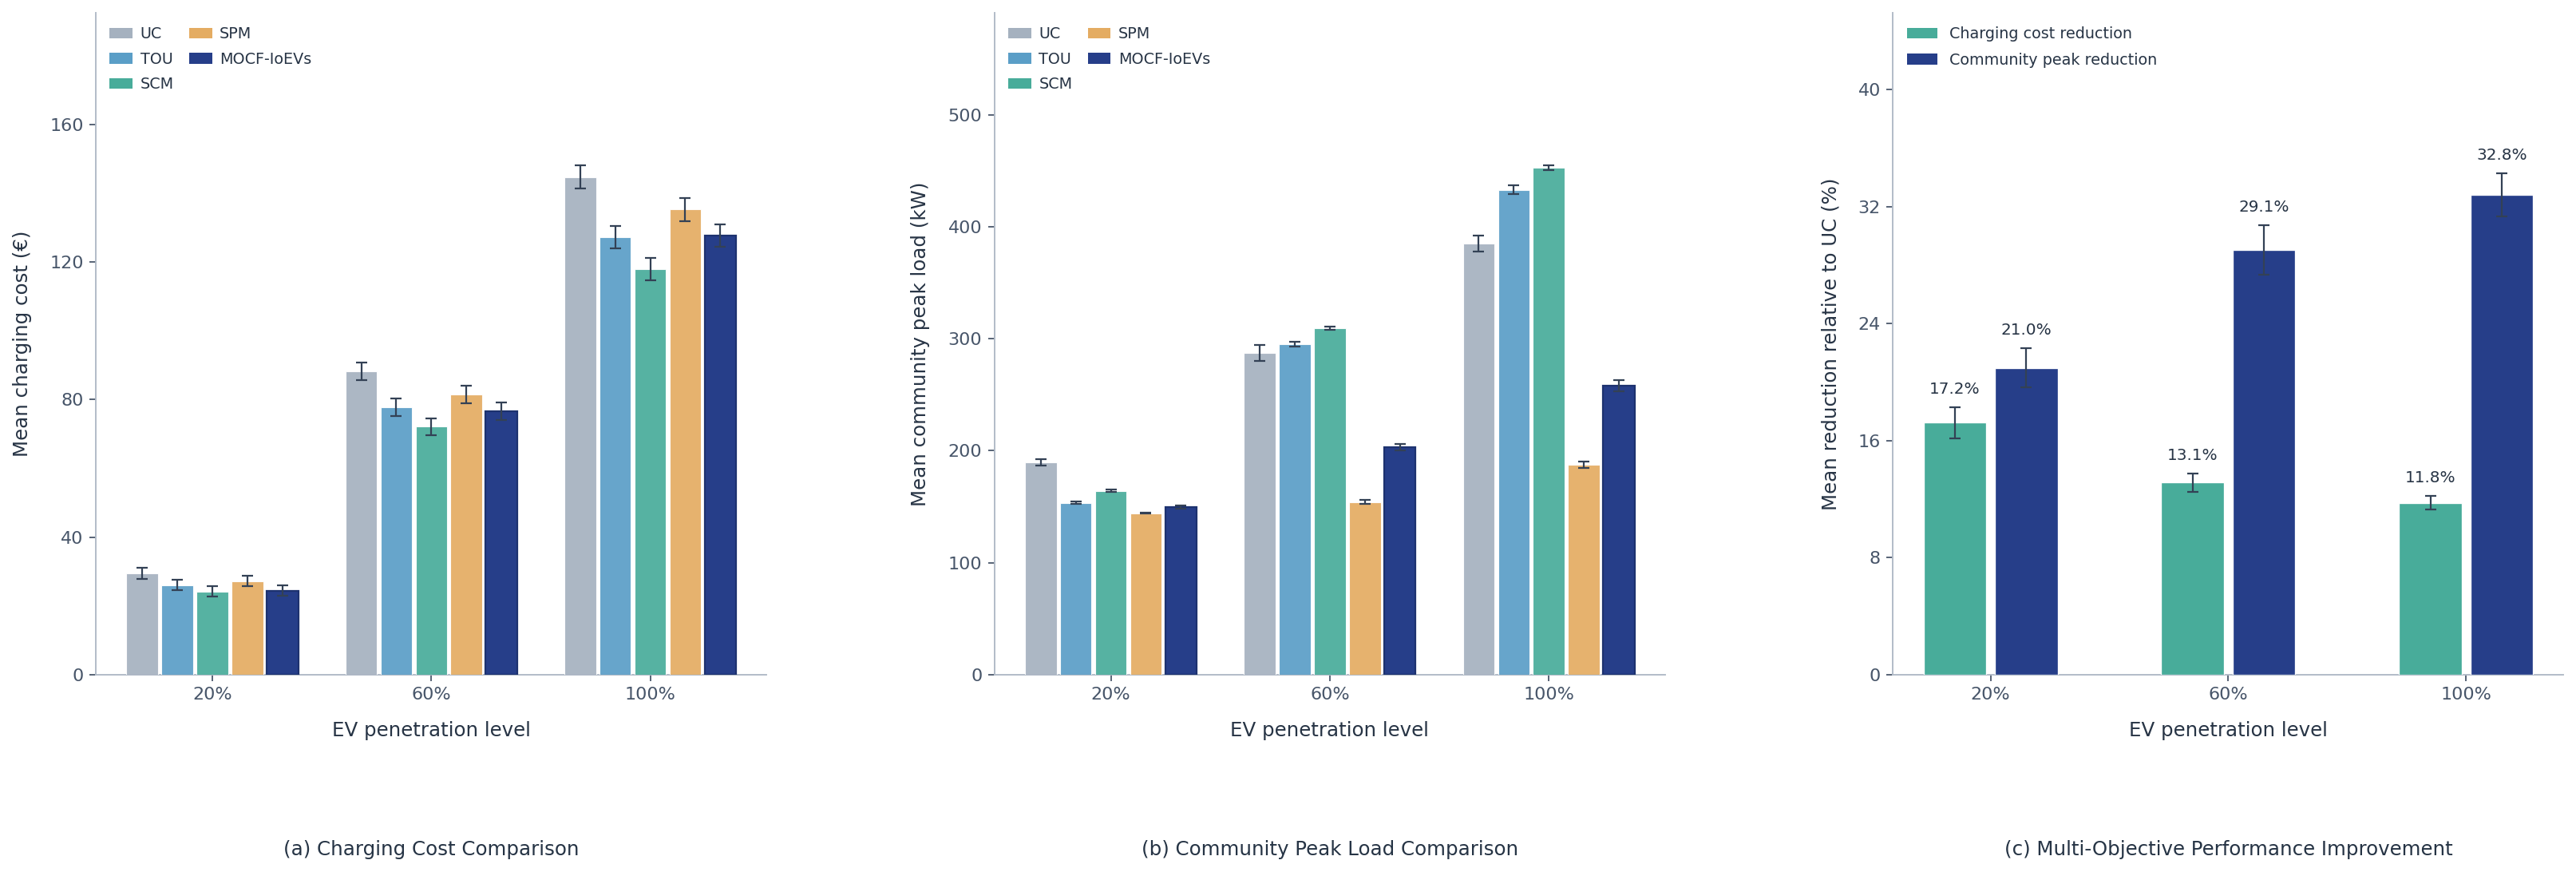


STEP 65 COMPLETED SUCCESSFULLY

Combined figure:
/content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/Reviewer1_Comment8/Individual_EV_Statistical_Experiment/Publication_Figures/Figure_Combined_Three_Panel_Final_300DPI.jpg

Paired improvement data:
/content/drive/MyDrive/IOEV_Ablation_Study/Case-D/Bootstrap_Analysis/Reviewer1_Comment8/Individual_EV_Statistical_Experiment/step65_proposed_paired_improvements.csv

Figure specifications:
Panels: 3, side by side
Panel (a): Charging Cost Comparison
Panel (b): Community Peak Load Comparison
Panel (c): Multi-Objective Performance Improvement
Chart type: Grouped columns
Error bars: 95% confidence intervals
Separate legends: Yes
Separate x-axes: Yes
Gridlines: None
Bold text: None
Format: JPG
Resolution: 300 DPI
Original Case-D results: Unchanged


In [159]:

# ============================================================
# STEP 65: FINAL THREE-PANEL PUBLICATION FIGURE
# ============================================================
# (a) Charging Cost Comparison
# (b) Community Peak Load Comparison
# (c) Multi-Objective Performance Improvement
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from scipy.stats import t

print("=" * 78)
print("STEP 65: FINAL THREE-PANEL PUBLICATION FIGURE")
print("=" * 78)

# ============================================================
# 1. LOAD EXISTING EXPERIMENTAL RESULTS
# ============================================================

summary_path65 = os.path.join(
    EXPERIMENT_FOLDER,
    "step63_statistical_summary.csv"
)

results_path65 = os.path.join(
    EXPERIMENT_FOLDER,
    "step62_all_scenario_results.csv"
)

if not os.path.isfile(summary_path65):
    raise FileNotFoundError(summary_path65)

if not os.path.isfile(results_path65):
    raise FileNotFoundError(results_path65)

summary65 = pd.read_csv(summary_path65)
results65 = pd.read_csv(results_path65)

methods65 = [
    "UC",
    "TOU",
    "SCM",
    "SPM",
    "MOCF-IoEVs"
]

penetrations65 = [0.20, 0.60, 1.00]

# ============================================================
# 2. VALIDATE INPUT DATA
# ============================================================

required_summary65 = [
    "Penetration",
    "Method",
    "Metric",
    "Mean",
    "CI95_Lower",
    "CI95_Upper"
]

required_results65 = [
    "Scenario",
    "Penetration",
    "Method",
    "ChargingCost_EUR",
    "PeakCommunityLoad_kW"
]

for column in required_summary65:
    if column not in summary65.columns:
        raise ValueError(
            f"Missing statistical column: {column}"
        )

for column in required_results65:
    if column not in results65.columns:
        raise ValueError(
            f"Missing experimental column: {column}"
        )

summary65["Penetration"] = pd.to_numeric(
    summary65["Penetration"],
    errors="raise"
)

results65["Penetration"] = pd.to_numeric(
    results65["Penetration"],
    errors="raise"
)

for column in [
    "Mean",
    "CI95_Lower",
    "CI95_Upper"
]:
    summary65[column] = pd.to_numeric(
        summary65[column],
        errors="raise"
    )

for column in [
    "ChargingCost_EUR",
    "PeakCommunityLoad_kW"
]:
    results65[column] = pd.to_numeric(
        results65[column],
        errors="raise"
    )

if not np.isfinite(
    summary65[
        ["Mean", "CI95_Lower", "CI95_Upper"]
    ].to_numpy()
).all():
    raise ValueError(
        "Invalid statistical summary values."
    )

if not np.isfinite(
    results65[
        ["ChargingCost_EUR", "PeakCommunityLoad_kW"]
    ].to_numpy()
).all():
    raise ValueError(
        "Invalid experimental values."
    )

if not (
    (
        summary65["CI95_Lower"]
        <= summary65["Mean"]
    )
    &
    (
        summary65["Mean"]
        <= summary65["CI95_Upper"]
    )
).all():
    raise ValueError(
        "Invalid confidence interval bounds."
    )

# ============================================================
# 3. FUNCTION TO EXTRACT STATISTICAL RESULTS
# ============================================================

def get_statistical_results65(method, metric):

    records = []

    for penetration in penetrations65:

        subset = summary65.loc[
            np.isclose(
                summary65["Penetration"],
                penetration
            )
            &
            (summary65["Method"] == method)
            &
            (summary65["Metric"] == metric)
        ]

        if len(subset) != 1:
            raise ValueError(
                f"Missing or duplicate result: "
                f"{method}, {metric}, {penetration}"
            )

        records.append(subset.iloc[0])

    mean = np.array(
        [r["Mean"] for r in records],
        dtype=float
    )

    lower = np.array(
        [r["CI95_Lower"] for r in records],
        dtype=float
    )

    upper = np.array(
        [r["CI95_Upper"] for r in records],
        dtype=float
    )

    return mean, lower, upper

# ============================================================
# 4. CALCULATE PAIRED PERCENTAGE IMPROVEMENTS
# ============================================================

paired_records65 = []

for penetration in penetrations65:

    subset = results65.loc[
        np.isclose(
            results65["Penetration"],
            penetration
        )
    ]

    uc65 = subset.loc[
        subset["Method"] == "UC"
    ].set_index("Scenario")

    proposed65 = subset.loc[
        subset["Method"] == "MOCF-IoEVs"
    ].set_index("Scenario")

    if not uc65.index.is_unique:
        raise ValueError(
            "Duplicate UC scenario identifiers."
        )

    if not proposed65.index.is_unique:
        raise ValueError(
            "Duplicate MOCF-IoEVs scenario identifiers."
        )

    if set(uc65.index) != set(proposed65.index):
        raise ValueError(
            f"Scenario pairing mismatch: {penetration}"
        )

    proposed65 = proposed65.loc[uc65.index]

    if len(uc65) != 30:
        raise ValueError(
            f"Expected 30 scenarios at {penetration}"
        )

    for metric, objective in [
        ("ChargingCost_EUR", "Charging cost"),
        ("PeakCommunityLoad_kW", "Community peak")
    ]:

        baseline_values65 = uc65[
            metric
        ].to_numpy(dtype=float)

        proposed_values65 = proposed65[
            metric
        ].to_numpy(dtype=float)

        if np.any(baseline_values65 <= 0):
            raise ValueError(
                "Baseline values must be positive."
            )

        reductions65 = (
            (baseline_values65 - proposed_values65)
            / baseline_values65
        ) * 100.0

        n65 = len(reductions65)

        mean_reduction65 = np.mean(
            reductions65
        )

        standard_error65 = (
            np.std(reductions65, ddof=1)
            / np.sqrt(n65)
        )

        margin65 = (
            t.ppf(0.975, n65 - 1)
            * standard_error65
        )

        paired_records65.append({
            "Penetration": penetration,
            "Objective": objective,
            "Mean": mean_reduction65,
            "Lower": mean_reduction65 - margin65,
            "Upper": mean_reduction65 + margin65,
            "N": n65
        })

paired65 = pd.DataFrame(
    paired_records65
)

print("\nPaired improvement statistics:")
print(
    paired65.round(3).to_string(index=False)
)

# ============================================================
# 5. PUBLICATION DESIGN SETTINGS
# ============================================================

colors65 = {
    "UC": "#A5B1BF",
    "TOU": "#5A9EC7",
    "SCM": "#48AC9A",
    "SPM": "#E4AC62",
    "MOCF-IoEVs": "#263E89"
}

objective_colors65 = {
    "Charging cost": "#48AC9A",
    "Community peak": "#263E89"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "font.weight": "normal",
    "axes.labelweight": "normal",
    "axes.titleweight": "normal",
    "axes.grid": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "#273445",
    "axes.labelcolor": "#273445",
    "xtick.color": "#475569",
    "ytick.color": "#475569"
})

fig65, axes65 = plt.subplots(
    1,
    3,
    figsize=(21, 7.4),
    dpi=160
)

ax_a65, ax_b65, ax_c65 = axes65

x65 = np.arange(3)

# ============================================================
# 6. COMMON AXIS STYLING
# ============================================================

def style_axis65(ax):

    ax.grid(False)
    ax.xaxis.grid(False)
    ax.yaxis.grid(False)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color("#B0BAC6")
    ax.spines["bottom"].set_color("#B0BAC6")

    ax.spines["left"].set_linewidth(0.85)
    ax.spines["bottom"].set_linewidth(0.85)

    ax.tick_params(
        axis="both",
        labelsize=10,
        length=3.5,
        width=0.8
    )

    ax.yaxis.set_major_locator(
        MaxNLocator(nbins=6)
    )

    ax.set_xticks(x65)

    ax.set_xticklabels(
        ["20%", "60%", "100%"]
    )

    ax.set_xlabel(
        "EV penetration level",
        fontsize=11,
        labelpad=10
    )


def add_method_legend65(ax):

    handles65 = []

    for method in methods65:

        handles65.append(
            Patch(
                facecolor=colors65[method],
                edgecolor="none",
                label=method
            )
        )

    ax.legend(
        handles=handles65,
        loc="upper left",
        frameon=False,
        fontsize=8.6,
        ncol=2,
        columnspacing=1.0,
        handlelength=1.5,
        handletextpad=0.5,
        labelspacing=0.65
    )

# ============================================================
# 7. PANEL (a): CHARGING COST COMPARISON
# ============================================================

bar_width65 = 0.16

for i, method in enumerate(methods65):

    mean, lower, upper = get_statistical_results65(
        method,
        "ChargingCost_EUR"
    )

    positions65 = (
        x65 + (i - 2) * bar_width65
    )

    proposed_method65 = (
        method == "MOCF-IoEVs"
    )

    ax_a65.bar(
        positions65,
        mean,
        width=bar_width65 * 0.90,
        color=colors65[method],
        edgecolor=(
            "#1D326F"
            if proposed_method65
            else "white"
        ),
        linewidth=(
            1.0 if proposed_method65 else 0.5
        ),
        alpha=(
            1.0 if proposed_method65 else 0.92
        ),
        zorder=3
    )

    ax_a65.errorbar(
        positions65,
        mean,
        yerr=np.vstack([
            mean - lower,
            upper - mean
        ]),
        fmt="none",
        ecolor="#334155",
        elinewidth=1.0,
        capsize=3,
        capthick=1.0,
        zorder=5
    )

style_axis65(ax_a65)

ax_a65.set_ylabel(
    "Mean charging cost (€)",
    fontsize=11,
    labelpad=10
)

max_cost65 = summary65.loc[
    summary65["Metric"] == "ChargingCost_EUR",
    "CI95_Upper"
].max()

ax_a65.set_ylim(
    0,
    max_cost65 * 1.30
)

add_method_legend65(ax_a65)

# ============================================================
# 8. PANEL (b): COMMUNITY PEAK LOAD COMPARISON
# ============================================================

for i, method in enumerate(methods65):

    mean, lower, upper = get_statistical_results65(
        method,
        "PeakCommunityLoad_kW"
    )

    positions65 = (
        x65 + (i - 2) * bar_width65
    )

    proposed_method65 = (
        method == "MOCF-IoEVs"
    )

    ax_b65.bar(
        positions65,
        mean,
        width=bar_width65 * 0.90,
        color=colors65[method],
        edgecolor=(
            "#1D326F"
            if proposed_method65
            else "white"
        ),
        linewidth=(
            1.0 if proposed_method65 else 0.5
        ),
        alpha=(
            1.0 if proposed_method65 else 0.92
        ),
        zorder=3
    )

    ax_b65.errorbar(
        positions65,
        mean,
        yerr=np.vstack([
            mean - lower,
            upper - mean
        ]),
        fmt="none",
        ecolor="#334155",
        elinewidth=1.0,
        capsize=3,
        capthick=1.0,
        zorder=5
    )

style_axis65(ax_b65)

ax_b65.set_ylabel(
    "Mean community peak load (kW)",
    fontsize=11,
    labelpad=10
)

max_peak65 = summary65.loc[
    summary65["Metric"] == "PeakCommunityLoad_kW",
    "CI95_Upper"
].max()

ax_b65.set_ylim(
    0,
    max_peak65 * 1.30
)

add_method_legend65(ax_b65)

# ============================================================
# 9. PANEL (c): MULTI-OBJECTIVE PERFORMANCE
# ============================================================

objectives65 = [
    "Charging cost",
    "Community peak"
]

objective_width65 = 0.30

for i, objective in enumerate(objectives65):

    rows65 = []

    for penetration in penetrations65:

        row65 = paired65.loc[
            np.isclose(
                paired65["Penetration"],
                penetration
            )
            &
            (
                paired65["Objective"]
                == objective
            )
        ]

        if len(row65) != 1:
            raise ValueError(
                f"Missing paired result: "
                f"{penetration}, {objective}"
            )

        rows65.append(row65.iloc[0])

    mean65 = np.array(
        [r["Mean"] for r in rows65],
        dtype=float
    )

    lower65 = np.array(
        [r["Lower"] for r in rows65],
        dtype=float
    )

    upper65 = np.array(
        [r["Upper"] for r in rows65],
        dtype=float
    )

    positions65 = (
        x65 + (i - 0.5) * objective_width65
    )

    ax_c65.bar(
        positions65,
        mean65,
        width=objective_width65 * 0.88,
        color=objective_colors65[objective],
        edgecolor="white",
        linewidth=0.6,
        zorder=3
    )

    ax_c65.errorbar(
        positions65,
        mean65,
        yerr=np.vstack([
            mean65 - lower65,
            upper65 - mean65
        ]),
        fmt="none",
        ecolor="#334155",
        elinewidth=1.0,
        capsize=3,
        capthick=1.0,
        zorder=5
    )

    for px, value, upper_ci in zip(
        positions65,
        mean65,
        upper65
    ):

        ax_c65.annotate(
            f"{value:.1f}%",
            xy=(px, upper_ci),
            xytext=(0, 6),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="normal",
            color="#273445"
        )

style_axis65(ax_c65)

ax_c65.set_ylabel(
    "Mean reduction relative to UC (%)",
    fontsize=11,
    labelpad=10
)

ax_c65.set_ylim(
    0,
    paired65["Upper"].max() * 1.32
)

ax_c65.legend(
    handles=[
        Patch(
            facecolor=objective_colors65["Charging cost"],
            edgecolor="none",
            label="Charging cost reduction"
        ),
        Patch(
            facecolor=objective_colors65["Community peak"],
            edgecolor="none",
            label="Community peak reduction"
        )
    ],
    loc="upper left",
    frameon=False,
    fontsize=8.6,
    ncol=1,
    labelspacing=0.7
)

# ============================================================
# 10. PANEL TITLES BELOW THE X-AXES
# ============================================================

panel_titles65 = [
    "(a) Charging Cost Comparison",
    "(b) Community Peak Load Comparison",
    "(c) Multi-Objective Performance Improvement"
]

for ax, title in zip(
    axes65,
    panel_titles65
):

    ax.text(
        0.5,
        -0.25,
        title,
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=11,
        fontweight="normal",
        color="#263445",
        clip_on=False
    )

# ============================================================
# 11. FINAL LAYOUT
# ============================================================

fig65.subplots_adjust(
    left=0.065,
    right=0.985,
    top=0.95,
    bottom=0.25,
    wspace=0.34
)

# ============================================================
# 12. SAVE PUBLICATION FIGURE
# ============================================================

figure_folder65 = os.path.join(
    EXPERIMENT_FOLDER,
    "Publication_Figures"
)

os.makedirs(
    figure_folder65,
    exist_ok=True
)

figure_path65 = os.path.join(
    figure_folder65,
    "Figure_Combined_Three_Panel_Final_300DPI.jpg"
)

fig65.savefig(
    figure_path65,
    dpi=300,
    format="jpg",
    bbox_inches="tight",
    pad_inches=0.25,
    facecolor="white"
)

plt.show()
plt.close(fig65)

# ============================================================
# 13. SAVE STATISTICAL DATA FOR MANUSCRIPT
# ============================================================

paired_path65 = os.path.join(
    EXPERIMENT_FOLDER,
    "step65_proposed_paired_improvements.csv"
)

paired65.to_csv(
    paired_path65,
    index=False
)

print("\n" + "=" * 78)
print("STEP 65 COMPLETED SUCCESSFULLY")
print("=" * 78)

print("\nCombined figure:")
print(figure_path65)

print("\nPaired improvement data:")
print(paired_path65)

print("\nFigure specifications:")
print("Panels: 3, side by side")
print("Panel (a): Charging Cost Comparison")
print("Panel (b): Community Peak Load Comparison")
print("Panel (c): Multi-Objective Performance Improvement")
print("Chart type: Grouped columns")
print("Error bars: 95% confidence intervals")
print("Separate legends: Yes")
print("Separate x-axes: Yes")
print("Gridlines: None")
print("Bold text: None")
print("Format: JPG")
print("Resolution: 300 DPI")
print("Original Case-D results: Unchanged")
